Dataset, intermediate files and all output files

https://drive.google.com/drive/folders/1LG5Jvhv6yG9cm47kxqPne1EHVR_bqnut?usp=sharing

In [ ]:
!rm -rf /content/drive
!mkdir -p /content/drive

In [ ]:
# ============================================================
# TELUGU LLM CORPUS — PROJECT SETUP
# ============================================================

from google.colab import drive

drive.mount(
    "/content/drive"
)


from pathlib import Path


# ============================================================
# PROJECT ROOT
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu"
)


# ============================================================
# DATA ROOTS
# ============================================================

RAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
)

CLEANED_DIR = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
)


# ============================================================
# MANUAL — WIKIPEDIA ONLY FOR NOW
# ============================================================

RAW_MANUAL_DIR = (
    RAW_DIR
    / "manual"
)

RAW_WIKIPEDIA_DIR = (
    RAW_MANUAL_DIR
    / "wikipedia"
)


CLEANED_MANUAL_DIR = (
    CLEANED_DIR
    / "manual"
)

CLEANED_WIKIPEDIA_DIR = (
    CLEANED_MANUAL_DIR
    / "wikipedia"
)


# ============================================================
# INDICCORP v2
# ============================================================

RAW_INDICCORP_DIR = (
    RAW_DIR
    / "indiccorp_v2"
)

CLEANED_INDICCORP_DIR = (
    CLEANED_DIR
    / "indiccorp_v2"
)


# Actual final Telugu IndicCorp file
INDICCORP_TELUGU_FILE = (
    RAW_INDICCORP_DIR
    / "te.txt"
)


# ============================================================
# REQUIREMENTS
# ============================================================

REQUIREMENTS_FILE = (
    PROJECT_ROOT
    / "requirements.txt"
)


# ============================================================
# CREATE DIRECTORIES
# ============================================================

directories = [

    PROJECT_ROOT,

    RAW_DIR,
    CLEANED_DIR,

    RAW_MANUAL_DIR,
    RAW_WIKIPEDIA_DIR,

    CLEANED_MANUAL_DIR,
    CLEANED_WIKIPEDIA_DIR,

    RAW_INDICCORP_DIR,
    CLEANED_INDICCORP_DIR,
]


for directory in directories:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# PRINT
# ============================================================

print("=" * 70)

print(
    "TELUGU LLM CORPUS — SETUP COMPLETE"
)

print("=" * 70)

print(
    f"Project root      : {PROJECT_ROOT}"
)

print(
    f"Raw Wikipedia     : {RAW_WIKIPEDIA_DIR}"
)

print(
    f"Cleaned Wikipedia : {CLEANED_WIKIPEDIA_DIR}"
)

print(
    f"Raw IndicCorp     : {RAW_INDICCORP_DIR}"
)

print(
    f"IndicCorp Telugu  : {INDICCORP_TELUGU_FILE}"
)

print(
    f"Cleaned IndicCorp : {CLEANED_INDICCORP_DIR}"
)

print(
    f"Requirements      : {REQUIREMENTS_FILE}"
)

print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TELUGU LLM CORPUS — SETUP COMPLETE
Project root      : /content/drive/MyDrive/LMA_IP/Telugu
Raw Wikipedia     : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikipedia
Cleaned Wikipedia : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikipedia
Raw IndicCorp     : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/indiccorp_v2
IndicCorp Telugu  : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/indiccorp_v2/te.txt
Cleaned IndicCorp : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/indiccorp_v2
Requirements      : /content/drive/MyDrive/LMA_IP/Telugu/requirements.txt


In [ ]:
# ============================================================
# INSTALL ALL PROJECT REQUIREMENTS
# ============================================================

!pip install -q -r \
    "/content/drive/MyDrive/LMA_IP/Telugu/requirements.txt"

In [ ]:
# ============================================================
# TELUGU CONFIGURATION
# ============================================================

TELUGU_START = "\u0C00"

TELUGU_END = "\u0C7F"


LANGUAGE = "Telugu"

LANGUAGE_CODE = "te"

SCRIPT = "Telugu"


MIN_DOCUMENT_CHARACTERS = 100

DIGIT_RATIO_THRESHOLD = 0.25


def is_telugu(
    char
):

    return (
        TELUGU_START
        <= char
        <= TELUGU_END
    )


print("=" * 70)

print(
    "TELUGU CONFIGURATION"
)

print("=" * 70)

print(
    f"Language              : {LANGUAGE}"
)

print(
    f"Language code         : {LANGUAGE_CODE}"
)

print(
    f"Script                : {SCRIPT}"
)

print(
    "Unicode range         : U+0C00–U+0C7F"
)

print(
    f"Min characters        : "
    f"{MIN_DOCUMENT_CHARACTERS}"
)

print(
    f"Digit ratio threshold : "
    f"{DIGIT_RATIO_THRESHOLD:.0%}"
)

TELUGU CONFIGURATION
Language              : Telugu
Language code         : te
Script                : Telugu
Unicode range         : U+0C00–U+0C7F
Min characters        : 100
Digit ratio threshold : 25%


In [ ]:
# ============================================================
# TELUGU — COMMON TEXT UTILITIES
# ============================================================

import re
import hashlib


# ============================================================
# TELUGU RATIO
# ============================================================

def telugu_ratio(
    text
):

    if not isinstance(
        text,
        str
    ):

        return 0.0


    alphabetic = [
        char
        for char in text
        if char.isalpha()
    ]


    if not alphabetic:

        return 0.0


    telugu_count = sum(
        is_telugu(
            char
        )
        for char in alphabetic
    )


    return (
        telugu_count
        / len(alphabetic)
    )


# ============================================================
# DIGIT RATIO
# ============================================================

def digit_ratio(
    text
):

    if not isinstance(
        text,
        str
    ):

        return 0.0


    non_whitespace = [
        char
        for char in text
        if not char.isspace()
    ]


    if not non_whitespace:

        return 0.0


    digit_count = sum(
        char.isdigit()
        for char in non_whitespace
    )


    return (
        digit_count
        / len(non_whitespace)
    )


# ============================================================
# TEXT HASH
# ============================================================

def text_hash(
    text
):

    if not isinstance(
        text,
        str
    ):

        text = str(
            text
        )


    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# WHITESPACE NORMALIZATION
# ============================================================

def normalize_whitespace(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\xa0",
        " "
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r" *\n *",
        "\n",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# DIGIT POLICY
# ============================================================

def apply_digit_policy(
    text
):

    ratio = digit_ratio(
        text
    )


    if (
        ratio
        > DIGIT_RATIO_THRESHOLD
    ):

        text = "".join(

            " "
            if char.isdigit()
            else char

            for char in text

        )


        digits_removed = True

    else:

        digits_removed = False


    return {

        "text":
            text,

        "digit_ratio":
            ratio,

        "digits_removed":
            digits_removed,
    }


print(
    "Telugu text utilities loaded."
)

Telugu text utilities loaded.


# IndicCrop

In [ ]:
# ============================================================
# INDICCORP v2 — DOWNLOAD TELUGU
# ============================================================

from huggingface_hub import hf_hub_download
from pathlib import Path
import shutil


# ============================================================
# PATHS
# ============================================================

RAW_INDICCORP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

INDICCORP_TELUGU_FILE = (
    RAW_INDICCORP_DIR
    / "te.txt"
)


print("=" * 70)
print("DOWNLOADING INDICCORP v2 — TELUGU")
print("=" * 70)


if INDICCORP_TELUGU_FILE.exists():

    print(
        "IndicCorp Telugu already downloaded."
    )

    print(
        INDICCORP_TELUGU_FILE
    )

else:

    HF_TEMP_DIR = Path(
        "/content/indiccorp_hf"
    )

    HF_TEMP_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


    downloaded_path = hf_hub_download(
        repo_id="ai4bharat/IndicCorpV2",
        repo_type="dataset",
        filename="data/te.txt",
        local_dir=str(
            HF_TEMP_DIR
        ),
        local_dir_use_symlinks=False,
    )


    downloaded_path = Path(
        downloaded_path
    )


    if not downloaded_path.exists():

        raise FileNotFoundError(
            f"Downloaded file not found:\n"
            f"{downloaded_path}"
        )


    RAW_INDICCORP_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


    shutil.move(
        str(downloaded_path),
        str(INDICCORP_TELUGU_FILE)
    )


    print(
        "Download complete."
    )


print(
    "\nFile:"
)

print(
    INDICCORP_TELUGU_FILE
)

print(
    f"\nSize: "
    f"{INDICCORP_TELUGU_FILE.stat().st_size / (1024**3):.2f} GB"
)

DOWNLOADING INDICCORP v2 — TELUGU
IndicCorp Telugu already downloaded.
/content/drive/MyDrive/LMA_IP/Telugu/data/raw/indiccorp_v2/te.txt

File:
/content/drive/MyDrive/LMA_IP/Telugu/data/raw/indiccorp_v2/te.txt

Size: 14.68 GB


## Cleaning

In [ ]:
# ============================================================
# INDICCORP v2 TELUGU — FAST JSONL CLEANING FUNCTIONS
# ============================================================

import re


# ============================================================
# THRESHOLDS
# ============================================================

INDICORP_MIN_CHARACTERS = 50

INDICORP_MIN_TELUGU_RATIO = 0.50

DIGIT_RATIO_THRESHOLD = 0.10


# ============================================================
# FAST TELUGU RATIO
# ============================================================

def fast_telugu_ratio(
    text
):

    alphabetic_count = 0

    telugu_count = 0


    for char in text:

        if char.isalpha():

            alphabetic_count += 1


            if (
                "\u0C00"
                <= char
                <= "\u0C7F"
            ):

                telugu_count += 1


    if alphabetic_count == 0:

        return 0.0


    return (
        telugu_count
        / alphabetic_count
    )


# ============================================================
# FAST DIGIT RATIO
# ============================================================

def fast_digit_ratio(
    text
):

    non_whitespace_count = 0

    digit_count = 0


    for char in text:

        if not char.isspace():

            non_whitespace_count += 1


            if char.isdigit():

                digit_count += 1


    if non_whitespace_count == 0:

        return 0.0


    return (
        digit_count
        / non_whitespace_count
    )


# ============================================================
# REMOVE OBVIOUS GARBAGE
# ============================================================

def remove_indiccorp_garbage_fast(
    text
):

    # URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )


    # Email addresses
    text = re.sub(
        r"\S+@\S+",
        " ",
        text
    )


    # HTML tags
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )


    # Long repeated punctuation
    text = re.sub(
        r"([^\w\s])\1{4,}",
        r"\1",
        text
    )


    # Long repeated characters
    text = re.sub(
        r"(.)\1{6,}",
        r"\1",
        text
    )


    return text


# ============================================================
# CLEAN ONE LINE
# ============================================================

def clean_indiccorp_line_fast(
    text
):

    if not isinstance(
        text,
        str
    ):

        return None


    text = text.strip()


    if not text:

        return None


    # --------------------------------------------------------
    # Basic garbage cleanup
    # --------------------------------------------------------

    text = remove_indiccorp_garbage_fast(
        text
    )


    # --------------------------------------------------------
    # Normalize whitespace
    # --------------------------------------------------------

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    if (
        len(text)
        < INDICORP_MIN_CHARACTERS
    ):

        return None


    # --------------------------------------------------------
    # Digit policy
    # --------------------------------------------------------

    original_digit_ratio = (
        fast_digit_ratio(
            text
        )
    )


    digits_removed = False


    if (
        original_digit_ratio
        > DIGIT_RATIO_THRESHOLD
    ):

        text = "".join(

            " "
            if char.isdigit()
            else char

            for char in text

        )


        text = re.sub(
            r"\s+",
            " ",
            text
        ).strip()


        digits_removed = True


    # --------------------------------------------------------
    # Telugu quality check
    # --------------------------------------------------------

    final_telugu_ratio = (
        fast_telugu_ratio(
            text
        )
    )


    if (
        final_telugu_ratio
        < INDICORP_MIN_TELUGU_RATIO
    ):

        return None


    return {

        "text":
            text,

        "telugu_ratio":
            final_telugu_ratio,

        "digit_ratio":
            original_digit_ratio,

        "digits_removed":
            digits_removed,
    }


print(
    "Fast IndicCorp Telugu cleaning functions loaded."
)

print(
    f"Minimum characters     : "
    f"{INDICORP_MIN_CHARACTERS}"
)

print(
    f"Minimum Telugu ratio   : "
    f"{INDICORP_MIN_TELUGU_RATIO:.0%}"
)

print(
    f"Digit ratio threshold  : "
    f"{DIGIT_RATIO_THRESHOLD:.0%}"
)

Fast IndicCorp Telugu cleaning functions loaded.
Minimum characters     : 50
Minimum Telugu ratio   : 50%
Digit ratio threshold  : 10%


In [ ]:
# ============================================================
# INDICCORP v2 TELUGU — CLEANING WITH LIVE PROGRESS
# ============================================================

import json
import time
from tqdm.auto import tqdm


INDICCORP_CLEANED_OUTPUT = (
    CLEANED_INDICCORP_DIR
    / "indiccorp_v2_telugu.jsonl"
)


# ============================================================
# INPUT CHECK
# ============================================================

if not INDICCORP_TELUGU_FILE.exists():

    raise FileNotFoundError(
        f"IndicCorp Telugu file not found:\n"
        f"{INDICCORP_TELUGU_FILE}"
    )


# ============================================================
# REMOVE PARTIAL OUTPUT
# ============================================================

if INDICCORP_CLEANED_OUTPUT.exists():

    INDICCORP_CLEANED_OUTPUT.unlink()

    print(
        "Removed old/partial cleaned output."
    )


# ============================================================
# FILE SIZE
# ============================================================

input_size_bytes = (
    INDICCORP_TELUGU_FILE.stat().st_size
)

input_size_gb = (
    input_size_bytes
    / (1024 ** 3)
)


print(
    "=" * 70
)

print(
    "STARTING INDICCORP v2 TELUGU CLEANING"
)

print(
    "=" * 70
)

print(
    f"Input : {INDICCORP_TELUGU_FILE}"
)

print(
    f"Output: {INDICCORP_CLEANED_OUTPUT}"
)

print(
    f"Input size: {input_size_gb:.2f} GB"
)


# ============================================================
# COUNTERS
# ============================================================

documents_before = 0

documents_after = 0

rejected_documents = 0

digits_removed_documents = 0

characters_before = 0

characters_after = 0


start_time = time.time()


# ============================================================
# OPEN FILES
# ============================================================

with open(
    INDICCORP_TELUGU_FILE,
    "rb"
) as input_file, \
open(
    INDICCORP_CLEANED_OUTPUT,
    "w",
    encoding="utf-8"
) as output_file:


    # --------------------------------------------------------
    # tqdm tracks bytes directly.
    # --------------------------------------------------------

    with tqdm(
        total=input_size_bytes,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="Cleaning Telugu IndicCorp",
        mininterval=2.0,
        dynamic_ncols=True,
    ) as progress:


        while True:

            # ------------------------------------------------
            # Read one line as bytes
            # ------------------------------------------------

            raw_bytes = input_file.readline()


            if not raw_bytes:

                break


            # ------------------------------------------------
            # Update exact byte progress
            # ------------------------------------------------

            progress.update(
                len(
                    raw_bytes
                )
            )


            documents_before += 1


            # ------------------------------------------------
            # Decode UTF-8
            # ------------------------------------------------

            raw_text = (
                raw_bytes
                .decode(
                    "utf-8",
                    errors="replace"
                )
                .strip()
            )


            if not raw_text:

                rejected_documents += 1

                continue


            characters_before += len(
                raw_text
            )


            # ------------------------------------------------
            # Clean
            # ------------------------------------------------

            cleaned = (
                clean_indiccorp_line_fast(
                    raw_text
                )
            )


            if cleaned is None:

                rejected_documents += 1

                continue


            cleaned_text = cleaned[
                "text"
            ]


            # ------------------------------------------------
            # Create JSONL record
            # ------------------------------------------------

            record = {

                "text":
                    cleaned_text,

                "source":
                    "indiccorp_v2",

                "language":
                    "telugu",

                "language_code":
                    "te",

                "script":
                    "Telugu",

                "telugu_ratio":
                    round(
                        cleaned[
                            "telugu_ratio"
                        ],
                        4
                    ),

                "digit_ratio_before_cleaning":
                    round(
                        cleaned[
                            "digit_ratio"
                        ],
                        4
                    ),

                "digits_removed":
                    cleaned[
                        "digits_removed"
                    ],

                "character_count":
                    len(
                        cleaned_text
                    ),
            }


            output_file.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            documents_after += 1

            characters_after += len(
                cleaned_text
            )


            if cleaned[
                "digits_removed"
            ]:

                digits_removed_documents += 1


            # ------------------------------------------------
            # Flush periodically
            # ------------------------------------------------

            if (
                documents_after
                % 500
                == 0
            ):

                output_file.flush()


# ============================================================
# SUMMARY
# ============================================================

elapsed_minutes = (
    time.time()
    - start_time
) / 60


print(
    "\n"
    + "=" * 70
)

print(
    "INDICCORP v2 TELUGU — CLEANING COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Documents before : "
    f"{documents_before:,}"
)

print(
    f"Documents after  : "
    f"{documents_after:,}"
)

print(
    f"Rejected         : "
    f"{rejected_documents:,}"
)

print(
    f"Characters before: "
    f"{characters_before:,}"
)

print(
    f"Characters after : "
    f"{characters_after:,}"
)

print(
    f"Digits removed   : "
    f"{digits_removed_documents:,}"
)

print(
    f"Time             : "
    f"{elapsed_minutes:.1f} minutes"
)

print(
    "\nOutput:"
)

print(
    INDICCORP_CLEANED_OUTPUT
)

Removed old/partial cleaned output.
STARTING INDICCORP v2 TELUGU CLEANING
Input : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/indiccorp_v2/te.txt
Output: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/indiccorp_v2/indiccorp_v2_telugu.jsonl
Input size: 14.68 GB


Cleaning Telugu IndicCorp:   0%|          | 0.00/14.7G [00:00<?, ?B/s]


INDICCORP v2 TELUGU — CLEANING COMPLETE
Documents before : 42,916,522
Documents after  : 16,089,659
Rejected         : 26,826,863
Characters before: 5,850,624,741
Characters after : 5,677,106,780
Digits removed   : 196,139
Time             : 78.5 minutes

Output:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/indiccorp_v2/indiccorp_v2_telugu.jsonl


# Manual

## Wikipedia

In [ ]:
# ============================================================
# TELUGU WIKIPEDIA — REQUIREMENTS + SETUP
# ============================================================

# ------------------------------------------------------------
# ADD WIKIPEDIA EXTRACTION REQUIREMENTS
# ------------------------------------------------------------

WIKIPEDIA_REQUIREMENTS = [
    "requests",
    "tqdm",
    "mwxml",
    "mwparserfromhell",
]


# ------------------------------------------------------------
# UPDATE PROJECT REQUIREMENTS.TXT
# ------------------------------------------------------------

existing_requirements = set()

if REQUIREMENTS_FILE.exists():

    with open(
        REQUIREMENTS_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        existing_requirements = {
            line.strip()
            for line in f
            if line.strip()
            and not line.startswith("#")
        }


updated_requirements = (
    existing_requirements
    | set(WIKIPEDIA_REQUIREMENTS)
)


with open(
    REQUIREMENTS_FILE,
    "w",
    encoding="utf-8"
) as f:

    for package in sorted(
        updated_requirements
    ):

        f.write(
            package
            + "\n"
        )


print("=" * 70)
print("REQUIREMENTS UPDATED")
print("=" * 70)

print(
    f"Requirements file: {REQUIREMENTS_FILE}"
)

print()

for package in sorted(
    updated_requirements
):

    print(
        f"  {package}"
    )


# ------------------------------------------------------------
# INSTALL
# ------------------------------------------------------------

import subprocess
import sys


print()
print("=" * 70)
print("INSTALLING REQUIREMENTS")
print("=" * 70)


subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-r",
    str(REQUIREMENTS_FILE)
])


print()
print("Installation complete.")

REQUIREMENTS UPDATED
Requirements file: /content/drive/MyDrive/LMA_IP/Telugu/requirements.txt

  Pillow>=10.0
  PyMuPDF>=1.24
  aiohttp>=3.9
  beautifulsoup4>=4.12
  datasets>=2.20
  huggingface_hub>=0.24
  lxml>=5.0
  mwparserfromhell
  mwxml
  numpy>=1.26
  pandas>=2.0
  pytesseract>=0.3.13
  regex>=2024.5.15
  requests
  requests>=2.31
  tqdm
  tqdm>=4.66
  transformers>=4.40

INSTALLING REQUIREMENTS

Installation complete.


### Collection

In [ ]:
# ============================================================
# TELUGU WIKIPEDIA — ALL EXTRACTION FUNCTIONS
# ============================================================

import bz2
import json
import re
import time
import subprocess

import requests
import mwxml
import mwparserfromhell

from pathlib import Path
from tqdm.auto import tqdm


# ============================================================
# WIKIPEDIA CONSTANTS
# ============================================================

WIKIPEDIA_LATEST_DUMP_URL = (
    "https://dumps.wikimedia.org/"
    "tewiki/latest/"
    "tewiki-latest-pages-articles.xml.bz2"
)


WIKIPEDIA_DUMP_FILE = (
    RAW_WIKIPEDIA_DIR
    / "tewiki-latest-pages-articles.xml.bz2"
)


# ------------------------------------------------------------
# ALL ARTICLES → ONE JSONL FILE
# ------------------------------------------------------------

WIKIPEDIA_JSONL_FILE = (
    RAW_WIKIPEDIA_DIR
    / "wikipedia_articles.jsonl"
)


# ------------------------------------------------------------
# Metadata / statistics
# ------------------------------------------------------------

WIKIPEDIA_METADATA_FILE = (
    RAW_WIKIPEDIA_DIR
    / "metadata.json"
)


# ============================================================
# REQUEST SESSION
# ============================================================

WIKI_SESSION = requests.Session()

WIKI_SESSION.headers.update({

    "User-Agent":
        "Mozilla/5.0 "
        "(X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/131.0 Safari/537.36",

    "Accept":
        "*/*",

})


# ============================================================
# CHECK DUMP URL
# ============================================================

def check_dump_url(
    url
):

    print(
        f"Checking:\n{url}"
    )

    try:

        response = WIKI_SESSION.head(
            url,
            allow_redirects=True,
            timeout=60
        )

        print(
            f"HTTP status: "
            f"{response.status_code}"
        )

        return response.status_code == 200

    except Exception as e:

        print(
            f"HEAD request failed: {e}"
        )

        return False


# ============================================================
# FIND LATEST TELUGU DUMP
# ============================================================

def find_latest_telugu_dump():

    print(
        "Checking Wikimedia direct dump URL..."
    )


    url = WIKIPEDIA_LATEST_DUMP_URL


    if check_dump_url(
        url
    ):

        return {

            "name":
                "tewiki-latest-pages-articles.xml.bz2",

            "date":
                "latest",

            "url":
                url,

        }


    # ========================================================
    # FALLBACK — WGET DIRECTORY
    # ========================================================

    print()
    print(
        "Direct latest URL was not accessible."
    )

    print(
        "Trying Wikimedia directory through wget..."
    )


    try:

        result = subprocess.run(

            [
                "wget",
                "-qO-",
                "--user-agent=Mozilla/5.0",
                "https://dumps.wikimedia.org/tewiki/latest/",
            ],

            capture_output=True,

            text=True,

            timeout=120

        )


        html = result.stdout


        matches = re.findall(

            r'href="([^"]*'
            r'tewiki-latest-pages-articles'
            r'[^"]*\.xml\.bz2)"',

            html

        )


        if matches:

            dump_name = matches[0]

            dump_url = (

                "https://dumps.wikimedia.org/"
                "tewiki/latest/"
                + dump_name

            )


            return {

                "name":
                    dump_name,

                "date":
                    "latest",

                "url":
                    dump_url,

            }


    except Exception as e:

        print(
            f"wget fallback failed: {e}"
        )


    raise RuntimeError(

        "\nCould not access the Telugu Wikipedia dump.\n\n"

        "Wikimedia is currently blocking access "
        "from this Colab environment."

    )


# ============================================================
# DOWNLOAD DUMP
# ============================================================

def download_file(
    url,
    output_path,
    chunk_size=1024 * 1024
):

    output_path = Path(
        output_path
    )


    # --------------------------------------------------------
    # Already downloaded
    # --------------------------------------------------------

    if output_path.exists():

        size_gb = (

            output_path.stat().st_size

            / (1024 ** 3)

        )


        print(
            "Dump already exists:"
        )

        print(
            output_path
        )

        print(
            f"Existing size: "
            f"{size_gb:.2f} GB"
        )


        return output_path


    # --------------------------------------------------------
    # Requests
    # --------------------------------------------------------

    print(
        "=" * 70
    )

    print(
        "DOWNLOADING TELUGU WIKIPEDIA DUMP"
    )

    print(
        "=" * 70
    )

    print()
    print(
        url
    )


    try:

        response = WIKI_SESSION.get(

            url,

            stream=True,

            timeout=120

        )


        response.raise_for_status()


        total_size = int(

            response.headers.get(
                "content-length",
                0
            )

        )


        output_path.parent.mkdir(

            parents=True,

            exist_ok=True

        )


        with open(

            output_path,

            "wb"

        ) as f:


            with tqdm(

                total=total_size,

                unit="B",

                unit_scale=True,

                unit_divisor=1024,

                desc="Downloading"

            ) as progress:


                for chunk in response.iter_content(

                    chunk_size=chunk_size

                ):

                    if not chunk:

                        continue


                    f.write(
                        chunk
                    )


                    progress.update(
                        len(chunk)
                    )


        return output_path


    except Exception as e:

        print()
        print(
            "requests download failed:"
        )

        print(
            e
        )


        if output_path.exists():

            output_path.unlink()


    # --------------------------------------------------------
    # WGET FALLBACK
    # --------------------------------------------------------

    print()
    print(
        "Trying wget fallback..."
    )


    try:

        output_path.parent.mkdir(

            parents=True,

            exist_ok=True

        )


        subprocess.run(

            [

                "wget",

                "--continue",

                "--show-progress",

                "--user-agent=Mozilla/5.0",

                "-O",

                str(output_path),

                url,

            ],

            check=True

        )


        return output_path


    except Exception as e:

        if output_path.exists():

            output_path.unlink()


        raise RuntimeError(

            "Both requests and wget failed "
            "to download the Wikimedia dump.\n\n"

            f"URL: {url}\n\n"

            f"Error: {e}"

        )


# ============================================================
# VALIDATE DOWNLOADED DUMP
# ============================================================

def validate_dump(
    dump_file
):

    dump_file = Path(
        dump_file
    )


    if not dump_file.exists():

        raise FileNotFoundError(
            dump_file
        )


    size = dump_file.stat().st_size


    if size == 0:

        raise RuntimeError(
            "Downloaded dump is empty."
        )


    # --------------------------------------------------------
    # BZ2 magic bytes
    # --------------------------------------------------------

    with open(
        dump_file,
        "rb"
    ) as f:

        header = f.read(3)


    if header != b"BZh":

        raise RuntimeError(

            "Downloaded file is not a valid "
            "bzip2 file.\n\n"

            f"Expected header: b'BZh'\n"

            f"Actual header: {header}\n\n"

            "The download may have returned an "
            "HTML error page instead."

        )


    print(
        "Dump validation successful."
    )

    print(
        f"Dump size: "
        f"{size / (1024 ** 3):.2f} GB"
    )


    return True


# ============================================================
# CLEAN WIKIPEDIA MARKUP
# ============================================================

def wikipedia_to_text(
    wikitext
):

    if not wikitext:

        return ""


    code = mwparserfromhell.parse(
        wikitext
    )


    # --------------------------------------------------------
    # Remove templates
    # --------------------------------------------------------

    for template in code.filter_templates(
        recursive=True
    ):

        try:

            code.remove(
                template
            )

        except ValueError:

            pass


    # --------------------------------------------------------
    # Remove unwanted tags
    # --------------------------------------------------------

    unwanted_tags = {

        "ref",
        "references",
        "gallery",
        "timeline",
        "math",
        "source",
        "syntaxhighlight",

    }


    for tag in code.filter_tags(
        recursive=True
    ):

        tag_name = (

            str(tag.tag)
            .strip()
            .lower()

        )


        if tag_name in unwanted_tags:

            try:

                code.remove(
                    tag
                )

            except ValueError:

                pass


    # --------------------------------------------------------
    # Convert Wiki markup
    # --------------------------------------------------------

    text = code.strip_code(

        normalize=True,

        collapse=True

    )


    # --------------------------------------------------------
    # Existing Telugu whitespace utility
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    return text


# ============================================================
# EXTRACT ARTICLES → JSONL
# ============================================================

def extract_wikipedia_articles(
    dump_file,
    output_file
):

    output_file = Path(
        output_file
    )


    output_file.parent.mkdir(

        parents=True,

        exist_ok=True

    )


    stats = {

        "pages_seen":
            0,

        "articles_seen":
            0,

        "articles_saved":
            0,

        "redirects_skipped":
            0,

        "empty_skipped":
            0,

        "short_skipped":
            0,

    }


    print(
        "=" * 70
    )

    print(
        "EXTRACTING TELUGU WIKIPEDIA → JSONL"
    )

    print(
        "=" * 70
    )


    # --------------------------------------------------------
    # Open output once.
    #
    # Each article is written immediately, so the entire
    # corpus does NOT have to stay in RAM.
    # --------------------------------------------------------

    with open(

        output_file,

        "w",

        encoding="utf-8"

    ) as jsonl:


        with bz2.open(

            dump_file,

            "rb"

        ) as f:


            dump = mwxml.Dump.from_file(
                f
            )


            for page in dump:

                stats[
                    "pages_seen"
                ] += 1


                # --------------------------------------------
                # Main namespace only
                # --------------------------------------------

                if page.namespace != 0:

                    continue


                stats[
                    "articles_seen"
                ] += 1


                if not page.title:

                    continue


                # --------------------------------------------
                # Latest revision
                # --------------------------------------------

                latest_revision = None


                for revision in page:

                    latest_revision = revision


                if latest_revision is None:

                    continue


                revision_text = (

                    latest_revision.text

                    or ""

                )


                # --------------------------------------------
                # Skip redirects
                # --------------------------------------------

                if re.match(

                    r"^\s*#(?:REDIRECT|redirect)\b",

                    revision_text

                ):

                    stats[
                        "redirects_skipped"
                    ] += 1

                    continue


                # --------------------------------------------
                # Convert Wikipedia markup
                # --------------------------------------------

                text = wikipedia_to_text(

                    revision_text

                )


                if not text:

                    stats[
                        "empty_skipped"
                    ] += 1

                    continue


                # --------------------------------------------
                # Minimum article length
                # --------------------------------------------

                if len(text) < MIN_DOCUMENT_CHARACTERS:

                    stats[
                        "short_skipped"
                    ] += 1

                    continue


                # --------------------------------------------
                # Telugu ratio
                # --------------------------------------------

                ratio = telugu_ratio(
                    text
                )


                # --------------------------------------------
                # Create article JSON object
                # --------------------------------------------

                article = {

                    "id":
                        page.id,

                    "title":
                        page.title,

                    "text":
                        text,

                    "characters":
                        len(text),

                    "telugu_ratio":
                        ratio,

                }


                # --------------------------------------------
                # Write ONE JSON object per line
                # --------------------------------------------

                jsonl.write(

                    json.dumps(

                        article,

                        ensure_ascii=False

                    )

                    + "\n"

                )


                stats[
                    "articles_saved"
                ] += 1


                # --------------------------------------------
                # Progress
                # --------------------------------------------

                if (

                    stats[
                        "articles_saved"
                    ]

                    % 1000

                    == 0

                ):

                    print(

                        f"Saved "
                        f"{stats['articles_saved']:,} "
                        f"articles"

                    )


    return stats


# ============================================================
# SAVE METADATA
# ============================================================

def save_wikipedia_metadata(
    stats,
    dump_info
):

    metadata = {

        "language":
            LANGUAGE,

        "language_code":
            LANGUAGE_CODE,

        "source":
            "Telugu Wikipedia",

        "dump_name":
            dump_info["name"],

        "dump_date":
            dump_info["date"],

        "dump_url":
            dump_info["url"],

        "jsonl_file":
            str(
                WIKIPEDIA_JSONL_FILE
            ),

        "stats":
            stats,

    }


    with open(

        WIKIPEDIA_METADATA_FILE,

        "w",

        encoding="utf-8"

    ) as f:


        json.dump(

            metadata,

            f,

            ensure_ascii=False,

            indent=2

        )


    return metadata


print(
    "Telugu Wikipedia JSONL functions loaded."
)

Telugu Wikipedia JSONL functions loaded.


In [ ]:
# ============================================================
# TELUGU WIKIPEDIA — PIPELINE
# ============================================================

def run_telugu_wikipedia_pipeline():

    start_time = time.time()


    print(
        "=" * 70
    )

    print(
        "TELUGU WIKIPEDIA CORPUS PIPELINE"
    )

    print(
        "=" * 70
    )


    # ========================================================
    # STEP 1 — FIND LATEST DUMP
    # ========================================================

    print()
    print(
        "-" * 70
    )

    print(
        "STEP 1 — FINDING LATEST DUMP"
    )

    print(
        "-" * 70
    )


    dump_info = find_latest_telugu_dump()


    print(
        f"Dump name : "
        f"{dump_info['name']}"
    )

    print(
        f"Dump URL  : "
        f"{dump_info['url']}"
    )


    # ========================================================
    # STEP 2 — DOWNLOAD
    # ========================================================

    print()
    print(
        "-" * 70
    )

    print(
        "STEP 2 — DOWNLOADING DUMP"
    )

    print(
        "-" * 70
    )


    downloaded_dump = download_file(

        dump_info["url"],

        WIKIPEDIA_DUMP_FILE

    )


    # ========================================================
    # STEP 3 — VALIDATE
    # ========================================================

    print()
    print(
        "-" * 70
    )

    print(
        "STEP 3 — VALIDATING DUMP"
    )

    print(
        "-" * 70
    )


    validate_dump(
        downloaded_dump
    )


    # ========================================================
    # STEP 4 — EXTRACT → JSONL
    # ========================================================

    print()
    print(
        "-" * 70
    )

    print(
        "STEP 4 — EXTRACTING ARTICLES"
    )

    print(
        "-" * 70
    )


    stats = extract_wikipedia_articles(

        downloaded_dump,

        WIKIPEDIA_JSONL_FILE

    )


    # ========================================================
    # STEP 5 — SAVE METADATA
    # ========================================================

    save_wikipedia_metadata(

        stats,

        dump_info

    )


    # ========================================================
    # SUMMARY
    # ========================================================

    elapsed = (

        time.time()

        - start_time

    )


    print()
    print(
        "=" * 70
    )

    print(
        "TELUGU WIKIPEDIA PIPELINE COMPLETE"
    )

    print(
        "=" * 70
    )


    print(

        f"Pages seen          : "
        f"{stats['pages_seen']:,}"

    )


    print(

        f"Main articles seen  : "
        f"{stats['articles_seen']:,}"

    )


    print(

        f"Articles saved      : "
        f"{stats['articles_saved']:,}"

    )


    print(

        f"Redirects skipped   : "
        f"{stats['redirects_skipped']:,}"

    )


    print(

        f"Empty skipped       : "
        f"{stats['empty_skipped']:,}"

    )


    print(

        f"Short skipped       : "
        f"{stats['short_skipped']:,}"

    )


    print()
    print(
        "Raw dump:"
    )

    print(
        WIKIPEDIA_DUMP_FILE
    )


    print()
    print(
        "JSONL corpus:"
    )

    print(
        WIKIPEDIA_JSONL_FILE
    )


    print()
    print(
        "Metadata:"
    )

    print(
        WIKIPEDIA_METADATA_FILE
    )


    print()
    print(

        f"Time taken: "
        f"{elapsed / 60:.2f} minutes"

    )


    print(
        "=" * 70
    )


print(
    "Telugu Wikipedia JSONL pipeline loaded."
)

Telugu Wikipedia JSONL pipeline loaded.


In [ ]:
# ============================================================
# ACTUAL RUN
# ============================================================

run_telugu_wikipedia_pipeline()

TELUGU WIKIPEDIA CORPUS PIPELINE

----------------------------------------------------------------------
STEP 1 — FINDING LATEST DUMP
----------------------------------------------------------------------
Checking Wikimedia direct dump URL...
Checking:
https://dumps.wikimedia.org/tewiki/latest/tewiki-latest-pages-articles.xml.bz2
HTTP status: 200
Dump name : tewiki-latest-pages-articles.xml.bz2
Dump URL  : https://dumps.wikimedia.org/tewiki/latest/tewiki-latest-pages-articles.xml.bz2

----------------------------------------------------------------------
STEP 2 — DOWNLOADING DUMP
----------------------------------------------------------------------
Dump already exists:
/content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikipedia/tewiki-latest-pages-articles.xml.bz2
Existing size: 0.24 GB

----------------------------------------------------------------------
STEP 3 — VALIDATING DUMP
----------------------------------------------------------------------
Dump validation successful.
Du

### Cleaning

In [ ]:
# ============================================================
# TELUGU WIKIPEDIA — CLEANING SETUP
# ============================================================

# ------------------------------------------------------------
# CLEANING REQUIREMENTS
# ------------------------------------------------------------

CLEANING_REQUIREMENTS = [
    "unicodedata",
]


# ------------------------------------------------------------
# NOTE:
# unicodedata is part of Python's standard library.
# Nothing needs to be pip-installed for Unicode normalization.
# ------------------------------------------------------------

print("=" * 70)
print("TELUGU WIKIPEDIA — CLEANING SETUP")
print("=" * 70)


# ============================================================
# INPUT / OUTPUT
# ============================================================

WIKIPEDIA_RAW_JSONL = (
    RAW_WIKIPEDIA_DIR
    / "wikipedia_articles.jsonl"
)


WIKIPEDIA_CLEANED_DIR = (
    CLEANED_WIKIPEDIA_DIR
)


WIKIPEDIA_CLEANED_JSONL = (
    WIKIPEDIA_CLEANED_DIR
    / "wikipedia_articles_cleaned.jsonl"
)


WIKIPEDIA_CLEANING_METADATA = (
    WIKIPEDIA_CLEANED_DIR
    / "cleaning_metadata.json"
)


WIKIPEDIA_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CLEANING CONFIGURATION
# ============================================================

# Unicode normalization form
UNICODE_NORMALIZATION_FORM = "NFC"


# Minimum length AFTER cleaning
CLEANED_MIN_DOCUMENT_CHARACTERS = 200


# ------------------------------------------------------------
# Telugu character policy
#
# Keep:
#   Telugu Unicode block
#
# Also keep:
#   whitespace
#
# Everything else is removed.
# ------------------------------------------------------------

KEEP_TELUGU_ONLY = True


# ------------------------------------------------------------
# Digit policy
#
# If digits constitute more than this fraction of the
# non-whitespace characters, remove ALL digits.
#
# Example:
#
# 0.25 = 25%
# ------------------------------------------------------------

DIGIT_RATIO_THRESHOLD = 0.25


# ------------------------------------------------------------
# Duplicate policy
# ------------------------------------------------------------

REMOVE_DUPLICATES = True


print(
    f"Raw JSONL       : {WIKIPEDIA_RAW_JSONL}"
)

print(
    f"Cleaned JSONL   : {WIKIPEDIA_CLEANED_JSONL}"
)

print(
    f"Unicode form    : {UNICODE_NORMALIZATION_FORM}"
)

print(
    f"Min characters  : "
    f"{CLEANED_MIN_DOCUMENT_CHARACTERS}"
)

print(
    f"Digit threshold : "
    f"{DIGIT_RATIO_THRESHOLD:.0%}"
)

print(
    f"Telugu only     : "
    f"{KEEP_TELUGU_ONLY}"
)

print(
    f"Deduplication   : "
    f"{REMOVE_DUPLICATES}"
)

print("=" * 70)

TELUGU WIKIPEDIA — CLEANING SETUP
Raw JSONL       : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikipedia/wikipedia_articles.jsonl
Cleaned JSONL   : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikipedia/wikipedia_articles_cleaned.jsonl
Unicode form    : NFC
Min characters  : 200
Digit threshold : 25%
Telugu only     : True
Deduplication   : True


In [ ]:
# ============================================================
# TELUGU WIKIPEDIA — ALL CLEANING FUNCTIONS
# ============================================================

import json
import re
import unicodedata


# ============================================================
# UNICODE NORMALIZATION
# ============================================================

def normalize_unicode(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    return unicodedata.normalize(
        UNICODE_NORMALIZATION_FORM,
        text
    )


# ============================================================
# REMOVE ZERO-WIDTH / INVISIBLE CHARACTERS
# ============================================================

def remove_invisible_characters(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    invisible = {

        "\u200b",   # ZERO WIDTH SPACE
        "\u200c",   # ZERO WIDTH NON-JOINER
        "\u200d",   # ZERO WIDTH JOINER
        "\u200e",   # LEFT-TO-RIGHT MARK
        "\u200f",   # RIGHT-TO-LEFT MARK
        "\u202a",   # LRE
        "\u202b",   # RLE
        "\u202c",   # PDF
        "\u202d",   # LRO
        "\u202e",   # RLO
        "\u2060",   # WORD JOINER
        "\ufeff",   # BOM

    }


    return "".join(

        char
        for char in text
        if char not in invisible

    )


# ============================================================
# REMOVE WIKIPEDIA LEFTOVERS
# ============================================================

def remove_wikipedia_leftovers(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    # --------------------------------------------------------
    # Remove HTML comments
    # --------------------------------------------------------

    text = re.sub(

        r"<!--.*?-->",

        " ",

        text,

        flags=re.DOTALL

    )


    # --------------------------------------------------------
    # Remove remaining references
    # --------------------------------------------------------

    text = re.sub(

        r"<ref\b[^>]*>.*?</ref>",

        " ",

        text,

        flags=re.IGNORECASE | re.DOTALL

    )


    text = re.sub(

        r"<references\b[^>]*/?>",

        " ",

        text,

        flags=re.IGNORECASE

    )


    # --------------------------------------------------------
    # Remove remaining HTML tags
    # --------------------------------------------------------

    text = re.sub(

        r"<[^>]+>",

        " ",

        text

    )


    # --------------------------------------------------------
    # Remove common Wiki markup leftovers
    # --------------------------------------------------------

    text = re.sub(

        r"\[\[|\]\]",

        " ",

        text

    )


    text = re.sub(

        r"\{\{|\}\}",

        " ",

        text

    )


    return text


# ============================================================
# TELUGU CHARACTER FILTER
# ============================================================

def keep_telugu_characters(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    output = []


    for char in text:

        # ----------------------------------------------------
        # Telugu Unicode block
        # ----------------------------------------------------

        if is_telugu(char):

            output.append(
                char
            )

            continue


        # ----------------------------------------------------
        # Keep whitespace
        # ----------------------------------------------------

        if char.isspace():

            output.append(
                char
            )

            continue


        # ----------------------------------------------------
        # Everything else is removed
        # ----------------------------------------------------

        continue


    return "".join(
        output
    )


# ============================================================
# DIGIT RATIO
# ============================================================

def calculate_digit_ratio(
    text
):

    if not isinstance(
        text,
        str
    ):

        return 0.0


    non_whitespace = [

        char
        for char in text
        if not char.isspace()

    ]


    if not non_whitespace:

        return 0.0


    digits = sum(

        char.isdigit()
        for char in non_whitespace

    )


    return (
        digits
        / len(non_whitespace)
    )


# ============================================================
# REMOVE DIGITS
# ============================================================

def remove_digits(
    text
):

    return "".join(

        char
        for char in text

        if not char.isdigit()

    )


# ============================================================
# APPLY DIGIT POLICY
# ============================================================

def clean_digits(
    text
):

    ratio = calculate_digit_ratio(
        text
    )


    if ratio > DIGIT_RATIO_THRESHOLD:

        cleaned = remove_digits(
            text
        )

        return {

            "text":
                cleaned,

            "digit_ratio":
                ratio,

            "digits_removed":
                True,

        }


    return {

        "text":
            text,

        "digit_ratio":
            ratio,

        "digits_removed":
            False,

    }


# ============================================================
# FINAL WHITESPACE NORMALIZATION
# ============================================================

def clean_whitespace(
    text
):

    text = normalize_whitespace(
        text
    )


    # Remove spaces immediately before punctuation-like
    # Telugu danda / punctuation is not retained by the
    # Telugu-only character filter, so this mainly cleans
    # residual spacing/newlines.

    text = re.sub(
        r" {2,}",
        " ",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# COMPLETE DOCUMENT CLEANER
# ============================================================

def clean_telugu_document(
    text
):

    if not isinstance(
        text,
        str
    ):

        return {

            "text":
                "",

            "accepted":
                False,

            "reason":
                "not_string",

        }


    original_characters = len(
        text
    )


    # ========================================================
    # 1. Unicode normalization
    # ========================================================

    text = normalize_unicode(
        text
    )


    # ========================================================
    # 2. Remove invisible characters
    # ========================================================

    text = remove_invisible_characters(
        text
    )


    # ========================================================
    # 3. Remove Wiki leftovers
    # ========================================================

    text = remove_wikipedia_leftovers(
        text
    )


    # ========================================================
    # 4. Digit policy
    #
    # IMPORTANT:
    # Apply before Telugu-only filtering so that the original
    # digit ratio can actually be measured.
    # ========================================================

    digit_result = clean_digits(
        text
    )


    text = digit_result[
        "text"
    ]


    digit_ratio_before_removal = (
        digit_result[
            "digit_ratio"
        ]
    )


    digits_removed = (
        digit_result[
            "digits_removed"
        ]
    )


    # ========================================================
    # 5. Telugu-only filtering
    # ========================================================

    if KEEP_TELUGU_ONLY:

        text = keep_telugu_characters(
            text
        )


    # ========================================================
    # 6. Whitespace normalization
    # ========================================================

    text = clean_whitespace(
        text
    )


    # ========================================================
    # 7. Final Telugu ratio
    # ========================================================

    final_telugu_ratio = telugu_ratio(
        text
    )


    # ========================================================
    # 8. Minimum document length
    # ========================================================

    if len(text) < CLEANED_MIN_DOCUMENT_CHARACTERS:

        return {

            "text":
                text,

            "accepted":
                False,

            "reason":
                "too_short",

            "original_characters":
                original_characters,

            "cleaned_characters":
                len(text),

            "telugu_ratio":
                final_telugu_ratio,

            "digit_ratio":
                digit_ratio_before_removal,

            "digits_removed":
                digits_removed,

        }


    # ========================================================
    # 9. Require actual Telugu content
    # ========================================================

    if final_telugu_ratio <= 0:

        return {

            "text":
                text,

            "accepted":
                False,

            "reason":
                "no_telugu_content",

            "original_characters":
                original_characters,

            "cleaned_characters":
                len(text),

            "telugu_ratio":
                final_telugu_ratio,

            "digit_ratio":
                digit_ratio_before_removal,

            "digits_removed":
                digits_removed,

        }


    # ========================================================
    # ACCEPT
    # ========================================================

    return {

        "text":
            text,

        "accepted":
            True,

        "reason":
            "accepted",

        "original_characters":
            original_characters,

        "cleaned_characters":
            len(text),

        "telugu_ratio":
            final_telugu_ratio,

        "digit_ratio":
            digit_ratio_before_removal,

        "digits_removed":
            digits_removed,

    }


# ============================================================
# CLEAN ONE JSON ARTICLE
# ============================================================

def clean_article(
    article
):

    if not isinstance(
        article,
        dict
    ):

        return None


    raw_text = article.get(
        "text",
        ""
    )


    result = clean_telugu_document(
        raw_text
    )


    if not result[
        "accepted"
    ]:

        return None, result


    cleaned_article = {

        "id":
            article.get(
                "id"
            ),

        "title":
            article.get(
                "title",
                ""
            ),

        "text":
            result[
                "text"
            ],

        "characters":
            result[
                "cleaned_characters"
            ],

        "telugu_ratio":
            result[
                "telugu_ratio"
            ],

        "digit_ratio":
            result[
                "digit_ratio"
            ],

        "digits_removed":
            result[
                "digits_removed"
            ],

    }


    return (
        cleaned_article,
        result
    )


print(
    "Telugu cleaning functions loaded."
)

Telugu cleaning functions loaded.


In [ ]:
# ============================================================
# TELUGU WIKIPEDIA — CLEANING PIPELINE
# ============================================================

def run_telugu_wikipedia_cleaning():

    start_time = time.time()


    print("=" * 70)
    print("TELUGU WIKIPEDIA CLEANING PIPELINE")
    print("=" * 70)


    # ========================================================
    # CHECK INPUT
    # ========================================================

    if not WIKIPEDIA_RAW_JSONL.exists():

        raise FileNotFoundError(

            "Raw Wikipedia JSONL not found:\n"

            f"{WIKIPEDIA_RAW_JSONL}"

        )


    print()
    print(
        f"Input : "
        f"{WIKIPEDIA_RAW_JSONL}"
    )

    print(
        f"Output: "
        f"{WIKIPEDIA_CLEANED_JSONL}"
    )


    # ========================================================
    # STATISTICS
    # ========================================================

    stats = {

        "articles_seen":
            0,

        "articles_accepted":
            0,

        "articles_rejected":
            0,

        "too_short":
            0,

        "no_telugu":
            0,

        "invalid":
            0,

        "duplicates":
            0,

        "digits_removed":
            0,

        "original_characters":
            0,

        "cleaned_characters":
            0,

    }


    # ========================================================
    # DUPLICATE SET
    # ========================================================

    seen_hashes = set()


    # ========================================================
    # OPEN INPUT + OUTPUT
    # ========================================================

    with open(

        WIKIPEDIA_RAW_JSONL,

        "r",

        encoding="utf-8"

    ) as input_file:


        with open(

            WIKIPEDIA_CLEANED_JSONL,

            "w",

            encoding="utf-8"

        ) as output_file:


            # =================================================
            # STREAM ARTICLE BY ARTICLE
            # =================================================

            for line in input_file:

                line = line.strip()


                if not line:

                    continue


                stats[
                    "articles_seen"
                ] += 1


                # =============================================
                # Parse JSON
                # =============================================

                try:

                    article = json.loads(
                        line
                    )

                except json.JSONDecodeError:

                    stats[
                        "invalid"
                    ] += 1

                    continue


                # =============================================
                # Clean
                # =============================================

                cleaned_article, result = (
                    clean_article(
                        article
                    )
                )


                stats[
                    "original_characters"
                ] += result.get(

                    "original_characters",

                    0

                )


                if not result[
                    "accepted"
                ]:

                    stats[
                        "articles_rejected"
                    ] += 1


                    reason = result.get(
                        "reason"
                    )


                    if reason == "too_short":

                        stats[
                            "too_short"
                        ] += 1


                    elif reason == "no_telugu":

                        stats[
                            "no_telugu"
                        ] += 1


                    continue


                # =============================================
                # Digit statistics
                # =============================================

                if result[
                    "digits_removed"
                ]:

                    stats[
                        "digits_removed"
                    ] += 1


                # =============================================
                # Deduplication
                # =============================================

                if REMOVE_DUPLICATES:

                    cleaned_hash = text_hash(

                        cleaned_article[
                            "text"
                        ]

                    )


                    if cleaned_hash in seen_hashes:

                        stats[
                            "duplicates"
                        ] += 1

                        continue


                    seen_hashes.add(
                        cleaned_hash
                    )


                # =============================================
                # Save
                # =============================================

                output_file.write(

                    json.dumps(

                        cleaned_article,

                        ensure_ascii=False

                    )

                    + "\n"

                )


                stats[
                    "articles_accepted"
                ] += 1


                stats[
                    "cleaned_characters"
                ] += (

                    cleaned_article[
                        "characters"
                    ]

                )


                # =============================================
                # Progress
                # =============================================

                if (

                    stats[
                        "articles_seen"
                    ]

                    % 10000

                    == 0

                ):

                    print(

                        f"Processed "
                        f"{stats['articles_seen']:,} "
                        f"| Accepted "
                        f"{stats['articles_accepted']:,} "
                        f"| Rejected "
                        f"{stats['articles_rejected']:,} "
                        f"| Duplicates "
                        f"{stats['duplicates']:,}"

                    )


    # ========================================================
    # SAVE CLEANING METADATA
    # ========================================================

    metadata = {

        "language":
            LANGUAGE,

        "language_code":
            LANGUAGE_CODE,

        "source":
            "Telugu Wikipedia",

        "input":
            str(
                WIKIPEDIA_RAW_JSONL
            ),

        "output":
            str(
                WIKIPEDIA_CLEANED_JSONL
            ),

        "unicode_normalization":
            UNICODE_NORMALIZATION_FORM,

        "telugu_only":
            KEEP_TELUGU_ONLY,

        "digit_ratio_threshold":
            DIGIT_RATIO_THRESHOLD,

        "minimum_document_characters":
            CLEANED_MIN_DOCUMENT_CHARACTERS,

        "duplicate_removal":
            REMOVE_DUPLICATES,

        "statistics":
            stats,

    }


    with open(

        WIKIPEDIA_CLEANING_METADATA,

        "w",

        encoding="utf-8"

    ) as f:

        json.dump(

            metadata,

            f,

            ensure_ascii=False,

            indent=2

        )


    # ========================================================
    # SUMMARY
    # ========================================================

    elapsed = (

        time.time()

        - start_time

    )


    print()
    print("=" * 70)
    print("TELUGU WIKIPEDIA CLEANING COMPLETE")
    print("=" * 70)


    print(

        f"Articles seen       : "
        f"{stats['articles_seen']:,}"

    )

    print(

        f"Articles accepted   : "
        f"{stats['articles_accepted']:,}"

    )

    print(

        f"Articles rejected   : "
        f"{stats['articles_rejected']:,}"

    )

    print(

        f"Too short           : "
        f"{stats['too_short']:,}"

    )

    print(

        f"No Telugu           : "
        f"{stats['no_telugu']:,}"

    )

    print(

        f"Invalid JSON        : "
        f"{stats['invalid']:,}"

    )

    print(

        f"Duplicates removed  : "
        f"{stats['duplicates']:,}"

    )

    print(

        f"Digit removal       : "
        f"{stats['digits_removed']:,}"

    )

    print()

    print(

        f"Original characters : "
        f"{stats['original_characters']:,}"

    )

    print(

        f"Cleaned characters  : "
        f"{stats['cleaned_characters']:,}"

    )

    print()

    print(
        f"Cleaned JSONL:"
    )

    print(
        WIKIPEDIA_CLEANED_JSONL
    )

    print()

    print(
        f"Metadata:"
    )

    print(
        WIKIPEDIA_CLEANING_METADATA
    )

    print()

    print(
        f"Time taken: "
        f"{elapsed / 60:.2f} minutes"
    )

    print("=" * 70)


print(
    "Telugu Wikipedia cleaning pipeline loaded."
)

Telugu Wikipedia cleaning pipeline loaded.


In [ ]:
# ============================================================
# ACTUAL CLEANING RUN
# ============================================================

run_telugu_wikipedia_cleaning()

TELUGU WIKIPEDIA CLEANING PIPELINE

Input : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikipedia/wikipedia_articles.jsonl
Output: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikipedia/wikipedia_articles_cleaned.jsonl
Processed 10,000 | Accepted 9,925 | Rejected 75 | Duplicates 0
Processed 20,000 | Accepted 19,845 | Rejected 154 | Duplicates 1
Processed 30,000 | Accepted 29,796 | Rejected 202 | Duplicates 2
Processed 40,000 | Accepted 39,707 | Rejected 290 | Duplicates 3
Processed 50,000 | Accepted 49,563 | Rejected 434 | Duplicates 3
Processed 60,000 | Accepted 59,522 | Rejected 468 | Duplicates 10
Processed 70,000 | Accepted 69,514 | Rejected 475 | Duplicates 11
Processed 80,000 | Accepted 79,493 | Rejected 496 | Duplicates 11
Processed 90,000 | Accepted 89,483 | Rejected 506 | Duplicates 11
Processed 100,000 | Accepted 99,473 | Rejected 516 | Duplicates 11
Processed 110,000 | Accepted 109,467 | Rejected 521 | Duplicates 12
Processed 120,000 | Accepted 119,454 |

In [ ]:
# ============================================================
# COUNT WORDS IN CLEANED TELUGU WIKIPEDIA JSONL
# ============================================================

import json
import re


def count_telugu_words(text):

    # A word = consecutive Telugu Unicode characters
    words = re.findall(
        r"[\u0C00-\u0C7F]+",
        text
    )

    return len(words)


total_words = 0
total_articles = 0


with open(
    WIKIPEDIA_CLEANED_JSONL,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        if not line.strip():
            continue

        article = json.loads(line)

        text = article.get(
            "text",
            ""
        )

        total_words += count_telugu_words(
            text
        )

        total_articles += 1


print("=" * 70)
print("TELUGU WIKIPEDIA WORD COUNT")
print("=" * 70)

print(
    f"Articles : {total_articles:,}"
)

print(
    f"Words    : {total_words:,}"
)

print("=" * 70)

TELUGU WIKIPEDIA WORD COUNT
Articles : 124,366
Words    : 50,257,361


## Wikisource

In [ ]:
# ============================================================
# TELUGU WIKISOURCE — SETUP
# ============================================================

import re
import json
import bz2
import time
import requests
import hashlib
import html
import xml.etree.ElementTree as ET

from pathlib import Path
from tqdm.auto import tqdm


# ============================================================
# DIRECTORIES
# ============================================================

RAW_WIKISOURCE_DIR = (
    RAW_MANUAL_DIR
    / "wikisource"
)

CLEANED_WIKISOURCE_DIR = (
    CLEANED_MANUAL_DIR
    / "wikisource"
)


RAW_WIKISOURCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CLEANED_WIKISOURCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# DUMP
# ============================================================

WIKISOURCE_DUMP_DATE = (
    "20260401"
)


WIKISOURCE_DUMP_URL = (
    "https://dumps.wikimedia.org/"
    "tewikisource/"
    f"{WIKISOURCE_DUMP_DATE}/"
    f"tewikisource-{WIKISOURCE_DUMP_DATE}-"
    "pages-articles-multistream.xml.bz2"
)


WIKISOURCE_DUMP_FILE = (
    RAW_WIKISOURCE_DIR
    / (
        f"tewikisource-{WIKISOURCE_DUMP_DATE}-"
        "pages-articles-multistream.xml.bz2"
    )
)


# ============================================================
# RAW + CLEANED OUTPUT
# ============================================================

WIKISOURCE_RAW_JSONL = (
    RAW_WIKISOURCE_DIR
    / "wikisource_raw.jsonl"
)


WIKISOURCE_CLEANED_JSONL = (
    CLEANED_WIKISOURCE_DIR
    / "wikisource_cleaned.jsonl"
)


# ============================================================
# FILTERS
# ============================================================

WIKISOURCE_MIN_CHARS = 300

WIKISOURCE_MIN_TELUGU_RATIO = 0.50


# ============================================================
# DOWNLOAD
# ============================================================

WIKISOURCE_CHUNK_SIZE = (
    1024 * 1024
)


WIKISOURCE_USER_AGENT = (
    "TeluguLLMCorpus/1.0 "
    "(academic corpus collection)"
)


# ============================================================
# PRINT
# ============================================================

print(
    "=" * 70
)

print(
    "TELUGU WIKISOURCE — SETUP COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Dump URL      : "
    f"{WIKISOURCE_DUMP_URL}"
)

print(
    f"Dump file     : "
    f"{WIKISOURCE_DUMP_FILE}"
)

print(
    f"Raw JSONL     : "
    f"{WIKISOURCE_RAW_JSONL}"
)

print(
    f"Cleaned JSONL : "
    f"{WIKISOURCE_CLEANED_JSONL}"
)

print(
    "=" * 70
)

TELUGU WIKISOURCE — SETUP COMPLETE
Dump URL      : https://dumps.wikimedia.org/tewikisource/20260401/tewikisource-20260401-pages-articles-multistream.xml.bz2
Dump file     : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikisource/tewikisource-20260401-pages-articles-multistream.xml.bz2
Raw JSONL     : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikisource/wikisource_raw.jsonl
Cleaned JSONL : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikisource/wikisource_cleaned.jsonl


In [ ]:
# ============================================================
# TELUGU WIKISOURCE — ALL FUNCTIONS
# ============================================================


# ============================================================
# TELUGU CHARACTER
# ============================================================

def is_telugu_char(
    char
):

    return (
        "\u0C00"
        <= char
        <= "\u0C7F"
    )


# ============================================================
# TELUGU RATIO
# ============================================================

def telugu_ratio(
    text
):

    if not isinstance(
        text,
        str
    ):

        return 0.0


    alphabetic = [
        char
        for char in text
        if char.isalpha()
    ]


    if not alphabetic:

        return 0.0


    telugu_count = sum(
        is_telugu_char(
            char
        )
        for char in alphabetic
    )


    return (
        telugu_count
        /
        len(alphabetic)
    )


# ============================================================
# HASH
# ============================================================

def wikisource_hash(
    text
):

    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# WHITESPACE NORMALIZATION
# ============================================================

def normalize_wikisource_whitespace(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\xa0",
        " "
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r" *\n *",
        "\n",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# DUMP HEADERS
# ============================================================

def get_wikisource_headers():

    return {

        "User-Agent":
            WIKISOURCE_USER_AGENT,

        "Accept":
            "*/*",

        "Accept-Encoding":
            "identity",

    }


# ============================================================
# GET REMOTE FILE SIZE
# ============================================================

def get_wikisource_remote_size():

    headers = get_wikisource_headers()

    headers[
        "Range"
    ] = "bytes=0-0"


    response = requests.get(
        WIKISOURCE_DUMP_URL,
        headers=headers,
        stream=True,
        timeout=60,
        allow_redirects=True
    )


    try:

        response.raise_for_status()


        content_range = (
            response.headers.get(
                "Content-Range",
                ""
            )
        )


        # ----------------------------------------------------
        # 206 response:
        # Content-Range: bytes 0-0/TOTAL
        # ----------------------------------------------------

        match = re.search(
            r"/(\d+)$",
            content_range
        )


        if match:

            return int(
                match.group(1)
            )


        # ----------------------------------------------------
        # Full 200 response
        # ----------------------------------------------------

        content_length = (
            response.headers.get(
                "Content-Length"
            )
        )


        if (
            response.status_code == 200
            and
            content_length
        ):

            return int(
                content_length
            )


        raise RuntimeError(
            "Could not determine remote "
            "Wikisource dump size."
        )


    finally:

        response.close()


# ============================================================
# DOWNLOAD DUMP
# ============================================================

def download_wikisource_dump():

    print(
        "=" * 70
    )

    print(
        "DOWNLOADING TELUGU WIKISOURCE DUMP"
    )

    print(
        "=" * 70
    )

    print(
        "Remote:"
    )

    print(
        WIKISOURCE_DUMP_URL
    )

    print(
        "\nLocal:"
    )

    print(
        WIKISOURCE_DUMP_FILE
    )


    # ========================================================
    # LOCAL SIZE
    # ========================================================

    if WIKISOURCE_DUMP_FILE.exists():

        local_size = (
            WIKISOURCE_DUMP_FILE.stat().st_size
        )

    else:

        local_size = 0


    print(
        f"\nLocal size: "
        f"{local_size / (1024**2):.2f} MB"
    )


    # ========================================================
    # REMOTE SIZE
    # ========================================================

    remote_size = (
        get_wikisource_remote_size()
    )


    print(
        f"Remote size: "
        f"{remote_size / (1024**2):.2f} MB"
    )


    # ========================================================
    # ALREADY COMPLETE
    # ========================================================

    if local_size == remote_size:

        print(
            "\nLocal file is already complete."
        )

        print(
            "No download required."
        )

        return


    # ========================================================
    # INVALID LOCAL FILE
    # ========================================================

    if local_size > remote_size:

        print(
            "\nLocal file is larger than remote."
        )

        print(
            "Removing local file."
        )


        WIKISOURCE_DUMP_FILE.unlink()

        local_size = 0


    # ========================================================
    # DOWNLOAD HEADERS
    # ========================================================

    headers = (
        get_wikisource_headers()
    )


    if local_size > 0:

        headers[
            "Range"
        ] = (
            f"bytes={local_size}-"
        )


        print(
            f"\nResuming from "
            f"{local_size / (1024**2):.2f} MB"
        )

    else:

        print(
            "\nStarting download from zero."
        )


    # ========================================================
    # FIRST DOWNLOAD ATTEMPT
    # ========================================================

    response = requests.get(
        WIKISOURCE_DUMP_URL,
        headers=headers,
        stream=True,
        timeout=60,
        allow_redirects=True
    )


    print(
        f"HTTP status: "
        f"{response.status_code}"
    )


    # ========================================================
    # RESUME SUCCESS
    # ========================================================

    if (
        local_size > 0
        and
        response.status_code == 206
    ):

        mode = "ab"

        initial_size = local_size


    # ========================================================
    # RANGE REJECTED
    # ========================================================

    elif (
        local_size > 0
        and
        response.status_code == 416
    ):

        response.close()


        print(
            "Resume range rejected (416)."
        )

        print(
            "Restarting from zero."
        )


        WIKISOURCE_DUMP_FILE.unlink()

        local_size = 0


        headers = (
            get_wikisource_headers()
        )


        response = requests.get(
            WIKISOURCE_DUMP_URL,
            headers=headers,
            stream=True,
            timeout=60,
            allow_redirects=True
        )


        response.raise_for_status()


        mode = "wb"

        initial_size = 0


    # ========================================================
    # SERVER IGNORED RANGE
    # ========================================================

    elif (
        local_size > 0
        and
        response.status_code == 200
    ):

        response.close()


        print(
            "Server ignored resume request."
        )

        print(
            "Restarting from zero."
        )


        WIKISOURCE_DUMP_FILE.unlink()

        local_size = 0


        headers = (
            get_wikisource_headers()
        )


        response = requests.get(
            WIKISOURCE_DUMP_URL,
            headers=headers,
            stream=True,
            timeout=60,
            allow_redirects=True
        )


        response.raise_for_status()


        mode = "wb"

        initial_size = 0


    # ========================================================
    # FRESH DOWNLOAD
    # ========================================================

    elif local_size == 0:

        response.raise_for_status()

        mode = "wb"

        initial_size = 0


    else:

        response.raise_for_status()

        mode = "wb"

        initial_size = 0


    # ========================================================
    # WRITE FILE
    # ========================================================

    current_size = initial_size


    with open(
        WIKISOURCE_DUMP_FILE,
        mode
    ) as output_file:

        with tqdm(
            total=remote_size,
            initial=current_size,
            unit="B",
            unit_scale=True,
            unit_divisor=1024,
            desc="Downloading Wikisource"
        ) as progress:

            for chunk in response.iter_content(
                chunk_size=WIKISOURCE_CHUNK_SIZE
            ):

                if not chunk:

                    continue


                output_file.write(
                    chunk
                )


                progress.update(
                    len(chunk)
                )


                current_size += (
                    len(chunk)
                )


    response.close()


    # ========================================================
    # VERIFY
    # ========================================================

    final_size = (
        WIKISOURCE_DUMP_FILE.stat().st_size
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "WIKISOURCE DOWNLOAD CHECK"
    )

    print(
        "=" * 70
    )

    print(
        f"Remote size: "
        f"{remote_size / (1024**2):.2f} MB"
    )

    print(
        f"Local size : "
        f"{final_size / (1024**2):.2f} MB"
    )


    if final_size != remote_size:

        raise RuntimeError(
            "Download size mismatch."
        )


    print(
        "\nDownload verified successfully."
    )


# ============================================================
# XML TEXT
# ============================================================

def get_xml_text(
    element,
    tag,
    namespace
):

    child = element.find(
        f".//{{{namespace}}}{tag}"
    )


    if child is None:

        return ""


    return (
        child.text
        or
        ""
    )


# ============================================================
# WIKITEXT CLEANING
# ============================================================

def clean_wikisource_wikitext(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    # --------------------------------------------------------
    # Comments
    # --------------------------------------------------------

    text = re.sub(
        r"<!--.*?-->",
        "",
        text,
        flags=re.DOTALL
    )


    # --------------------------------------------------------
    # References
    # --------------------------------------------------------

    text = re.sub(
        r"<ref\b[^>]*>.*?</ref\s*>",
        "",
        text,
        flags=re.DOTALL |
              re.IGNORECASE
    )


    text = re.sub(
        r"<ref\b[^>]*/>",
        "",
        text,
        flags=re.IGNORECASE
    )


    # --------------------------------------------------------
    # Templates
    # --------------------------------------------------------

    for _ in range(8):

        new_text = re.sub(
            r"\{\{[^{}]*\}\}",
            "",
            text,
            flags=re.DOTALL
        )


        if new_text == text:

            break


        text = new_text


    # --------------------------------------------------------
    # File / image / media links
    # --------------------------------------------------------

    text = re.sub(
        r"\[\[\s*"
        r"(?:File|Image|Media|దస్త్రం)"
        r":[^\]]*"
        r"\]\]",
        "",
        text,
        flags=re.IGNORECASE
    )


    # --------------------------------------------------------
    # Category links
    # --------------------------------------------------------

    text = re.sub(
        r"\[\[\s*Category:[^\]]*\]\]",
        "",
        text,
        flags=re.IGNORECASE
    )


    # --------------------------------------------------------
    # External links
    # --------------------------------------------------------

    text = re.sub(
        r"\[https?://[^\s\]]+\s*([^\]]*)\]",
        r"\1",
        text
    )


    # --------------------------------------------------------
    # Internal wiki links
    # [[Page|Text]] -> Text
    # [[Page]]     -> Page
    # --------------------------------------------------------

    def replace_internal_link(
        match
    ):

        value = (
            match.group(1)
        )


        if "|" in value:

            value = value.split(
                "|",
                1
            )[1]


        return value


    text = re.sub(
        r"\[\[([^\]]+)\]\]",
        replace_internal_link,
        text
    )


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    text = re.sub(
        r"'{2,5}",
        "",
        text
    )


    # --------------------------------------------------------
    # HTML tags
    # --------------------------------------------------------

    text = re.sub(
        r"<[^>]+>",
        "",
        text
    )


    # --------------------------------------------------------
    # Headings
    # --------------------------------------------------------

    text = re.sub(
        r"^=+\s*(.*?)\s*=+$",
        r"\1",
        text,
        flags=re.MULTILINE
    )


    # --------------------------------------------------------
    # Tables
    # --------------------------------------------------------

    text = re.sub(
        r"^\{\|.*?$",
        "",
        text,
        flags=re.MULTILINE
    )


    text = re.sub(
        r"^\|\}.*?$",
        "",
        text,
        flags=re.MULTILINE
    )


    text = re.sub(
        r"^\|-.*?$",
        "",
        text,
        flags=re.MULTILINE
    )


    # Remove simple table cells.
    text = re.sub(
        r"^\|.*?$",
        "",
        text,
        flags=re.MULTILINE
    )


    # --------------------------------------------------------
    # HTML entities
    # --------------------------------------------------------

    text = html.unescape(
        text
    )


    # --------------------------------------------------------
    # Remaining obvious markup
    # --------------------------------------------------------

    text = re.sub(
        r"\{\{+",
        "",
        text
    )

    text = re.sub(
        r"\}\}+",
        "",
        text
    )


    text = re.sub(
        r"\[\[+",
        "",
        text
    )

    text = re.sub(
        r"\]\]+",
        "",
        text
    )


    return normalize_wikisource_whitespace(
        text
    )


# ============================================================
# EXTRACT DUMP → RAW JSONL
# ============================================================

def extract_wikisource_dump():

    print(
        "=" * 70
    )

    print(
        "EXTRACTING TELUGU WIKISOURCE DUMP"
    )

    print(
        "=" * 70
    )

    print(
        f"Input : "
        f"{WIKISOURCE_DUMP_FILE}"
    )

    print(
        f"Output: "
        f"{WIKISOURCE_RAW_JSONL}"
    )


    namespace = (
        "http://www.mediawiki.org/xml/export-0.11/"
    )


    pages = 0

    kept = 0

    redirects = 0

    non_main_namespace = 0

    empty = 0


    with bz2.open(
        WIKISOURCE_DUMP_FILE,
        "rb"
    ) as input_file:

        with open(
            WIKISOURCE_RAW_JSONL,
            "w",
            encoding="utf-8"
        ) as output_file:


            context = ET.iterparse(
                input_file,
                events=(
                    "end",
                )
            )


            for _, element in context:

                if not element.tag.endswith(
                    "page"
                ):

                    continue


                pages += 1


                # ------------------------------------------------
                # Namespace
                # ------------------------------------------------

                namespace_element = (
                    element.find(
                        f".//{{{namespace}}}ns"
                    )
                )


                page_namespace = (
                    namespace_element.text
                    if
                    namespace_element is not None
                    else
                    ""
                )


                if page_namespace != "0":

                    non_main_namespace += 1

                    element.clear()

                    continue


                # ------------------------------------------------
                # Redirect
                # ------------------------------------------------

                redirect = (
                    element.find(
                        f".//{{{namespace}}}redirect"
                    )
                )


                if redirect is not None:

                    redirects += 1

                    element.clear()

                    continue


                # ------------------------------------------------
                # Metadata
                # ------------------------------------------------

                title = get_xml_text(
                    element,
                    "title",
                    namespace
                )


                page_id = get_xml_text(
                    element,
                    "id",
                    namespace
                )


                revision_text = (
                    element.find(
                        f".//{{{namespace}}}revision/"
                        f"{{{namespace}}}text"
                    )
                )


                if revision_text is None:

                    empty += 1

                    element.clear()

                    continue


                raw_text = (
                    revision_text.text
                    or
                    ""
                )


                if not raw_text.strip():

                    empty += 1

                    element.clear()

                    continue


                record = {

                    "source":
                        "telugu_wikisource",

                    "title":
                        title,

                    "page_id":
                        page_id,

                    "url":
                        (
                            "https://te.wikisource.org/wiki/"
                            + title.replace(
                                " ",
                                "_"
                            )
                        ),

                    "text":
                        raw_text,

                }


                output_file.write(
                    json.dumps(
                        record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                kept += 1


                if pages % 5000 == 0:

                    print(
                        f"Processed: {pages:,} | "
                        f"Kept: {kept:,}"
                    )


                element.clear()


    print(
        "\n"
        + "=" * 70
    )

    print(
        "WIKISOURCE EXTRACTION COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Pages processed   : "
        f"{pages:,}"
    )

    print(
        f"Main namespace kept: "
        f"{kept:,}"
    )

    print(
        f"Redirects         : "
        f"{redirects:,}"
    )

    print(
        f"Other namespaces  : "
        f"{non_main_namespace:,}"
    )

    print(
        f"Empty pages       : "
        f"{empty:,}"
    )


# ============================================================
# CLEAN WIKISOURCE
# ============================================================

def clean_wikisource():

    print(
        "=" * 70
    )

    print(
        "STARTING TELUGU WIKISOURCE CLEANING"
    )

    print(
        "=" * 70
    )

    print(
        f"Input : "
        f"{WIKISOURCE_RAW_JSONL}"
    )

    print(
        f"Output: "
        f"{WIKISOURCE_CLEANED_JSONL}"
    )


    documents_before = 0

    documents_after = 0

    too_short = 0

    low_telugu = 0

    empty = 0

    duplicates = 0

    characters_before = 0

    characters_after = 0


    seen_hashes = set()


    with open(
        WIKISOURCE_RAW_JSONL,
        "r",
        encoding="utf-8"
    ) as input_file:

        with open(
            WIKISOURCE_CLEANED_JSONL,
            "w",
            encoding="utf-8"
        ) as output_file:


            for line in tqdm(
                input_file,
                desc="Cleaning Telugu Wikisource"
            ):

                if not line.strip():

                    continue


                record = json.loads(
                    line
                )


                raw_text = record.get(
                    "text",
                    ""
                )


                documents_before += 1

                characters_before += (
                    len(raw_text)
                )


                cleaned_text = (
                    clean_wikisource_wikitext(
                        raw_text
                    )
                )


                if not cleaned_text:

                    empty += 1

                    continue


                if len(cleaned_text) < (
                    WIKISOURCE_MIN_CHARS
                ):

                    too_short += 1

                    continue


                ratio = telugu_ratio(
                    cleaned_text
                )


                if ratio < (
                    WIKISOURCE_MIN_TELUGU_RATIO
                ):

                    low_telugu += 1

                    continue


                text_hash = (
                    wikisource_hash(
                        cleaned_text
                    )
                )


                if text_hash in seen_hashes:

                    duplicates += 1

                    continue


                seen_hashes.add(
                    text_hash
                )


                output_record = {

                    "source":
                        "telugu_wikisource",

                    "title":
                        record.get(
                            "title",
                            ""
                        ),

                    "url":
                        record.get(
                            "url",
                            ""
                        ),

                    "text":
                        cleaned_text,

                }


                output_file.write(
                    json.dumps(
                        output_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                documents_after += 1

                characters_after += (
                    len(cleaned_text)
                )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "TELUGU WIKISOURCE — CLEANING COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Documents before : "
        f"{documents_before:,}"
    )

    print(
        f"Documents after  : "
        f"{documents_after:,}"
    )

    print(
        f"Too short        : "
        f"{too_short:,}"
    )

    print(
        f"Low Telugu ratio : "
        f"{low_telugu:,}"
    )

    print(
        f"Empty            : "
        f"{empty:,}"
    )

    print(
        f"Duplicates       : "
        f"{duplicates:,}"
    )

    print(
        f"Characters before: "
        f"{characters_before:,}"
    )

    print(
        f"Characters after : "
        f"{characters_after:,}"
    )

    print(
        "\nOutput:"
    )

    print(
        WIKISOURCE_CLEANED_JSONL
    )

In [ ]:
# ============================================================
# TELUGU WIKISOURCE — PIPELINE
# ============================================================

def run_wikisource_pipeline():

    print(
        "=" * 70
    )

    print(
        "STARTING TELUGU WIKISOURCE PIPELINE"
    )

    print(
        "=" * 70
    )


    download_wikisource_dump()

    extract_wikisource_dump()

    clean_wikisource()


    print(
        "\n"
        + "=" * 70
    )

    print(
        "TELUGU WIKISOURCE PIPELINE COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Final output:"
    )

    print(
        WIKISOURCE_CLEANED_JSONL
    )

In [ ]:
# ============================================================
# RUN
# ============================================================

run_wikisource_pipeline()

STARTING TELUGU WIKISOURCE PIPELINE
DOWNLOADING TELUGU WIKISOURCE DUMP
Remote:
https://dumps.wikimedia.org/tewikisource/20260401/tewikisource-20260401-pages-articles-multistream.xml.bz2

Local:
/content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikisource/tewikisource-20260401-pages-articles-multistream.xml.bz2

Local size: 0.00 MB
Remote size: 114.62 MB

Starting download from zero.
HTTP status: 200



WIKISOURCE DOWNLOAD CHECK
Remote size: 114.62 MB
Local size : 114.62 MB

Download verified successfully.
EXTRACTING TELUGU WIKISOURCE DUMP
Input : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikisource/tewikisource-20260401-pages-articles-multistream.xml.bz2
Output: /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikisource/wikisource_raw.jsonl
Processed: 5,000 | Kept: 4,768

WIKISOURCE EXTRACTION COMPLETE
Pages processed   : 201,920
Main namespace kept: 19,881
Redirects         : 1,249
Other namespaces  : 180,787
Empty pages       : 3
STARTING TELUGU WIKISOURCE CLEANING
Input : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/wikisource/wikisource_raw.jsonl
Output: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikisource/wikisource_cleaned.jsonl


Cleaning Telugu Wikisource: 0it [00:00, ?it/s]


TELUGU WIKISOURCE — CLEANING COMPLETE
Documents before : 19,881
Documents after  : 7,148
Too short        : 4,370
Low Telugu ratio : 1,528
Empty            : 6,831
Duplicates       : 4
Characters before: 47,318,924
Characters after : 34,164,951

Output:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikisource/wikisource_cleaned.jsonl

TELUGU WIKISOURCE PIPELINE COMPLETE
Final output:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/wikisource/wikisource_cleaned.jsonl


In [ ]:
# ============================================================
# INSPECT CLEANED TELUGU WIKISOURCE
# ============================================================

import json
import random


samples = []


with open(
    WIKISOURCE_CLEANED_JSONL,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        if not line.strip():

            continue


        record = json.loads(
            line
        )


        samples.append(
            record
        )


print("=" * 70)

print(
    "TELUGU WIKISOURCE — SAMPLE INSPECTION"
)

print("=" * 70)

print(
    f"Documents available: "
    f"{len(samples):,}"
)


for i, record in enumerate(
    random.sample(
        samples,
        min(
            10,
            len(samples)
        )
    ),
    start=1
):

    text = record.get(
        "text",
        ""
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        f"SAMPLE {i}"
    )

    print(
        "=" * 70
    )

    print(
        "Title:",
        record.get(
            "title",
            ""
        )
    )

    print(
        "Characters:",
        len(text)
    )

    print(
        "\nText:"
    )

    print(
        text[:2000]
    )

TELUGU WIKISOURCE — SAMPLE INSPECTION
Documents available: 7,148

SAMPLE 1
Title: అధర్వణవేదము - కాండము 7 - సూక్తములు 11 నుండి 20 వరకూ
Characters: 3058

Text:
అధర్వణవేదము - కాండము 7 - సూక్తము 11

యస్తే పృథు స్తనయిత్నుర్య ఋష్వో దైవః కేతుర్విశ్వమాభూషతీదమ్ |

మా నో వధీర్విద్యుతా దేవ సస్యం మోత వధీ రశ్మిభిః సూర్యస్య ||1||

===అధర్వణవేదము - కాండము 7 - సూక్తము 12===

సభా చ మా సమితిశ్చావతాం ప్రజాపతేర్దుహితరౌ సంవిదానే |

యేనా సంగఛా ఉప మా స శిక్షాచ్చారు వదాని పితరహ్సంగతేషు ||1||

విద్మ తే సభే నామ నరిష్టా నామ వా అసి |

యే తే కే చ సభాసదస్తే మే సన్తు సవాచసః ||2||

ఏషామహం సమాసీనానాం వర్చో విజ్ఞానమా దదే |

అస్యాః సర్వస్యాః సంసదో మామిన్ద్ర భగినం కృణు ||3||

యద్వో మనః పరాగతం యద్బద్ధమిహ వేహ వా |

తద్వ ఆ వర్తయామసి మయి వో రమతాం మనః ||4||

===అధర్వణవేదము - కాండము 7 - సూక్తము 13===

యథా సూర్యో నక్షత్రాణాముద్యంస్తేజాంస్యాదదే |

ఏవా స్త్రీణాం చ పుంసాం చ ద్విషతాం వర్చ ఆ దదే ||1||

యావన్తో మా సపత్నానామాయన్తం ప్రతిపశ్యథ |

ఉద్యన్త్సూర్య ఇవ సుప్తానాం ద్విషతామ్వర్చ ఆ దదే ||2||

===అధర్వణవేదము - కాండము 7 - సూక్తము 1

## Internet Archive

### Collection

In [ ]:
# ============================================================
# TELUGU — INTERNET ARCHIVE FULL COLLECTION SETUP
# ============================================================

import re
import json
import time
import hashlib
import requests
import io

from pathlib import Path
from urllib.parse import (
    quote,
)

from concurrent.futures import (
    ThreadPoolExecutor,
    as_completed,
)


# ============================================================
# DIRECTORIES
# ============================================================

RAW_INTERNET_ARCHIVE_DIR = (
    RAW_MANUAL_DIR
    / "internet_archive"
)

CLEANED_INTERNET_ARCHIVE_DIR = (
    CLEANED_MANUAL_DIR
    / "internet_archive"
)


IA_RAW_TEXT_DIR = (
    RAW_INTERNET_ARCHIVE_DIR
    / "raw_text"
)


IA_METADATA_DIR = (
    RAW_INTERNET_ARCHIVE_DIR
    / "metadata"
)


for directory in [

    RAW_INTERNET_ARCHIVE_DIR,

    CLEANED_INTERNET_ARCHIVE_DIR,

    IA_RAW_TEXT_DIR,

    IA_METADATA_DIR,

]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# EXISTING MANIFEST
# ============================================================

IA_MANIFEST = (
    RAW_INTERNET_ARCHIVE_DIR
    / "internet_archive_candidates.jsonl"
)


# ============================================================
# RESOLVED TEXT MANIFEST
#
# Contains the exact downloadable text derivative chosen
# for each Internet Archive item.
# ============================================================

IA_RESOLVED_MANIFEST = (
    RAW_INTERNET_ARCHIVE_DIR
    / "internet_archive_resolved.jsonl"
)


# ============================================================
# RAW CORPUS
#
# Text is stored exactly as extracted from the existing
# Internet Archive text derivative.
# No cleaning is done here.
# ============================================================

IA_RAW_JSONL = (
    RAW_INTERNET_ARCHIVE_DIR
    / "internet_archive_raw.jsonl"
)


# ============================================================
# COLLECTION FAILURES
# ============================================================

IA_FAILURES_JSONL = (
    RAW_INTERNET_ARCHIVE_DIR
    / "internet_archive_failures.jsonl"
)


# ============================================================
# METADATA CACHE
# ============================================================

IA_METADATA_CACHE = (
    IA_METADATA_DIR
    / "metadata.jsonl"
)


# ============================================================
# INTERNET ARCHIVE ENDPOINTS
# ============================================================

IA_METADATA_URL = (
    "https://archive.org/metadata/"
)

IA_DOWNLOAD_BASE = (
    "https://archive.org/download/"
)


# ============================================================
# REQUEST SETTINGS
# ============================================================

IA_TIMEOUT = 90

IA_RETRIES = 3


# ============================================================
# PARALLELISM
#
# Start with 16. Increase later only if the Archive handles
# it well.
# ============================================================

IA_METADATA_WORKERS = 16

IA_DOWNLOAD_WORKERS = 32


# ============================================================
# PROGRESS
# ============================================================

IA_PROGRESS_EVERY = 25


# ============================================================
# USER AGENT
# ============================================================

IA_USER_AGENT = (
    "TeluguLLMCorpus/1.0 "
    "(academic corpus collection)"
)


# ============================================================
# PRINT
# ============================================================

print("=" * 70)

print(
    "INTERNET ARCHIVE — FULL COLLECTION SETUP"
)

print("=" * 70)

print(
    f"Candidate manifest : "
    f"{IA_MANIFEST}"
)

print(
    f"Resolved manifest  : "
    f"{IA_RESOLVED_MANIFEST}"
)

print(
    f"Raw corpus         : "
    f"{IA_RAW_JSONL}"
)

print(
    f"Failures           : "
    f"{IA_FAILURES_JSONL}"
)

print(
    f"Metadata workers   : "
    f"{IA_METADATA_WORKERS}"
)

print(
    f"Download workers   : "
    f"{IA_DOWNLOAD_WORKERS}"
)

print("=" * 70)

INTERNET ARCHIVE — FULL COLLECTION SETUP
Candidate manifest : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/internet_archive/internet_archive_candidates.jsonl
Resolved manifest  : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/internet_archive/internet_archive_resolved.jsonl
Raw corpus         : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/internet_archive/internet_archive_raw.jsonl
Failures           : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/internet_archive/internet_archive_failures.jsonl
Metadata workers   : 16
Download workers   : 32


In [ ]:
# ============================================================
# INTERNET ARCHIVE — FULL COLLECTION FUNCTIONS
# ============================================================


# ============================================================
# HEADERS
# ============================================================

def get_ia_headers():

    return {

        "User-Agent":
            IA_USER_AGENT,

        "Accept":
            (
                "application/json,"
                "text/plain,"
                "application/octet-stream,"
                "*/*"
            ),

    }


# ============================================================
# REQUEST
# ============================================================

def ia_request(
    url
):

    headers = (
        get_ia_headers()
    )


    for attempt in range(
        1,
        IA_RETRIES + 1
    ):

        try:

            response = requests.get(
                url,
                headers=headers,
                timeout=IA_TIMEOUT,
                allow_redirects=True
            )


            if (
                response.status_code
                ==
                404
            ):

                return None


            response.raise_for_status()


            return response


        except Exception:

            if (
                attempt
                <
                IA_RETRIES
            ):

                time.sleep(
                    attempt
                )


    return None


# ============================================================
# LOAD CANDIDATE MANIFEST
# ============================================================

def load_ia_candidates():

    candidates = {}


    if not IA_MANIFEST.exists():

        raise FileNotFoundError(
            f"Manifest not found:\n"
            f"{IA_MANIFEST}"
        )


    with open(
        IA_MANIFEST,
        "r",
        encoding="utf-8"
    ) as input_file:

        for line in input_file:

            if not line.strip():

                continue


            record = json.loads(
                line
            )


            identifier = (
                record.get(
                    "identifier"
                )
            )


            if not identifier:

                continue


            candidates[
                identifier
            ] = record


    return candidates


# ============================================================
# LOAD RESOLVED MANIFEST
# ============================================================

def load_ia_resolved_manifest():

    resolved = {}


    if not IA_RESOLVED_MANIFEST.exists():

        return resolved


    with open(
        IA_RESOLVED_MANIFEST,
        "r",
        encoding="utf-8"
    ) as input_file:

        for line in input_file:

            if not line.strip():

                continue


            record = json.loads(
                line
            )


            identifier = (
                record.get(
                    "identifier"
                )
            )


            if identifier:

                resolved[
                    identifier
                ] = record


    return resolved


# ============================================================
# LOAD ALREADY COLLECTED IDENTIFIERS
# ============================================================

def load_collected_identifiers():

    collected = set()


    if not IA_RAW_JSONL.exists():

        return collected


    with open(
        IA_RAW_JSONL,
        "r",
        encoding="utf-8"
    ) as input_file:

        for line in input_file:

            if not line.strip():

                continue


            try:

                record = json.loads(
                    line
                )


                identifier = (
                    record.get(
                        "identifier"
                    )
                )


                if identifier:

                    collected.add(
                        identifier
                    )


            except Exception:

                continue


    return collected


# ============================================================
# GET METADATA
# ============================================================

def get_ia_metadata(
    identifier
):

    url = (
        IA_METADATA_URL
        + quote(
            identifier,
            safe=""
        )
    )


    response = ia_request(
        url
    )


    if response is None:

        return None


    try:

        return response.json()

    except Exception:

        return None


# ============================================================
# SAVE ONE METADATA CACHE RECORD
# ============================================================

def metadata_cache_record(
    identifier,
    metadata
):

    metadata_block = (
        metadata.get(
            "metadata",
            {}
        )
    )


    return {

        "identifier":
            identifier,

        "metadata":
            metadata_block,

    }


# ============================================================
# DETERMINE WHETHER A FILE IS AN EXISTING
# TEXT DERIVATIVE
#
# NO OCR.
# ============================================================

def is_existing_text_derivative(
    file_info
):

    name = (
        str(
            file_info.get(
                "name",
                ""
            )
        )
    )


    file_format = (
        str(
            file_info.get(
                "format",
                ""
            )
        )
        .lower()
    )


    if not name:

        return False


    lower_name = (
        name.lower()
    )


    # --------------------------------------------------------
    # DjVu text
    # --------------------------------------------------------

    if (
        "djvutxt"
        in
        file_format
        or
        "djvu text"
        in
        file_format
    ):

        return True


    # --------------------------------------------------------
    # Plain text
    # --------------------------------------------------------

    if lower_name.endswith(
        ".txt"
    ):

        return True


    if file_format in {

        "text",

        "txt",

        "utf-8",

        "utf-8 text",

        "text file",

    }:

        return True


    # --------------------------------------------------------
    # EPUB
    # --------------------------------------------------------

    if (
        lower_name.endswith(
            ".epub"
        )
        or
        "epub"
        in
        file_format
    ):

        return True


    # --------------------------------------------------------
    # Explicit text PDF
    # --------------------------------------------------------

    if (
        "text pdf"
        in
        file_format
    ):

        return True


    return False


# ============================================================
# FIND ALL TEXT DERIVATIVES
# ============================================================

def find_ia_text_derivatives(
    metadata
):

    files = (
        metadata.get(
            "files",
            []
        )
    )


    candidates = []


    for file_info in files:

        if not isinstance(
            file_info,
            dict
        ):

            continue


        if not is_existing_text_derivative(
            file_info
        ):

            continue


        name = (
            file_info.get(
                "name",
                ""
            )
        )


        lower_name = (
            name.lower()
        )


        # ----------------------------------------------------
        # Remove helper files.
        # ----------------------------------------------------

        if any(
            token
            in
            lower_name

            for token
            in
            [

                "_scandata",

                "_files.xml",

                "_meta.xml",

                "_djvu.xml",

                "_thumb",

                "thumb.",

            ]
        ):

            continue


        candidates.append(
            file_info
        )


    return candidates


# ============================================================
# SCORE TEXT DERIVATIVE
#
# Prefer:
# DjVuTXT / TXT > EPUB > text PDF
# ============================================================

def score_ia_text_derivative(
    file_info
):

    name = (
        str(
            file_info.get(
                "name",
                ""
            )
        )
        .lower()
    )


    file_format = (
        str(
            file_info.get(
                "format",
                ""
            )
        )
        .lower()
    )


    score = 0


    # --------------------------------------------------------
    # DjVuTXT
    # --------------------------------------------------------

    if (
        "djvutxt"
        in
        file_format
        or
        "djvu text"
        in
        file_format
    ):

        score += 120


    # --------------------------------------------------------
    # TXT
    # --------------------------------------------------------

    if name.endswith(
        ".txt"
    ):

        score += 110


    if file_format in {

        "text",

        "txt",

        "utf-8",

        "utf-8 text",

        "text file",

    }:

        score += 100


    # --------------------------------------------------------
    # EPUB
    # --------------------------------------------------------

    if (
        name.endswith(
            ".epub"
        )
        or
        "epub"
        in
        file_format
    ):

        score += 80


    # --------------------------------------------------------
    # Text PDF
    # --------------------------------------------------------

    if (
        "text pdf"
        in
        file_format
    ):

        score += 60


    # --------------------------------------------------------
    # Prefer larger derivatives when same type.
    # --------------------------------------------------------

    try:

        size = int(
            file_info.get(
                "size",
                0
            )
        )


        score += min(
            size // 1_000_000,
            30
        )


    except Exception:

        pass


    return score


# ============================================================
# SELECT BEST DERIVATIVE
# ============================================================

def choose_best_ia_text_derivative(
    candidates
):

    if not candidates:

        return None


    return max(
        candidates,
        key=score_ia_text_derivative
    )


# ============================================================
# BUILD DOWNLOAD URL
# ============================================================

def build_ia_download_url(
    identifier,
    filename
):

    return (
        IA_DOWNLOAD_BASE
        + quote(
            identifier,
            safe=""
        )
        + "/"
        + quote(
            filename,
            safe=""
        )
    )


# ============================================================
# RESOLVE ONE ITEM
#
# Metadata lookup only.
# Does NOT download the text yet.
# ============================================================

def resolve_one_ia_item(
    identifier,
    candidate_record
):

    try:

        metadata = (
            get_ia_metadata(
                identifier
            )
        )


        if metadata is None:

            return {

                "status":
                    "metadata_failed",

                "identifier":
                    identifier,

            }


        metadata_block = (
            metadata.get(
                "metadata",
                {}
            )
        )


        derivatives = (
            find_ia_text_derivatives(
                metadata
            )
        )


        if not derivatives:

            return {

                "status":
                    "no_text_derivative",

                "identifier":
                    identifier,

                "title":
                    metadata_block.get(
                        "title",
                        candidate_record.get(
                            "title",
                            ""
                        )
                    ),

            }


        best = (
            choose_best_ia_text_derivative(
                derivatives
            )
        )


        filename = (
            best.get(
                "name"
            )
        )


        resolved = {

            "status":
                "resolved",

            "identifier":
                identifier,

            "title":
                metadata_block.get(
                    "title",
                    candidate_record.get(
                        "title",
                        ""
                    )
                ),

            "creator":
                metadata_block.get(
                    "creator",
                    candidate_record.get(
                        "creator",
                        ""
                    )
                ),

            "date":
                metadata_block.get(
                    "date",
                    candidate_record.get(
                        "date",
                        ""
                    )
                ),

            "language":
                metadata_block.get(
                    "language",
                    candidate_record.get(
                        "language",
                        ""
                    )
                ),

            "description":
                metadata_block.get(
                    "description",
                    candidate_record.get(
                        "description",
                        ""
                    )
                ),

            "subject":
                metadata_block.get(
                    "subject",
                    candidate_record.get(
                        "subject",
                        ""
                    )
                ),

            "collection":
                metadata_block.get(
                    "collection",
                    candidate_record.get(
                        "collection",
                        ""
                    )
                ),

            "text_filename":
                filename,

            "text_format":
                best.get(
                    "format",
                    ""
                ),

            "text_size":
                best.get(
                    "size"
                ),

            "download_url":
                build_ia_download_url(
                    identifier,
                    filename
                ),

            "source":
                "internet_archive",

            "discovery_method":
                "internet_archive_text_derivative",

        }


        return resolved


    except Exception as error:

        return {

            "status":
                "metadata_exception",

            "identifier":
                identifier,

            "error":
                repr(error),

        }


# ============================================================
# RESOLVE ALL ITEMS IN PARALLEL
# ============================================================

def resolve_ia_items_parallel(
    candidates
):

    print(
        "=" * 70
    )

    print(
        "RESOLVING INTERNET ARCHIVE TEXT DERIVATIVES"
    )

    print(
        "=" * 70
    )

    print(
        f"Candidates: "
        f"{len(candidates):,}"
    )

    print(
        f"Workers   : "
        f"{IA_METADATA_WORKERS}"
    )


    resolved = {}

    stats = {

        "resolved":
            0,

        "no_text_derivative":
            0,

        "metadata_failed":
            0,

        "metadata_exception":
            0,

    }


    candidate_items = list(
        candidates.items()
    )


    with ThreadPoolExecutor(
        max_workers=IA_METADATA_WORKERS
    ) as executor:


        futures = {

            executor.submit(
                resolve_one_ia_item,
                identifier,
                record
            ):
                identifier

            for identifier, record
            in
            candidate_items

        }


        completed = 0


        for future in as_completed(
            futures
        ):

            completed += 1


            identifier = futures[
                future
            ]


            try:

                result = (
                    future.result()
                )


            except Exception as error:

                result = {

                    "status":
                        "metadata_exception",

                    "identifier":
                        identifier,

                    "error":
                        repr(error),

                }


            status = result.get(
                "status",
                "metadata_exception"
            )


            stats[
                status
            ] = (
                stats.get(
                    status,
                    0
                )
                + 1
            )


            if (
                status
                ==
                "resolved"
            ):

                resolved[
                    identifier
                ] = result


            if (
                completed
                % IA_PROGRESS_EVERY
                ==
                0
                or
                completed
                ==
                len(
                    candidate_items
                )
            ):

                print(
                    f"Progress: "
                    f"{completed:,}/"
                    f"{len(candidate_items):,} | "
                    f"Resolved: "
                    f"{stats['resolved']:,}"
                )


    # ========================================================
    # SAVE RESOLVED MANIFEST
    # ========================================================

    with open(
        IA_RESOLVED_MANIFEST,
        "w",
        encoding="utf-8"
    ) as output_file:


        for identifier in sorted(
            resolved
        ):

            output_file.write(
                json.dumps(
                    resolved[
                        identifier
                    ],
                    ensure_ascii=False
                )
                + "\n"
            )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "TEXT DERIVATIVE RESOLUTION COMPLETE"
    )

    print(
        "=" * 70
    )

    for key, value in stats.items():

        print(
            f"{key:25s}: "
            f"{value:,}"
        )


    print(
        f"\nResolved manifest:"
    )

    print(
        IA_RESOLVED_MANIFEST
    )


    return resolved


# ============================================================
# DOWNLOAD ONE TEXT DERIVATIVE
# ============================================================

def download_one_ia_text(
    record
):

    identifier = record[
        "identifier"
    ]


    filename = record[
        "text_filename"
    ]


    url = record[
        "download_url"
    ]


    response = (
        ia_request(
            url
        )
    )


    if response is None:

        return {

            "status":
                "download_failed",

            "identifier":
                identifier,

        }


    content = response.content


    if not content:

        return {

            "status":
                "empty_download",

            "identifier":
                identifier,

        }


    return {

        "status":
            "downloaded",

        "identifier":
            identifier,

        "filename":
            filename,

        "format":
            record.get(
                "text_format",
                ""
            ),

        "content":
            content,

    }


# ============================================================
# EXTRACT RAW TEXT
#
# NO NORMALIZATION.
# ============================================================

def extract_raw_ia_text(
    content,
    filename
):

    lower_name = (
        filename.lower()
    )


    # --------------------------------------------------------
    # TXT / DjVuTXT
    # --------------------------------------------------------

    if (
        lower_name.endswith(
            ".txt"
        )
        or
        filename.endswith(
            ".djvu.txt"
        )
    ):

        for encoding in [

            "utf-8",

            "utf-8-sig",

            "utf-16",

            "cp1252",

        ]:

            try:

                return content.decode(
                    encoding
                )

            except UnicodeDecodeError:

                continue


        return ""


    # --------------------------------------------------------
    # EPUB
    # --------------------------------------------------------

    if lower_name.endswith(
        ".epub"
    ):

        try:

            import zipfile

            from bs4 import (
                BeautifulSoup
            )


            parts = []


            with zipfile.ZipFile(
                io.BytesIO(
                    content
                )
            ) as archive:


                names = [

                    name

                    for name
                    in
                    archive.namelist()

                    if
                    name.lower().endswith(
                        (
                            ".html",
                            ".htm",
                            ".xhtml",
                        )
                    )

                ]


                for name in sorted(
                    names
                ):

                    raw = (
                        archive.read(
                            name
                        )
                    )


                    soup = BeautifulSoup(
                        raw,
                        "html.parser"
                    )


                    text = soup.get_text(
                        "\n",
                        strip=False
                    )


                    if text:

                        parts.append(
                            text
                        )


            return "\n\n".join(
                parts
            )


        except Exception:

            return ""


    # --------------------------------------------------------
    # Explicit text PDF
    # --------------------------------------------------------

    if lower_name.endswith(
        ".pdf"
    ):

        try:

            from pypdf import (
                PdfReader
            )


            reader = PdfReader(
                io.BytesIO(
                    content
                )
            )


            pages = []


            for page in reader.pages:

                text = (
                    page.extract_text()
                    or
                    ""
                )


                if text:

                    pages.append(
                        text
                    )


            return "\n\n".join(
                pages
            )


        except Exception:

            return ""


    return ""


# ============================================================
# COLLECT ONE ITEM
# ============================================================

def collect_one_ia_item(
    record
):

    result = (
        download_one_ia_text(
            record
        )
    )


    if result[
        "status"
    ] != "downloaded":

        return result


    text = (
        extract_raw_ia_text(
            result[
                "content"
            ],
            result[
                "filename"
            ]
        )
    )


    if not text:

        return {

            "status":
                "text_extraction_failed",

            "identifier":
                record[
                    "identifier"
                ],

        }


    # --------------------------------------------------------
    # IMPORTANT:
    # No cleaning.
    # No Unicode normalization.
    # No Telugu filtering.
    # No deduplication.
    #
    # We preserve the raw extracted derivative here.
    # --------------------------------------------------------

    return {

        "status":
            "collected",

        "identifier":
            record[
                "identifier"
            ],

        "title":
            record.get(
                "title",
                ""
            ),

        "creator":
            record.get(
                "creator",
                ""
            ),

        "date":
            record.get(
                "date",
                ""
            ),

        "language":
            record.get(
                "language",
                ""
            ),

        "subject":
            record.get(
                "subject",
                ""
            ),

        "collection":
            record.get(
                "collection",
                ""
            ),

        "text_filename":
            record[
                "text_filename"
            ],

        "text_format":
            record.get(
                "text_format",
                ""
            ),

        "download_url":
            record[
                "download_url"
            ],

        "characters_raw":
            len(
                text
            ),

        "text":
            text,

    }


# ============================================================
# LOAD ALREADY FAILED IDS
# ============================================================

def load_failed_ia_identifiers():

    failed = set()


    if not IA_FAILURES_JSONL.exists():

        return failed


    with open(
        IA_FAILURES_JSONL,
        "r",
        encoding="utf-8"
    ) as input_file:

        for line in input_file:

            if not line.strip():

                continue


            try:

                record = json.loads(
                    line
                )


                identifier = (
                    record.get(
                        "identifier"
                    )
                )


                if identifier:

                    failed.add(
                        identifier
                    )


            except Exception:

                continue


    return failed

In [ ]:
# ============================================================
# INTERNET ARCHIVE — FULL COLLECTION PIPELINE
# ============================================================

def run_internet_archive_collection():

    print(
        "=" * 70
    )

    print(
        "STARTING TELUGU INTERNET ARCHIVE COLLECTION"
    )

    print(
        "=" * 70
    )


    # ========================================================
    # LOAD CANDIDATES
    # ========================================================

    candidates = (
        load_ia_candidates()
    )


    print(
        f"Candidate items: "
        f"{len(candidates):,}"
    )


    # ========================================================
    # LOAD / BUILD RESOLVED MANIFEST
    # ========================================================

    resolved = (
        load_ia_resolved_manifest()
    )


    if not resolved:

        print(
            "\nNo resolved manifest found."
        )

        print(
            "Resolving text derivatives..."
        )


        resolved = (
            resolve_ia_items_parallel(
                candidates
            )

        )


    else:

        print(
            f"\nExisting resolved items: "
            f"{len(resolved):,}"
        )


    # ========================================================
    # LOAD COMPLETED ITEMS
    # ========================================================

    collected_ids = (
        load_collected_identifiers()
    )


    print(
        f"Already collected: "
        f"{len(collected_ids):,}"
    )


    # ========================================================
    # DETERMINE PENDING ITEMS
    # ========================================================

    pending = {

        identifier:
            record

        for identifier, record
        in resolved.items()

        if identifier
        not in
        collected_ids

    }


    print(
        f"Pending downloads: "
        f"{len(pending):,}"
    )


    if not pending:

        print(
            "\nNothing left to download."
        )

        return


    # ========================================================
    # APPEND TO OUTPUT
    #
    # Main thread writes results, worker threads only
    # download/extract.
    # ========================================================

    raw_file = open(
        IA_RAW_JSONL,
        "a",
        encoding="utf-8"
    )


    failure_file = open(
        IA_FAILURES_JSONL,
        "a",
        encoding="utf-8"
    )


    stats = {

        "collected":
            0,

        "download_failed":
            0,

        "empty_download":
            0,

        "text_extraction_failed":
            0,

    }


    try:

        print(
            "\n"
            + "=" * 70
        )

        print(
            "DOWNLOADING INTERNET ARCHIVE TEXT"
        )

        print(
            "=" * 70
        )

        print(
            f"Pending : "
            f"{len(pending):,}"
        )

        print(
            f"Workers : "
            f"{IA_DOWNLOAD_WORKERS}"
        )


        with ThreadPoolExecutor(
            max_workers=IA_DOWNLOAD_WORKERS
        ) as executor:


            futures = {

                executor.submit(
                    collect_one_ia_item,
                    record
                ):
                    identifier

                for identifier, record
                in
                pending.items()

            }


            completed = 0


            for future in as_completed(
                futures
            ):

                completed += 1


                identifier = futures[
                    future
                ]


                try:

                    result = (
                        future.result()
                    )


                except Exception as error:

                    result = {

                        "status":
                            "text_extraction_failed",

                        "identifier":
                            identifier,

                        "error":
                            repr(error),

                    }


                status = result.get(
                    "status"
                )


                stats[
                    status
                ] = (
                    stats.get(
                        status,
                        0
                    )
                    + 1
                )


                # --------------------------------------------
                # Successful collection
                # --------------------------------------------

                if status == "collected":

                    raw_file.write(
                        json.dumps(
                            result,
                            ensure_ascii=False
                        )
                        + "\n"
                    )


                    raw_file.flush()


                # --------------------------------------------
                # Failures
                # --------------------------------------------

                else:

                    failure_file.write(
                        json.dumps(
                            result,
                            ensure_ascii=False
                        )
                        + "\n"
                    )


                    failure_file.flush()


                # --------------------------------------------
                # Progress
                # --------------------------------------------

                if (
                    completed
                    % IA_PROGRESS_EVERY
                    ==
                    0
                    or
                    completed
                    ==
                    len(
                        pending
                    )
                ):

                    print(
                        f"Progress: "
                        f"{completed:,}/"
                        f"{len(pending):,} | "
                        f"Collected: "
                        f"{stats['collected']:,} | "
                        f"Failed: "
                        f"{stats['download_failed'] + stats['empty_download'] + stats['text_extraction_failed']:,}"
                    )


    finally:

        raw_file.close()

        failure_file.close()


    # ========================================================
    # FINAL SUMMARY
    # ========================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "INTERNET ARCHIVE COLLECTION COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Resolved items : "
        f"{len(resolved):,}"
    )

    print(
        f"Previously done: "
        f"{len(collected_ids):,}"
    )

    print(
        f"Attempted      : "
        f"{len(pending):,}"
    )

    print(
        f"Collected now  : "
        f"{stats['collected']:,}"
    )

    print(
        f"Download failed: "
        f"{stats['download_failed']:,}"
    )

    print(
        f"Empty download : "
        f"{stats['empty_download']:,}"
    )

    print(
        f"Extraction fail: "
        f"{stats['text_extraction_failed']:,}"
    )

    print(
        "\nRaw corpus:"
    )

    print(
        IA_RAW_JSONL
    )

    print(
        "\nFailures:"
    )

    print(
        IA_FAILURES_JSONL
    )

In [ ]:
# ============================================================
# RUN FULL INTERNET ARCHIVE COLLECTION
# ============================================================

run_internet_archive_collection()

STARTING TELUGU INTERNET ARCHIVE COLLECTION
Candidate items: 8,014

No resolved manifest found.
Resolving text derivatives...
RESOLVING INTERNET ARCHIVE TEXT DERIVATIVES
Candidates: 8,014
Workers   : 16
Progress: 25/8,014 | Resolved: 23
Progress: 50/8,014 | Resolved: 48
Progress: 75/8,014 | Resolved: 73
Progress: 100/8,014 | Resolved: 98
Progress: 125/8,014 | Resolved: 123
Progress: 150/8,014 | Resolved: 148
Progress: 175/8,014 | Resolved: 173
Progress: 200/8,014 | Resolved: 198
Progress: 225/8,014 | Resolved: 223
Progress: 250/8,014 | Resolved: 248
Progress: 275/8,014 | Resolved: 273
Progress: 300/8,014 | Resolved: 298
Progress: 325/8,014 | Resolved: 323
Progress: 350/8,014 | Resolved: 347
Progress: 375/8,014 | Resolved: 372
Progress: 400/8,014 | Resolved: 397
Progress: 425/8,014 | Resolved: 422
Progress: 450/8,014 | Resolved: 447
Progress: 475/8,014 | Resolved: 471
Progress: 500/8,014 | Resolved: 496
Progress: 525/8,014 | Resolved: 521
Progress: 550/8,014 | Resolved: 545
Progress: 57

### Cleaning

In [ ]:
# ============================================================
# TELUGU — INTERNET ARCHIVE CLEANING SETUP
# ============================================================

import re
import json
import time
import hashlib
import unicodedata


# ============================================================
# DIRECTORIES
# ============================================================

CLEANED_INTERNET_ARCHIVE_DIR = (
    CLEANED_MANUAL_DIR
    / "internet_archive"
)


CLEANED_INTERNET_ARCHIVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# INPUT
# ============================================================

IA_RAW_JSONL = (
    RAW_INTERNET_ARCHIVE_DIR
    / "internet_archive_raw.jsonl"
)


# ============================================================
# OUTPUT
# ============================================================

IA_CLEANED_JSONL = (
    CLEANED_INTERNET_ARCHIVE_DIR
    / "internet_archive_cleaned.jsonl"
)


IA_CLEANING_METADATA = (
    CLEANED_INTERNET_ARCHIVE_DIR
    / "cleaning_metadata.json"
)


# ============================================================
# LANGUAGE
# ============================================================

IA_LANGUAGE = "Telugu"

IA_LANGUAGE_CODE = "te"

IA_SCRIPT = "Telugu"


# ============================================================
# UNICODE
# ============================================================

IA_UNICODE_NORMALIZATION = "NFC"


# ============================================================
# DOCUMENT LENGTH
# ============================================================

IA_MIN_DOCUMENT_CHARACTERS = 100


# ============================================================
# DIGIT POLICY
#
# If more than this fraction of the non-whitespace text
# consists of digits, remove the digits from the document.
# ============================================================

IA_DIGIT_RATIO_THRESHOLD = 0.25


# ============================================================
# TELUGU POLICY
#
# Final corpus text contains:
#
#   Telugu Unicode characters
#   whitespace
#
# Everything else is removed.
# ============================================================

IA_TELUGU_ONLY = True


# ============================================================
# DEDUPLICATION
# ============================================================

IA_REMOVE_DUPLICATES = True


# ============================================================
# PROGRESS
# ============================================================

IA_PROGRESS_EVERY = 10000


# ============================================================
# PRINT
# ============================================================

print("=" * 70)

print(
    "TELUGU INTERNET ARCHIVE — CLEANING SETUP"
)

print("=" * 70)

print(
    f"Input             : {IA_RAW_JSONL}"
)

print(
    f"Output            : {IA_CLEANED_JSONL}"
)

print(
    f"Metadata          : {IA_CLEANING_METADATA}"
)

print(
    f"Unicode           : {IA_UNICODE_NORMALIZATION}"
)

print(
    f"Min characters    : {IA_MIN_DOCUMENT_CHARACTERS}"
)

print(
    f"Digit threshold   : "
    f"{IA_DIGIT_RATIO_THRESHOLD:.0%}"
)

print(
    f"Telugu only       : {IA_TELUGU_ONLY}"
)

print(
    f"Deduplication     : {IA_REMOVE_DUPLICATES}"
)

print("=" * 70)

TELUGU INTERNET ARCHIVE — CLEANING SETUP
Input             : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/internet_archive/internet_archive_raw.jsonl
Output            : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/internet_archive/internet_archive_cleaned.jsonl
Metadata          : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/internet_archive/cleaning_metadata.json
Unicode           : NFC
Min characters    : 100
Digit threshold   : 25%
Telugu only       : True
Deduplication     : True


In [ ]:
# ============================================================
# TELUGU INTERNET ARCHIVE — CLEANING FUNCTIONS
# ============================================================


# ============================================================
# TELUGU CHARACTER CHECK
# ============================================================

def ia_is_telugu(char):

    return (
        "\u0C00"
        <= char
        <= "\u0C7F"
    )


# ============================================================
# TELUGU RATIO
# ============================================================

def ia_telugu_ratio(text):

    if not isinstance(
        text,
        str
    ):
        return 0.0


    alphabetic = [

        char

        for char in text

        if char.isalpha()

    ]


    if not alphabetic:

        return 0.0


    telugu_count = sum(

        ia_is_telugu(char)

        for char in alphabetic

    )


    return (
        telugu_count
        / len(alphabetic)
    )


# ============================================================
# DIGIT RATIO
# ============================================================

def ia_digit_ratio(text):

    if not isinstance(
        text,
        str
    ):
        return 0.0


    non_whitespace = [

        char

        for char in text

        if not char.isspace()

    ]


    if not non_whitespace:

        return 0.0


    digit_count = sum(

        char.isdigit()

        for char in non_whitespace

    )


    return (
        digit_count
        / len(non_whitespace)
    )


# ============================================================
# UNICODE NORMALIZATION
# ============================================================

def ia_normalize_unicode(text):

    if not isinstance(
        text,
        str
    ):
        return ""


    return unicodedata.normalize(
        IA_UNICODE_NORMALIZATION,
        text
    )


# ============================================================
# REMOVE INVISIBLE / ZERO-WIDTH CHARACTERS
# ============================================================

def ia_remove_invisible_characters(text):

    if not isinstance(
        text,
        str
    ):
        return ""


    invisible = {

        "\u200b",   # ZERO WIDTH SPACE
        "\u200c",   # ZERO WIDTH NON-JOINER
        "\u200d",   # ZERO WIDTH JOINER
        "\u200e",   # LEFT-TO-RIGHT MARK
        "\u200f",   # RIGHT-TO-LEFT MARK

        "\u202a",
        "\u202b",
        "\u202c",
        "\u202d",
        "\u202e",

        "\u2060",   # WORD JOINER
        "\ufeff",   # BOM

    }


    return "".join(

        char

        for char in text

        if char not in invisible

    )


# ============================================================
# REMOVE HTML / XML ARTIFACTS
# ============================================================

def ia_remove_markup(text):

    if not isinstance(
        text,
        str
    ):
        return ""


    # HTML comments

    text = re.sub(

        r"<!--.*?-->",

        " ",

        text,

        flags=re.DOTALL

    )


    # XML / HTML tags

    text = re.sub(

        r"<[^>]+>",

        " ",

        text

    )


    # Common escaped entities

    text = re.sub(

        r"&(?:amp|lt|gt|quot|apos|nbsp);",

        " ",

        text,

        flags=re.IGNORECASE

    )


    return text


# ============================================================
# REMOVE COMMON OCR / PAGE ARTIFACTS
# ============================================================

def ia_remove_page_artifacts(text):

    if not isinstance(
        text,
        str
    ):
        return ""


    lines = text.split(
        "\n"
    )


    cleaned_lines = []


    for line in lines:

        stripped = line.strip()


        # Empty line

        if not stripped:

            cleaned_lines.append(
                ""
            )

            continue


        # ----------------------------------------------------
        # Pure page numbers
        # ----------------------------------------------------

        if re.fullmatch(

            r"\d{1,5}",

            stripped

        ):

            continue


        # ----------------------------------------------------
        # Common scan separators
        # ----------------------------------------------------

        if re.fullmatch(

            r"[-_=*~.]{3,}",

            stripped

        ):

            continue


        cleaned_lines.append(
            line
        )


    return "\n".join(
        cleaned_lines
    )


# ============================================================
# APPLY DIGIT POLICY
# ============================================================

def ia_apply_digit_policy(text):

    ratio = ia_digit_ratio(
        text
    )


    if (
        ratio
        > IA_DIGIT_RATIO_THRESHOLD
    ):

        text = "".join(

            char

            for char in text

            if not char.isdigit()

        )


        digits_removed = True


    else:

        digits_removed = False


    return {

        "text":
            text,

        "digit_ratio":
            ratio,

        "digits_removed":
            digits_removed,

    }


# ============================================================
# KEEP TELUGU + WHITESPACE ONLY
# ============================================================

def ia_keep_telugu_only(text):

    if not isinstance(
        text,
        str
    ):
        return ""


    output = []


    for char in text:

        # Telugu block

        if ia_is_telugu(
            char
        ):

            output.append(
                char
            )

            continue


        # Keep whitespace

        if char.isspace():

            output.append(
                char
            )


    return "".join(
        output
    )


# ============================================================
# WHITESPACE NORMALIZATION
# ============================================================

def ia_normalize_whitespace(text):

    if not isinstance(
        text,
        str
    ):
        return ""


    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\xa0",
        " "
    )


    # Collapse spaces/tabs

    text = re.sub(

        r"[ \t]+",

        " ",

        text

    )


    # Remove spaces around newlines

    text = re.sub(

        r" *\n *",

        "\n",

        text

    )


    # Maximum two consecutive newlines

    text = re.sub(

        r"\n{3,}",

        "\n\n",

        text

    )


    return text.strip()


# ============================================================
# TEXT HASH
# ============================================================

def ia_text_hash(text):

    normalized = re.sub(

        r"\s+",

        " ",

        text

    ).strip()


    return hashlib.sha256(

        normalized.encode(
            "utf-8"
        )

    ).hexdigest()


# ============================================================
# COMPLETE DOCUMENT CLEANER
# ============================================================

def clean_telugu_ia_text(text):

    if not isinstance(
        text,
        str
    ):

        return {

            "text":
                "",

            "accepted":
                False,

            "reason":
                "not_string",

        }


    original_characters = len(
        text
    )


    # ========================================================
    # 1. Unicode normalization
    # ========================================================

    text = ia_normalize_unicode(
        text
    )


    # ========================================================
    # 2. Invisible characters
    # ========================================================

    text = ia_remove_invisible_characters(
        text
    )


    # ========================================================
    # 3. HTML/XML artifacts
    # ========================================================

    text = ia_remove_markup(
        text
    )


    # ========================================================
    # 4. OCR/page artifacts
    # ========================================================

    text = ia_remove_page_artifacts(
        text
    )


    # ========================================================
    # 5. Digit policy
    #
    # IMPORTANT:
    # Calculate this BEFORE removing non-Telugu characters.
    # ========================================================

    digit_result = ia_apply_digit_policy(
        text
    )


    text = digit_result[
        "text"
    ]


    digit_ratio_before = (
        digit_result[
            "digit_ratio"
        ]
    )


    digits_removed = (
        digit_result[
            "digits_removed"
        ]
    )


    # ========================================================
    # 6. Telugu-only filtering
    # ========================================================

    if IA_TELUGU_ONLY:

        text = ia_keep_telugu_only(
            text
        )


    # ========================================================
    # 7. Whitespace normalization
    # ========================================================

    text = ia_normalize_whitespace(
        text
    )


    # ========================================================
    # 8. Telugu ratio
    # ========================================================

    final_telugu_ratio = ia_telugu_ratio(
        text
    )


    # ========================================================
    # 9. Minimum length
    # ========================================================

    if len(text) < IA_MIN_DOCUMENT_CHARACTERS:

        return {

            "text":
                text,

            "accepted":
                False,

            "reason":
                "too_short",

            "original_characters":
                original_characters,

            "cleaned_characters":
                len(text),

            "telugu_ratio":
                final_telugu_ratio,

            "digit_ratio":
                digit_ratio_before,

            "digits_removed":
                digits_removed,

        }


    # ========================================================
    # 10. Must contain Telugu
    # ========================================================

    if final_telugu_ratio <= 0:

        return {

            "text":
                text,

            "accepted":
                False,

            "reason":
                "no_telugu_content",

            "original_characters":
                original_characters,

            "cleaned_characters":
                len(text),

            "telugu_ratio":
                final_telugu_ratio,

            "digit_ratio":
                digit_ratio_before,

            "digits_removed":
                digits_removed,

        }


    # ========================================================
    # ACCEPT
    # ========================================================

    return {

        "text":
            text,

        "accepted":
            True,

        "reason":
            "accepted",

        "original_characters":
            original_characters,

        "cleaned_characters":
            len(text),

        "telugu_ratio":
            final_telugu_ratio,

        "digit_ratio":
            digit_ratio_before,

        "digits_removed":
            digits_removed,

    }


print(
    "Telugu Internet Archive cleaning functions loaded."
)

Telugu Internet Archive cleaning functions loaded.


In [ ]:
# ============================================================
# TELUGU INTERNET ARCHIVE — CLEANING PIPELINE
# ============================================================

def run_telugu_internet_archive_cleaning():

    start_time = time.time()


    print("=" * 70)

    print(
        "TELUGU INTERNET ARCHIVE CLEANING PIPELINE"
    )

    print("=" * 70)


    # ========================================================
    # CHECK INPUT
    # ========================================================

    if not IA_RAW_JSONL.exists():

        raise FileNotFoundError(

            "Internet Archive raw corpus not found:\n\n"

            f"{IA_RAW_JSONL}"

        )


    # ========================================================
    # STATISTICS
    # ========================================================

    stats = {

        "documents_seen":
            0,

        "documents_accepted":
            0,

        "documents_rejected":
            0,

        "too_short":
            0,

        "no_telugu":
            0,

        "invalid_json":
            0,

        "invalid_text":
            0,

        "duplicates":
            0,

        "digits_removed":
            0,

        "original_characters":
            0,

        "cleaned_characters":
            0,

    }


    # ========================================================
    # DUPLICATE HASHES
    # ========================================================

    seen_hashes = set()


    # ========================================================
    # PROCESS STREAMING
    # ========================================================

    with open(

        IA_RAW_JSONL,

        "r",

        encoding="utf-8"

    ) as input_file:


        with open(

            IA_CLEANED_JSONL,

            "w",

            encoding="utf-8"

        ) as output_file:


            for line in input_file:

                line = line.strip()


                if not line:

                    continue


                stats[
                    "documents_seen"
                ] += 1


                # ============================================
                # LOAD JSON
                # ============================================

                try:

                    record = json.loads(
                        line
                    )

                except json.JSONDecodeError:

                    stats[
                        "invalid_json"
                    ] += 1

                    continue


                # ============================================
                # GET TEXT
                #
                # Your IA collection stores the extracted
                # text in the "text" field.
                # ============================================

                raw_text = record.get(
                    "text",
                    ""
                )


                if not isinstance(
                    raw_text,
                    str
                ):

                    stats[
                        "invalid_text"
                    ] += 1

                    continue


                # ============================================
                # CLEAN
                # ============================================

                result = clean_telugu_ia_text(
                    raw_text
                )


                stats[
                    "original_characters"
                ] += result.get(
                    "original_characters",
                    0
                )


                # ============================================
                # REJECT
                # ============================================

                if not result[
                    "accepted"
                ]:

                    stats[
                        "documents_rejected"
                    ] += 1


                    reason = result.get(
                        "reason"
                    )


                    if reason == "too_short":

                        stats[
                            "too_short"
                        ] += 1


                    elif reason == "no_telugu_content":

                        stats[
                            "no_telugu"
                        ] += 1


                    continue


                # ============================================
                # DIGIT STATISTICS
                # ============================================

                if result[
                    "digits_removed"
                ]:

                    stats[
                        "digits_removed"
                    ] += 1


                # ============================================
                # DEDUPLICATION
                # ============================================

                cleaned_text = result[
                    "text"
                ]


                if IA_REMOVE_DUPLICATES:

                    text_hash = ia_text_hash(
                        cleaned_text
                    )


                    if text_hash in seen_hashes:

                        stats[
                            "duplicates"
                        ] += 1

                        continue


                    seen_hashes.add(
                        text_hash
                    )


                # ============================================
                # PRESERVE ORIGINAL IA RECORD
                #
                # We retain useful metadata from the
                # collection stage and replace only the text.
                # ============================================

                cleaned_record = dict(
                    record
                )


                cleaned_record[
                    "text"
                ] = cleaned_text


                cleaned_record[
                    "characters"
                ] = len(
                    cleaned_text
                )


                cleaned_record[
                    "telugu_ratio"
                ] = result[
                    "telugu_ratio"
                ]


                cleaned_record[
                    "digit_ratio"
                ] = result[
                    "digit_ratio"
                ]


                cleaned_record[
                    "digits_removed"
                ] = result[
                    "digits_removed"
                ]


                # ============================================
                # SAVE
                # ============================================

                output_file.write(

                    json.dumps(

                        cleaned_record,

                        ensure_ascii=False

                    )

                    + "\n"

                )


                stats[
                    "documents_accepted"
                ] += 1


                stats[
                    "cleaned_characters"
                ] += len(
                    cleaned_text
                )


                # ============================================
                # PROGRESS
                # ============================================

                if (

                    stats[
                        "documents_seen"
                    ]

                    % IA_PROGRESS_EVERY

                    == 0

                ):

                    print(

                        f"Processed "
                        f"{stats['documents_seen']:,} | "

                        f"Accepted "
                        f"{stats['documents_accepted']:,} | "

                        f"Rejected "
                        f"{stats['documents_rejected']:,} | "

                        f"Duplicates "
                        f"{stats['duplicates']:,}"

                    )


    # ========================================================
    # METADATA
    # ========================================================

    metadata = {

        "language":
            IA_LANGUAGE,

        "language_code":
            IA_LANGUAGE_CODE,

        "script":
            IA_SCRIPT,

        "source":
            "Internet Archive",

        "input":
            str(
                IA_RAW_JSONL
            ),

        "output":
            str(
                IA_CLEANED_JSONL
            ),

        "unicode_normalization":
            IA_UNICODE_NORMALIZATION,

        "telugu_only":
            IA_TELUGU_ONLY,

        "digit_ratio_threshold":
            IA_DIGIT_RATIO_THRESHOLD,

        "minimum_document_characters":
            IA_MIN_DOCUMENT_CHARACTERS,

        "duplicate_removal":
            IA_REMOVE_DUPLICATES,

        "statistics":
            stats,

    }


    with open(

        IA_CLEANING_METADATA,

        "w",

        encoding="utf-8"

    ) as f:

        json.dump(

            metadata,

            f,

            ensure_ascii=False,

            indent=2

        )


    # ========================================================
    # SUMMARY
    # ========================================================

    elapsed = (
        time.time()
        - start_time
    )


    print()
    print("=" * 70)

    print(
        "TELUGU INTERNET ARCHIVE CLEANING COMPLETE"
    )

    print("=" * 70)

    print(
        f"Documents seen      : "
        f"{stats['documents_seen']:,}"
    )

    print(
        f"Documents accepted  : "
        f"{stats['documents_accepted']:,}"
    )

    print(
        f"Documents rejected  : "
        f"{stats['documents_rejected']:,}"
    )

    print(
        f"Too short           : "
        f"{stats['too_short']:,}"
    )

    print(
        f"No Telugu           : "
        f"{stats['no_telugu']:,}"
    )

    print(
        f"Invalid JSON        : "
        f"{stats['invalid_json']:,}"
    )

    print(
        f"Invalid text        : "
        f"{stats['invalid_text']:,}"
    )

    print(
        f"Duplicates removed  : "
        f"{stats['duplicates']:,}"
    )

    print(
        f"Documents with "
        f"digit removal      : "
        f"{stats['digits_removed']:,}"
    )

    print()

    print(
        f"Original characters : "
        f"{stats['original_characters']:,}"
    )

    print(
        f"Cleaned characters  : "
        f"{stats['cleaned_characters']:,}"
    )

    print()

    print(
        "Cleaned corpus:"
    )

    print(
        IA_CLEANED_JSONL
    )

    print()

    print(
        "Cleaning metadata:"
    )

    print(
        IA_CLEANING_METADATA
    )

    print()

    print(
        f"Time taken: "
        f"{elapsed / 60:.2f} minutes"
    )

    print("=" * 70)


print(
    "Telugu Internet Archive cleaning pipeline loaded."
)

Telugu Internet Archive cleaning pipeline loaded.


In [ ]:
# ============================================================
# ACTUAL CLEANING RUN
# ============================================================

run_telugu_internet_archive_cleaning()

TELUGU INTERNET ARCHIVE CLEANING PIPELINE

TELUGU INTERNET ARCHIVE CLEANING COMPLETE
Documents seen      : 7,473
Documents accepted  : 4,614
Documents rejected  : 2,840
Too short           : 2,840
No Telugu           : 0
Invalid JSON        : 0
Invalid text        : 0
Duplicates removed  : 19
Documents with digit removal      : 21

Original characters : 1,038,123,688
Cleaned characters  : 729,684,529

Cleaned corpus:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/internet_archive/internet_archive_cleaned.jsonl

Cleaning metadata:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/internet_archive/cleaning_metadata.json

Time taken: 14.62 minutes


In [ ]:
# ============================================================
# COUNT WORDS — CLEANED INTERNET ARCHIVE
# ============================================================

import json
import re


total_documents = 0
total_words = 0


with open(
    IA_CLEANED_JSONL,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        if not line.strip():
            continue

        record = json.loads(line)

        text = record.get(
            "text",
            ""
        )

        # A word = consecutive Telugu characters
        words = re.findall(
            r"[\u0C00-\u0C7F]+",
            text
        )

        total_words += len(words)
        total_documents += 1


print("=" * 70)
print("TELUGU INTERNET ARCHIVE — WORD COUNT")
print("=" * 70)

print(
    f"Documents : {total_documents:,}"
)

print(
    f"Words     : {total_words:,}"
)

print("=" * 70)

TELUGU INTERNET ARCHIVE — WORD COUNT
Documents : 4,614
Words     : 97,799,681


## Andhrajyothy

### Collection

In [ ]:
# ============================================================
# ANDHRA JYOTHY — URL DISCOVERY
# ============================================================
#
# Discovers normal article URLs from:
#
#   1. robots.txt
#   2. sitemap.xml
#   3. sitemap indexes
#   4. homepage
#   5. selected category/archive pages
#
# Output:
#
#   andhra_jyothy_urls.jsonl
#
# Each line:
#
# {
#     "url": "...",
#     "source": "sitemap / homepage / category / ..."
# }
#
# ============================================================

import re
import json
import time
import requests

from pathlib import Path
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse


# ============================================================
# CONFIGURATION
# ============================================================

AJ_BASE_URL = (
    "https://www.andhrajyothy.com"
)


AJ_OUTPUT_FILE = (
    RAW_MANUAL_DIR
    / "andhra_jyothy"
    / "andhra_jyothy_urls.jsonl"
)


AJ_OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# REQUEST SETTINGS
# ============================================================

AJ_HEADERS = {

    "User-Agent":
        (
            "Mozilla/5.0 "
            "(X11; Linux x86_64) "
            "AppleWebKit/537.36 "
            "(KHTML, like Gecko) "
            "Chrome/131.0 Safari/537.36"
        ),

    "Accept":
        "text/html,application/xhtml+xml,"
        "application/xml;q=0.9,*/*;q=0.8",

    "Accept-Language":
        "te-IN,te;q=0.9,en-US;q=0.8,en;q=0.7",

}


AJ_TIMEOUT = 30

AJ_RETRIES = 3


# ============================================================
# COMMON SITEMAP LOCATIONS
# ============================================================

SITEMAP_LOCATIONS = [

    "/sitemap.xml",

    "/sitemap_index.xml",

    "/sitemap-index.xml",

    "/sitemap/sitemap.xml",

    "/robots.txt",

]


# ============================================================
# CATEGORY / LANDING PAGES
#
# These are only used as additional discovery sources.
# ============================================================

DISCOVERY_PAGES = [

    "/",

    "/andhra-pradesh",

    "/telangana",

    "/national",

    "/international",

    "/sports",

    "/cinema",

    "/lifestyle",

    "/business",

    "/education",

    "/health",

    "/technology",

    "/politics",

    "/mukhyaamshalu",

]


# ============================================================
# SESSION
# ============================================================

session = requests.Session()

session.headers.update(
    AJ_HEADERS
)


# ============================================================
# FETCH
# ============================================================

def fetch_url(
    url
):

    for attempt in range(
        1,
        AJ_RETRIES + 1
    ):

        try:

            response = session.get(

                url,

                timeout=AJ_TIMEOUT,

                allow_redirects=True,

            )


            if response.status_code == 200:

                return response


            print(
                f"  HTTP {response.status_code}: "
                f"{url}"
            )


        except Exception as error:

            print(
                f"  Attempt {attempt}/"
                f"{AJ_RETRIES} failed: "
                f"{url}"
            )

            print(
                f"    {error}"
            )


        if attempt < AJ_RETRIES:

            time.sleep(
                1.5 * attempt
            )


    return None


# ============================================================
# ARTICLE URL DETECTION
# ============================================================

def is_article_url(
    url
):

    parsed = urlparse(
        url
    )


    if parsed.netloc.lower() not in {

        "www.andhrajyothy.com",

        "andhrajyothy.com",

    }:

        return False


    path = parsed.path.lower()


    # --------------------------------------------------------
    # Normal Andhra Jyothy article pattern
    #
    # /2026/andhra-pradesh/....
    # /2025/telangana/....
    # etc.
    # --------------------------------------------------------

    if not re.match(
        r"^/\d{4}/",
        path
    ):

        return False


    # --------------------------------------------------------
    # We specifically want HTML articles.
    # --------------------------------------------------------

    if not path.endswith(
        ".html"
    ):

        return False


    # --------------------------------------------------------
    # Exclude obvious non-article sections
    # --------------------------------------------------------

    excluded = [

        "/web-stories/",

        "/photos/",

        "/videos/",

        "/epaper/",

    ]


    if any(
        section in path
        for section in excluded
    ):

        return False


    return True


# ============================================================
# NORMALIZE URL
# ============================================================

def normalize_url(
    url
):

    url = url.strip()


    # Remove fragments

    url = url.split(
        "#",
        1
    )[0]


    # Remove query parameters

    url = url.split(
        "?",
        1
    )[0]


    # Normalize hostname

    url = url.replace(
        "https://andhrajyothy.com/",
        AJ_BASE_URL + "/"
    )

    url = url.replace(
        "http://andhrajyothy.com/",
        AJ_BASE_URL + "/"
    )


    # Ensure https

    if url.startswith(
        "http://"
    ):

        url = (
            "https://"
            + url[
                len("http://"):
            ]
        )


    return url.rstrip(
        "/"
    )


# ============================================================
# EXTRACT ARTICLE LINKS FROM HTML
# ============================================================

def extract_article_links(
    html,
    source_url
):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    found = set()


    for anchor in soup.find_all(
        "a",
        href=True
    ):

        href = anchor.get(
            "href"
        )


        absolute = urljoin(
            source_url,
            href
        )


        absolute = normalize_url(
            absolute
        )


        if is_article_url(
            absolute
        ):

            found.add(
                absolute
            )


    return found


# ============================================================
# EXTRACT SITEMAP LOCATIONS FROM ROBOTS.TXT
# ============================================================

def discover_sitemaps_from_robots():

    url = (
        AJ_BASE_URL
        + "/robots.txt"
    )


    print(
        f"\nChecking robots.txt:"
    )

    print(
        f"  {url}"
    )


    response = fetch_url(
        url
    )


    if not response:

        return set()


    sitemaps = set()


    for line in response.text.splitlines():

        if line.lower().startswith(
            "sitemap:"
        ):

            sitemap = line.split(
                ":",
                1
            )[1].strip()


            sitemaps.add(
                sitemap
            )


    print(
        f"  Sitemaps found: "
        f"{len(sitemaps)}"
    )


    for sitemap in sorted(
        sitemaps
    ):

        print(
            f"    {sitemap}"
        )


    return sitemaps


# ============================================================
# PARSE SITEMAP
# ============================================================

def parse_sitemap(
    sitemap_url,
    visited_sitemaps,
    article_urls
):

    sitemap_url = normalize_url(
        sitemap_url
    )


    if sitemap_url in visited_sitemaps:

        return


    visited_sitemaps.add(
        sitemap_url
    )


    print(
        f"\nReading sitemap:"
    )

    print(
        f"  {sitemap_url}"
    )


    response = fetch_url(
        sitemap_url
    )


    if not response:

        return


    content = response.content


    try:

        text = content.decode(
            "utf-8"
        )

    except UnicodeDecodeError:

        text = content.decode(
            "utf-8",
            errors="replace"
        )


    # --------------------------------------------------------
    # Parse XML
    # --------------------------------------------------------

    try:

        soup = BeautifulSoup(
            text,
            "xml"
        )


    except Exception:

        print(
            "  Could not parse XML."
        )

        return


    # --------------------------------------------------------
    # Sitemap index
    #
    # <sitemap>
    #     <loc>...</loc>
    # </sitemap>
    # --------------------------------------------------------

    child_sitemaps = [

        loc.get_text(
            strip=True
        )

        for loc in soup.find_all(
            "loc"
        )

        if loc.parent
        and loc.parent.name == "sitemap"

    ]


    if child_sitemaps:

        print(
            f"  Child sitemaps: "
            f"{len(child_sitemaps):,}"
        )


        for child in child_sitemaps:

            parse_sitemap(

                child,

                visited_sitemaps,

                article_urls

            )


        return


    # --------------------------------------------------------
    # URL sitemap
    #
    # <url>
    #     <loc>...</loc>
    # </url>
    # --------------------------------------------------------

    urls_found = 0


    for url_tag in soup.find_all(
        "url"
    ):

        loc = url_tag.find(
            "loc"
        )


        if not loc:

            continue


        url = normalize_url(
            loc.get_text(
                strip=True
            )
        )


        if is_article_url(
            url
        ):

            article_urls.add(
                url
            )

            urls_found += 1


    print(
        f"  Article URLs found: "
        f"{urls_found:,}"
    )


# ============================================================
# MAIN DISCOVERY
# ============================================================

print()
print("=" * 80)
print("ANDHRA JYOTHY — URL DISCOVERY")
print("=" * 80)


article_urls = set()

url_sources = {}


# ============================================================
# 1. ROBOTS.TXT
# ============================================================

print()
print("-" * 80)
print("STEP 1 — ROBOTS.TXT")
print("-" * 80)


robots_sitemaps = (
    discover_sitemaps_from_robots()
)


# ============================================================
# 2. COMMON SITEMAP LOCATIONS
# ============================================================

print()
print("-" * 80)
print("STEP 2 — SITEMAP DISCOVERY")
print("-" * 80)


candidate_sitemaps = set(
    robots_sitemaps
)


for location in SITEMAP_LOCATIONS:

    if location == "/robots.txt":

        continue


    candidate_sitemaps.add(

        AJ_BASE_URL
        + location

    )


visited_sitemaps = set()


for sitemap in sorted(
    candidate_sitemaps
):

    before = len(
        article_urls
    )


    parse_sitemap(

        sitemap,

        visited_sitemaps,

        article_urls

    )


    after = len(
        article_urls
    )


    if after > before:

        for url in list(
            article_urls
        ):

            url_sources.setdefault(
                url,
                "sitemap"
            )


# ============================================================
# 3. HOMEPAGE / CATEGORY DISCOVERY
# ============================================================

print()
print("-" * 80)
print("STEP 3 — HOMEPAGE / CATEGORY DISCOVERY")
print("-" * 80)


for path in DISCOVERY_PAGES:

    page_url = (
        AJ_BASE_URL
        + path
    )


    print()
    print(
        f"Fetching: {page_url}"
    )


    response = fetch_url(
        page_url
    )


    if not response:

        continue


    # IMPORTANT:
    # Andhra Jyothy serves UTF-8.
    # Decode bytes explicitly.

    try:

        html = response.content.decode(
            "utf-8"
        )

    except UnicodeDecodeError:

        html = response.content.decode(
            "utf-8",
            errors="replace"
        )


    found = extract_article_links(

        html,

        page_url

    )


    print(
        f"  Article links found: "
        f"{len(found):,}"
    )


    for url in found:

        article_urls.add(
            url
        )


        url_sources.setdefault(
            url,
            path
        )


# ============================================================
# 4. SAVE
# ============================================================

print()
print("-" * 80)
print("STEP 4 — SAVING URL MANIFEST")
print("-" * 80)


sorted_urls = sorted(
    article_urls
)


with open(
    AJ_OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as file:

    for url in sorted_urls:

        record = {

            "url":
                url,

            "source":
                url_sources.get(
                    url,
                    "unknown"
                ),

        }


        file.write(

            json.dumps(
                record,
                ensure_ascii=False
            )

            + "\n"

        )


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 80)
print("URL DISCOVERY COMPLETE")
print("=" * 80)

print(
    f"Unique article URLs : "
    f"{len(sorted_urls):,}"
)

print(
    f"Sitemaps visited    : "
    f"{len(visited_sitemaps):,}"
)

print()
print(
    "Output:"
)

print(
    AJ_OUTPUT_FILE
)

print("=" * 80)


# ============================================================
# SAMPLE
# ============================================================

print()
print("SAMPLE URLS")
print("-" * 80)


for url in sorted_urls[:20]:

    print(
        url
    )

Streaming output truncated to the last 5000 lines.
Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-10-06.xml
  Article URLs found: 261

Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-10-05.xml
  Article URLs found: 318

Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-10-04.xml
  Article URLs found: 630

Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-10-03.xml
  Article URLs found: 681

Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-10-02.xml
  Article URLs found: 641

Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-10-01.xml
  Article URLs found: 761

Reading sitemap:
  https://www.andhrajyothy.com/sitemaps/post-sitemap-2022/post-sitemap-2022-09-30.xml
  Article URLs found: 707

Reading sitemap:
  https://www.andhrajy

In [ ]:
!pip install -q aiohttp selectolax

In [ ]:
# ============================================================
# ANDHRA JYOTHY — FAST EXTRACTION REQUIREMENTS
# ============================================================

from pathlib import Path

REQUIREMENTS_FILE = (
    PROJECT_ROOT
    / "requirements.txt"
)

REQUIRED_PACKAGES = [
    "aiohttp",
    "selectolax",
]


existing = set()

if REQUIREMENTS_FILE.exists():

    existing = {
        line.strip().split("==")[0].lower()
        for line in REQUIREMENTS_FILE.read_text(
            encoding="utf-8"
        ).splitlines()
        if line.strip()
        and not line.startswith("#")
    }


with REQUIREMENTS_FILE.open(
    "a",
    encoding="utf-8"
) as f:

    for package in REQUIRED_PACKAGES:

        if package.lower() not in existing:

            f.write(
                f"{package}\n"
            )


print("=" * 70)
print("REQUIREMENTS UPDATED")
print("=" * 70)

print(
    f"Requirements file:\n{REQUIREMENTS_FILE}"
)

print(
    "\nInstall/update packages with:"
)

print(
    "!pip install -q aiohttp selectolax"
)

REQUIREMENTS UPDATED
Requirements file:
/content/drive/MyDrive/LMA_IP/Telugu/requirements.txt

Install/update packages with:
!pip install -q aiohttp selectolax


In [ ]:
# ============================================================
# ANDHRA JYOTHY — FAST EXTRACTOR SETUP + FUNCTIONS
# ============================================================

import asyncio
import aiohttp
import json
import time
import re
import unicodedata

from selectolax.parser import HTMLParser


# ============================================================
# DIRECTORIES
# ============================================================

ANDHRA_JYOTHY_DIR = (
    RAW_MANUAL_DIR
    / "andhra_jyothy"
)

ANDHRA_JYOTHY_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# INPUT
# ============================================================

AJ_URL_MANIFEST = (
    ANDHRA_JYOTHY_DIR
    / "andhra_jyothy_urls.jsonl"
)


# ============================================================
# OUTPUT
# ============================================================

AJ_RAW_JSONL = (
    ANDHRA_JYOTHY_DIR
    / "andhra_jyothy_raw.jsonl"
)

AJ_FAILURES_JSONL = (
    ANDHRA_JYOTHY_DIR
    / "andhra_jyothy_failures.jsonl"
)


# ============================================================
# PERFORMANCE SETTINGS
#
# THIS IS THE MAIN NUMBER YOU CAN CHANGE.
#
# Start with 64.
# Try 96 if the server handles it well.
# ============================================================

AJ_CONCURRENCY = 64


# ============================================================
# OTHER SETTINGS
# ============================================================

AJ_TIMEOUT = 30

AJ_RETRIES = 2

AJ_PROGRESS_EVERY = 500

AJ_MIN_CHARACTERS = 200

AJ_MIN_TELUGU_RATIO = 0.50

AJ_TASK_WINDOW_MULTIPLIER = 4


# ============================================================
# HTTP HEADERS
# ============================================================

AJ_HEADERS = {

    "User-Agent":
        "Mozilla/5.0 "
        "(X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/131.0 Safari/537.36",

    "Accept":
        "text/html,application/xhtml+xml,"
        "application/xml;q=0.9,*/*;q=0.8",

    "Accept-Language":
        "te,en;q=0.8",

    "Connection":
        "keep-alive",
}


# ============================================================
# TELUGU RATIO
# ============================================================

def fast_telugu_ratio(text):

    if not text:

        return 0.0


    alphabetic = [

        char
        for char in text
        if char.isalpha()

    ]


    if not alphabetic:

        return 0.0


    telugu_count = sum(

        TELUGU_START
        <= char
        <= TELUGU_END

        for char in alphabetic

    )


    return (
        telugu_count
        /
        len(alphabetic)
    )


# ============================================================
# TEXT NORMALIZATION
# ============================================================

def fast_normalize(text):

    if not text:

        return ""


    text = unicodedata.normalize(
        "NFC",
        text
    )


    text = text.replace(
        "\xa0",
        " "
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# EXTRACT ARTICLE TEXT
# ============================================================

def extract_article_text(html):

    if not html:

        return None


    parser = HTMLParser(
        html
    )


    # --------------------------------------------------------
    # Remove irrelevant elements
    # --------------------------------------------------------

    for selector in [

        "script",
        "style",
        "noscript",
        "svg",
        "iframe",
        "nav",
        "footer",
        "header",
        "form",

    ]:

        for node in parser.css(
            selector
        ):

            node.decompose()


    candidates = []


    # ========================================================
    # 1. ARTICLE TAG
    # ========================================================

    for node in parser.css(
        "article"
    ):

        paragraphs = node.css(
            "p"
        )


        text = "\n".join(

            paragraph.text(
                separator=" ",
                strip=True
            )

            for paragraph in paragraphs

        )


        text = fast_normalize(
            text
        )


        if text:

            candidates.append(
                text
            )


    # ========================================================
    # 2. COMMON CONTENT CONTAINERS
    # ========================================================

    selectors = [

        "[class*='article']",
        "[class*='Article']",

        "[class*='content']",
        "[class*='Content']",

        "[class*='story']",
        "[class*='Story']",

        "[class*='news']",
        "[class*='News']",

    ]


    for selector in selectors:

        for node in parser.css(
            selector
        ):

            paragraphs = node.css(
                "p"
            )


            text = "\n".join(

                paragraph.text(
                    separator=" ",
                    strip=True
                )

                for paragraph in paragraphs

            )


            text = fast_normalize(
                text
            )


            if (
                len(text)
                >=
                AJ_MIN_CHARACTERS
            ):

                candidates.append(
                    text
                )


    # ========================================================
    # 3. FALLBACK — ALL PARAGRAPHS
    # ========================================================

    if not candidates:

        paragraphs = parser.css(
            "p"
        )


        text = "\n".join(

            paragraph.text(
                separator=" ",
                strip=True
            )

            for paragraph in paragraphs

        )


        text = fast_normalize(
            text
        )


        if text:

            candidates.append(
                text
            )


    if not candidates:

        return None


    # Remove duplicates

    candidates = list(
        dict.fromkeys(
            candidates
        )
    )


    # ========================================================
    # SELECT BEST CANDIDATE
    # ========================================================

    best_text = None

    best_score = -1


    for text in candidates:

        ratio = (
            fast_telugu_ratio(
                text
            )
        )


        # Telugu ratio is the main criterion.
        # Length breaks ties.
        score = (
            ratio * 1_000_000
            +
            min(
                len(text),
                100_000
            )
        )


        if score > best_score:

            best_score = score

            best_text = text


    return best_text


# ============================================================
# EXTRACT TITLE
# ============================================================

def extract_title(html):

    parser = HTMLParser(
        html
    )


    h1 = parser.css_first(
        "h1"
    )


    if h1:

        return fast_normalize(
            h1.text(
                separator=" ",
                strip=True
            )
        )


    title = parser.css_first(
        "title"
    )


    if title:

        return fast_normalize(
            title.text(
                separator=" ",
                strip=True
            )
        )


    return ""


# ============================================================
# FETCH ONE ARTICLE
# ============================================================

async def fetch_one(
    session,
    url,
    semaphore
):

    async with semaphore:

        for attempt in range(
            AJ_RETRIES + 1
        ):

            try:

                async with session.get(
                    url,
                    allow_redirects=True
                ) as response:

                    status_code = (
                        response.status
                    )


                    # ------------------------------------------------
                    # RETRY TEMPORARY SERVER ERRORS
                    # ------------------------------------------------

                    if status_code != 200:

                        if (
                            status_code
                            in {
                                429,
                                500,
                                502,
                                503,
                                504
                            }
                            and
                            attempt < AJ_RETRIES
                        ):

                            await asyncio.sleep(
                                1.0
                                *
                                (
                                    attempt
                                    + 1
                                )
                            )

                            continue


                        return {

                            "status":
                                "http_failed",

                            "url":
                                url,

                            "http_status":
                                status_code,

                        }


                    html = await response.text(
                        encoding="utf-8",
                        errors="replace"
                    )


                # ------------------------------------------------
                # EXTRACT
                # ------------------------------------------------

                text = extract_article_text(
                    html
                )


                if not text:

                    return {

                        "status":
                            "empty_extraction",

                        "url":
                            url,

                    }


                text = fast_normalize(
                    text
                )


                ratio = fast_telugu_ratio(
                    text
                )


                # ------------------------------------------------
                # QUALITY CHECK
                # ------------------------------------------------

                if (
                    len(text)
                    <
                    AJ_MIN_CHARACTERS
                ):

                    return {

                        "status":
                            "quality_failed",

                        "url":
                            url,

                        "characters":
                            len(text),

                        "telugu_ratio":
                            ratio,

                    }


                if (
                    ratio
                    <
                    AJ_MIN_TELUGU_RATIO
                ):

                    return {

                        "status":
                            "quality_failed",

                        "url":
                            url,

                        "characters":
                            len(text),

                        "telugu_ratio":
                            ratio,

                    }


                # ------------------------------------------------
                # SUCCESS
                # ------------------------------------------------

                return {

                    "status":
                        "success",

                    "url":
                        url,

                    "title":
                        extract_title(
                            html
                        ),

                    "text":
                        text,

                    "characters":
                        len(text),

                    "telugu_ratio":
                        ratio,

                }


            except asyncio.TimeoutError as error:

                if attempt < AJ_RETRIES:

                    await asyncio.sleep(
                        1.0
                        *
                        (
                            attempt
                            + 1
                        )
                    )

                    continue


                return {

                    "status":
                        "request_failed",

                    "url":
                        url,

                    "error":
                        "TimeoutError",

                }


            except aiohttp.ClientError as error:

                if attempt < AJ_RETRIES:

                    await asyncio.sleep(
                        1.0
                        *
                        (
                            attempt
                            + 1
                        )
                    )

                    continue


                return {

                    "status":
                        "request_failed",

                    "url":
                        url,

                    "error":
                        repr(error),

                }


            except Exception as error:

                return {

                    "status":
                        "extraction_failed",

                    "url":
                        url,

                    "error":
                        repr(error),

                }


# ============================================================
# LOAD URL MANIFEST
# ============================================================

def load_aj_urls():

    urls = []

    seen = set()


    with AJ_URL_MANIFEST.open(
        "r",
        encoding="utf-8"
    ) as file:

        for line in file:

            line = line.strip()


            if not line:

                continue


            try:

                record = json.loads(
                    line
                )

            except Exception:

                continue


            if isinstance(
                record,
                str
            ):

                url = record

            else:

                url = record.get(
                    "url"
                )


            if not url:

                continue


            if url in seen:

                continue


            seen.add(
                url
            )

            urls.append(
                url
            )


    return urls


# ============================================================
# LOAD SUCCESSFULLY COLLECTED URLS
# ============================================================

def load_collected_aj_urls():

    completed = set()


    if not AJ_RAW_JSONL.exists():

        return completed


    with AJ_RAW_JSONL.open(
        "r",
        encoding="utf-8"
    ) as file:

        for line in file:

            try:

                record = json.loads(
                    line
                )


                url = record.get(
                    "url"
                )


                if url:

                    completed.add(
                        url
                    )


            except Exception:

                continue


    return completed


print("=" * 70)

print(
    "FAST ANDHRA JYOTHY EXTRACTOR READY"
)

print("=" * 70)

print(
    f"Concurrency       : {AJ_CONCURRENCY}"
)

print(
    f"Timeout           : {AJ_TIMEOUT}s"
)

print(
    f"Retries           : {AJ_RETRIES}"
)

print(
    f"Progress interval : {AJ_PROGRESS_EVERY}"
)

print(
    f"URL manifest      : {AJ_URL_MANIFEST}"
)

print(
    f"Raw JSONL         : {AJ_RAW_JSONL}"
)

print("=" * 70)

FAST ANDHRA JYOTHY EXTRACTOR READY
Concurrency       : 64
Timeout           : 30s
Retries           : 2
Progress interval : 500
URL manifest      : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/andhra_jyothy/andhra_jyothy_urls.jsonl
Raw JSONL         : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/andhra_jyothy/andhra_jyothy_raw.jsonl


In [ ]:
# ============================================================
# ANDHRA JYOTHY — ASYNC RESUMABLE PIPELINE
# ============================================================

async def run_aj_async(
    pending_urls
):

    total = len(
        pending_urls
    )

    completed = 0

    started = time.time()


    stats = {

        "success":
            0,

        "failed":
            0,

        "characters":
            0,

        "telugu_ratio_sum":
            0.0,

    }


    # ========================================================
    # CONNECTION POOL
    # ========================================================

    connector = aiohttp.TCPConnector(

        limit=AJ_CONCURRENCY,

        limit_per_host=AJ_CONCURRENCY,

        ttl_dns_cache=300,

        keepalive_timeout=30,

        enable_cleanup_closed=True,

    )


    timeout = aiohttp.ClientTimeout(
        total=AJ_TIMEOUT
    )


    semaphore = asyncio.Semaphore(
        AJ_CONCURRENCY
    )


    # ========================================================
    # OPEN OUTPUT FILES
    #
    # APPEND MODE = RESUMABLE
    # ========================================================

    raw_file = AJ_RAW_JSONL.open(
        "a",
        encoding="utf-8"
    )

    failure_file = AJ_FAILURES_JSONL.open(
        "a",
        encoding="utf-8"
    )


    try:

        async with aiohttp.ClientSession(

            headers=AJ_HEADERS,

            connector=connector,

            timeout=timeout,

        ) as session:


            # ====================================================
            # TASK WINDOW
            #
            # We don't create 1.2M asyncio tasks at once.
            # ====================================================

            iterator = iter(
                pending_urls
            )


            active_tasks = set()


            window_size = (
                AJ_CONCURRENCY
                *
                AJ_TASK_WINDOW_MULTIPLIER
            )


            for _ in range(

                min(
                    window_size,
                    total
                )

            ):

                try:

                    url = next(
                        iterator
                    )

                except StopIteration:

                    break


                task = asyncio.create_task(

                    fetch_one(
                        session,
                        url,
                        semaphore
                    )

                )


                active_tasks.add(
                    task
                )


            # ====================================================
            # PROCESS COMPLETED TASKS
            # ====================================================

            while active_tasks:

                done, active_tasks = (
                    await asyncio.wait(

                        active_tasks,

                        return_when=
                        asyncio.FIRST_COMPLETED

                    )
                )


                for task in done:

                    completed += 1


                    try:

                        result = (
                            task.result()
                        )


                    except Exception as error:

                        result = {

                            "status":
                                "pipeline_failed",

                            "error":
                                repr(error),

                        }


                    status = result.get(
                        "status"
                    )


                    # =================================================
                    # SUCCESS
                    # =================================================

                    if status == "success":

                        raw_file.write(

                            json.dumps(
                                result,
                                ensure_ascii=False
                            )

                            + "\n"

                        )


                        raw_file.flush()


                        stats[
                            "success"
                        ] += 1


                        stats[
                            "characters"
                        ] += result.get(
                            "characters",
                            0
                        )


                        stats[
                            "telugu_ratio_sum"
                        ] += result.get(
                            "telugu_ratio",
                            0.0
                        )


                    # =================================================
                    # FAILURE
                    # =================================================

                    else:

                        failure_file.write(

                            json.dumps(
                                result,
                                ensure_ascii=False
                            )

                            + "\n"

                        )


                        failure_file.flush()


                        stats[
                            "failed"
                        ] += 1


                    # =================================================
                    # ADD NEXT URL
                    # =================================================

                    try:

                        next_url = next(
                            iterator
                        )


                        new_task = (
                            asyncio.create_task(

                                fetch_one(
                                    session,
                                    next_url,
                                    semaphore
                                )

                            )
                        )


                        active_tasks.add(
                            new_task
                        )


                    except StopIteration:

                        pass


                # ====================================================
                # LIVE PROGRESS
                # ====================================================

                if (

                    completed
                    % AJ_PROGRESS_EVERY
                    == 0

                    or

                    completed
                    == total

                ):

                    elapsed = (
                        time.time()
                        -
                        started
                    )


                    speed = (

                        completed
                        /
                        elapsed

                        if elapsed > 0
                        else 0.0

                    )


                    remaining = (
                        total
                        -
                        completed
                    )


                    eta_seconds = (

                        remaining
                        /
                        speed

                        if speed > 0
                        else 0.0

                    )


                    success_count = (
                        stats["success"]
                    )


                    if success_count:

                        avg_chars = (

                            stats["characters"]
                            /
                            success_count

                        )


                        avg_telugu = (

                            stats[
                                "telugu_ratio_sum"
                            ]
                            /
                            success_count

                        )

                    else:

                        avg_chars = 0

                        avg_telugu = 0


                    print()

                    print(
                        "-" * 70
                    )

                    print(
                        f"Progress   : "
                        f"{completed:,}/"
                        f"{total:,} "
                        f"("
                        f"{completed / total * 100:.2f}%"
                        f")"
                    )

                    print(
                        f"Success    : "
                        f"{stats['success']:,}"
                    )

                    print(
                        f"Failed     : "
                        f"{stats['failed']:,}"
                    )

                    print(
                        f"Speed      : "
                        f"{speed:.2f} URLs/sec"
                    )

                    print(
                        f"Avg chars  : "
                        f"{avg_chars:,.0f}"
                    )

                    print(
                        f"Avg Telugu : "
                        f"{avg_telugu:.2%}"
                    )

                    print(
                        f"Elapsed    : "
                        f"{elapsed / 3600:.2f} hours"
                    )

                    print(
                        f"ETA        : "
                        f"{eta_seconds / 3600:.2f} hours"
                    )

                    print(
                        "-" * 70
                    )


    finally:

        raw_file.close()

        failure_file.close()


    # ========================================================
    # FINAL SUMMARY
    # ========================================================

    elapsed = (
        time.time()
        -
        started
    )


    print()

    print(
        "=" * 70
    )

    print(
        "EXTRACTION COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Processed : "
        f"{completed:,}"
    )

    print(
        f"Success   : "
        f"{stats['success']:,}"
    )

    print(
        f"Failed    : "
        f"{stats['failed']:,}"
    )

    print(
        f"Speed     : "
        f"{completed / elapsed:.2f} URLs/sec"
    )

    print(
        f"Time      : "
        f"{elapsed / 3600:.2f} hours"
    )

    print()

    print(
        f"Raw JSONL:"
    )

    print(
        AJ_RAW_JSONL
    )

    print()

    print(
        f"Failures:"
    )

    print(
        AJ_FAILURES_JSONL
    )


# ============================================================
# COLAB / JUPYTER ENTRY POINT
# ============================================================

async def run_andhra_jyothy_async():

    print(
        "=" * 70
    )

    print(
        "STARTING FAST ANDHRA JYOTHY EXTRACTION"
    )

    print(
        "=" * 70
    )


    # ========================================================
    # LOAD URLS
    # ========================================================

    urls = load_aj_urls()


    print(
        f"Loaded URLs       : "
        f"{len(urls):,}"
    )


    # ========================================================
    # LOAD ALREADY COLLECTED
    # ========================================================

    completed_urls = (
        load_collected_aj_urls()
    )


    print(
        f"Already collected : "
        f"{len(completed_urls):,}"
    )


    # ========================================================
    # PENDING
    # ========================================================

    pending_urls = [

        url

        for url in urls

        if url
        not in
        completed_urls

    ]


    print(
        f"Pending URLs      : "
        f"{len(pending_urls):,}"
    )

    print(
        f"Concurrency       : "
        f"{AJ_CONCURRENCY}"
    )

    print(
        f"Progress interval : "
        f"{AJ_PROGRESS_EVERY}"
    )


    # ========================================================
    # NOTHING TO DO
    # ========================================================

    if not pending_urls:

        print()

        print(
            "Nothing left to collect."
        )

        return


    # ========================================================
    # START
    #
    # IMPORTANT:
    # We use await here because this is running inside
    # Colab/Jupyter's existing event loop.
    # ========================================================

    await run_aj_async(
        pending_urls
    )


print()

print(
    "Async resumable pipeline loaded."
)

print(
    "Use: await run_andhra_jyothy_async()"
)


Async resumable pipeline loaded.
Use: await run_andhra_jyothy_async()


In [ ]:
# ============================================================
# ANDHRA JYOTHY — FULL RUN
# ============================================================

# ------------------------------------------------------------
# MAIN SPEED CONTROL
#
# Start here:
# ------------------------------------------------------------

AJ_CONCURRENCY = 64


# ------------------------------------------------------------
# How often progress is printed
# ------------------------------------------------------------

AJ_PROGRESS_EVERY = 500


# ------------------------------------------------------------
# START
#
# DO NOT use asyncio.run()
# ------------------------------------------------------------

await run_andhra_jyothy_async()

Streaming output truncated to the last 5000 lines.
ETA        : 0.99 hours
----------------------------------------------------------------------

----------------------------------------------------------------------
Progress   : 820,500/1,269,872 (64.61%)
Success    : 816,903
Failed     : 3,597
Speed      : 126.06 URLs/sec
Avg chars  : 1,552
Avg Telugu : 94.85%
Elapsed    : 1.81 hours
ETA        : 0.99 hours
----------------------------------------------------------------------

----------------------------------------------------------------------
Progress   : 821,500/1,269,872 (64.69%)
Success    : 817,903
Failed     : 3,597
Speed      : 126.06 URLs/sec
Avg chars  : 1,553
Avg Telugu : 94.85%
Elapsed    : 1.81 hours
ETA        : 0.99 hours
----------------------------------------------------------------------

----------------------------------------------------------------------
Progress   : 824,000/1,269,872 (64.89%)
Success    : 820,403
Failed     : 3,597
Speed      : 126.07 URLs

In [ ]:
# ============================================================
# SHOW SAMPLE EXTRACTED ANDHRA JYOTHY ARTICLES
# ============================================================

import json
from pathlib import Path


# Number of articles to display
NUM_SAMPLES = 5


print("=" * 80)
print("SAMPLE EXTRACTED ANDHRA JYOTHY ARTICLES")
print("=" * 80)


with open(
    AJ_RAW_JSONL,
    "r",
    encoding="utf-8"
) as file:

    samples = []

    for line in file:

        if not line.strip():
            continue

        record = json.loads(line)

        if record.get("status") == "success":

            samples.append(record)

            if len(samples) >= NUM_SAMPLES:
                break


for i, record in enumerate(
    samples,
    start=1
):

    print()
    print("=" * 80)
    print(f"ARTICLE {i}")
    print("=" * 80)

    print(
        f"URL:\n{record.get('url', '')}"
    )

    print(
        f"\nTitle:\n{record.get('title', '')}"
    )

    print(
        f"\nCharacters       : "
        f"{record.get('character_count', 0):,}"
    )

    print(
        f"Telugu ratio     : "
        f"{record.get('telugu_ratio', 0):.2%}"
    )

    print(
        f"Text hash        : "
        f"{record.get('text_hash', '')}"
    )

    print(
        "\nTEXT:"
    )

    print("-" * 80)

    print(
        record.get(
            "text",
            ""
        )
    )

print()
print("=" * 80)
print(
    f"Displayed {len(samples)} articles"
)
print("=" * 80)

SAMPLE EXTRACTED ANDHRA JYOTHY ARTICLES

ARTICLE 1
URL:
https://www.andhrajyothy.com/2020/andhra-pradesh/prakasam/bike-rally-186537.html

Title:
సమ్మెను విజయవంతం చేయాలని బైకుర్యాలీ

Characters       : 608
Telugu ratio     : 100.00%
Text hash        : 456a904a8baffa0215de45131de9d12f22b53db15e18a25e0a493a22eeee6071

TEXT:
--------------------------------------------------------------------------------
సమ్మెను విజయవంతం చేయాలని బైకుర్యాలీ
ఎఐటీయూసీ, సీఐటీయూ కార్మిక సంఘాల నాయకులు మంగళవారం సాయంత్రం ఎర్రగొండపాలెంలో బైక్ర్యాలీ నిర్వహించారు.
 ఎర్రగొండపాలెం, నవంబరు 24 :   కేంద్రం ప్రభుత్వం అవలంభిస్తున్న కార్మిక వ్యతిరేక విధనాలకు వ్యతిరేకంగా ఈనెల 26న తలపెట్టిన సార్వత్రిక సమ్మెను విజయవంతం చేయాలని ఎఐటీయూసీ, సీఐటీయూ కార్మిక సంఘాల నాయకులు మంగళవారం సాయంత్రం ఎర్రగొండపాలెంలో బైక్ర్యాలీ నిర్వహించారు. ఈ ర్యాలీని సీపీఐ సీనియర్ నాయకులు టీసీహెచ్ చెన్నయ్య కార్మిక జెండాను ఊపి ప్రారంభించారు. ర్యాలీలో కార్మిక సంఘాలనాయకులు ఎ యోగయ్య, ఎస్కే అన్వర్బాష, నక్కా వెంకటేశ్వర్లు, కేవీ కిష్ణగౌడ్, సీఐటీయూ నాయకులు బాలనాగయ్య ప

### Cleaning

In [ ]:
# ============================================================
# TELUGU — ANDHRA JYOTHY CLEANING SETUP
# ============================================================

import json
import re
import unicodedata
import time

from pathlib import Path


# ============================================================
# INPUT
# ============================================================

AJ_RAW_JSONL = (
    RAW_MANUAL_DIR
    / "andhra_jyothy"
    / "andhra_jyothy_raw.jsonl"
)


# ============================================================
# OUTPUT
# ============================================================

AJ_CLEANED_DIR = (
    CLEANED_MANUAL_DIR
    / "andhra_jyothy"
)

AJ_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)


AJ_CLEANED_JSONL = (
    AJ_CLEANED_DIR
    / "andhra_jyothy_cleaned.jsonl"
)


AJ_CLEANING_FAILURES = (
    AJ_CLEANED_DIR
    / "andhra_jyothy_cleaning_failures.jsonl"
)


# ============================================================
# CLEANING PARAMETERS
# ============================================================

AJ_MIN_DOCUMENT_CHARACTERS = (
    MIN_DOCUMENT_CHARACTERS
)

AJ_DIGIT_RATIO_THRESHOLD = (
    DIGIT_RATIO_THRESHOLD
)


# ============================================================
# TELUGU UNICODE RANGE
# ============================================================

TELUGU_START_CODEPOINT = 0x0C00
TELUGU_END_CODEPOINT = 0x0C7F


# ============================================================
# PROGRESS
# ============================================================

AJ_CLEAN_PROGRESS_EVERY = 10_000


# ============================================================
# PRINT
# ============================================================

print("=" * 70)

print(
    "ANDHRA JYOTHY — CLEANING SETUP"
)

print("=" * 70)

print(
    f"Raw input     : {AJ_RAW_JSONL}"
)

print(
    f"Cleaned output: {AJ_CLEANED_JSONL}"
)

print(
    f"Failures      : {AJ_CLEANING_FAILURES}"
)

print(
    f"Min characters: {AJ_MIN_DOCUMENT_CHARACTERS}"
)

print(
    f"Digit threshold: "
    f"{AJ_DIGIT_RATIO_THRESHOLD:.0%}"
)

print("=" * 70)

ANDHRA JYOTHY — CLEANING SETUP
Raw input     : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/andhra_jyothy/andhra_jyothy_raw.jsonl
Cleaned output: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned.jsonl
Failures      : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaning_failures.jsonl
Min characters: 100
Digit threshold: 25%


In [ ]:
# ============================================================
# TELUGU — ANDHRA JYOTHY CLEANING FUNCTIONS
# ============================================================


# ============================================================
# TELUGU CHARACTER TEST
# ============================================================

def is_telugu_char(char):

    codepoint = ord(char)

    return (
        TELUGU_START_CODEPOINT
        <= codepoint
        <= TELUGU_END_CODEPOINT
    )


# ============================================================
# KEEPABLE NON-TELUGU CHARACTERS
#
# We allow:
#   - whitespace
#   - Telugu characters
#   - common punctuation
#
# We remove:
#   - English / Latin letters
#   - other scripts
#   - emojis
#   - symbols that are not useful for text
# ============================================================

KEEP_PUNCTUATION = set(
    """
    ,.!?;:
    ।॥
    '’‘"“”``
    -–—-
    ( ) [ ] { }
    / \\ | @ # % & + = *
    : ; …
    « » ‹ ›
    ₹
    """
)


def is_keepable_character(char):

    if char.isspace():
        return True

    if is_telugu_char(char):
        return True

    if char in KEEP_PUNCTUATION:
        return True

    return False


# ============================================================
# REMOVE NON-TELUGU TEXT
# ============================================================

def remove_non_telugu(text):

    cleaned = []

    for char in text:

        if is_keepable_character(char):

            cleaned.append(char)

        else:

            # Replace removed characters with a space
            # so separate words do not get joined.
            cleaned.append(" ")


    return "".join(cleaned)


# ============================================================
# HTML ENTITY CLEANUP
# ============================================================

def remove_html_entities(text):

    # Handles things such as:
    # &nbsp;
    # &amp;
    # &#39;
    # etc.

    text = re.sub(
        r"&(?:[a-zA-Z][a-zA-Z0-9]+|#\d+|#x[0-9a-fA-F]+);",
        " ",
        text
    )

    return text


# ============================================================
# UNICODE NORMALIZATION
# ============================================================

def normalize_unicode(text):

    return unicodedata.normalize(
        "NFC",
        text
    )


# ============================================================
# DIGIT POLICY
#
# Uses the project's existing digit_ratio() logic.
#
# If digits exceed the configured threshold,
# remove all digits.
# ============================================================

def apply_aj_digit_policy(text):

    ratio = digit_ratio(
        text
    )


    if ratio > AJ_DIGIT_RATIO_THRESHOLD:

        text = "".join(

            " "
            if char.isdigit()
            else char

            for char in text

        )

        digits_removed = True

    else:

        digits_removed = False


    return (
        text,
        ratio,
        digits_removed
    )


# ============================================================
# WHITESPACE
# ============================================================

def clean_aj_whitespace(text):

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\xa0",
        " "
    )

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r" *\n *",
        "\n",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


# ============================================================
# PUNCTUATION / SPACE NORMALIZATION
# ============================================================

def normalize_punctuation_spacing(text):

    # Remove excessive spaces before punctuation

    text = re.sub(
        r"\s+([,.!?;:।॥])",
        r"\1",
        text
    )

    # Normalize repeated punctuation

    text = re.sub(
        r"([।॥!?])\1{2,}",
        r"\1",
        text
    )

    return text


# ============================================================
# COMPLETE TEXT CLEANER
# ============================================================

def clean_aj_text(text):

    if not isinstance(
        text,
        str
    ):

        return None, {}


    # --------------------------------------------------------
    # 1. Unicode normalization
    # --------------------------------------------------------

    text = normalize_unicode(
        text
    )


    # --------------------------------------------------------
    # 2. Remove HTML entities
    # --------------------------------------------------------

    text = remove_html_entities(
        text
    )


    # --------------------------------------------------------
    # 3. Remove non-Telugu scripts / unwanted symbols
    # --------------------------------------------------------

    text = remove_non_telugu(
        text
    )


    # --------------------------------------------------------
    # 4. Digit policy
    # --------------------------------------------------------

    (
        text,
        original_digit_ratio,
        digits_removed
    ) = apply_aj_digit_policy(
        text
    )


    # --------------------------------------------------------
    # 5. Whitespace
    # --------------------------------------------------------

    text = clean_aj_whitespace(
        text
    )


    # --------------------------------------------------------
    # 6. Punctuation spacing
    # --------------------------------------------------------

    text = normalize_punctuation_spacing(
        text
    )


    # --------------------------------------------------------
    # 7. Final Unicode normalization
    # --------------------------------------------------------

    text = normalize_unicode(
        text
    )


    # --------------------------------------------------------
    # 8. Basic validation
    # --------------------------------------------------------

    if not text:

        return None, {

            "reason":
                "empty_after_cleaning",

            "original_digit_ratio":
                original_digit_ratio,

            "digits_removed":
                digits_removed,
        }


    if len(text) < AJ_MIN_DOCUMENT_CHARACTERS:

        return None, {

            "reason":
                "too_short",

            "characters":
                len(text),

            "original_digit_ratio":
                original_digit_ratio,

            "digits_removed":
                digits_removed,
        }


    # --------------------------------------------------------
    # 9. Telugu ratio
    # --------------------------------------------------------

    final_telugu_ratio = telugu_ratio(
        text
    )


    # --------------------------------------------------------
    # 10. Require Telugu content
    # --------------------------------------------------------

    if final_telugu_ratio <= 0:

        return None, {

            "reason":
                "no_telugu_content",

            "characters":
                len(text),

            "telugu_ratio":
                final_telugu_ratio,
        }


    return text, {

        "characters":
            len(text),

        "telugu_ratio":
            final_telugu_ratio,

        "digit_ratio":
            original_digit_ratio,

        "digits_removed":
            digits_removed,

    }


# ============================================================
# EXTRACT TEXT FROM RAW ARTICLE
# ============================================================

def get_aj_article_text(record):

    # The extraction pipeline normally stores the extracted
    # text under "text".

    text = record.get(
        "text"
    )

    if isinstance(
        text,
        str
    ):

        return text


    # Fallbacks in case the extraction record used another key.

    for key in [
        "content",
        "article_text",
        "body",
        "raw_text",
    ]:

        value = record.get(
            key
        )

        if isinstance(
            value,
            str
        ):

            return value


    return None


# ============================================================
# IDENTIFIER
# ============================================================

def get_aj_identifier(record):

    return (
        record.get("url")
        or
        record.get("identifier")
        or
        record.get("id")
    )

In [ ]:
# ============================================================
# ANDHRA JYOTHY — CLEANING PIPELINE
# ============================================================

def run_andhra_jyothy_cleaning():

    print("=" * 70)

    print(
        "STARTING ANDHRA JYOTHY CLEANING"
    )

    print("=" * 70)


    if not AJ_RAW_JSONL.exists():

        raise FileNotFoundError(
            f"Raw JSONL not found:\n{AJ_RAW_JSONL}"
        )


    # ========================================================
    # OUTPUT FILES
    # ========================================================

    cleaned_file = open(
        AJ_CLEANED_JSONL,
        "w",
        encoding="utf-8"
    )

    failure_file = open(
        AJ_CLEANING_FAILURES,
        "w",
        encoding="utf-8"
    )


    # ========================================================
    # STATISTICS
    # ========================================================

    stats = {

        "processed": 0,

        "cleaned": 0,

        "rejected": 0,

        "invalid_json": 0,

        "duplicates": 0,

        "too_short": 0,

        "no_telugu": 0,

        "empty": 0,

        "other": 0,

        "total_chars": 0,

        "total_telugu_chars": 0,

        "digit_removed": 0,

    }


    # ========================================================
    # DEDUPLICATION
    # ========================================================

    seen_hashes = set()


    start_time = time.time()


    try:

        with open(
            AJ_RAW_JSONL,
            "r",
            encoding="utf-8"
        ) as input_file:


            for line in input_file:

                stats["processed"] += 1


                # ------------------------------------------------
                # Parse JSON
                # ------------------------------------------------

                try:

                    record = json.loads(
                        line
                    )

                except Exception as error:

                    stats[
                        "invalid_json"
                    ] += 1

                    failure_file.write(
                        json.dumps(
                            {
                                "line":
                                    stats["processed"],

                                "reason":
                                    "invalid_json",

                                "error":
                                    repr(error),
                            },
                            ensure_ascii=False
                        )
                        + "\n"
                    )

                    continue


                # ------------------------------------------------
                # Get text
                # ------------------------------------------------

                original_text = (
                    get_aj_article_text(
                        record
                    )
                )


                if not original_text:

                    stats["empty"] += 1

                    continue


                # ------------------------------------------------
                # Clean
                # ------------------------------------------------

                (
                    cleaned_text,
                    info
                ) = clean_aj_text(
                    original_text
                )


                # ------------------------------------------------
                # Rejected
                # ------------------------------------------------

                if cleaned_text is None:

                    stats["rejected"] += 1


                    reason = info.get(
                        "reason",
                        "unknown"
                    )


                    if reason == "too_short":

                        stats[
                            "too_short"
                        ] += 1


                    elif reason == "no_telugu_content":

                        stats[
                            "no_telugu"
                        ] += 1


                    elif reason == "empty_after_cleaning":

                        stats[
                            "empty"
                        ] += 1


                    else:

                        stats[
                            "other"
                        ] += 1


                    continue


                # ------------------------------------------------
                # Deduplication
                # ------------------------------------------------

                document_hash = text_hash(
                    cleaned_text
                )


                if document_hash in seen_hashes:

                    stats[
                        "duplicates"
                    ] += 1

                    continue


                seen_hashes.add(
                    document_hash
                )


                # ------------------------------------------------
                # Statistics
                # ------------------------------------------------

                stats["cleaned"] += 1

                stats["total_chars"] += (
                    len(cleaned_text)
                )

                stats["total_telugu_chars"] += (
                    sum(
                        is_telugu_char(char)
                        for char in cleaned_text
                    )
                )


                if info.get(
                    "digits_removed",
                    False
                ):

                    stats[
                        "digit_removed"
                    ] += 1


                # ------------------------------------------------
                # Preserve useful metadata
                # ------------------------------------------------

                output_record = {

                    "text":
                        cleaned_text,

                    "url":
                        record.get("url"),

                    "title":
                        record.get("title"),

                    "date":
                        (
                            record.get("date")
                            or
                            record.get("published")
                            or
                            record.get("publish_date")
                        ),

                    "source":
                        "Andhra Jyothy",

                    "text_hash":
                        document_hash,

                }


                # Remove None metadata fields

                output_record = {

                    key: value

                    for key, value
                    in output_record.items()

                    if value is not None

                }


                cleaned_file.write(
                    json.dumps(
                        output_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                # ------------------------------------------------
                # Progress
                # ------------------------------------------------

                if (
                    stats["processed"]
                    % AJ_CLEAN_PROGRESS_EVERY
                    == 0
                ):

                    elapsed = (
                        time.time()
                        - start_time
                    )


                    speed = (
                        stats["processed"]
                        / elapsed
                        if elapsed > 0
                        else 0
                    )


                    avg_chars = (

                        stats["total_chars"]
                        /
                        stats["cleaned"]

                        if stats["cleaned"] > 0
                        else 0

                    )


                    avg_telugu = (

                        stats["total_telugu_chars"]
                        /
                        stats["total_chars"]

                        if stats["total_chars"] > 0
                        else 0

                    )


                    print(
                        f"Processed : "
                        f"{stats['processed']:,} | "
                        f"Cleaned : "
                        f"{stats['cleaned']:,} | "
                        f"Rejected : "
                        f"{stats['rejected']:,} | "
                        f"Duplicates : "
                        f"{stats['duplicates']:,} | "
                        f"Speed : "
                        f"{speed:,.0f} docs/sec | "
                        f"Avg chars : "
                        f"{avg_chars:,.0f} | "
                        f"Avg Telugu : "
                        f"{avg_telugu:.2%}"
                    )


                    cleaned_file.flush()

                    failure_file.flush()


    finally:

        cleaned_file.close()

        failure_file.close()


    # ========================================================
    # FINAL SUMMARY
    # ========================================================

    elapsed = (
        time.time()
        - start_time
    )


    avg_chars = (

        stats["total_chars"]
        /
        stats["cleaned"]

        if stats["cleaned"] > 0
        else 0

    )


    avg_telugu = (

        stats["total_telugu_chars"]
        /
        stats["total_chars"]

        if stats["total_chars"] > 0
        else 0

    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "CLEANING COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Processed        : "
        f"{stats['processed']:,}"
    )

    print(
        f"Cleaned          : "
        f"{stats['cleaned']:,}"
    )

    print(
        f"Rejected         : "
        f"{stats['rejected']:,}"
    )

    print(
        f"Duplicates       : "
        f"{stats['duplicates']:,}"
    )

    print(
        f"Invalid JSON     : "
        f"{stats['invalid_json']:,}"
    )

    print(
        f"Too short        : "
        f"{stats['too_short']:,}"
    )

    print(
        f"No Telugu        : "
        f"{stats['no_telugu']:,}"
    )

    print(
        f"Empty            : "
        f"{stats['empty']:,}"
    )

    print(
        f"Digits removed   : "
        f"{stats['digit_removed']:,}"
    )

    print(
        f"Avg characters   : "
        f"{avg_chars:,.0f}"
    )

    print(
        f"Avg Telugu ratio : "
        f"{avg_telugu:.2%}"
    )

    print(
        f"Time             : "
        f"{elapsed / 3600:.2f} hours"
    )

    print(
        "\nCleaned JSONL:"
    )

    print(
        AJ_CLEANED_JSONL
    )

    print(
        "\nCleaning failures:"
    )

    print(
        AJ_CLEANING_FAILURES
    )

    print(
        "=" * 70
    )

In [ ]:
# ============================================================
# RUN ANDHRA JYOTHY CLEANING
# ============================================================

run_andhra_jyothy_cleaning()

STARTING ANDHRA JYOTHY CLEANING
Processed : 10,000 | Cleaned : 9,994 | Rejected : 0 | Duplicates : 6 | Speed : 537 docs/sec | Avg chars : 1,388 | Avg Telugu : 85.85%
Processed : 20,000 | Cleaned : 19,991 | Rejected : 1 | Duplicates : 8 | Speed : 575 docs/sec | Avg chars : 1,339 | Avg Telugu : 85.79%
Processed : 30,000 | Cleaned : 29,983 | Rejected : 1 | Duplicates : 16 | Speed : 574 docs/sec | Avg chars : 1,334 | Avg Telugu : 85.46%
Processed : 40,000 | Cleaned : 39,941 | Rejected : 1 | Duplicates : 58 | Speed : 552 docs/sec | Avg chars : 1,353 | Avg Telugu : 85.28%
Processed : 50,000 | Cleaned : 49,927 | Rejected : 1 | Duplicates : 72 | Speed : 561 docs/sec | Avg chars : 1,349 | Avg Telugu : 85.17%
Processed : 60,000 | Cleaned : 59,919 | Rejected : 1 | Duplicates : 80 | Speed : 565 docs/sec | Avg chars : 1,348 | Avg Telugu : 85.09%
Processed : 70,000 | Cleaned : 69,914 | Rejected : 1 | Duplicates : 85 | Speed : 546 docs/sec | Avg chars : 1,337 | Avg Telugu : 85.03%
Processed : 80,000 

In [ ]:
# ============================================================
# TELUGU ANDHRA JYOTHY — WORD COUNT + SAMPLE
# ============================================================

import json
import re
from pathlib import Path


# ============================================================
# INPUT
# ============================================================

CLEANED_FILE = (
    CLEANED_MANUAL_DIR
    / "andhra_jyothy"
    / "andhra_jyothy_cleaned.jsonl"
)


# ============================================================
# SETTINGS
# ============================================================

NUM_SAMPLES = 5

PREVIEW_WORDS = 60

PROGRESS_EVERY = 100_000


# ============================================================
# WORD COUNT
# ============================================================

def count_words(text):

    if not text:
        return 0

    return len(
        re.findall(
            r"\S+",
            text
        )
    )


# ============================================================
# PROCESS
# ============================================================

print("=" * 70)
print("ANDHRA JYOTHY — WORD COUNT")
print("=" * 70)

print(
    f"File: {CLEANED_FILE}"
)

print()


total_articles = 0
total_words = 0

min_words = None
max_words = 0

samples = []


# ============================================================
# STREAM JSONL
# ============================================================

with open(
    CLEANED_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if not line:
            continue


        try:

            record = json.loads(
                line
            )

        except json.JSONDecodeError:

            continue


        # ----------------------------------------------------
        # Extract text
        # ----------------------------------------------------

        text = record.get(
            "text",
            ""
        )

        if not isinstance(
            text,
            str
        ):

            continue


        # ----------------------------------------------------
        # Count words
        # ----------------------------------------------------

        words = count_words(
            text
        )


        total_articles += 1
        total_words += words


        # ----------------------------------------------------
        # Min / max
        # ----------------------------------------------------

        if (
            min_words is None
            or words < min_words
        ):

            min_words = words


        if words > max_words:

            max_words = words


        # ----------------------------------------------------
        # Samples
        # ----------------------------------------------------

        if len(samples) < NUM_SAMPLES:

            samples.append(
                {
                    "record":
                        record,

                    "words":
                        words,
                }
            )


        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (
            total_articles
            % PROGRESS_EVERY
            == 0
        ):

            print(
                f"Processed: "
                f"{total_articles:,} | "
                f"Words: "
                f"{total_words:,}"
            )


# ============================================================
# RESULTS
# ============================================================

average_words = (
    total_words
    / total_articles
    if total_articles
    else 0
)


print()
print("=" * 70)
print("WORD COUNT COMPLETE")
print("=" * 70)

print(
    f"Articles       : "
    f"{total_articles:,}"
)

print(
    f"Total words    : "
    f"{total_words:,}"
)

print(
    f"Average words  : "
    f"{average_words:,.2f}"
)

print(
    f"Minimum words  : "
    f"{min_words:,}"
)

print(
    f"Maximum words  : "
    f"{max_words:,}"
)


# ============================================================
# SAMPLE ARTICLES
# ============================================================

print()
print("=" * 70)
print("SAMPLE ARTICLES")
print("=" * 70)


for i, sample in enumerate(
    samples,
    start=1
):

    record = sample["record"]
    words = sample["words"]

    text = record.get(
        "text",
        ""
    )

    preview = " ".join(
        text.split()[
            :PREVIEW_WORDS
        ]
    )


    print()
    print("-" * 70)
    print(
        f"SAMPLE {i}"
    )
    print("-" * 70)

    print(
        f"Words : {words:,}"
    )

    if "url" in record:

        print(
            f"URL   : {record['url']}"
        )

    print()
    print(
        preview
    )


print()
print("=" * 70)

ANDHRA JYOTHY — WORD COUNT
File: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned.jsonl

Processed: 100,000 | Words: 16,780,690
Processed: 200,000 | Words: 34,164,210
Processed: 300,000 | Words: 50,016,877
Processed: 400,000 | Words: 67,552,435
Processed: 500,000 | Words: 85,801,022
Processed: 600,000 | Words: 104,185,387
Processed: 700,000 | Words: 125,182,530
Processed: 800,000 | Words: 144,979,343
Processed: 900,000 | Words: 168,230,315
Processed: 1,000,000 | Words: 191,910,409
Processed: 1,100,000 | Words: 216,780,930
Processed: 1,200,000 | Words: 242,255,111

WORD COUNT COMPLETE
Articles       : 1,280,580
Total words    : 261,915,474
Average words  : 204.53
Minimum words  : 13
Maximum words  : 4,531

SAMPLE ARTICLES

----------------------------------------------------------------------
SAMPLE 1
----------------------------------------------------------------------
Words : 66
URL   : https://www.andhrajyothy.com/2020/andhra-pradesh/praka

## Gutenberg

### Collection

In [ ]:
# ============================================================
# TELUGU PROJECT GUTENBERG — URL DISCOVERY
# ============================================================

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin


# ============================================================
# GUTENBERG CATALOG
# ============================================================

GUTENBERG_CATALOG_URL = (
    "https://www.gutenberg.org/browse/languages/te"
)


# ============================================================
# DISCOVER TELUGU EBOOKS
# ============================================================

response = requests.get(
    GUTENBERG_CATALOG_URL,
    headers={
        "User-Agent": "Mozilla/5.0"
    },
    timeout=30
)

response.raise_for_status()

soup = BeautifulSoup(
    response.text,
    "html.parser"
)


ebooks = {}


for link in soup.select(
    'a[href^="/ebooks/"]'
):

    href = link.get("href")
    title = link.get_text(strip=True)

    if not href or not title:
        continue


    # Extract numeric Gutenberg ID

    ebook_id = (
        href
        .split("/ebooks/")[-1]
        .split("?")[0]
        .split("#")[0]
    )


    if not ebook_id.isdigit():
        continue


    ebooks[ebook_id] = {

        "gutenberg_id": ebook_id,

        "title": title,

        "url": urljoin(
            GUTENBERG_CATALOG_URL,
            href
        )
    }


# Convert dictionary → list

ebooks = list(
    ebooks.values()
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 80)

print(
    "TELUGU PROJECT GUTENBERG EBOOK DISCOVERY"
)

print("=" * 80)

print()

print(
    f"Total ebooks found: {len(ebooks)}"
)

print()


for i, ebook in enumerate(
    ebooks,
    start=1
):

    print(
        f"{i:3}. "
        f"[{ebook['gutenberg_id']}] "
        f"{ebook['title']}"
    )

    print(
        f"     {ebook['url']}"
    )


print()

print("=" * 80)

TELUGU PROJECT GUTENBERG EBOOK DISCOVERY

Total ebooks found: 6

  1. [39561] అగ్నిగుండం
     https://www.gutenberg.org/ebooks/39561
  2. [50178] ఈ దారి ఎక్కడికి? (రధచక్రాలు - ఉత్తరగాధ)
     https://www.gutenberg.org/ebooks/50178
  3. [41845] ఓనమాలు
     https://www.gutenberg.org/ebooks/41845
  4. [43220] కత్తుల వంతెన
     https://www.gutenberg.org/ebooks/43220
  5. [40687] కొల్లాయి గట్టితే నేమి?
     https://www.gutenberg.org/ebooks/40687
  6. [39004] శుభలేఖ
     https://www.gutenberg.org/ebooks/39004



In [ ]:
# ============================================================
# TELUGU PROJECT GUTENBERG
# DOWNLOAD → JSONL
# ============================================================

import requests
import json
import re


# ============================================================
# OUTPUT PATH
# ============================================================

RAW_GUTENBERG_DIR = (
    RAW_MANUAL_DIR
    / "gutenberg"
)


GUTENBERG_TELUGU_FILE = (
    RAW_GUTENBERG_DIR
    / "telugu_novels.jsonl"
)


RAW_GUTENBERG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# REQUEST SESSION
# ============================================================

session = requests.Session()

session.headers.update({
    "User-Agent": "Mozilla/5.0"
})


# ============================================================
# FIND PLAIN-TEXT DOWNLOAD URL
# ============================================================

def find_text_url(ebook):

    response = session.get(
        ebook["url"],
        timeout=30
    )

    response.raise_for_status()

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )


    # Look for Gutenberg UTF-8 text link

    for link in soup.find_all(
        "a",
        href=True
    ):

        href = link["href"]

        text = link.get_text(
            " ",
            strip=True
        ).lower()


        if (
            "text" in text
            and "utf-8" in text
        ):

            return urljoin(
                ebook["url"],
                href
            )


    # --------------------------------------------------------
    # FALLBACK URLS
    # --------------------------------------------------------

    ebook_id = ebook["gutenberg_id"]


    candidates = [

        (
            f"https://www.gutenberg.org/"
            f"cache/epub/{ebook_id}/"
            f"pg{ebook_id}.txt"
        ),

        (
            f"https://www.gutenberg.org/"
            f"files/{ebook_id}/"
            f"{ebook_id}-8.txt"
        ),

        (
            f"https://www.gutenberg.org/"
            f"files/{ebook_id}/"
            f"{ebook_id}.txt"
        ),
    ]


    for url in candidates:

        try:

            r = session.head(
                url,
                timeout=15,
                allow_redirects=True
            )


            if r.status_code == 200:

                return url


        except requests.RequestException:

            pass


    return None


# ============================================================
# CLEAN GUTENBERG BOILERPLATE
# ============================================================

def clean_gutenberg_text(text):

    # Normalize line endings

    text = (
        text
        .replace("\r\n", "\n")
        .replace("\r", "\n")
    )


    # --------------------------------------------------------
    # REMOVE GUTENBERG START HEADER
    # --------------------------------------------------------

    start_patterns = [

        r"\*\*\* START OF (?:THE )?"
        r"PROJECT GUTENBERG EBOOK[^*]*\*\*\*",

        r"\*\*\* START OF THE PROJECT "
        r"GUTENBERG EBOOK[^*]*\*\*\*",
    ]


    for pattern in start_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )


        if match:

            text = text[
                match.end():
            ]

            break


    # --------------------------------------------------------
    # REMOVE GUTENBERG END FOOTER
    # --------------------------------------------------------

    end_patterns = [

        r"\*\*\* END OF (?:THE )?"
        r"PROJECT GUTENBERG EBOOK[^*]*\*\*\*",

        r"\*\*\* END OF THE PROJECT "
        r"GUTENBERG EBOOK[^*]*\*\*\*",
    ]


    for pattern in end_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )


        if match:

            text = text[
                :match.start()
            ]

            break


    # --------------------------------------------------------
    # NORMALIZE EXCESSIVE BLANK LINES
    # --------------------------------------------------------

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# DOWNLOAD ALL BOOKS
# ============================================================

successful = 0

failed = []


with open(
    GUTENBERG_TELUGU_FILE,
    "w",
    encoding="utf-8"
) as f:


    for i, ebook in enumerate(
        ebooks,
        start=1
    ):

        ebook_id = ebook[
            "gutenberg_id"
        ]

        title = ebook[
            "title"
        ]


        print()
        print(
            f"[{i}/{len(ebooks)}] "
            f"{title}"
        )

        print(
            f"ID: {ebook_id}"
        )


        try:

            # ------------------------------------------------
            # FIND TEXT URL
            # ------------------------------------------------

            text_url = find_text_url(
                ebook
            )


            if not text_url:

                raise RuntimeError(
                    "Could not find plain-text "
                    "download URL"
                )


            print(
                f"Downloading: {text_url}"
            )


            # ------------------------------------------------
            # DOWNLOAD
            # ------------------------------------------------

            response = session.get(
                text_url,
                timeout=60
            )

            response.raise_for_status()


            raw_text = response.content.decode(
                "utf-8-sig",
                errors="replace"
            )


            # ------------------------------------------------
            # CLEAN
            # ------------------------------------------------

            novel_text = clean_gutenberg_text(
                raw_text
            )


            # ------------------------------------------------
            # STATISTICS
            # ------------------------------------------------

            total_chars = len(
                novel_text
            )


            telugu_chars = len(
                re.findall(
                    r"[\u0C00-\u0C7F]",
                    novel_text
                )
            )


            telugu_ratio = (
                telugu_chars / total_chars * 100
                if total_chars > 0
                else 0
            )


            # ------------------------------------------------
            # ONE NOVEL = ONE JSONL RECORD
            # ------------------------------------------------

            record = {

                "title": title,

                "language": "te",

                "source": "Project Gutenberg",

                "gutenberg_id": ebook_id,

                "source_url": ebook["url"],

                "text": novel_text
            }


            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            successful += 1


            print("✓ Downloaded")

            print(
                f"  Characters : "
                f"{total_chars:,}"
            )

            print(
                f"  Telugu     : "
                f"{telugu_chars:,}"
            )

            print(
                f"  Telugu %   : "
                f"{telugu_ratio:.2f}%"
            )


        except Exception as e:

            failed.append({

                "id": ebook_id,

                "title": title,

                "error": str(e)
            })


            print(
                f"✗ FAILED: {e}"
            )


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 80)

print(
    "PROJECT GUTENBERG DOWNLOAD COMPLETE"
)

print("=" * 80)

print(
    f"Successful : {successful}"
)

print(
    f"Failed     : {len(failed)}"
)

print(
    f"Output     : {GUTENBERG_TELUGU_FILE}"
)


if failed:

    print()
    print("FAILED BOOKS:")

    for item in failed:

        print(
            f"- [{item['id']}] "
            f"{item['title']}"
        )

        print(
            f"  {item['error']}"
        )

print("=" * 80)


[1/6] అగ్నిగుండం
ID: 39561
Downloading: https://www.gutenberg.org/cache/epub/39561/pg39561.txt
✓ Downloaded
  Characters : 175,093
  Telugu     : 143,361
  Telugu %   : 81.88%

[2/6] ఈ దారి ఎక్కడికి? (రధచక్రాలు - ఉత్తరగాధ)
ID: 50178
Downloading: https://www.gutenberg.org/cache/epub/50178/pg50178.txt
✓ Downloaded
  Characters : 362,319
  Telugu     : 297,291
  Telugu %   : 82.05%

[3/6] ఓనమాలు
ID: 41845
Downloading: https://www.gutenberg.org/cache/epub/41845/pg41845.txt
✓ Downloaded
  Characters : 287,517
  Telugu     : 242,455
  Telugu %   : 84.33%

[4/6] కత్తుల వంతెన
ID: 43220
Downloading: https://www.gutenberg.org/cache/epub/43220/pg43220.txt
✓ Downloaded
  Characters : 274,791
  Telugu     : 228,473
  Telugu %   : 83.14%

[5/6] కొల్లాయి గట్టితే నేమి?
ID: 40687
Downloading: https://www.gutenberg.org/cache/epub/40687/pg40687.txt
✓ Downloaded
  Characters : 518,433
  Telugu     : 429,489
  Telugu %   : 82.84%

[6/6] శుభలేఖ
ID: 39004
Downloading: https://www.gutenberg.org/cache/epub/39

### Cleaning

In [ ]:
# ============================================================
# TELUGU LLM CORPUS — PROJECT GUTENBERG CLEANING PIPELINE
# ============================================================

import json
import re
import unicodedata
from pathlib import Path


# ============================================================
# PATHS
# ============================================================

GUTENBERG_RAW_DIR = (
    RAW_MANUAL_DIR
    / "gutenberg"
)

GUTENBERG_CLEANED_DIR = (
    CLEANED_MANUAL_DIR
    / "gutenberg"
)

GUTENBERG_RAW_FILE = (
    GUTENBERG_RAW_DIR
    / "telugu_novels.jsonl"
)

GUTENBERG_CLEANED_FILE = (
    GUTENBERG_CLEANED_DIR
    / "telugu_novels_cleaned.jsonl"
)


GUTENBERG_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# TELUGU CHARACTER RANGE
# ============================================================

TELUGU_RANGE = re.compile(
    r"[\u0C00-\u0C7F]"
)


# ============================================================
# GUTENBERG BOILERPLATE
# ============================================================

GUTENBERG_START_PATTERNS = [
    r"\*\*\*\s*START OF (?:THE )?PROJECT GUTENBERG EBOOK.*?\*\*\*",
    r"\*\*\*\s*START OF THE PROJECT GUTENBERG EBOOK.*?\*\*\*",
]

GUTENBERG_END_PATTERNS = [
    r"\*\*\*\s*END OF (?:THE )?PROJECT GUTENBERG EBOOK.*?\*\*\*",
    r"\*\*\*\s*END OF THE PROJECT GUTENBERG EBOOK.*?\*\*\*",
]


# ============================================================
# TEXT CLEANING
# ============================================================

def normalize_unicode(text):

    return unicodedata.normalize(
        "NFC",
        text
    )


def remove_gutenberg_boilerplate(text):

    # --------------------------------------------------------
    # Remove everything before Gutenberg START marker
    # --------------------------------------------------------

    for pattern in GUTENBERG_START_PATTERNS:

        text = re.sub(
            pattern,
            "",
            text,
            flags=re.IGNORECASE
        )


    # --------------------------------------------------------
    # Remove everything after Gutenberg END marker
    # --------------------------------------------------------

    for pattern in GUTENBERG_END_PATTERNS:

        text = re.split(
            pattern,
            text,
            maxsplit=1,
            flags=re.IGNORECASE
        )[0]


    return text


def normalize_whitespace(text):

    # Normalize different whitespace characters
    text = text.replace(
        "\u00a0",
        " "
    )

    text = text.replace(
        "\t",
        " "
    )

    # Collapse repeated spaces
    text = re.sub(
        r"[ ]{2,}",
        " ",
        text
    )

    # Remove excessive blank lines
    text = re.sub(
        r"\n[ \t]*\n[ \t]*\n+",
        "\n\n",
        text
    )

    # Remove spaces at line boundaries
    text = re.sub(
        r"[ \t]+\n",
        "\n",
        text
    )

    text = re.sub(
        r"\n[ \t]+",
        "\n",
        text
    )

    return text.strip()


def has_telugu(text):

    return bool(
        TELUGU_RANGE.search(text)
    )


def telugu_ratio(text):

    # Telugu characters
    telugu_count = len(
        TELUGU_RANGE.findall(text)
    )

    # Letters only
    letters = [
        char
        for char in text
        if char.isalpha()
    ]

    if not letters:
        return 0.0

    return telugu_count / len(letters)


def remove_noise_lines(text):

    cleaned_lines = []

    for line in text.splitlines():

        line = line.strip()

        if not line:
            cleaned_lines.append("")
            continue


        # ----------------------------------------------------
        # Ignore lines with no Telugu
        # ----------------------------------------------------

        if not has_telugu(line):

            continue


        # ----------------------------------------------------
        # Remove obvious Gutenberg metadata
        # ----------------------------------------------------

        lower = line.lower()

        metadata_patterns = [
            "project gutenberg",
            "gutenberg ebook",
            "release date:",
            "language:",
            "character set",
            "produced by",
            "transcriber",
            "copyright",
            "ebook",
        ]

        if any(
            pattern in lower
            for pattern in metadata_patterns
        ):
            continue


        # ----------------------------------------------------
        # Keep Telugu-dominant lines
        #
        # Do NOT require extremely high Telugu ratio because
        # legitimate Telugu text contains punctuation,
        # numbers and occasional English words.
        # ----------------------------------------------------

        if telugu_ratio(line) < 0.35:

            continue


        # ----------------------------------------------------
        # Remove extremely short fragments
        # ----------------------------------------------------

        telugu_chars = len(
            TELUGU_RANGE.findall(line)
        )

        if telugu_chars < 2:

            continue


        cleaned_lines.append(line)


    return "\n".join(
        cleaned_lines
    )


def clean_novel_text(text):

    # 1. Unicode normalization
    text = normalize_unicode(text)

    # 2. Gutenberg wrapper removal
    text = remove_gutenberg_boilerplate(text)

    # 3. Remove obvious noise
    text = remove_noise_lines(text)

    # 4. Normalize whitespace
    text = normalize_whitespace(text)

    return text


# ============================================================
# PROCESS JSONL
# ============================================================

print("=" * 80)
print("TELUGU PROJECT GUTENBERG — CLEANING")
print("=" * 80)

print()
print(f"Input : {GUTENBERG_RAW_FILE}")
print(f"Output: {GUTENBERG_CLEANED_FILE}")
print()


records = []

with open(
    GUTENBERG_RAW_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        record = json.loads(line)

        original_text = record.get(
            "text",
            ""
        )

        cleaned_text = clean_novel_text(
            original_text
        )

        # ----------------------------------------------------
        # Keep original metadata
        # ----------------------------------------------------

        cleaned_record = {
            "id": record.get("id"),
            "title": record.get("title"),
            "url": record.get("url"),
            "language": record.get(
                "language",
                "te"
            ),
            "text": cleaned_text,
        }

        records.append(
            cleaned_record
        )


# ============================================================
# WRITE CLEANED JSONL
# ============================================================

with open(
    GUTENBERG_CLEANED_FILE,
    "w",
    encoding="utf-8"
) as f:

    for record in records:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# STATISTICS
# ============================================================

print("=" * 80)
print("CLEANING COMPLETE")
print("=" * 80)

print(
    f"Novels processed : {len(records)}"
)

for record in records:

    text = record["text"]

    print()
    print("-" * 80)
    print(
        f"ID    : {record['id']}"
    )
    print(
        f"Title : {record['title']}"
    )
    print(
        f"Chars : {len(text):,}"
    )
    print(
        f"Telugu: {len(TELUGU_RANGE.findall(text)):,}"
    )
    print(
        f"Lines : {len(text.splitlines()):,}"
    )

print()
print(
    f"Saved to: {GUTENBERG_CLEANED_FILE}"
)

TELUGU PROJECT GUTENBERG — CLEANING

Input : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/gutenberg/telugu_novels.jsonl
Output: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/gutenberg/telugu_novels_cleaned.jsonl

CLEANING COMPLETE
Novels processed : 6

--------------------------------------------------------------------------------
ID    : None
Title : అగ్నిగుండం
Chars : 175,008
Telugu: 143,357
Lines : 4,519

--------------------------------------------------------------------------------
ID    : None
Title : ఈ దారి ఎక్కడికి? (రధచక్రాలు - ఉత్తరగాధ)
Chars : 361,640
Telugu: 297,285
Lines : 7,607

--------------------------------------------------------------------------------
ID    : None
Title : ఓనమాలు
Chars : 287,338
Telugu: 242,455
Lines : 5,104

--------------------------------------------------------------------------------
ID    : None
Title : కత్తుల వంతెన
Chars : 274,632
Telugu: 228,471
Lines : 6,953

-------------------------------------------------------------

## Eenadu

### Collection

In [ ]:
# ============================================================
# EENADU — SITEMAP + ARTICLE CONTENT EXPLORATION
# Correct handling of URLSET / sitemap-news / images / videos
# ============================================================

import os
import re
import json
import time
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse
from collections import Counter
from xml.etree import ElementTree as ET


# ============================================================
# CONFIG
# ============================================================

BASE_URL = "https://www.eenadu.net"

OUT_DIR = "/content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/eenadu"
os.makedirs(OUT_DIR, exist_ok=True)

SITEMAP_FILE = os.path.join(OUT_DIR, "sitemap_urls.txt")
ARTICLE_FILE = os.path.join(OUT_DIR, "article_candidates.txt")
RESULT_FILE = os.path.join(OUT_DIR, "exploration_results.json")

TIMEOUT = 20

# Number of article pages to actually fetch for testing
MAX_ARTICLE_TESTS = 30

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/131.0 Safari/537.36"
    ),
    "Accept-Language": "te-IN,te;q=0.9,en-US;q=0.8,en;q=0.7",
}


# ============================================================
# SESSION
# ============================================================

session = requests.Session()
session.headers.update(HEADERS)


# ============================================================
# TELUGU DETECTION
# ============================================================

TELUGU_RE = re.compile(r"[\u0C00-\u0C7F]")


def count_telugu(text):
    return len(TELUGU_RE.findall(text))


def telugu_percentage(text):
    if not text:
        return 0.0

    return 100.0 * count_telugu(text) / len(text)


# ============================================================
# XML FETCH
# ============================================================

def fetch_xml(url):
    try:
        r = session.get(
            url,
            timeout=TIMEOUT
        )

        if r.status_code != 200:
            return None, r.status_code, r.url

        content_type = r.headers.get("Content-Type", "")

        # Don't trust content-type alone.
        # Eenadu can return XML with inconsistent headers.
        text = r.text.lstrip()

        if not (
            "xml" in content_type.lower()
            or text.startswith("<?xml")
            or text.startswith("<urlset")
            or text.startswith("<sitemapindex")
        ):
            return None, r.status_code, r.url

        try:
            root = ET.fromstring(r.content)
            return root, r.status_code, r.url

        except ET.ParseError:
            return None, r.status_code, r.url

    except Exception as e:
        print(f"  ERROR: {e}")
        return None, None, url


# ============================================================
# ROBOTS.TXT
# ============================================================

print("=" * 80)
print("EENADU — SITEMAP + NEWS CONTENT EXPLORATION")
print("=" * 80)

print()
print(f"Base URL : {BASE_URL}")

print()
print("=" * 80)
print("1. ROBOTS.TXT")
print("-" * 80)

robots_url = urljoin(BASE_URL, "/robots.txt")

try:
    r = session.get(robots_url, timeout=TIMEOUT)

    print(f"HTTP : {r.status_code}")
    print(f"Final: {r.url}")

    sitemap_candidates = []

    for line in r.text.splitlines():
        line = line.strip()

        if line.lower().startswith("sitemap:"):
            sitemap_url = line.split(":", 1)[1].strip()

            if sitemap_url not in sitemap_candidates:
                sitemap_candidates.append(sitemap_url)

    print()
    print("Sitemaps declared:")

    for s in sitemap_candidates:
        print(f"  {s}")

except Exception as e:
    print(f"ERROR reading robots.txt: {e}")
    sitemap_candidates = []


# ============================================================
# FALLBACK SITEMAPS
# ============================================================

fallback_sitemaps = [
    f"{BASE_URL}/sitemap-news.xml",
    f"{BASE_URL}/sitemap.xml",
    f"{BASE_URL}/sitemap-text.xml",
    f"{BASE_URL}/sitemap-image.xml",
    f"{BASE_URL}/sitemap-video.xml",
    f"{BASE_URL}/sitemap-categories.xml",
    f"{BASE_URL}/sitemap-topics.xml",
]

for s in fallback_sitemaps:
    if s not in sitemap_candidates:
        sitemap_candidates.append(s)


# ============================================================
# SITEMAP PARSER
# ============================================================

def get_local_name(tag):
    """
    Converts:
        {namespace}loc -> loc
        {namespace}url -> url
    """
    return tag.split("}")[-1]


def parse_sitemap(url):
    """
    Parse a sitemap and return:
        {
            "type": "urlset" / "sitemapindex",
            "urls": [...]
        }

    IMPORTANT:
    We extract <loc> from the sitemap itself.
    We DO NOT assume each loc is another sitemap.
    """

    root, status, final_url = fetch_xml(url)

    if root is None:
        return None

    root_name = get_local_name(root.tag)

    # --------------------------------------------------------
    # URLSET
    # --------------------------------------------------------

    if root_name == "urlset":

        urls = []

        for elem in root.iter():
            if get_local_name(elem.tag) == "loc":

                if elem.text:
                    loc = elem.text.strip()

                    if loc:
                        urls.append(loc)

        return {
            "type": "urlset",
            "urls": urls,
            "final_url": final_url,
        }

    # --------------------------------------------------------
    # SITEMAP INDEX
    # --------------------------------------------------------

    if root_name == "sitemapindex":

        urls = []

        for elem in root.iter():
            if get_local_name(elem.tag) == "loc":

                if elem.text:
                    loc = elem.text.strip()

                    if loc:
                        urls.append(loc)

        return {
            "type": "sitemapindex",
            "urls": urls,
            "final_url": final_url,
        }

    return None


# ============================================================
# 2. SITEMAP DISCOVERY
# ============================================================

print()
print("=" * 80)
print("2. SITEMAP DISCOVERY")
print("=" * 80)

discovered_sitemaps = {}

for sitemap in sitemap_candidates:

    print()
    print(f"Checking: {sitemap}")

    result = parse_sitemap(sitemap)

    if result is None:
        print("  Not a valid XML sitemap")
        continue

    discovered_sitemaps[sitemap] = result

    print(f"  FOUND: {result['type'].upper()}")
    print(f"  entries: {len(result['urls'])}")


# ============================================================
# 3. EXPAND ONLY SITEMAP INDEXES
# ============================================================

print()
print("=" * 80)
print("3. SITEMAP EXPANSION")
print("=" * 80)

all_sitemap_urls = set()

sitemaps_to_process = list(discovered_sitemaps.keys())
processed_sitemaps = set()

while sitemaps_to_process:

    sitemap = sitemaps_to_process.pop(0)

    if sitemap in processed_sitemaps:
        continue

    processed_sitemaps.add(sitemap)

    result = discovered_sitemaps.get(sitemap)

    if result is None:
        continue

    # --------------------------------------------------------
    # URLSET
    # --------------------------------------------------------

    if result["type"] == "urlset":

        # THESE ARE CONTENT URLs.
        # Do NOT recursively fetch them.
        all_sitemap_urls.update(result["urls"])

    # --------------------------------------------------------
    # SITEMAP INDEX
    # --------------------------------------------------------

    elif result["type"] == "sitemapindex":

        for child in result["urls"]:

            if child in processed_sitemaps:
                continue

            child_result = parse_sitemap(child)

            if child_result is None:
                continue

            discovered_sitemaps[child] = child_result
            sitemaps_to_process.append(child)


print()
print(f"Sitemaps processed : {len(processed_sitemaps)}")
print(f"Unique sitemap URLs: {len(all_sitemap_urls)}")


# ============================================================
# 4. URL CLASSIFICATION
# ============================================================

print()
print("=" * 80)
print("4. URL CLASSIFICATION")
print("=" * 80)


def classify_url(url):

    path = urlparse(url).path.lower()

    # Article URLs
    if "/telugu-news/" in path:
        return "ARTICLE"

    if "/breaking-news/" in path:
        return "BREAKING"

    if "/videos/" in path:
        return "VIDEO"

    # Assets
    if "assets.eenadu.net" in url:
        return "ASSET"

    if any(
        path.endswith(ext)
        for ext in [
            ".jpg",
            ".jpeg",
            ".png",
            ".webp",
            ".gif",
            ".svg",
            ".mp4",
            ".webm"
        ]
    ):
        return "ASSET"

    if "/topics/" in path:
        return "TOPIC"

    if "/category" in path:
        return "CATEGORY"

    return "OTHER"


classification = Counter()

classified_urls = {}

for url in sorted(all_sitemap_urls):

    kind = classify_url(url)

    classification[kind] += 1

    classified_urls.setdefault(kind, []).append(url)


print()

for kind, count in classification.most_common():
    print(f"{kind:<15} {count}")


# ============================================================
# 5. ARTICLE CANDIDATES
# ============================================================

article_urls = []

for kind in ["ARTICLE", "BREAKING"]:

    article_urls.extend(
        classified_urls.get(kind, [])
    )


# Deduplicate
article_urls = sorted(set(article_urls))


print()
print("=" * 80)
print("5. ARTICLE CANDIDATES")
print("=" * 80)

print()
print(f"Potential article URLs: {len(article_urls)}")

print()
print("First 50:")

for url in article_urls[:50]:
    print(" ", url)


# ============================================================
# SAVE ARTICLE URLS
# ============================================================

with open(
    ARTICLE_FILE,
    "w",
    encoding="utf-8"
) as f:

    for url in article_urls:
        f.write(url + "\n")


# ============================================================
# 6. SAVE ALL URLS
# ============================================================

with open(
    SITEMAP_FILE,
    "w",
    encoding="utf-8"
) as f:

    for url in sorted(all_sitemap_urls):
        f.write(url + "\n")


# ============================================================
# 7. ARTICLE CONTENT EXTRACTION
# ============================================================

print()
print("=" * 80)
print("6. ARTICLE CONTENT ACCESS TEST")
print("=" * 80)

print()
print(f"Testing first {min(MAX_ARTICLE_TESTS, len(article_urls))} articles")


def extract_visible_text(html):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )

    # Remove things that are definitely not article text
    for tag in soup([
        "script",
        "style",
        "noscript",
        "svg",
        "nav",
        "header",
        "footer",
        "form"
    ]):
        tag.decompose()

    text = soup.get_text(
        "\n",
        strip=True
    )

    return text


def extract_article_text(html):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )

    # --------------------------------------------------------
    # First try semantic article containers
    # --------------------------------------------------------

    candidates = []

    for selector in [
        "article",
        "[class*='article']",
        "[class*='story']",
        "[class*='content']",
        "[class*='news']",
        "main"
    ]:

        for node in soup.select(selector):

            text = node.get_text(
                "\n",
                strip=True
            )

            if len(text) > 200:
                candidates.append(text)

    # --------------------------------------------------------
    # Choose candidate with most Telugu
    # --------------------------------------------------------

    if candidates:

        candidates.sort(
            key=count_telugu,
            reverse=True
        )

        best = candidates[0]

        if count_telugu(best) > 0:
            return best

    # --------------------------------------------------------
    # Fallback: whole visible page
    # --------------------------------------------------------

    return extract_visible_text(html)


# ============================================================
# TEST ARTICLES
# ============================================================

results = []

test_urls = article_urls[:MAX_ARTICLE_TESTS]

for i, url in enumerate(test_urls, 1):

    print()
    print(f"[{i:02d}/{len(test_urls)}] {url}")

    result = {
        "url": url,
        "status": None,
        "final_url": None,
        "html_chars": 0,
        "visible_chars": 0,
        "telugu_chars": 0,
        "telugu_percent": 0,
        "title": "",
    }

    try:

        r = session.get(
            url,
            timeout=TIMEOUT
        )

        result["status"] = r.status_code
        result["final_url"] = r.url
        result["html_chars"] = len(r.text)

        print(f"  HTTP       : {r.status_code}")
        print(f"  Final URL  : {r.url}")
        print(f"  HTML chars : {len(r.text):,}")

        if r.status_code == 200:

            soup = BeautifulSoup(
                r.text,
                "html.parser"
            )

            # Title
            if soup.title:
                result["title"] = soup.title.get_text(
                    " ",
                    strip=True
                )

            text = extract_article_text(
                r.text
            )

            result["visible_chars"] = len(text)

            result["telugu_chars"] = count_telugu(
                text
            )

            result["telugu_percent"] = round(
                telugu_percentage(text),
                2
            )

            print(
                f"  Text       : {len(text):,}"
            )

            print(
                f"  Telugu     : {result['telugu_chars']:,}"
            )

            print(
                f"  Telugu %   : {result['telugu_percent']:.2f}%"
            )

            # Show a short Telugu sample
            if result["telugu_chars"] > 0:

                te_positions = [
                    m.start()
                    for m in TELUGU_RE.finditer(text)
                ]

                if te_positions:

                    pos = te_positions[0]

                    start = max(
                        0,
                        pos - 100
                    )

                    end = min(
                        len(text),
                        pos + 500
                    )

                    sample = text[start:end]

                    print("  Sample:")
                    print(
                        "   ",
                        sample.replace(
                            "\n",
                            " "
                        )[:600]
                    )

        else:

            print("  Page not accessible")

    except Exception as e:

        print(f"  ERROR: {e}")

        result["error"] = str(e)

    results.append(result)

    time.sleep(0.3)


# ============================================================
# 8. CONTENT SUMMARY
# ============================================================

print()
print("=" * 80)
print("7. CONTENT SUMMARY")
print("=" * 80)

successful = [
    x for x in results
    if x.get("status") == 200
]

with_telugu = [
    x for x in successful
    if x.get("telugu_chars", 0) > 0
]

large_telugu = [
    x for x in successful
    if x.get("telugu_chars", 0) >= 1000
]

avg_telugu = (
    sum(
        x.get("telugu_chars", 0)
        for x in successful
    )
    / len(successful)
    if successful
    else 0
)

print(
    f"Pages tested                  : {len(results)}"
)

print(
    f"HTTP 200 pages                : {len(successful)}"
)

print(
    f"Pages with Telugu             : {len(with_telugu)}"
)

print(
    f"Pages with >=1000 Telugu chars: {len(large_telugu)}"
)

print(
    f"Average Telugu chars          : {avg_telugu:.1f}"
)


# ============================================================
# 9. BEST CONTENT PAGES
# ============================================================

print()
print("=" * 80)
print("8. BEST CONTENT PAGES")
print("=" * 80)

best = sorted(
    successful,
    key=lambda x: x.get("telugu_chars", 0),
    reverse=True
)

for i, item in enumerate(best[:20], 1):

    print(
        f"{i:2d}. "
        f"Telugu={item.get('telugu_chars', 0):6d} | "
        f"{item.get('telugu_percent', 0):5.1f}% | "
        f"{item['url']}"
    )


# ============================================================
# 10. SAVE RESULTS
# ============================================================

output = {
    "base_url": BASE_URL,

    "sitemaps": {
        "discovered": list(discovered_sitemaps.keys()),
        "processed": list(processed_sitemaps),
    },

    "url_counts": {
        "all": len(all_sitemap_urls),
        "articles": len(article_urls),
        "classification": dict(classification),
    },

    "article_test": {
        "requested": MAX_ARTICLE_TESTS,
        "tested": len(results),
        "http_200": len(successful),
        "with_telugu": len(with_telugu),
        "with_1000_telugu": len(large_telugu),
        "average_telugu_chars": avg_telugu,
    },

    "results": results,
}


with open(
    RESULT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        output,
        f,
        ensure_ascii=False,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 80)
print("EXPLORATION COMPLETE")
print("=" * 80)

print()
print(
    f"Sitemap URLs discovered : {len(all_sitemap_urls)}"
)

print(
    f"Article candidates      : {len(article_urls)}"
)

print(
    f"Pages content-tested    : {len(results)}"
)

print()
print("Saved:")
print(f"  All URLs : {SITEMAP_FILE}")
print(f"  Articles : {ARTICLE_FILE}")
print(f"  Results  : {RESULT_FILE}")

print("=" * 80)

EENADU — SITEMAP + NEWS CONTENT EXPLORATION

Base URL : https://www.eenadu.net

1. ROBOTS.TXT
--------------------------------------------------------------------------------
HTTP : 200
Final: https://www.eenadu.net/robots.txt

Sitemaps declared:
  https://www.eenadu.net/sitemap-news.xml
  https://www.eenadu.net/sitemap.xml
  https://www.eenadu.net/sitemap-text.xml
  https://www.eenadu.net/sitemap-image.xml
  https://www.eenadu.net/sitemap-video.xml
  https://www.eenadu.net/sitemap-categories.xml
  https://www.eenadu.net/sitemap-topics.xml

2. SITEMAP DISCOVERY

Checking: https://www.eenadu.net/sitemap-news.xml
  FOUND: URLSET
  entries: 3968

Checking: https://www.eenadu.net/sitemap.xml
  FOUND: URLSET
  entries: 4271

Checking: https://www.eenadu.net/sitemap-text.xml
  FOUND: URLSET
  entries: 4333

Checking: https://www.eenadu.net/sitemap-image.xml
  FOUND: URLSET
  entries: 5122

Checking: https://www.eenadu.net/sitemap-video.xml
  FOUND: URLSET
  entries: 126

Checking: https://ww

In [ ]:
import os
import re
import json
import time
import random
import requests
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.parse import urlparse

# ============================================================
# CONFIG
# ============================================================

INPUT_FILE = "/content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/eenadu/article_candidates.txt"

OUTPUT_DIR = "/content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/eenadu"
RAW_DIR = os.path.join(OUTPUT_DIR, "raw_html")
ARTICLE_DIR = os.path.join(OUTPUT_DIR, "articles")

CORPUS_FILE = os.path.join(OUTPUT_DIR, "eenadu_telugu.txt")
RESULTS_FILE = os.path.join(OUTPUT_DIR, "scrape_results.json")

MAX_WORKERS = 8
TIMEOUT = 30

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(ARTICLE_DIR, exist_ok=True)

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/139.0 Safari/537.36"
    ),
    "Accept-Language": "te-IN,te;q=0.9,en;q=0.5",
}


# ============================================================
# TELUGU HELPERS
# ============================================================

TELUGU_RE = re.compile(r"[\u0C00-\u0C7F]")


def telugu_chars(text):
    return len(TELUGU_RE.findall(text))


def clean_text(text):
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# ============================================================
# EXTRACT ARTICLE
# ============================================================

def extract_article(html, url):

    soup = BeautifulSoup(html, "html.parser")

    # --------------------------------------------------------
    # Remove obvious non-content elements
    # --------------------------------------------------------

    for tag in soup([
        "script",
        "style",
        "noscript",
        "svg",
        "iframe",
        "form",
        "nav",
        "footer",
        "header"
    ]):
        tag.decompose()

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    title = ""

    og_title = soup.find("meta", property="og:title")

    if og_title and og_title.get("content"):
        title = og_title["content"].strip()

    if not title:
        h1 = soup.find("h1")
        if h1:
            title = h1.get_text(" ", strip=True)

    if not title and soup.title:
        title = soup.title.get_text(" ", strip=True)

    # --------------------------------------------------------
    # Try common article containers
    # --------------------------------------------------------

    selectors = [
        "article",
        "[itemprop='articleBody']",
        ".article-body",
        ".articleBody",
        ".story-body",
        ".storyBody",
        ".article-content",
        ".articleContent",
        ".story-content",
        ".storyContent",
        ".content-body",
        ".contentBody",
    ]

    candidates = []

    for selector in selectors:
        for element in soup.select(selector):
            text = element.get_text(" ", strip=True)

            if telugu_chars(text) >= 200:
                candidates.append(text)

    # --------------------------------------------------------
    # If no obvious article container exists,
    # search large text-containing divs.
    # --------------------------------------------------------

    if not candidates:

        for element in soup.find_all(["div", "section", "main"]):

            text = element.get_text(" ", strip=True)

            if telugu_chars(text) >= 500:
                candidates.append(text)

    # --------------------------------------------------------
    # Select the best Telugu-heavy candidate
    # --------------------------------------------------------

    if not candidates:
        body = soup.body

        if body:
            text = body.get_text(" ", strip=True)
        else:
            text = soup.get_text(" ", strip=True)

    else:
        # Prefer the candidate with the most Telugu,
        # but don't accidentally choose the entire page.
        text = max(candidates, key=telugu_chars)

    text = clean_text(text)

    # --------------------------------------------------------
    # Remove title duplication at beginning
    # --------------------------------------------------------

    if title and text.startswith(title):
        text = text[len(title):].strip()

    return {
        "url": url,
        "title": clean_text(title),
        "text": text,
        "telugu_chars": telugu_chars(text),
        "text_chars": len(text),
    }


# ============================================================
# DOWNLOAD ONE ARTICLE
# ============================================================

def scrape_one(url):

    article_id = url.rstrip("/").split("/")[-1]

    raw_file = os.path.join(RAW_DIR, f"{article_id}.html")
    json_file = os.path.join(ARTICLE_DIR, f"{article_id}.json")

    # Already processed
    if os.path.exists(json_file):

        try:
            with open(json_file, "r", encoding="utf-8") as f:
                data = json.load(f)

            return {
                "status": "already_exists",
                **data
            }

        except Exception:
            pass

    try:

        response = requests.get(
            url,
            headers=HEADERS,
            timeout=TIMEOUT
        )

        response.raise_for_status()

        html = response.text

        # Save raw HTML
        with open(raw_file, "w", encoding="utf-8") as f:
            f.write(html)

        article = extract_article(html, url)

        # Quality information
        article["article_id"] = article_id
        article["http_status"] = response.status_code
        article["html_chars"] = len(html)

        # ----------------------------------------------------
        # Basic quality flag
        # ----------------------------------------------------

        article["quality"] = (
            article["telugu_chars"] >= 1000
        )

        with open(json_file, "w", encoding="utf-8") as f:
            json.dump(
                article,
                f,
                ensure_ascii=False,
                indent=2
            )

        return {
            "status": "success",
            **article
        }

    except Exception as e:

        return {
            "status": "failed",
            "url": url,
            "article_id": article_id,
            "error": str(e)
        }


# ============================================================
# LOAD URLS
# ============================================================

with open(INPUT_FILE, "r", encoding="utf-8") as f:

    urls = [
        line.strip()
        for line in f
        if line.strip().startswith("http")
    ]

# Deduplicate
urls = list(dict.fromkeys(urls))

print("=" * 70)
print("EENADU ARTICLE SCRAPER")
print("=" * 70)

print(f"Articles to process : {len(urls)}")
print(f"Workers              : {MAX_WORKERS}")
print()


# ============================================================
# SCRAPE
# ============================================================

results = []

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:

    futures = {
        executor.submit(scrape_one, url): url
        for url in urls
    }

    for i, future in enumerate(as_completed(futures), 1):

        result = future.result()

        results.append(result)

        status = result["status"]
        url = result["url"]

        if status in ("success", "already_exists"):

            print(
                f"[{i:4d}/{len(urls)}] "
                f"{status:14s} "
                f"TE={result.get('telugu_chars', 0):5d} "
                f"{url}"
            )

        else:

            print(
                f"[{i:4d}/{len(urls)}] "
                f"FAILED         "
                f"{url}"
            )

        # Small delay between completed requests
        time.sleep(random.uniform(0.05, 0.15))


# ============================================================
# SAVE RESULTS
# ============================================================

with open(RESULTS_FILE, "w", encoding="utf-8") as f:

    json.dump(
        results,
        f,
        ensure_ascii=False,
        indent=2
    )


# ============================================================
# BUILD CORPUS
# ============================================================

successful = [
    r for r in results
    if r["status"] in ("success", "already_exists")
]

good_articles = [
    r for r in successful
    if r.get("telugu_chars", 0) >= 1000
]

print()
print("=" * 70)
print("BUILDING TELUGU CORPUS")
print("=" * 70)

with open(CORPUS_FILE, "w", encoding="utf-8") as f:

    for article in good_articles:

        text = article.get("text", "").strip()

        if not text:
            continue

        f.write(text)
        f.write("\n\n")


# ============================================================
# SUMMARY
# ============================================================

failed = [
    r for r in results
    if r["status"] == "failed"
]

total_telugu = sum(
    r.get("telugu_chars", 0)
    for r in good_articles
)

print()
print("=" * 70)
print("SCRAPING COMPLETE")
print("=" * 70)

print(f"URLs discovered       : {len(urls)}")
print(f"Successful             : {len(successful)}")
print(f"Failed                 : {len(failed)}")
print(f"Telugu >= 1000 chars   : {len(good_articles)}")
print(f"Total Telugu chars     : {total_telugu:,}")
print()
print(f"Corpus                 : {CORPUS_FILE}")
print(f"Article JSONs           : {ARTICLE_DIR}")
print(f"Raw HTML                : {RAW_DIR}")
print(f"Results                 : {RESULTS_FILE}")
print("=" * 70)

Streaming output truncated to the last 5000 lines.
[  40/5020] success        TE= 3943 https://www.eenadu.net/breaking-news/426009357
[  41/5020] success        TE= 3708 https://www.eenadu.net/breaking-news/426009363
[  42/5020] success        TE= 3955 https://www.eenadu.net/breaking-news/426009356
[  43/5020] success        TE= 3786 https://www.eenadu.net/breaking-news/426009355
[  44/5020] success        TE= 3953 https://www.eenadu.net/breaking-news/426009358
[  45/5020] success        TE= 3959 https://www.eenadu.net/breaking-news/426009360
[  46/5020] success        TE= 3999 https://www.eenadu.net/breaking-news/426009364
[  47/5020] success        TE= 3936 https://www.eenadu.net/breaking-news/426009362
[  48/5020] success        TE= 4009 https://www.eenadu.net/breaking-news/426009361
[  49/5020] success        TE= 3840 https://www.eenadu.net/breaking-news/426009365
[  50/5020] success        TE= 3976 https://www.eenadu.net/breaking-news/426009367
[  51/5020] success        TE= 4000 

### Cleaning

In [ ]:
# ============================================================
# BLOCK 1 — EENADU CLEANING SETUP
# ============================================================

import json
import re
import unicodedata
from pathlib import Path


# ============================================================
# PROJECT ROOT
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu"
)


# ============================================================
# RAW DATA
# ============================================================

RAW_EENADU_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
    / "eenadu"
)

RAW_ARTICLES_DIR = (
    RAW_EENADU_DIR
    / "articles"
)


# ============================================================
# CLEANED DATA
# ============================================================

CLEANED_EENADU_DIR = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "manual"
    / "eenadu"
)


OUTPUT_FILE = (
    CLEANED_EENADU_DIR
    / "eenadu_cleaned.jsonl"
)


# ============================================================
# CLEANING THRESHOLDS
# ============================================================

# Minimum Telugu characters in an article
MIN_TELUGU_CHARS = 300


# Minimum proportion of alphabetic characters
# that must be Telugu.
MIN_TELUGU_RATIO = 0.50


# Digits are normally RETAINED.
#
# Only when digits constitute more than this fraction
# of non-whitespace characters will ALL digits be removed
# from that article.
DIGIT_RATIO_THRESHOLD = 0.20


# Minimum final article length
MIN_CLEANED_CHARS = 500


# ============================================================
# CREATE OUTPUT DIRECTORY
# ============================================================

CLEANED_EENADU_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CHECK INPUT DIRECTORY
# ============================================================

if not RAW_ARTICLES_DIR.exists():

    raise FileNotFoundError(
        f"Raw articles directory not found:\n"
        f"{RAW_ARTICLES_DIR}"
    )


print("=" * 70)
print("EENADU TELUGU CLEANING")
print("=" * 70)

print(
    f"Input directory : {RAW_ARTICLES_DIR}"
)

print(
    f"Output file     : {OUTPUT_FILE}"
)

print("=" * 70)

EENADU TELUGU CLEANING
Input directory : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/eenadu/articles
Output file     : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/eenadu/eenadu_cleaned.jsonl


In [ ]:
# ============================================================
# BLOCK 2 — TELUGU CLEANING FUNCTIONS
# ============================================================


# ============================================================
# REGEX
# ============================================================

HTML_TAG_RE = re.compile(
    r"<[^>]+>"
)

URL_RE = re.compile(
    r"https?://\S+|www\.\S+",
    re.IGNORECASE
)

EMAIL_RE = re.compile(
    r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b"
)

INVISIBLE_RE = re.compile(
    r"[\u200B-\u200D\uFEFF]"
)

WHITESPACE_RE = re.compile(
    r"\s+"
)

REPEATED_PUNCT_RE = re.compile(
    r"([!?।॥.,:;])\1{2,}"
)


# ============================================================
# TELUGU CHARACTER
# ============================================================

def is_telugu_char(ch):
    """
    Telugu Unicode block:
    U+0C00 - U+0C7F
    """

    return (
        "\u0C00" <= ch <= "\u0C7F"
    )


# ============================================================
# TELUGU COUNT
# ============================================================

def telugu_count(text):

    return sum(
        is_telugu_char(ch)
        for ch in text
    )


# ============================================================
# ALPHABETIC COUNT
# ============================================================

def alphabetic_count(text):

    return sum(
        ch.isalpha()
        for ch in text
    )


# ============================================================
# DIGIT RATIO
# ============================================================

def digit_ratio(text):

    chars = [
        ch
        for ch in text
        if not ch.isspace()
    ]

    if not chars:
        return 0.0

    digit_count = sum(
        ch.isdigit()
        for ch in chars
    )

    return (
        digit_count / len(chars)
    )


# ============================================================
# TELUGU RATIO
# ============================================================

def telugu_ratio(text):

    alpha_count = alphabetic_count(
        text
    )

    if alpha_count == 0:
        return 0.0

    return (
        telugu_count(text)
        / alpha_count
    )


# ============================================================
# REMOVE NON-TELUGU LETTERS
# ============================================================

def remove_non_telugu_letters(text):

    result = []

    for ch in text:

        # ----------------------------------------------------
        # Keep Telugu
        # ----------------------------------------------------

        if is_telugu_char(ch):

            result.append(ch)

            continue


        # ----------------------------------------------------
        # Keep digits
        #
        # Digits are handled separately later.
        # ----------------------------------------------------

        if ch.isdigit():

            result.append(ch)

            continue


        # ----------------------------------------------------
        # Remove alphabetic characters that aren't Telugu
        # ----------------------------------------------------

        if ch.isalpha():

            continue


        # ----------------------------------------------------
        # Keep punctuation, symbols and whitespace
        # ----------------------------------------------------

        result.append(ch)

    return "".join(result)


# ============================================================
# REMOVE DIGITS
# ============================================================

def remove_digits(text):

    return "".join(
        ch
        for ch in text
        if not ch.isdigit()
    )


# ============================================================
# MAIN CLEANING FUNCTION
# ============================================================

def clean_text(text):

    if not isinstance(text, str):

        text = str(text)


    # --------------------------------------------------------
    # 1. Unicode normalization
    # --------------------------------------------------------

    text = unicodedata.normalize(
        "NFC",
        text
    )


    # --------------------------------------------------------
    # 2. Remove HTML
    # --------------------------------------------------------

    text = HTML_TAG_RE.sub(
        " ",
        text
    )


    # --------------------------------------------------------
    # 3. Remove URLs
    # --------------------------------------------------------

    text = URL_RE.sub(
        " ",
        text
    )


    # --------------------------------------------------------
    # 4. Remove email addresses
    # --------------------------------------------------------

    text = EMAIL_RE.sub(
        " ",
        text
    )


    # --------------------------------------------------------
    # 5. Remove invisible characters
    # --------------------------------------------------------

    text = INVISIBLE_RE.sub(
        "",
        text
    )


    # --------------------------------------------------------
    # 6. Remove non-Telugu alphabetic characters
    #
    # Digits remain.
    # --------------------------------------------------------

    text = remove_non_telugu_letters(
        text
    )


    # --------------------------------------------------------
    # 7. Calculate digit ratio
    # --------------------------------------------------------

    original_digit_ratio = digit_ratio(
        text
    )


    # --------------------------------------------------------
    # 8. Remove digits ONLY when ratio is too high
    # --------------------------------------------------------

    digits_removed = False

    if (
        original_digit_ratio
        > DIGIT_RATIO_THRESHOLD
    ):

        text = remove_digits(
            text
        )

        digits_removed = True


    # --------------------------------------------------------
    # 9. Normalize repeated punctuation
    # --------------------------------------------------------

    text = REPEATED_PUNCT_RE.sub(
        r"\1",
        text
    )


    # --------------------------------------------------------
    # 10. Normalize whitespace
    # --------------------------------------------------------

    text = WHITESPACE_RE.sub(
        " ",
        text
    )


    # --------------------------------------------------------
    # 11. Strip leading/trailing whitespace
    # --------------------------------------------------------

    text = text.strip()


    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    stats = {

        "telugu_chars":
            telugu_count(text),

        "alphabetic_chars":
            alphabetic_count(text),

        "telugu_ratio":
            telugu_ratio(text),

        "digit_ratio_before_removal":
            original_digit_ratio,

        "digits_removed":
            digits_removed,

        "cleaned_chars":
            len(text),
    }


    return text, stats

In [ ]:
# ============================================================
# BLOCK 3 — READ INDIVIDUAL ARTICLE JSON
# ============================================================

def extract_article(article_data, filename):

    """
    Extract the useful fields from one raw article JSON.

    Supports common field names so the pipeline does not
    depend on one exact JSON schema.
    """

    if not isinstance(
        article_data,
        dict
    ):

        return None


    # ========================================================
    # ID
    # ========================================================

    article_id = (
        article_data.get("id")
        or article_data.get("article_id")
        or article_data.get("articleId")
    )


    # If no ID exists, use filename stem

    if article_id is None:

        article_id = filename.stem


    # ========================================================
    # URL
    # ========================================================

    url = (
        article_data.get("url")
        or article_data.get("URL")
        or article_data.get("link")
        or ""
    )


    # ========================================================
    # TITLE
    # ========================================================

    title = (
        article_data.get("title")
        or article_data.get("headline")
        or article_data.get("heading")
        or ""
    )


    # ========================================================
    # BODY / CONTENT
    # ========================================================

    text = (
        article_data.get("text")
        or article_data.get("content")
        or article_data.get("article_text")
        or article_data.get("body")
        or article_data.get("description")
        or ""
    )


    # ========================================================
    # Handle nested text/content
    # ========================================================

    if isinstance(
        text,
        dict
    ):

        text = (
            text.get("text")
            or text.get("content")
            or text.get("body")
            or ""
        )


    if not isinstance(
        title,
        str
    ):

        title = str(title)


    if not isinstance(
        text,
        str
    ):

        text = str(text)


    # ========================================================
    # Combine title + body
    # ========================================================

    if title.strip():

        combined_text = (
            title.strip()
            + "\n"
            + text
        )

    else:

        combined_text = text


    return {
        "id": str(article_id),
        "url": url,
        "text": combined_text
    }


print(
    f"Article JSON files available: "
    f"{len(list(RAW_ARTICLES_DIR.glob('*.json'))):,}"
)

Article JSON files available: 5,020


In [ ]:
# ============================================================
# BLOCK 4 — FULL EENADU CLEANING
#             MANY JSON → ONE JSONL
# ============================================================

json_files = sorted(
    RAW_ARTICLES_DIR.glob(
        "*.json"
    )
)


if not json_files:

    raise FileNotFoundError(
        f"No .json article files found in:\n"
        f"{RAW_ARTICLES_DIR}"
    )


# ============================================================
# STATISTICS
# ============================================================

total_articles = 0

kept_articles = 0

rejected_short = 0

rejected_telugu = 0

rejected_invalid = 0

duplicate_ids = 0

duplicate_texts = 0

digits_removed_articles = 0

invalid_json_files = 0


seen_ids = set()

seen_texts = set()


# ============================================================
# OPEN FINAL JSONL
# ============================================================

with open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as output:


    # ========================================================
    # PROCESS EACH JSON FILE
    # ========================================================

    for article_file in json_files:

        total_articles += 1


        # ----------------------------------------------------
        # Read JSON
        # ----------------------------------------------------

        try:

            with open(
                article_file,
                "r",
                encoding="utf-8"
            ) as f:

                raw_article = json.load(f)


        except (
            json.JSONDecodeError,
            UnicodeDecodeError
        ) as e:

            invalid_json_files += 1

            print(
                f"WARNING: Could not read "
                f"{article_file.name}: {e}"
            )

            continue


        # ----------------------------------------------------
        # Extract article
        # ----------------------------------------------------

        article = extract_article(
            raw_article,
            article_file
        )


        if article is None:

            rejected_invalid += 1

            continue


        article_id = article["id"]

        url = article["url"]

        raw_text = article["text"]


        # ----------------------------------------------------
        # Clean
        # ----------------------------------------------------

        cleaned_text, stats = clean_text(
            raw_text
        )


        # ----------------------------------------------------
        # Minimum length
        # ----------------------------------------------------

        if (
            len(cleaned_text)
            < MIN_CLEANED_CHARS
        ):

            rejected_short += 1

            continue


        # ----------------------------------------------------
        # Minimum Telugu characters
        # ----------------------------------------------------

        if (
            stats["telugu_chars"]
            < MIN_TELUGU_CHARS
        ):

            rejected_telugu += 1

            continue


        # ----------------------------------------------------
        # Minimum Telugu ratio
        # ----------------------------------------------------

        if (
            stats["telugu_ratio"]
            < MIN_TELUGU_RATIO
        ):

            rejected_telugu += 1

            continue


        # ----------------------------------------------------
        # Duplicate ID
        # ----------------------------------------------------

        if article_id in seen_ids:

            duplicate_ids += 1

            continue


        # ----------------------------------------------------
        # Duplicate text
        # ----------------------------------------------------

        if cleaned_text in seen_texts:

            duplicate_texts += 1

            continue


        # ----------------------------------------------------
        # Register duplicate tracking
        # ----------------------------------------------------

        seen_ids.add(
            article_id
        )

        seen_texts.add(
            cleaned_text
        )


        # ----------------------------------------------------
        # Digit statistics
        # ----------------------------------------------------

        if stats["digits_removed"]:

            digits_removed_articles += 1


        # ====================================================
        # FINAL ARTICLE OBJECT
        # ====================================================

        output_article = {

            "id":
                article_id,

            "url":
                url,

            "text":
                cleaned_text
        }


        # ====================================================
        # WRITE ONE JSON OBJECT = ONE LINE
        # ====================================================

        output.write(
            json.dumps(
                output_article,
                ensure_ascii=False
            )
            + "\n"
        )


        kept_articles += 1


# ============================================================
# FINAL STATISTICS
# ============================================================

print()
print("=" * 70)
print("EENADU CLEANING COMPLETE")
print("=" * 70)

print(
    f"Input JSON files       : {total_articles:,}"
)

print(
    f"Kept articles          : {kept_articles:,}"
)

print(
    f"Rejected — too short   : {rejected_short:,}"
)

print(
    f"Rejected — Telugu      : {rejected_telugu:,}"
)

print(
    f"Rejected — invalid     : {rejected_invalid:,}"
)

print(
    f"Invalid JSON files     : {invalid_json_files:,}"
)

print(
    f"Duplicate IDs          : {duplicate_ids:,}"
)

print(
    f"Duplicate texts        : {duplicate_texts:,}"
)

print(
    f"Digits removed         : "
    f"{digits_removed_articles:,}"
)

print()
print(
    f"FINAL OUTPUT:"
)

print(
    OUTPUT_FILE
)

print("=" * 70)


EENADU CLEANING COMPLETE
Input JSON files       : 5,020
Kept articles          : 5,020
Rejected — too short   : 0
Rejected — Telugu      : 0
Rejected — invalid     : 0
Invalid JSON files     : 0
Duplicate IDs          : 0
Duplicate texts        : 0
Digits removed         : 0

FINAL OUTPUT:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/eenadu/eenadu_cleaned.jsonl


In [ ]:
# ============================================================
# COUNT TOTAL WORDS IN ALL CLEANED EENADU ARTICLES
# ============================================================

import json
import re

CLEANED_FILE = (
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/"
    "manual/eenadu/eenadu_cleaned.jsonl"
)

total_words = 0
total_articles = 0

with open(CLEANED_FILE, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        article = json.loads(line)

        # Adjust this if your cleaned JSONL uses a different field name.
        text = article.get("text", "")

        # Telugu word = sequence of non-whitespace characters.
        words = re.findall(r"\S+", text)

        total_words += len(words)
        total_articles += 1


print("=" * 70)
print("EENADU CORPUS — WORD COUNT")
print("=" * 70)

print(f"Articles : {total_articles:,}")
print(f"Words    : {total_words:,}")

print("=" * 70)

EENADU CORPUS — WORD COUNT
Articles : 5,020
Words    : 4,989,779


## News

### Collection

In [ ]:
# ============================================================
# TELUGU NEWS CORPUS
# SITEMAP EXPLORATION + ARTICLE EXTRACTION
# ============================================================

import json
import re
import time
import hashlib
import requests

from pathlib import Path
from urllib.parse import urlparse
from xml.etree import ElementTree as ET

from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor, as_completed


# ============================================================
# PROJECT ROOT
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu"
)


# ============================================================
# RAW NEWS DIRECTORIES
# ============================================================

RAW_NEWS_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
    / "news_source_exploration"
)

RAW_ARTICLES_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
    / "news_articles"
)


RAW_NEWS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RAW_ARTICLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CONSOLIDATED EXPLORATION RESULT
# ============================================================

EXPLORATION_RESULTS_FILE = (
    RAW_NEWS_DIR
    / "all_source_sitemap_results.json"
)


# ============================================================
# NEWS SOURCES
# ============================================================

SOURCES = {

    "vaartha":
        "https://www.vaartha.com",

    "namasthe_telangana":
        "https://www.ntnews.com",

    "oneindia_telugu":
        "https://telugu.oneindia.com",

    "ntv_telugu":
        "https://ntvtelugu.com",

    "10tv":
        "https://10tv.in",

    "tv9_telugu":
        "https://tv9telugu.com",

    "andhraprabha":
        "https://www.andhraprabha.com",

    "abp_telugu":
        "https://telugu.abplive.com",

    "samayam_telugu":
        "https://telugu.samayam.com",

    "sakshi":
        "https://www.sakshi.com",

    "prajasakti":
        "https://prajasakti.com",

    "navatelangana":
        "https://navatelangana.com",
}


# ============================================================
# REQUEST SESSION
# ============================================================

session = requests.Session()

session.headers.update({

    "User-Agent":
        "Mozilla/5.0 "
        "(X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/139.0 Safari/537.36",

    "Accept-Language":
        "te-IN,te;q=0.9,en-US;q=0.8,en;q=0.7",

})


print("=" * 80)

print(
    "TELUGU NEWS — SITEMAP + ARTICLE EXTRACTION"
)

print("=" * 80)

print(
    f"Project root       : {PROJECT_ROOT}"
)

print(
    f"Exploration output : {RAW_NEWS_DIR}"
)

print(
    f"Article output     : {RAW_ARTICLES_DIR}"
)

print("=" * 80)

TELUGU NEWS — SITEMAP + ARTICLE EXTRACTION
Project root       : /content/drive/MyDrive/LMA_IP/Telugu
Exploration output : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/news_source_exploration
Article output     : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/news_articles


In [ ]:
# ============================================================
# SITEMAP DISCOVERY
# ============================================================


def fetch_url(
    url,
    timeout=30
):

    try:

        response = session.get(
            url,
            timeout=timeout
        )

        return response

    except Exception:

        return None


# ============================================================
# ROBOTS.TXT
# ============================================================

def get_robots_sitemaps(
    base_url
):

    robots_url = (
        base_url.rstrip("/")
        + "/robots.txt"
    )

    response = fetch_url(
        robots_url
    )

    if response is None:
        return []

    if response.status_code != 200:
        return []

    sitemaps = []

    for line in response.text.splitlines():

        line = line.strip()

        if line.lower().startswith(
            "sitemap:"
        ):

            sitemap = line.split(
                ":",
                1
            )[1].strip()

            if sitemap:

                sitemaps.append(
                    sitemap
                )

    return list(
        dict.fromkeys(
            sitemaps
        )
    )


# ============================================================
# COMMON FALLBACK SITEMAPS
# ============================================================

COMMON_SITEMAPS = [

    "/sitemap.xml",
    "/sitemap_index.xml",
    "/sitemap-index.xml",
    "/sitemap-news.xml",
    "/sitemap-text.xml",
    "/sitemap-posts.xml",
    "/sitemap-pages.xml",
    "/sitemap-categories.xml",
    "/sitemap-topics.xml",

]


def discover_sitemaps(
    base_url
):

    # --------------------------------------------------------
    # First: robots.txt
    # --------------------------------------------------------

    sitemaps = get_robots_sitemaps(
        base_url
    )

    # --------------------------------------------------------
    # Then: common sitemap paths
    # --------------------------------------------------------

    for path in COMMON_SITEMAPS:

        url = (
            base_url.rstrip("/")
            + path
        )

        if url in sitemaps:
            continue

        response = fetch_url(
            url,
            timeout=15
        )

        if (
            response is not None
            and response.status_code == 200
        ):

            # Check whether this actually looks like XML
            content = response.content[:500]

            if (
                b"<urlset" in content
                or b"<sitemapindex" in content
                or b"<?xml" in content
            ):

                sitemaps.append(
                    url
                )

    return list(
        dict.fromkeys(
            sitemaps
        )
    )


# ============================================================
# PARSE XML SITEMAP
# ============================================================

def parse_sitemap(
    sitemap_url
):

    response = fetch_url(
        sitemap_url
    )

    if response is None:
        return []

    if response.status_code != 200:
        return []

    try:

        root = ET.fromstring(
            response.content
        )

    except Exception:

        return []

    urls = []

    for element in root.iter():

        tag = element.tag.lower()

        if tag.endswith("loc"):

            if element.text:

                urls.append(
                    element.text.strip()
                )

    return urls


# ============================================================
# RECURSIVE SITEMAP EXPANSION
# ============================================================

def expand_sitemap(
    sitemap_url,
    visited=None,
    depth=0
):

    if visited is None:
        visited = set()

    if sitemap_url in visited:
        return set()

    if depth > 6:
        return set()

    visited.add(
        sitemap_url
    )

    entries = parse_sitemap(
        sitemap_url
    )

    if not entries:
        return set()

    urls = set()

    for entry in entries:

        lower = entry.lower()

        # ----------------------------------------------------
        # Nested sitemap
        # ----------------------------------------------------

        if (
            lower.endswith(".xml")
            or "sitemap" in lower
        ):

            nested_urls = expand_sitemap(
                entry,
                visited,
                depth + 1
            )

            urls.update(
                nested_urls
            )

        # ----------------------------------------------------
        # Actual URL
        # ----------------------------------------------------

        else:

            urls.add(
                entry
            )

    return urls

In [ ]:
# ============================================================
# URL CLASSIFICATION
# ============================================================

ASSET_EXTENSIONS = {

    ".jpg",
    ".jpeg",
    ".png",
    ".gif",
    ".webp",
    ".svg",
    ".ico",
    ".bmp",

    ".css",
    ".js",

    ".mp4",
    ".webm",
    ".m3u8",
    ".mov",

    ".woff",
    ".woff2",
    ".ttf",
    ".otf",

    ".pdf",

}


# ============================================================
# CLASSIFIER
# ============================================================

def classify_url(
    url
):

    parsed = urlparse(
        url
    )

    path = parsed.path.lower()

    # --------------------------------------------------------
    # ASSETS
    # --------------------------------------------------------

    for extension in ASSET_EXTENSIONS:

        if path.endswith(
            extension
        ):

            return "ASSET"


    # --------------------------------------------------------
    # VIDEO / PHOTO / GALLERY
    # --------------------------------------------------------

    video_terms = [

        "/video/",
        "/videos/",
        "/video-",
        "/web-stories/",
        "/short-video/",
        "/gallery/",
        "/galleries/",
        "/photo/",
        "/photos/",
        "/photogallery/",
        "/photo-gallery/",

    ]

    if any(
        term in path
        for term in video_terms
    ):

        return "VIDEO"


    # --------------------------------------------------------
    # NON-ARTICLE PAGES
    # --------------------------------------------------------

    non_article_terms = [

        "/category/",
        "/categories/",
        "/topic/",
        "/topics/",
        "/tag/",
        "/tags/",
        "/author/",
        "/authors/",
        "/search",
        "/page/",
        "/feed/",
        "/rss/",
        "/sitemap",
        "/about",
        "/contact",
        "/privacy",
        "/terms",

    ]

    if any(
        term in path
        for term in non_article_terms
    ):

        return "OTHER"


    # --------------------------------------------------------
    # BREAKING NEWS
    # --------------------------------------------------------

    if (
        "breaking-news" in path
        or "/breaking/" in path
        or path.startswith(
            "/breaking"
        )
    ):

        return "BREAKING"


    # --------------------------------------------------------
    # COMMON ARTICLE PATHS
    # --------------------------------------------------------

    article_terms = [

        "/news/",
        "/article/",
        "/articles/",
        "/story/",
        "/stories/",
        "/latest-news/",
        "/politics/",
        "/business/",
        "/sports/",
        "/entertainment/",
        "/health/",
        "/technology/",
        "/tech/",
        "/education/",
        "/national/",
        "/international/",
        "/andhra-pradesh/",
        "/telangana/",
        "/crime/",
        "/lifestyle/",
        "/world/",
        "/india/",
        "/state/",
        "/district/",
        "/cinema/",
        "/movie/",
        "/movies/",
        "/viral/",
        "/career/",
        "/jobs/",

    ]

    if any(
        term in path
        for term in article_terms
    ):

        return "ARTICLE"


    # --------------------------------------------------------
    # NUMERIC ARTICLE IDs
    # --------------------------------------------------------

    if re.search(
        r"/\d{5,}/?$",
        path
    ):

        return "ARTICLE"


    # --------------------------------------------------------
    # SLUG-LIKE ARTICLE URL
    # --------------------------------------------------------

    last_part = (
        path
        .rstrip("/")
        .split("/")[-1]
    )

    if (
        len(last_part) >= 15
        and "-"
        in last_part
    ):

        return "ARTICLE"


    return "OTHER"

In [ ]:
# ============================================================
# EXPLORE ALL NEWS SOURCES
# ============================================================

all_source_results = {}

grand_total_urls = 0
grand_total_articles = 0


for source_name, base_url in SOURCES.items():

    print()
    print("=" * 80)

    print(
        f"{source_name.upper()} — SITEMAP EXPLORATION"
    )

    print("=" * 80)

    # --------------------------------------------------------
    # Source directory
    # --------------------------------------------------------

    source_dir = (
        RAW_NEWS_DIR
        / source_name
    )

    source_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    # --------------------------------------------------------
    # Discover sitemaps
    # --------------------------------------------------------

    print()
    print(
        "Discovering sitemaps..."
    )

    sitemaps = discover_sitemaps(
        base_url
    )

    print(
        f"Sitemaps found : "
        f"{len(sitemaps)}"
    )


    for sitemap in sitemaps:

        print(
            f"  {sitemap}"
        )


    # --------------------------------------------------------
    # Expand sitemaps
    # --------------------------------------------------------

    all_urls = set()

    sitemap_details = []


    for sitemap in sitemaps:

        print()
        print(
            f"Processing: {sitemap}"
        )

        urls = expand_sitemap(
            sitemap
        )

        print(
            f"  URLs discovered: "
            f"{len(urls):,}"
        )

        sitemap_details.append({

            "sitemap":
                sitemap,

            "urls":
                sorted(urls),

            "url_count":
                len(urls),

        })

        all_urls.update(
            urls
        )


    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------

    classification = {

        "ASSET": 0,
        "ARTICLE": 0,
        "BREAKING": 0,
        "VIDEO": 0,
        "OTHER": 0,

    }


    article_urls = []


    for url in all_urls:

        category = classify_url(
            url
        )

        classification[
            category
        ] += 1

        if category in {
            "ARTICLE",
            "BREAKING"
        }:

            article_urls.append(
                url
            )


    article_urls = sorted(
        set(article_urls)
    )


    # --------------------------------------------------------
    # Save source-level URL files
    # --------------------------------------------------------

    with open(
        source_dir
        / "all_urls.txt",
        "w",
        encoding="utf-8"
    ) as f:

        for url in sorted(
            all_urls
        ):

            f.write(
                url + "\n"
            )


    with open(
        source_dir
        / "article_candidates.txt",
        "w",
        encoding="utf-8"
    ) as f:

        for url in article_urls:

            f.write(
                url + "\n"
            )


    # --------------------------------------------------------
    # SOURCE RESULT
    # --------------------------------------------------------

    source_result = {

        "source":
            source_name,

        "base_url":
            base_url,

        "sitemaps":
            sitemap_details,

        "sitemap_count":
            len(sitemaps),

        "total_urls":
            len(all_urls),

        "classification":
            classification,

        "article_candidates":
            len(article_urls),

        # IMPORTANT:
        # ACTUAL URLs ARE STORED HERE
        "article_urls":
            article_urls,

    }


    all_source_results[
        source_name
    ] = source_result


    grand_total_urls += len(
        all_urls
    )

    grand_total_articles += len(
        article_urls
    )


    # --------------------------------------------------------
    # Print summary
    # --------------------------------------------------------

    print()
    print(
        "-" * 80
    )

    print(
        f"Total URLs        : "
        f"{len(all_urls):,}"
    )

    print(
        f"Articles          : "
        f"{classification['ARTICLE']:,}"
    )

    print(
        f"Breaking          : "
        f"{classification['BREAKING']:,}"
    )

    print(
        f"Videos            : "
        f"{classification['VIDEO']:,}"
    )

    print(
        f"Other             : "
        f"{classification['OTHER']:,}"
    )

    print(
        f"Assets            : "
        f"{classification['ASSET']:,}"
    )

    print(
        f"ARTICLE CANDIDATES: "
        f"{len(article_urls):,}"
    )


# ============================================================
# SAVE CONSOLIDATED EXPLORATION JSON
# ============================================================

consolidated_result = {

    "project":
        "Telugu News Corpus",

    "sources":
        all_source_results,

    "summary": {

        "sources_processed":
            len(all_source_results),

        "total_urls":
            grand_total_urls,

        "total_article_candidates":
            grand_total_articles,

    },

}


with open(
    EXPLORATION_RESULTS_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        consolidated_result,
        f,
        ensure_ascii=False,
        indent=2
    )


# ============================================================
# FINAL COMPARISON
# ============================================================

print()
print()
print("=" * 80)

print(
    "TELUGU NEWS SOURCE COMPARISON"
)

print("=" * 80)

print(
    f"{'SOURCE':<25}"
    f"{'SITEMAPS':>10}"
    f"{'TOTAL URLS':>15}"
    f"{'ARTICLE CANDIDATES':>22}"
)

print("-" * 80)


for source_name, result in (
    all_source_results.items()
):

    print(
        f"{source_name:<25}"
        f"{result['sitemap_count']:>10,}"
        f"{result['total_urls']:>15,}"
        f"{result['article_candidates']:>22,}"
    )


print("=" * 80)

print(
    f"TOTAL URLS              : "
    f"{grand_total_urls:,}"
)

print(
    f"TOTAL ARTICLE CANDIDATES: "
    f"{grand_total_articles:,}"
)

print()

print(
    "Saved:"
)

print(
    EXPLORATION_RESULTS_FILE
)

print("=" * 80)


VAARTHA — SITEMAP EXPLORATION

Discovering sitemaps...
Sitemaps found : 3
  https://vaartha.com/news-sitemap.xml
  https://vaartha.com/sitemap_index.xml
  https://www.vaartha.com/sitemap_index.xml

Processing: https://vaartha.com/news-sitemap.xml
  URLs discovered: 277

Processing: https://vaartha.com/sitemap_index.xml
  URLs discovered: 193,818

Processing: https://www.vaartha.com/sitemap_index.xml
  URLs discovered: 193,818

--------------------------------------------------------------------------------
Total URLs        : 193,818
Articles          : 68,935
Breaking          : 3,661
Videos            : 947
Other             : 513
Assets            : 119,762
ARTICLE CANDIDATES: 72,596

NAMASTHE_TELANGANA — SITEMAP EXPLORATION

Discovering sitemaps...
Sitemaps found : 3
  https://www.ntnews.com/news-sitemap.xml
  https://www.ntnews.com/sitemap_index.xml
  https://www.ntnews.com/sitemap.xml

Processing: https://www.ntnews.com/news-sitemap.xml
  URLs discovered: 1,991

Processing: http

In [ ]:
# ============================================================
# BLOCK 5 — LOAD ARTICLE CANDIDATES FROM SAVED EXPLORATION
# ============================================================

import json
from pathlib import Path


# ============================================================
# DIRECTORIES
# ============================================================

NEWS_EXPLORATION_DIR = (
    RAW_MANUAL_DIR
    / "news_source_exploration"
)

NEWS_ARTICLES_DIR = (
    RAW_MANUAL_DIR
    / "news_articles"
)

NEWS_ARTICLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# SAVED EXPLORATION RESULTS
# ============================================================

RESULTS_FILE = (
    NEWS_EXPLORATION_DIR
    / "all_source_sitemap_results.json"
)


print("=" * 70)
print("LOADING ARTICLE CANDIDATES")
print("=" * 70)

print(
    f"Results file : {RESULTS_FILE}"
)


if not RESULTS_FILE.exists():

    raise FileNotFoundError(
        f"Could not find:\n{RESULTS_FILE}"
    )


# ============================================================
# LOAD JSON
# ============================================================

with open(
    RESULTS_FILE,
    "r",
    encoding="utf-8"
) as f:

    exploration_results = json.load(f)


# ============================================================
# GET SOURCES
# ============================================================

if "sources" not in exploration_results:

    raise KeyError(
        "The saved JSON does not contain a 'sources' field."
    )


sources = exploration_results["sources"]


print(
    f"Sources found in saved JSON : {len(sources)}"
)


print("-" * 70)


for source_name in sources:

    print(
        f"{source_name}"
    )


print("=" * 70)

LOADING ARTICLE CANDIDATES
Results file : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/news_source_exploration/all_source_sitemap_results.json
Sources found in saved JSON : 12
----------------------------------------------------------------------
vaartha
namasthe_telangana
oneindia_telugu
ntv_telugu
10tv
tv9_telugu
andhraprabha
abp_telugu
samayam_telugu
sakshi
prajasakti
navatelangana


In [ ]:
# ============================================================
# BLOCK 6 — EXTRACT ARTICLE CANDIDATE URLS
#             FROM SAVED EXPLORATION RESULTS
# ============================================================

import json


# ============================================================
# LOAD SAVED EXPLORATION RESULTS
# ============================================================

RESULTS_FILE = (
    RAW_MANUAL_DIR
    / "news_source_exploration"
    / "all_source_sitemap_results.json"
)


print()
print("=" * 70)
print("EXTRACTING ARTICLE CANDIDATE URLS")
print("=" * 70)

print(
    f"Results file : {RESULTS_FILE}"
)


# ============================================================
# LOAD JSON
# ============================================================

with open(
    RESULTS_FILE,
    "r",
    encoding="utf-8"
) as f:

    saved_data = json.load(f)


# ============================================================
# GET SOURCES
# ============================================================

exploration_results = saved_data.get(
    "sources",
    {}
)


print(
    f"Sources found : {len(exploration_results)}"
)

print("-" * 70)


# ============================================================
# EXTRACT article_urls
# ============================================================

SOURCE_CANDIDATES = {}

total_candidates = 0


for source_name, source_data in exploration_results.items():

    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if not isinstance(source_data, dict):

        print(
            f"{source_name:25s} : "
            f"INVALID SOURCE DATA "
            f"({type(source_data).__name__})"
        )

        SOURCE_CANDIDATES[source_name] = []

        continue


    # --------------------------------------------------------
    # article_urls contains the ACTUAL URLs
    #
    # article_candidates is only the count.
    # --------------------------------------------------------

    article_urls = source_data.get(
        "article_urls",
        []
    )


    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if not isinstance(article_urls, list):

        print(
            f"{source_name:25s} : "
            f"article_urls is not a list"
        )

        article_urls = []


    # --------------------------------------------------------
    # Keep only valid HTTP URLs
    # --------------------------------------------------------

    candidates = [

        url

        for url in article_urls

        if isinstance(url, str)
        and (
            url.startswith("http://")
            or url.startswith("https://")
        )

    ]


    # --------------------------------------------------------
    # Remove duplicates within source
    # --------------------------------------------------------

    candidates = list(
        dict.fromkeys(candidates)
    )


    SOURCE_CANDIDATES[source_name] = candidates

    total_candidates += len(candidates)


    print(
        f"{source_name:25s} : "
        f"{len(candidates):>10,} candidates"
    )


# ============================================================
# GLOBAL DEDUPLICATION
# ============================================================

all_seen = set()

TOTAL_UNIQUE_URLS = []

for source_name, urls in SOURCE_CANDIDATES.items():

    for url in urls:

        if url not in all_seen:

            all_seen.add(url)

            TOTAL_UNIQUE_URLS.append(
                (
                    source_name,
                    url
                )
            )


# ============================================================
# SUMMARY
# ============================================================

print("-" * 70)

print(
    f"TOTAL SOURCE CANDIDATES : "
    f"{total_candidates:,}"
)

print(
    f"TOTAL UNIQUE URLs       : "
    f"{len(TOTAL_UNIQUE_URLS):,}"
)

print("=" * 70)


EXTRACTING ARTICLE CANDIDATE URLS
Results file : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/news_source_exploration/all_source_sitemap_results.json
Sources found : 12
----------------------------------------------------------------------
vaartha                   :     72,596 candidates
namasthe_telangana        :     61,094 candidates
oneindia_telugu           :     39,523 candidates
ntv_telugu                :     25,527 candidates
10tv                      :     11,587 candidates
tv9_telugu                :     13,427 candidates
andhraprabha              :          0 candidates
abp_telugu                :      2,081 candidates
samayam_telugu            :        193 candidates
sakshi                    :          0 candidates
prajasakti                :          0 candidates
navatelangana             :          0 candidates
----------------------------------------------------------------------
TOTAL SOURCE CANDIDATES : 226,028
TOTAL UNIQUE URLs       : 226,028


In [ ]:
# ============================================================
# FAST + RESUMABLE TELUGU NEWS ARTICLE EXTRACTION
# ============================================================

import json
import re
import time

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import requests

from bs4 import BeautifulSoup
from tqdm.auto import tqdm


# ============================================================
# SETTINGS
# ============================================================

MIN_TELUGU_CHARS = 1000

# Increase/decrease depending on Colab/network behaviour
MAX_WORKERS = 60

REQUEST_TIMEOUT = 12

BATCH_WRITE_SIZE = 100

OUTPUT_FILE = Path("/content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/all_telugu_news_articles.jsonl")


HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 "
        "(X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/138.0 Safari/537.36"
    )
}


# ============================================================
# TELUGU
# ============================================================

TELUGU_RE = re.compile(
    r"[\u0C00-\u0C7F]"
)


def count_telugu(text):

    return len(
        TELUGU_RE.findall(text)
    )


# ============================================================
# ARTICLE TEXT EXTRACTION
# ============================================================

def extract_article_text(html):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )

    # Remove obvious non-content elements

    for tag in soup([
        "script",
        "style",
        "noscript",
        "svg",
        "iframe",
        "nav",
        "footer",
        "header",
        "form"
    ]):

        tag.decompose()

    # --------------------------------------------------------
    # Prefer article/main content
    # --------------------------------------------------------

    content = (
        soup.find("article")
        or soup.find("main")
    )

    if content:

        text = content.get_text(
            separator=" ",
            strip=True
        )

    else:

        text = soup.get_text(
            separator=" ",
            strip=True
        )

    # Normalize whitespace

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ============================================================
# TITLE
# ============================================================

def extract_title(soup):

    meta = soup.find(
        "meta",
        attrs={
            "property": "og:title"
        }
    )

    if meta and meta.get("content"):

        return meta["content"].strip()

    if soup.title:

        return soup.title.get_text(
            " ",
            strip=True
        )

    return ""


# ============================================================
# DATE
# ============================================================

def extract_date(soup):

    # --------------------------------------------------------
    # OpenGraph / metadata
    # --------------------------------------------------------

    possible = [

        ("meta", {
            "property": "article:published_time"
        }),

        ("meta", {
            "name": "article:published_time"
        }),

        ("meta", {
            "property": "publishdate"
        }),

        ("meta", {
            "name": "publishdate"
        }),

        ("meta", {
            "property": "datePublished"
        }),

        ("meta", {
            "name": "datePublished"
        }),

        ("meta", {
            "property": "published_time"
        }),

        ("meta", {
            "name": "published_time"
        }),

        ("meta", {
            "name": "date"
        }),

    ]

    for tag_name, attrs in possible:

        tag = soup.find(
            tag_name,
            attrs=attrs
        )

        if tag and tag.get("content"):

            return tag["content"].strip()

    # --------------------------------------------------------
    # JSON-LD
    # --------------------------------------------------------

    scripts = soup.find_all(
        "script",
        type="application/ld+json"
    )

    for script in scripts:

        try:

            data = json.loads(
                script.string or ""
            )

            objects = (
                data
                if isinstance(data, list)
                else [data]
            )

            for obj in objects:

                if isinstance(obj, dict):

                    date = (
                        obj.get("datePublished")
                        or obj.get("dateCreated")
                    )

                    if date:

                        return str(date)

        except Exception:

            pass

    return ""


# ============================================================
# FETCH ONE ARTICLE
# ============================================================

def fetch_article(url):

    try:

        # Session per request.
        # This keeps the function thread-safe.

        session = requests.Session()

        response = session.get(
            url,
            headers=HEADERS,
            timeout=REQUEST_TIMEOUT
        )

        if response.status_code != 200:

            return None, "http_error"

        # Reject clearly non-HTML responses

        content_type = (
            response.headers
            .get("Content-Type", "")
            .lower()
        )

        if (
            "text/html" not in content_type
            and "application/xhtml" not in content_type
        ):

            return None, "non_html"

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # ----------------------------------------------------
        # Extract article
        # ----------------------------------------------------

        text = extract_article_text(
            response.text
        )

        telugu_chars = count_telugu(
            text
        )

        # ----------------------------------------------------
        # Telugu threshold
        # ----------------------------------------------------

        if telugu_chars < MIN_TELUGU_CHARS:

            return None, "rejected_telugu"

        title = extract_title(
            soup
        )

        published = extract_date(
            soup
        )

        article = {

            "url": url,

            "title": title,

            "published": published,

            "text": text,

            "telugu_chars": telugu_chars,

            "text_chars": len(text)

        }

        return article, "success"

    except requests.exceptions.Timeout:

        return None, "timeout"

    except requests.exceptions.RequestException:

        return None, "request_error"

    except Exception:

        return None, "error"


# ============================================================
# LOAD CANDIDATES
# ============================================================

print()
print("=" * 70)
print("FAST + RESUMABLE TELUGU NEWS ARTICLE EXTRACTION")
print("=" * 70)


all_urls = []

for source_name, urls in SOURCE_CANDIDATES.items():

    print(
        f"{source_name:25s}: "
        f"{len(urls):,} candidates"
    )

    all_urls.extend(urls)


# Remove duplicate URLs

all_urls = list(
    dict.fromkeys(all_urls)
)


print("-" * 70)

print(
    f"Unique URLs : {len(all_urls):,}"
)

print(
    f"Workers     : {MAX_WORKERS}"
)

print(
    f"Output      : {OUTPUT_FILE}"
)


# ============================================================
# LOAD ALREADY PROCESSED URLS
# ============================================================

processed_urls = set()


if OUTPUT_FILE.exists():

    print()
    print("Loading existing JSONL for resume...")

    with open(
        OUTPUT_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            try:

                article = json.loads(
                    line
                )

                url = article.get(
                    "url"
                )

                if url:

                    processed_urls.add(
                        url
                    )

            except Exception:

                # Ignore malformed lines

                continue


print(
    f"Already saved : "
    f"{len(processed_urls):,}"
)


# ============================================================
# ONLY DOWNLOAD REMAINING URLS
# ============================================================

remaining_urls = [

    url

    for url in all_urls

    if url not in processed_urls

]


print(
    f"Remaining     : "
    f"{len(remaining_urls):,}"
)

print("=" * 70)


# ============================================================
# NOTHING LEFT
# ============================================================

if not remaining_urls:

    print(
        "Everything has already been downloaded."
    )

else:

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    successful = 0

    rejected = 0

    failed = 0

    timeout_count = 0

    total_telugu = 0

    total_text = 0


    # --------------------------------------------------------
    # Open JSONL in APPEND mode
    # --------------------------------------------------------

    with open(
        OUTPUT_FILE,
        "a",
        encoding="utf-8"
    ) as fout:

        # ----------------------------------------------------
        # Thread pool
        # ----------------------------------------------------

        with ThreadPoolExecutor(
            max_workers=MAX_WORKERS
        ) as executor:

            futures = {

                executor.submit(
                    fetch_article,
                    url
                ): url

                for url in remaining_urls

            }


            # ------------------------------------------------
            # Progress bar
            # ------------------------------------------------

            with tqdm(
                total=len(remaining_urls),
                desc="Downloading articles",
                unit="article",
                dynamic_ncols=True
            ) as progress:

                batch = []

                for future in as_completed(
                    futures
                ):

                    url = futures[
                        future
                    ]

                    try:

                        article, status = (
                            future.result()
                        )

                    except Exception:

                        article = None

                        status = "error"


                    # ----------------------------------------
                    # SUCCESS
                    # ----------------------------------------

                    if article is not None:

                        batch.append(
                            json.dumps(
                                article,
                                ensure_ascii=False
                            )
                        )

                        successful += 1

                        total_telugu += (
                            article[
                                "telugu_chars"
                            ]
                        )

                        total_text += (
                            article[
                                "text_chars"
                            ]
                        )


                    # ----------------------------------------
                    # REJECTED
                    # ----------------------------------------

                    elif status == "rejected_telugu":

                        rejected += 1


                    # ----------------------------------------
                    # FAILED
                    # ----------------------------------------

                    else:

                        failed += 1

                        if status == "timeout":

                            timeout_count += 1


                    # ----------------------------------------
                    # Batch write
                    # ----------------------------------------

                    if len(batch) >= BATCH_WRITE_SIZE:

                        fout.write(
                            "\n".join(
                                batch
                            )
                            + "\n"
                        )

                        fout.flush()

                        batch = []


                    # ----------------------------------------
                    # Progress
                    # ----------------------------------------

                    progress.update(1)

                    progress.set_postfix(

                        saved=successful,

                        rejected=rejected,

                        failed=failed

                    )


                # ------------------------------------------------
                # Write final batch
                # ------------------------------------------------

                if batch:

                    fout.write(
                        "\n".join(
                            batch
                        )
                        + "\n"
                    )

                    fout.flush()


    # ========================================================
    # SUMMARY
    # ========================================================

    print()
    print("=" * 70)
    print("EXTRACTION COMPLETE")
    print("=" * 70)

    print(
        f"Processed        : "
        f"{len(remaining_urls):,}"
    )

    print(
        f"Saved            : "
        f"{successful:,}"
    )

    print(
        f"Rejected Telugu  : "
        f"{rejected:,}"
    )

    print(
        f"Failed           : "
        f"{failed:,}"
    )

    print(
        f"Timeouts         : "
        f"{timeout_count:,}"
    )

    print(
        f"Telugu chars     : "
        f"{total_telugu:,}"
    )

    print(
        f"Text chars       : "
        f"{total_text:,}"
    )

    print()
    print(
        f"Output : {OUTPUT_FILE}"
    )

    print("=" * 70)


FAST + RESUMABLE TELUGU NEWS ARTICLE EXTRACTION
vaartha                  : 72,596 candidates
namasthe_telangana       : 61,094 candidates
oneindia_telugu          : 39,523 candidates
ntv_telugu               : 25,527 candidates
10tv                     : 11,587 candidates
tv9_telugu               : 13,427 candidates
andhraprabha             : 0 candidates
abp_telugu               : 2,081 candidates
samayam_telugu           : 193 candidates
sakshi                   : 0 candidates
prajasakti               : 0 candidates
navatelangana            : 0 candidates
----------------------------------------------------------------------
Unique URLs : 226,028
Workers     : 60
Output      : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/all_telugu_news_articles.jsonl

Loading existing JSONL for resume...
Already saved : 111,836
Remaining     : 114,192


### Cleaning

In [ ]:
# ============================================================
# BLOCK 1 — TELUGU NEWS CLEANING SETUP
# ============================================================

from pathlib import Path
import json
import re
import unicodedata


# ============================================================
# PROJECT ROOT
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu"
)


# ============================================================
# RAW INPUT
# ============================================================

RAW_NEWS_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
    / "all_telugu_news_articles.jsonl"
)


# ============================================================
# CLEANED OUTPUT
# ============================================================

CLEANED_NEWS_DIR = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "manual"
    / "news"
)

CLEANED_NEWS_FILE = (
    CLEANED_NEWS_DIR
    / "all_telugu_news_articles_cleaned.jsonl"
)


# ============================================================
# CREATE OUTPUT DIRECTORY
# ============================================================

CLEANED_NEWS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CLEANING THRESHOLDS
# ============================================================

# Minimum Telugu characters after cleaning
MIN_TELUGU_CHARS = 200

# If more than this fraction of the text consists of digits,
# reject the article.
MAX_DIGIT_RATIO = 0.20

# Minimum total characters
MIN_TEXT_CHARS = 700

# Maximum repeated-character run
MAX_REPEATED_CHARS = 4


# ============================================================
# PRINT
# ============================================================

print("=" * 70)
print("TELUGU NEWS CLEANING PIPELINE")
print("=" * 70)

print(
    f"Input  : {RAW_NEWS_FILE}"
)

print(
    f"Output : {CLEANED_NEWS_FILE}"
)

print(
    f"Min Telugu chars : {MIN_TELUGU_CHARS}"
)

print(
    f"Max digit ratio  : {MAX_DIGIT_RATIO}"
)

print("=" * 70)

TELUGU NEWS CLEANING PIPELINE
Input  : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/all_telugu_news_articles.jsonl
Output : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/news/all_telugu_news_articles_cleaned.jsonl
Min Telugu chars : 200
Max digit ratio  : 0.2


In [ ]:
# ============================================================
# BLOCK 2 — TEXT CLEANING FUNCTIONS
# ============================================================

# Telugu Unicode block
TELUGU_RE = re.compile(
    r"[\u0C00-\u0C7F]"
)

# English alphabet
ENGLISH_RE = re.compile(
    r"[A-Za-z]"
)

# URLs
URL_RE = re.compile(
    r"https?://\S+|www\.\S+",
    re.IGNORECASE
)

# Emails
EMAIL_RE = re.compile(
    r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b"
)

# HTML remnants
HTML_RE = re.compile(
    r"<[^>]+>"
)

# Excessive punctuation/repeated characters
REPEATED_CHAR_RE = re.compile(
    r"(.)\1{" + str(MAX_REPEATED_CHARS) + r",}"
)

# Multiple whitespace
WHITESPACE_RE = re.compile(
    r"\s+"
)


# ============================================================
# TELUGU DIGITS
# ============================================================

TELUGU_DIGIT_RE = re.compile(
    r"[\u0C66-\u0C6F]"
)

ASCII_DIGIT_RE = re.compile(
    r"[0-9]"
)


# ============================================================
# KEEPABLE CHARACTERS
# ============================================================

def is_keepable_char(ch):

    # Telugu characters
    if TELUGU_RE.match(ch):
        return True

    # ASCII digits
    if ASCII_DIGIT_RE.match(ch):
        return True

    # Telugu digits
    if TELUGU_DIGIT_RE.match(ch):
        return True

    # Whitespace
    if ch.isspace():
        return True

    # Useful punctuation
    if ch in (
        "।",
        ",",
        ".",
        "!",
        "?",
        ":",
        ";",
        "-",
        "–",
        "—",
        "(",
        ")",
        "[",
        "]",
        "{",
        "}",
        "'",
        '"',
        "%",
        "/",
        "+",
        "=",
        "₹",
    ):
        return True

    return False


# ============================================================
# NORMALIZE UNICODE
# ============================================================

def normalize_unicode(text):

    return unicodedata.normalize(
        "NFC",
        text
    )


# ============================================================
# REMOVE URLs / EMAILS / HTML
# ============================================================

def remove_noise_patterns(text):

    text = URL_RE.sub(
        " ",
        text
    )

    text = EMAIL_RE.sub(
        " ",
        text
    )

    text = HTML_RE.sub(
        " ",
        text
    )

    return text


# ============================================================
# REMOVE NON-TELUGU LETTERS
#
# IMPORTANT:
# Digits are NOT removed here.
# ============================================================

def remove_non_telugu_letters(text):

    output = []

    for ch in text:

        # Explicitly remove English letters
        if ENGLISH_RE.match(ch):

            continue

        # Keep Telugu, digits, punctuation, spaces
        if is_keepable_char(ch):

            output.append(ch)

    return "".join(output)


# ============================================================
# NORMALIZE REPEATED CHARACTERS
# ============================================================

def normalize_repeated_characters(text):

    return REPEATED_CHAR_RE.sub(
        lambda m: m.group(1) * MAX_REPEATED_CHARS,
        text
    )


# ============================================================
# NORMALIZE WHITESPACE
# ============================================================

def normalize_whitespace(text):

    return WHITESPACE_RE.sub(
        " ",
        text
    ).strip()

In [ ]:
# ============================================================
# BLOCK 3 — ARTICLE CLEANING + QUALITY CHECKS
# ============================================================

def count_telugu(text):

    return len(
        TELUGU_RE.findall(text)
    )


def count_digits(text):

    ascii_digits = len(
        ASCII_DIGIT_RE.findall(text)
    )

    telugu_digits = len(
        TELUGU_DIGIT_RE.findall(text)
    )

    return (
        ascii_digits
        + telugu_digits
    )


def clean_text(text):

    if not isinstance(text, str):

        return None, {
            "status": "invalid_text"
        }


    # --------------------------------------------------------
    # Unicode normalization
    # --------------------------------------------------------

    text = normalize_unicode(
        text
    )


    # --------------------------------------------------------
    # Remove URLs, emails, HTML
    # --------------------------------------------------------

    text = remove_noise_patterns(
        text
    )


    # --------------------------------------------------------
    # Remove non-Telugu letters
    #
    # Digits are intentionally retained.
    # --------------------------------------------------------

    text = remove_non_telugu_letters(
        text
    )


    # --------------------------------------------------------
    # Normalize repeated characters
    # --------------------------------------------------------

    text = normalize_repeated_characters(
        text
    )


    # --------------------------------------------------------
    # Normalize whitespace
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    text_chars = len(text)

    telugu_chars = count_telugu(
        text
    )

    digit_chars = count_digits(
        text
    )


    if text_chars == 0:

        return None, {
            "status": "empty"
        }


    # --------------------------------------------------------
    # Digit ratio
    #
    # Digits are kept unless they dominate the article.
    # --------------------------------------------------------

    digit_ratio = (
        digit_chars / text_chars
    )


    if digit_ratio > MAX_DIGIT_RATIO:

        return None, {
            "status": "digit_ratio"
        }


    # --------------------------------------------------------
    # Minimum Telugu content
    # --------------------------------------------------------

    if telugu_chars < MIN_TELUGU_CHARS:

        return None, {
            "status": "too_little_telugu"
        }


    # --------------------------------------------------------
    # Minimum text size
    # --------------------------------------------------------

    if text_chars < MIN_TEXT_CHARS:

        return None, {
            "status": "too_short"
        }


    return text, {

        "status": "success",

        "text_chars": text_chars,

        "telugu_chars": telugu_chars,

        "digit_chars": digit_chars,

        "digit_ratio": digit_ratio

    }

In [ ]:
# ============================================================
# BLOCK 4 — TITLE CLEANING
# ============================================================

def clean_title(title):

    if not isinstance(
        title,
        str
    ):

        return ""


    title = normalize_unicode(
        title
    )

    title = remove_noise_patterns(
        title
    )

    title = remove_non_telugu_letters(
        title
    )

    title = normalize_repeated_characters(
        title
    )

    title = normalize_whitespace(
        title
    )

    return title

In [ ]:
# ============================================================
# BLOCK 5 — CLEAN ALL ARTICLES
#              RESUMABLE + BATCHED
# ============================================================

import os
from tqdm.auto import tqdm


# ============================================================
# CHECK INPUT
# ============================================================

if not RAW_NEWS_FILE.exists():

    raise FileNotFoundError(
        f"Input file not found:\n{RAW_NEWS_FILE}"
    )


# ============================================================
# STATISTICS
# ============================================================

total = 0

saved = 0

invalid_json = 0
invalid_text = 0
empty = 0
digit_ratio_rejected = 0
too_little_telugu = 0
too_short = 0

total_telugu_chars = 0
total_text_chars = 0


# ============================================================
# OUTPUT
# ============================================================

print()
print("=" * 70)
print("CLEANING TELUGU NEWS CORPUS")
print("=" * 70)

print(
    f"Input  : {RAW_NEWS_FILE}"
)

print(
    f"Output : {CLEANED_NEWS_FILE}"
)

print("=" * 70)


# ============================================================
# CLEANING
# ============================================================

with open(
    RAW_NEWS_FILE,
    "r",
    encoding="utf-8"
) as fin, open(
    CLEANED_NEWS_FILE,
    "w",
    encoding="utf-8"
) as fout:

    batch = []

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    progress = tqdm(
        fin,
        desc="Cleaning articles",
        unit="article",
        dynamic_ncols=True
    )


    for line in progress:

        total += 1

        line = line.strip()

        if not line:

            continue


        # ----------------------------------------------------
        # Parse JSON
        # ----------------------------------------------------

        try:

            article = json.loads(
                line
            )

        except Exception:

            invalid_json += 1

            continue


        if not isinstance(
            article,
            dict
        ):

            invalid_json += 1

            continue


        # ----------------------------------------------------
        # Get fields
        # ----------------------------------------------------

        raw_text = article.get(
            "text",
            ""
        )

        raw_title = article.get(
            "title",
            ""
        )


        # ----------------------------------------------------
        # Clean text
        # ----------------------------------------------------

        cleaned_text, stats = clean_text(
            raw_text
        )


        status = stats[
            "status"
        ]


        # ----------------------------------------------------
        # Rejection statistics
        # ----------------------------------------------------

        if status == "invalid_text":

            invalid_text += 1
            continue

        if status == "empty":

            empty += 1
            continue

        if status == "digit_ratio":

            digit_ratio_rejected += 1
            continue

        if status == "too_little_telugu":

            too_little_telugu += 1
            continue

        if status == "too_short":

            too_short += 1
            continue


        # ----------------------------------------------------
        # Clean title
        # ----------------------------------------------------

        cleaned_title = clean_title(
            raw_title
        )


        # ----------------------------------------------------
        # Construct final article
        # ----------------------------------------------------

        cleaned_article = {

            "url": article.get(
                "url",
                ""
            ),

            "title": cleaned_title,

            "published": article.get(
                "published",
                ""
            ),

            "text": cleaned_text,

            "telugu_chars": stats[
                "telugu_chars"
            ],

            "text_chars": stats[
                "text_chars"
            ],

            "digit_chars": stats[
                "digit_chars"
            ],

            "digit_ratio": round(
                stats[
                    "digit_ratio"
                ],
                4
            )

        }


        # ----------------------------------------------------
        # Add to batch
        # ----------------------------------------------------

        batch.append(
            json.dumps(
                cleaned_article,
                ensure_ascii=False
            )
        )

        saved += 1

        total_telugu_chars += (
            stats[
                "telugu_chars"
            ]
        )

        total_text_chars += (
            stats[
                "text_chars"
            ]
        )


        # ----------------------------------------------------
        # Write batch
        # ----------------------------------------------------

        if len(batch) >= 500:

            fout.write(
                "\n".join(batch)
                + "\n"
            )

            fout.flush()

            batch = []


        # ----------------------------------------------------
        # Progress stats
        # ----------------------------------------------------

        progress.set_postfix(
            saved=f"{saved:,}",
            rejected=f"{total - saved:,}"
        )


    # ========================================================
    # WRITE FINAL BATCH
    # ========================================================

    if batch:

        fout.write(
            "\n".join(batch)
            + "\n"
        )

        fout.flush()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("CLEANING COMPLETE")
print("=" * 70)

print(
    f"Input articles       : {total:,}"
)

print(
    f"Cleaned articles      : {saved:,}"
)

print(
    f"Invalid JSON          : {invalid_json:,}"
)

print(
    f"Invalid text          : {invalid_text:,}"
)

print(
    f"Empty                 : {empty:,}"
)

print(
    f"Digit ratio rejected  : {digit_ratio_rejected:,}"
)

print(
    f"Too little Telugu     : {too_little_telugu:,}"
)

print(
    f"Too short             : {too_short:,}"
)

print("-" * 70)

print(
    f"Total Telugu chars    : "
    f"{total_telugu_chars:,}"
)

print(
    f"Total text chars      : "
    f"{total_text_chars:,}"
)

print(
    f"Output                : "
    f"{CLEANED_NEWS_FILE}"
)

print("=" * 70)


CLEANING TELUGU NEWS CORPUS
Input  : /content/drive/MyDrive/LMA_IP/Telugu/data/raw/manual/all_telugu_news_articles.jsonl
Output : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/news/all_telugu_news_articles_cleaned.jsonl


Cleaning articles: 0article [00:00, ?article/s]


CLEANING COMPLETE
Input articles       : 111,836
Cleaned articles      : 111,830
Invalid JSON          : 0
Invalid text          : 0
Empty                 : 0
Digit ratio rejected  : 6
Too little Telugu     : 0
Too short             : 0
----------------------------------------------------------------------
Total Telugu chars    : 263,063,258
Total text chars      : 315,343,184
Output                : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/news/all_telugu_news_articles_cleaned.jsonl


# Merge

In [ ]:
from pathlib import Path
import random

SOURCE_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned.jsonl"
)

OUTPUT_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned_half.jsonl"
)

RANDOM_SEED = 42


# ============================================================
# COUNT RECORDS
# ============================================================

with SOURCE_FILE.open("r", encoding="utf-8") as f:
    total_records = sum(
        1 for line in f
        if line.strip()
    )

half_records = total_records // 2

print(f"Original records : {total_records:,}")
print(f"Half records     : {half_records:,}")


# ============================================================
# RANDOMLY SELECT HALF WITHOUT LOADING EVERYTHING INTO RAM
# ============================================================

random.seed(RANDOM_SEED)

selected_records = []

with SOURCE_FILE.open("r", encoding="utf-8") as f:

    seen = 0

    for line in f:

        if not line.strip():
            continue

        seen += 1

        if len(selected_records) < half_records:
            selected_records.append(line)

        else:
            # Reservoir sampling
            j = random.randint(1, seen)

            if j <= half_records:
                selected_records[j - 1] = line


# ============================================================
# WRITE OUTPUT
# ============================================================

with OUTPUT_FILE.open("w", encoding="utf-8") as f:
    f.writelines(selected_records)


print("\n" + "=" * 70)
print("HALF-SIZED COPY CREATED")
print("=" * 70)

print(f"Output file : {OUTPUT_FILE}")
print(f"Records     : {len(selected_records):,}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned.jsonl'

In [ ]:
# ============================================================
# TELUGU — FINAL MERGE + ROBUST DEDUPLICATION
# ============================================================

import os
import re
import json
import time
import sqlite3
import hashlib
import random
import struct
import unicodedata

from pathlib import Path
from collections import Counter

from tqdm.auto import tqdm


# ============================================================
# PROJECT DIRECTORIES
# ============================================================

DATA_DIR = PROJECT_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"
CLEANED_DIR = DATA_DIR / "cleaned"

MANUAL_CLEANED_DIR = (
    CLEANED_DIR / "manual"
)

INDICCORP_CLEANED_DIR = (
    CLEANED_DIR / "indiccorp_v2"
)

FINAL_DIR = (
    CLEANED_DIR / "final"
)


for directory in [
    MANUAL_CLEANED_DIR,
    INDICCORP_CLEANED_DIR,
    FINAL_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# OUTPUTS
# ============================================================

NORMALIZED_MERGED_JSONL = (
    FINAL_DIR
    / "telugu_unicode_normalized.jsonl"
)

FINAL_MERGED_JSONL = (
    FINAL_DIR
    / "telugu_merged_deduplicated.jsonl"
)

DEDUP_DATABASE = (
    FINAL_DIR
    / "telugu_robust_dedup.sqlite"
)

MERGE_STATS_JSON = (
    FINAL_DIR
    / "telugu_merge_stats.json"
)


# ============================================================
# GENERAL SETTINGS
# ============================================================

MIN_FINAL_CHARACTERS = 100


# ============================================================
# PARAGRAPH DEDUPLICATION
# ============================================================

PARAGRAPH_MIN_CHARACTERS = 40


# ============================================================
# MINHASH SETTINGS
# ============================================================

SHINGLE_SIZE = 5

MINHASH_PERMUTATIONS = 32

MINHASH_BANDS = 8

MINHASH_ROWS = (
    MINHASH_PERMUTATIONS
    // MINHASH_BANDS
)

MINHASH_SIMILARITY_THRESHOLD = 0.85

MAX_BUCKET_CANDIDATES = 200


# ============================================================
# MINHASH HASH SETTINGS
# ============================================================

MINHASH_PRIME = 2305843009213693951

MINHASH_SEED = 20260816


print("=" * 70)
print("TELUGU FINAL MERGE CONFIGURATION")
print("=" * 70)

print(
    f"Manual cleaned     : {MANUAL_CLEANED_DIR}"
)

print(
    f"IndicCorp cleaned   : {INDICCORP_CLEANED_DIR}"
)

print(
    f"Final directory     : {FINAL_DIR}"
)

print(
    f"Normalized output   : {NORMALIZED_MERGED_JSONL}"
)

print(
    f"Final output        : {FINAL_MERGED_JSONL}"
)

print(
    f"Dedup database      : {DEDUP_DATABASE}"
)

print(
    f"MinHash threshold   : "
    f"{MINHASH_SIMILARITY_THRESHOLD:.2f}"
)


# ============================================================
# DISCOVER CLEANED JSONL FILES
# ============================================================

def discover_jsonl_files(root):

    if not root.exists():
        return []

    return sorted(
        path
        for path in root.rglob("*.jsonl")
        if path.is_file()
    )


manual_files = discover_jsonl_files(
    MANUAL_CLEANED_DIR
)

indiccorp_files = discover_jsonl_files(
    INDICCORP_CLEANED_DIR
)


# ============================================================
# MANUAL FIRST, INDICCORP SECOND
# ============================================================

all_input_files = (

    [
        ("manual", path)
        for path in manual_files
    ]

    +

    [
        ("indiccorp_v2", path)
        for path in indiccorp_files
    ]
)


print()
print("=" * 70)
print("CLEANED INPUT FILES")
print("=" * 70)

print("\nMANUAL:")

for path in manual_files:
    print(f"  {path}")

print("\nINDICCORP v2:")

for path in indiccorp_files:
    print(f"  {path}")

print(
    f"\nTotal files: {len(all_input_files)}"
)

TELUGU FINAL MERGE CONFIGURATION
Manual cleaned     : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual
IndicCorp cleaned   : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/indiccorp_v2
Final directory     : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final
Normalized output   : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_unicode_normalized.jsonl
Final output        : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_merged_deduplicated.jsonl
Dedup database      : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_robust_dedup.sqlite
MinHash threshold   : 0.85

CLEANED INPUT FILES

MANUAL:
  /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned_half.jsonl
  /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaning_failures.jsonl
  /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/eenadu/eenadu_cleaned.jsonl
  /content/drive/MyDrive/LMA_IP/Telugu/

### Unicode normalization

In [ ]:
# ============================================================
# UNICODE / TEXT NORMALIZATION
# ============================================================

ZERO_WIDTH_RE = re.compile(
    r"[\u200B-\u200D\uFEFF]"
)


def normalize_text(text):

    if not isinstance(text, str):
        return ""


    # --------------------------------------------------------
    # Unicode normalization
    # --------------------------------------------------------

    text = unicodedata.normalize(
        "NFKC",
        text
    )


    # --------------------------------------------------------
    # Remove invisible characters
    # --------------------------------------------------------

    text = ZERO_WIDTH_RE.sub(
        "",
        text
    )


    # --------------------------------------------------------
    # Line endings
    # --------------------------------------------------------

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )


    # --------------------------------------------------------
    # Non-breaking space
    # --------------------------------------------------------

    text = text.replace(
        "\u00A0",
        " "
    )


    # --------------------------------------------------------
    # Normalize horizontal whitespace
    # --------------------------------------------------------

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    # --------------------------------------------------------
    # Normalize paragraph boundaries
    # --------------------------------------------------------

    text = re.sub(
        r"[ \t]*\n[ \t]*",
        "\n",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# SOURCE IDENTIFICATION
# ============================================================

def infer_manual_source(record, path):

    explicit_source = record.get(
        "source"
    )

    if explicit_source:
        return str(
            explicit_source
        )


    try:

        relative = path.relative_to(
            MANUAL_CLEANED_DIR
        )

        if len(relative.parts) > 1:
            return relative.parts[0]

    except ValueError:
        pass


    return path.stem


def infer_source(
    record,
    path,
    source_group
):

    if source_group == "manual":

        return infer_manual_source(
            record,
            path
        )


    return (
        record.get("source")
        or "indiccorp_v2"
    )

In [ ]:
# ============================================================
# PHASE 1 — MERGE + UNICODE NORMALIZATION
# ============================================================

if NORMALIZED_MERGED_JSONL.exists():

    NORMALIZED_MERGED_JSONL.unlink()

    print(
        "Removed previous normalized merge."
    )


normalization_stats = {

    "input_records": 0,

    "kept_records": 0,

    "invalid_records": 0,

    "too_short": 0,
}


source_input_counts = Counter()

source_output_counts = Counter()


start_time = time.time()


print("=" * 70)
print("PHASE 1 — TELUGU UNICODE NORMALIZATION")
print("=" * 70)


with open(
    NORMALIZED_MERGED_JSONL,
    "w",
    encoding="utf-8"
) as output_file:


    for source_group, path in all_input_files:

        print(
            "\n"
            + "-" * 70
        )

        print(
            f"SOURCE GROUP : {source_group}"
        )

        print(
            f"INPUT        : {path}"
        )

        print(
            "-" * 70
        )


        local_input = 0
        local_kept = 0


        input_size = path.stat().st_size


        with open(
            path,
            "r",
            encoding="utf-8",
            errors="replace"
        ) as input_file:


            with tqdm(
                total=input_size,
                unit="B",
                unit_scale=True,
                unit_divisor=1024,
                desc=path.name,
                mininterval=2,
                dynamic_ncols=True,
            ) as progress:


                while True:

                    line = (
                        input_file.readline()
                    )


                    if not line:
                        break


                    progress.update(
                        len(
                            line.encode(
                                "utf-8"
                            )
                        )
                    )


                    if not line.strip():
                        continue


                    normalization_stats[
                        "input_records"
                    ] += 1

                    local_input += 1


                    # ------------------------------------------------
                    # Parse JSON
                    # ------------------------------------------------

                    try:

                        record = json.loads(
                            line
                        )

                    except json.JSONDecodeError:

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    if not isinstance(
                        record,
                        dict
                    ):

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    raw_text = record.get(
                        "text",
                        ""
                    )


                    if not isinstance(
                        raw_text,
                        str
                    ):

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    # ------------------------------------------------
                    # Unicode normalization
                    # ------------------------------------------------

                    normalized_text = (
                        normalize_text(
                            raw_text
                        )
                    )


                    if not normalized_text:

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    if (
                        len(normalized_text)
                        < MIN_FINAL_CHARACTERS
                    ):

                        normalization_stats[
                            "too_short"
                        ] += 1

                        continue


                    # ------------------------------------------------
                    # Identify source
                    # ------------------------------------------------

                    source = infer_source(
                        record,
                        path,
                        source_group
                    )


                    # ------------------------------------------------
                    # Preserve metadata
                    # ------------------------------------------------

                    normalized_record = dict(
                        record
                    )


                    normalized_record[
                        "text"
                    ] = normalized_text


                    normalized_record[
                        "source"
                    ] = source


                    normalized_record[
                        "source_group"
                    ] = source_group


                    normalized_record[
                        "source_file"
                    ] = str(path)


                    normalized_record[
                        "unicode_normalization"
                    ] = "NFKC"


                    normalized_record[
                        "merge_stage"
                    ] = "unicode_normalized"


                    # ------------------------------------------------
                    # Write
                    # ------------------------------------------------

                    output_file.write(
                        json.dumps(
                            normalized_record,
                            ensure_ascii=False
                        )
                        + "\n"
                    )


                    normalization_stats[
                        "kept_records"
                    ] += 1


                    local_kept += 1


                    source_input_counts[
                        source
                    ] += 1


                    source_output_counts[
                        source
                    ] += 1


                    if (
                        local_kept % 1000 == 0
                    ):

                        output_file.flush()


        print(
            f"Records read : "
            f"{local_input:,}"
        )

        print(
            f"Records kept : "
            f"{local_kept:,}"
        )


    output_file.flush()


elapsed = (
    time.time() - start_time
) / 60


print()
print("=" * 70)
print("UNICODE NORMALIZATION COMPLETE")
print("=" * 70)

print(
    f"Input records : "
    f"{normalization_stats['input_records']:,}"
)

print(
    f"Kept          : "
    f"{normalization_stats['kept_records']:,}"
)

print(
    f"Invalid       : "
    f"{normalization_stats['invalid_records']:,}"
)

print(
    f"Too short     : "
    f"{normalization_stats['too_short']:,}"
)

print(
    f"Time          : "
    f"{elapsed:.1f} min"
)

print(
    f"\nOutput:\n"
    f"{NORMALIZED_MERGED_JSONL}"
)

Removed previous normalized merge.
PHASE 1 — TELUGU UNICODE NORMALIZATION

----------------------------------------------------------------------
SOURCE GROUP : manual
INPUT        : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaned_half.jsonl
----------------------------------------------------------------------


andhra_jyothy_cleaned_half.jsonl:   0%|          | 0.00/2.87G [00:00<?, ?B/s]

Records read : 640,290
Records kept : 640,290

----------------------------------------------------------------------
SOURCE GROUP : manual
INPUT        : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/andhra_jyothy/andhra_jyothy_cleaning_failures.jsonl
----------------------------------------------------------------------


andhra_jyothy_cleaning_failures.jsonl: 0.00B [00:00, ?B/s]

Records read : 0
Records kept : 0

----------------------------------------------------------------------
SOURCE GROUP : manual
INPUT        : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/manual/eenadu/eenadu_cleaned.jsonl
----------------------------------------------------------------------


eenadu_cleaned.jsonl:   0%|          | 0.00/105M [00:00<?, ?B/s]

... (11 outputs left out)

wikisource_cleaned.jsonl:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Records read : 7,148
Records kept : 7,148

----------------------------------------------------------------------
SOURCE GROUP : indiccorp_v2
INPUT        : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/indiccorp_v2/indiccorp_v2_telugu_half.jsonl
----------------------------------------------------------------------


indiccorp_v2_telugu_half.jsonl:   0%|          | 0.00/8.70G [00:00<?, ?B/s]

Records read : 8,044,829
Records kept : 6,580,969

UNICODE NORMALIZATION COMPLETE
Input records : 8,938,142
Kept          : 7,474,282
Invalid       : 0
Too short     : 1,463,860
Time          : 31.5 min

Output:
/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_unicode_normalized.jsonl


### Selection

In [ ]:
# ============================================================
# CELL 1 — TELUGU REFERENCE TOKENIZER
# ============================================================

!pip -q install transformers sentencepiece

import json
import random
from pathlib import Path
from collections import defaultdict

import pandas as pd
from tqdm.auto import tqdm

from transformers import AutoTokenizer


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

FINAL_CORPUS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_unicode_normalized.jsonl"
)

OUTPUT_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_500M_stratified.jsonl"
)


# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

TARGET_TOKENS = 600_000_000


# ------------------------------------------------------------
# Sampling
# ------------------------------------------------------------

SAMPLE_PER_SOURCE = 1000

RANDOM_SEED = 42

random.seed(RANDOM_SEED)


# ------------------------------------------------------------
# Reference tokenizer
# ------------------------------------------------------------

REFERENCE_MODEL = "xlm-roberta-base"

reference_tokenizer = AutoTokenizer.from_pretrained(
    REFERENCE_MODEL,
    use_fast=True
)

reference_tokenizer.model_max_length = 10**9


print("Reference tokenizer:", REFERENCE_MODEL)
print("Sample per source:", SAMPLE_PER_SOURCE)
print("Target tokens:", f"{TARGET_TOKENS:,}")

Reference tokenizer: xlm-roberta-base
Sample per source: 1000
Target tokens: 600,000,000


In [ ]:
# ============================================================
# CELL 2 — COLLECT TELUGU STRATIFIED SAMPLE
# ============================================================

samples_by_source = defaultdict(list)

source_document_counts = defaultdict(int)


print("Collecting samples...")


with open(
    FINAL_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Scanning corpus",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue


        record = json.loads(line)


        text = record.get(
            "text",
            ""
        ).strip()

        if not text:
            continue


        source = record.get(
            "source",
            "unknown"
        )


        source_document_counts[source] += 1


        samples = samples_by_source[source]

        n = source_document_counts[source]


        if len(samples) < SAMPLE_PER_SOURCE:

            samples.append(record)

        else:

            j = random.randint(
                0,
                n - 1
            )

            if j < SAMPLE_PER_SOURCE:

                samples[j] = record


print("\nSampling complete.")

print(
    f"Sources found: "
    f"{len(source_document_counts)}"
)


for source in sorted(
    source_document_counts
):

    print(
        f"{source:35s}"
        f"docs={source_document_counts[source]:>10,} "
        f"sample={len(samples_by_source[source]):>5,}"
    )

Scanning corpus: 0 docs [00:00, ? docs/s]


Sampling complete.
Sources found: 9
Andhra Jyothy                      docs=   640,290 sample=1,000
eenadu                             docs=     5,020 sample=1,000
gutenberg                          docs=         6 sample=    6
indiccorp_v2                       docs= 6,580,969 sample=1,000
internet_archive                   docs=     4,614 sample=1,000
news                               docs=   111,830 sample=1,000
telugu_wikisource                  docs=     7,148 sample=1,000
teluguthesis                       docs=        39 sample=   39
wikipedia                          docs=   124,366 sample=1,000


In [ ]:
# ============================================================
# CELL 3 — ESTIMATE TELUGU REFERENCE TOKENS
# ============================================================

source_estimates = []


for source in sorted(
    samples_by_source
):

    records = samples_by_source[source]


    texts = [
        r.get("text", "").replace("\n", " ").strip()
        for r in records
    ]

    texts = [
        t for t in texts
        if t
    ]


    print(
        f"\nProcessing sample: {source}"
    )


    token_counts = []

    BATCH_SIZE = 128


    for i in tqdm(
        range(
            0,
            len(texts),
            BATCH_SIZE
        ),
        desc=source
    ):

        batch = texts[
            i:i + BATCH_SIZE
        ]


        encodings = reference_tokenizer(
            batch,
            add_special_tokens=False,
            truncation=False,
            padding=False,
            return_attention_mask=False
        )


        token_counts.extend(
            len(ids)
            for ids in encodings["input_ids"]
        )


    total_sample_tokens = sum(
        token_counts
    )

    sample_documents = len(
        token_counts
    )


    avg_tokens_per_document = (
        total_sample_tokens
        / sample_documents
        if sample_documents
        else 0
    )


    source_estimates.append({

        "source": source,

        # TELUGU RULE:
        # indiccorp_v2 = non-manual
        # everything else = manual
        "collection_type": (
            "non_manual"
            if source == "indiccorp_v2"
            else "manual"
        ),

        "total_documents": (
            source_document_counts[source]
        ),

        "sample_documents": sample_documents,

        "sample_tokens": total_sample_tokens,

        "avg_reference_tokens_per_document":
            avg_tokens_per_document
    })


estimate_df = pd.DataFrame(
    source_estimates
)


display(
    estimate_df.round(2)
)


Processing sample: Andhra Jyothy


Andhra Jyothy:   0%|          | 0/8 [00:00<?, ?it/s]


Processing sample: eenadu


eenadu:   0%|          | 0/8 [00:00<?, ?it/s]


Processing sample: gutenberg


gutenberg:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

teluguthesis:   0%|          | 0/1 [00:00<?, ?it/s]


Processing sample: wikipedia


wikipedia:   0%|          | 0/8 [00:00<?, ?it/s]

,source,collection_type,total_documents,sample_documents,sample_tokens,avg_reference_tokens_per_document
0,Andhra Jyothy,manual,640290,1000,496351,496.35
1,eenadu,manual,5020,1000,2551241,2551.24
2,gutenberg,manual,6,6,597811,99635.17
3,indiccorp_v2,non_manual,6580969,1000,116842,116.84
4,internet_archive,manual,4614,1000,58991841,58991.84
5,news,manual,111830,1000,818870,818.87
6,telugu_wikisource,manual,7148,1000,2210046,2210.05
7,teluguthesis,manual,39,39,634925,16280.13
8,wikipedia,manual,124366,1000,961948,961.95


In [ ]:
# ============================================================
# CELL 4 — CALCULATE 500M TARGET
#          TELUGU
#
# Manual     = indiccorp_v2
# Non-manual = everything else
# ============================================================

TARGET_TOKENS = 600_000_000
DESIRED_MANUAL_PERCENTAGE = 25.0


# ------------------------------------------------------------
# TELUGU MERGED CORPUS
# ------------------------------------------------------------

FINAL_CORPUS_FILE = (
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/"
    "final/telugu_unicode_normalized.jsonl"
)


# ------------------------------------------------------------
# LOAD ESTIMATES
#
# estimate_df should contain:
#   source
#   total_documents
#   avg_reference_tokens_per_document
# ------------------------------------------------------------

estimate_df = estimate_df.copy()


# ------------------------------------------------------------
# CLASSIFY SOURCES
#
# Telugu:
#   indiccorp_v2 = non-manual
#   everything else = manual
# ------------------------------------------------------------

estimate_df["collection_type"] = (
    estimate_df["source"]
    .apply(
        lambda x:
            "non_manual"
            if x == "indiccorp_v2"
            else "manual"
    )
)


# ------------------------------------------------------------
# ESTIMATED AVAILABLE TOKENS
# ------------------------------------------------------------

estimate_df["estimated_total_tokens"] = (
    estimate_df["total_documents"]
    *
    estimate_df["avg_reference_tokens_per_document"]
)


# ------------------------------------------------------------
# SPLIT MANUAL / NON-MANUAL
# ------------------------------------------------------------

manual_df = estimate_df[
    estimate_df["collection_type"] == "manual"
].copy()


non_manual_df = estimate_df[
    estimate_df["collection_type"] == "non_manual"
].copy()


manual_available_tokens = (
    manual_df["estimated_total_tokens"].sum()
)


non_manual_available_tokens = (
    non_manual_df["estimated_total_tokens"].sum()
)


# ------------------------------------------------------------
# DESIRED MANUAL TOKENS
# ------------------------------------------------------------

desired_manual_tokens = (
    TARGET_TOKENS
    * DESIRED_MANUAL_PERCENTAGE
    / 100
)


# ------------------------------------------------------------
# ACTUAL POSSIBLE MANUAL %
# ------------------------------------------------------------

actual_possible_manual_percentage = min(
    manual_available_tokens
    / TARGET_TOKENS
    * 100,
    100
)


# ------------------------------------------------------------
# SELECT MANUAL TOKENS
#
# If enough manual data:
#     select 100M
#
# Otherwise:
#     use ALL manual data
# ------------------------------------------------------------

selected_manual_tokens = min(
    desired_manual_tokens,
    manual_available_tokens
)


selected_manual_percentage = (
    selected_manual_tokens
    / TARGET_TOKENS
    * 100
)


# ------------------------------------------------------------
# REMAINING NON-MANUAL TOKENS
# ------------------------------------------------------------

selected_non_manual_tokens = (
    TARGET_TOKENS
    - selected_manual_tokens
)


selected_non_manual_percentage = (
    selected_non_manual_tokens
    / TARGET_TOKENS
    * 100
)


manual_exhausted = (
    manual_available_tokens
    < desired_manual_tokens
)


# ============================================================
# DISPLAY
# ============================================================

print("=" * 110)
print("TELUGU — 500M TOKEN TARGET")
print("=" * 110)


print(
    f"\nTarget corpus size                 : "
    f"{TARGET_TOKENS:,} tokens"
)

print(
    f"Desired manual percentage         : "
    f"{DESIRED_MANUAL_PERCENTAGE:.2f}%"
)

print(
    f"Desired manual tokens             : "
    f"{desired_manual_tokens:,.0f}"
)


print("\n" + "-" * 110)
print("MANUAL DATA")
print("-" * 110)


print(
    f"Available manual tokens           : "
    f"{manual_available_tokens:,.0f}"
)

print(
    f"Actual possible manual percentage : "
    f"{actual_possible_manual_percentage:.2f}%"
)

print(
    f"Selected manual tokens            : "
    f"{selected_manual_tokens:,.0f}"
)

print(
    f"Selected manual percentage        : "
    f"{selected_manual_percentage:.2f}%"
)


if manual_exhausted:

    print(
        "\n⚠ Manual data is exhausted."
    )

    print(
        "  20% manual is NOT possible."
    )

else:

    print(
        "\n✓ 20% manual is achievable."
    )


print("\n" + "-" * 110)
print("NON-MANUAL DATA")
print("-" * 110)


print(
    f"Available non-manual tokens       : "
    f"{non_manual_available_tokens:,.0f}"
)

print(
    f"Selected non-manual tokens        : "
    f"{selected_non_manual_tokens:,.0f}"
)

print(
    f"Selected non-manual percentage    : "
    f"{selected_non_manual_percentage:.2f}%"
)


print("\n" + "-" * 110)
print("FINAL")
print("-" * 110)


print(
    f"Selected total tokens             : "
    f"{TARGET_TOKENS:,}"
)

print(
    f"Selected manual                   : "
    f"{selected_manual_percentage:.2f}%"
)

print(
    f"Selected non-manual               : "
    f"{selected_non_manual_percentage:.2f}%"
)


# ============================================================
# SOURCE-WISE SAMPLING PLAN
# ============================================================

targets = []


# ------------------------------------------------------------
# MANUAL SOURCE
#
# If only indiccorp_v2 is manual, this will contain
# one source. If there are multiple records/groups under
# indiccorp_v2, they are handled proportionally.
# ------------------------------------------------------------

if manual_exhausted:

    for _, row in manual_df.iterrows():

        selected_tokens = (
            row["estimated_total_tokens"]
        )

        selected_documents = int(
            row["total_documents"]
        )


        targets.append({

            "source": row["source"],

            "collection_type": "manual",

            "total_documents":
                int(row["total_documents"]),

            "avg_reference_tokens_per_document":
                row["avg_reference_tokens_per_document"],

            "available_tokens":
                row["estimated_total_tokens"],

            "available_percentage":
                (
                    row["estimated_total_tokens"]
                    / TARGET_TOKENS
                    * 100
                ),

            "target_documents":
                selected_documents,

            "selected_tokens":
                selected_tokens,

            "selected_percentage":
                (
                    selected_tokens
                    / TARGET_TOKENS
                    * 100
                )
        })


else:

    # --------------------------------------------------------
    # Select 20% manual proportionally across manual sources
    # --------------------------------------------------------

    for _, row in manual_df.iterrows():

        proportion = (
            row["estimated_total_tokens"]
            / manual_available_tokens
        )


        selected_tokens = (
            selected_manual_tokens
            * proportion
        )


        selected_documents = min(
            round(
                selected_tokens
                /
                row["avg_reference_tokens_per_document"]
            ),
            int(row["total_documents"])
        )


        targets.append({

            "source": row["source"],

            "collection_type": "manual",

            "total_documents":
                int(row["total_documents"]),

            "avg_reference_tokens_per_document":
                row["avg_reference_tokens_per_document"],

            "available_tokens":
                row["estimated_total_tokens"],

            "available_percentage":
                (
                    row["estimated_total_tokens"]
                    / TARGET_TOKENS
                    * 100
                ),

            "target_documents":
                selected_documents,

            "selected_tokens":
                selected_tokens,

            "selected_percentage":
                (
                    selected_tokens
                    / TARGET_TOKENS
                    * 100
                )
        })


# ------------------------------------------------------------
# NON-MANUAL SOURCES
#
# Remaining 80% is distributed proportionally.
# ------------------------------------------------------------

for _, row in non_manual_df.iterrows():

    proportion = (
        row["estimated_total_tokens"]
        / non_manual_available_tokens
    )


    selected_tokens = (
        selected_non_manual_tokens
        * proportion
    )


    selected_documents = min(
        round(
            selected_tokens
            /
            row["avg_reference_tokens_per_document"]
        ),
        int(row["total_documents"])
    )


    targets.append({

        "source": row["source"],

        "collection_type": "non_manual",

        "total_documents":
            int(row["total_documents"]),

        "avg_reference_tokens_per_document":
            row["avg_reference_tokens_per_document"],

        "available_tokens":
            row["estimated_total_tokens"],

        "available_percentage":
            (
                row["estimated_total_tokens"]
                / TARGET_TOKENS
                * 100
            ),

        "target_documents":
            selected_documents,

        "selected_tokens":
            selected_tokens,

        "selected_percentage":
            (
                selected_tokens
                / TARGET_TOKENS
                * 100
            )
    })


# ------------------------------------------------------------
# FINAL PLAN
# ------------------------------------------------------------

target_df = pd.DataFrame(
    targets
)


print("\n" + "=" * 110)
print("TELUGU — SOURCE-WISE SAMPLING PLAN")
print("=" * 110)


display(
    target_df[
        [
            "source",
            "collection_type",
            "total_documents",
            "avg_reference_tokens_per_document",
            "available_tokens",
            "available_percentage",
            "target_documents",
            "selected_tokens",
            "selected_percentage"
        ]
    ]
    .sort_values(
        "selected_tokens",
        ascending=False
    )
    .round(2)
)

TELUGU — 500M TOKEN TARGET

Target corpus size                 : 600,000,000 tokens
Desired manual percentage         : 25.00%
Desired manual tokens             : 150,000,000

--------------------------------------------------------------------------------------------------------------
MANUAL DATA
--------------------------------------------------------------------------------------------------------------
Available manual tokens           : 831,042,168
Actual possible manual percentage : 100.00%
Selected manual tokens            : 150,000,000
Selected manual percentage        : 25.00%

✓ 20% manual is achievable.

--------------------------------------------------------------------------------------------------------------
NON-MANUAL DATA
--------------------------------------------------------------------------------------------------------------
Available non-manual tokens       : 768,933,580
Selected non-manual tokens        : 450,000,000
Selected non-manual percentage    : 75.00%


,source,collection_type,total_documents,avg_reference_tokens_per_document,available_tokens,available_percentage,target_documents,selected_tokens,selected_percentage
8,indiccorp_v2,non_manual,6580969,116.84,7.689336e+08,128.16,3851355,4.500000e+08,75.00
0,Andhra Jyothy,manual,640290,496.35,3.178086e+08,52.97,115570,5.736326e+07,9.56
3,internet_archive,manual,4614,58991.84,2.721884e+08,45.36,833,4.912898e+07,8.19
7,wikipedia,manual,124366,961.95,1.196336e+08,19.94,22448,2.159342e+07,3.60
4,news,manual,111830,818.87,9.157423e+07,15.26,20185,1.652881e+07,2.75
5,telugu_wikisource,manual,7148,2210.05,1.579741e+07,2.63,1290,2.851373e+06,0.48
1,eenadu,manual,5020,2551.24,1.280723e+07,2.13,906,2.311657e+06,0.39
6,teluguthesis,manual,39,16280.13,6.349250e+05,0.11,7,1.146016e+05,0.02
2,gutenberg,manual,6,99635.17,5.978110e+05,0.10,1,1.079026e+05,0.02


In [ ]:
# ============================================================
# CELL 5 — STRATIFIED RANDOM DOCUMENT SELECTION
#             TELUGU 500M TOKEN CORPUS
#
# Manual     = indiccorp_v2
# Non-manual = everything else
#
# RAM-efficient reservoir sampling
# ============================================================

import json
import random
from collections import defaultdict
from pathlib import Path
from tqdm.auto import tqdm


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

RANDOM_SEED = 42

random.seed(
    RANDOM_SEED
)


OUTPUT_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/"
    "final/telugu_500M_stratified.jsonl"
)


# ------------------------------------------------------------
# CHECK CELL 4
# ------------------------------------------------------------

required_columns = {
    "source",
    "collection_type",
    "target_documents"
}


missing = (
    required_columns
    - set(target_df.columns)
)


if missing:

    raise ValueError(
        f"target_df is missing columns: {missing}. "
        "Run Telugu Cell 4 first."
    )


# ------------------------------------------------------------
# SOURCE → TARGET DOCUMENT COUNT
# ------------------------------------------------------------

target_documents_by_source = {

    row["source"]:
        int(row["target_documents"])

    for _, row in target_df.iterrows()
}


print("=" * 100)
print("TELUGU — STRATIFIED DOCUMENT SAMPLING")
print("=" * 100)


print(
    f"\nRandom seed : {RANDOM_SEED}"
)

print(
    f"Output      : {OUTPUT_FILE}"
)


# ============================================================
# PASS 1
#
# Store ONLY line numbers in memory.
# ============================================================

reservoirs = defaultdict(list)

source_seen = defaultdict(int)

global_line_number = 0


print("\n" + "-" * 100)
print("PASS 1 — RANDOMLY SELECTING DOCUMENT INDICES")
print("-" * 100)


with open(
    FINAL_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Scanning Telugu corpus",
        unit=" docs"
    ):

        global_line_number += 1

        line = line.strip()

        if not line:
            continue


        record = json.loads(line)


        text = record.get(
            "text",
            ""
        ).strip()

        if not text:
            continue


        source = record.get(
            "source",
            "unknown"
        )


        # ----------------------------------------------------
        # Only sources in Cell 4's plan
        # ----------------------------------------------------

        if source not in target_documents_by_source:

            continue


        target_n = target_documents_by_source[
            source
        ]


        if target_n <= 0:

            continue


        source_seen[source] += 1

        seen = source_seen[source]

        reservoir = reservoirs[source]


        # ----------------------------------------------------
        # Reservoir sampling
        # ----------------------------------------------------

        if len(reservoir) < target_n:

            reservoir.append(
                global_line_number
            )

        else:

            j = random.randint(
                1,
                seen
            )

            if j <= target_n:

                reservoir[j - 1] = (
                    global_line_number
                )


# ============================================================
# SAMPLING SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("SAMPLING SUMMARY")
print("=" * 100)


for source in sorted(
    target_documents_by_source
):

    requested = (
        target_documents_by_source[
            source
        ]
    )

    available = source_seen.get(
        source,
        0
    )

    selected = len(
        reservoirs.get(
            source,
            []
        )
    )

    print(
        f"{source:35s}"
        f" available={available:>10,}"
        f" requested={requested:>10,}"
        f" selected={selected:>10,}"
    )


# ============================================================
# CREATE SELECTED LINE INDEX
# ============================================================

selected_line_numbers = set()


for indices in reservoirs.values():

    selected_line_numbers.update(
        indices
    )


print(
    f"\nTotal selected documents: "
    f"{len(selected_line_numbers):,}"
)


# ============================================================
# PASS 2 — WRITE SELECTED DOCUMENTS
# ============================================================

print("\n" + "-" * 100)
print("PASS 2 — WRITING SELECTED CORPUS")
print("-" * 100)


OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)


written_counts = defaultdict(int)

written_documents = 0


with open(
    FINAL_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as src, \
open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as out:

    for line_number, line in enumerate(
        tqdm(
            src,
            desc="Writing Telugu corpus",
            unit=" docs"
        ),
        start=1
    ):

        if line_number not in selected_line_numbers:

            continue


        record = json.loads(line)


        source = record.get(
            "source",
            "unknown"
        )


        out.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


        written_counts[source] += 1

        written_documents += 1


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("TELUGU 500M SAMPLING COMPLETE")
print("=" * 100)


for source in sorted(
    written_counts
):

    print(
        f"{source:35s}"
        f"{written_counts[source]:>12,} documents"
    )


print(
    f"\nTotal documents written : "
    f"{written_documents:,}"
)

print(
    f"Output file             : "
    f"{OUTPUT_FILE}"
)

print(
    "\nThe 500M count is a sampling estimate."
)

print(
    "Measure the exact token count using your reference/"
    "target tokenizer after this file is created."
)

TELUGU — STRATIFIED DOCUMENT SAMPLING

Random seed : 42
Output      : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_500M_stratified.jsonl

----------------------------------------------------------------------------------------------------
PASS 1 — RANDOMLY SELECTING DOCUMENT INDICES
----------------------------------------------------------------------------------------------------


Scanning Telugu corpus: 0 docs [00:00, ? docs/s]


SAMPLING SUMMARY
Andhra Jyothy                       available=   640,290 requested=   115,570 selected=   115,570
eenadu                              available=     5,020 requested=       906 selected=       906
gutenberg                           available=         6 requested=         1 selected=         1
indiccorp_v2                        available= 6,580,969 requested= 3,851,355 selected= 3,851,355
internet_archive                    available=     4,614 requested=       833 selected=       833
news                                available=   111,830 requested=    20,185 selected=    20,185
telugu_wikisource                   available=     7,148 requested=     1,290 selected=     1,290
teluguthesis                        available=        39 requested=         7 selected=         7
wikipedia                           available=   124,366 requested=    22,448 selected=    22,448

Total selected documents: 4,012,595

--------------------------------------------------------------

Writing Telugu corpus: 0 docs [00:00, ? docs/s]


TELUGU 500M SAMPLING COMPLETE
Andhra Jyothy                           115,570 documents
eenadu                                      906 documents
gutenberg                                     1 documents
indiccorp_v2                          3,851,355 documents
internet_archive                            833 documents
news                                     20,185 documents
telugu_wikisource                         1,290 documents
teluguthesis                                  7 documents
wikipedia                                22,448 documents

Total documents written : 4,012,595
Output file             : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_500M_stratified.jsonl

The 500M count is a sampling estimate.
Measure the exact token count using your reference/target tokenizer after this file is created.


### Deduplication

In [ ]:
# ============================================================
# FAST REPRESENTATIVE-MINHASH DEDUPLICATION — TELUGU
# ============================================================

from pathlib import Path
import json
import sqlite3
import hashlib
import struct
import time
import gc
import sys

from tqdm.auto import tqdm


# ============================================================
# CONFIG
# ============================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final"
)

INPUT_JSONL = BASE_DIR / "telugu_500M_stratified.jsonl"

OUTPUT_JSONL = (
    BASE_DIR / "telugu_merged_deduplicated.jsonl"
)

CHECKPOINT_JSON = (
    BASE_DIR / "dedup_checkpoint.json"
)

SQLITE_DB = (
    BASE_DIR / "telugu_robust_dedup.sqlite"
)


# ============================================================
# FAST MINHASH SETTINGS
# ============================================================

NUM_HASHES = 8

SHINGLE_SIZE = 5

MAX_SHINGLES_FOR_MINHASH = 20

MAX_REPRESENTATIVES_PER_GROUP = 32

MINHASH_THRESHOLD = 0.875

CHECKPOINT_EVERY = 5000

MIN_TEXT_LENGTH = 20

MINHASH_SEED = 0x9E3779B1

BAND_SIZE = 4


# ============================================================
# CHECK INPUT
# ============================================================

print("=" * 70)
print("FAST REPRESENTATIVE-MINHASH TELUGU DEDUPLICATION")
print("=" * 70)

print(f"Input     : {INPUT_JSONL}")
print(f"Output    : {OUTPUT_JSONL}")
print(f"Checkpoint: {CHECKPOINT_JSON}")
print(f"SQLite    : {SQLITE_DB}")

if not INPUT_JSONL.exists():
    raise FileNotFoundError(
        f"Input does not exist:\n{INPUT_JSONL}"
    )


# ============================================================
# HASH SEEDS
# ============================================================

def make_hash_seeds(n=NUM_HASHES):

    seeds = []

    x = MINHASH_SEED

    for _ in range(n):

        x ^= (x << 13) & 0xFFFFFFFF
        x ^= x >> 17
        x ^= (x << 5) & 0xFFFFFFFF

        x &= 0xFFFFFFFF

        seeds.append(x)

    return seeds


HASH_SEEDS = make_hash_seeds()


# ============================================================
# FAST HASH
# ============================================================

def stable_hash(data, seed):

    h = hashlib.blake2b(
        digest_size=8,
        person=b"LMAMH01"
    )

    h.update(
        struct.pack(
            "<Q",
            seed
        )
    )

    h.update(data)

    return int.from_bytes(
        h.digest(),
        "little"
    )


# ============================================================
# FAST MINHASH
# ============================================================

def minhash_signature(text):

    words = text.split()

    if len(words) <= SHINGLE_SIZE:

        shingles = [
            text.encode("utf-8")
        ]

    else:

        total = (
            len(words)
            - SHINGLE_SIZE
            + 1
        )

        if total <= MAX_SHINGLES_FOR_MINHASH:

            positions = range(total)

        else:

            step = (
                total
                / MAX_SHINGLES_FOR_MINHASH
            )

            positions = [
                int(i * step)
                for i in range(
                    MAX_SHINGLES_FOR_MINHASH
                )
            ]

        shingles = [
            " ".join(
                words[
                    i:i + SHINGLE_SIZE
                ]
            ).encode("utf-8")
            for i in positions
        ]

    signature = [
        0xFFFFFFFFFFFFFFFF
    ] * NUM_HASHES

    for shingle in shingles:

        base = int.from_bytes(
            hashlib.blake2b(
                shingle,
                digest_size=8
            ).digest(),
            "little"
        )

        for i, seed in enumerate(
            HASH_SEEDS
        ):

            value = (
                base ^ seed
            ) & 0xFFFFFFFFFFFFFFFF

            if value < signature[i]:

                signature[i] = value

    return tuple(signature)


# ============================================================
# MINHASH SIMILARITY
# ============================================================

def signature_similarity(
    sig1,
    sig2
):

    matches = 0

    for a, b in zip(
        sig1,
        sig2
    ):

        if a == b:
            matches += 1

    return (
        matches / NUM_HASHES
    )


# ============================================================
# EXACT HASH
# ============================================================

def exact_hash(text):

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


# ============================================================
# SOURCE GROUP
# ============================================================

def get_group(record):

    group = record.get(
        "source_group"
    )

    if group:
        return str(group)

    source = record.get(
        "source"
    )

    if source:
        return str(source)

    return "unknown"


# ============================================================
# SQLITE SCHEMA
# ============================================================

def create_database(db):

    db.execute("""
        CREATE TABLE IF NOT EXISTS minhash_docs (
            doc_id INTEGER PRIMARY KEY,
            exact_hash TEXT NOT NULL UNIQUE,
            source TEXT,
            source_group TEXT,
            signature BLOB NOT NULL
        )
    """)

    db.execute("""
        CREATE TABLE IF NOT EXISTS exact_hashes (
            exact_hash TEXT PRIMARY KEY,
            doc_id INTEGER NOT NULL
        )
    """)

    db.execute("""
        CREATE TABLE IF NOT EXISTS minhash_bands (
            band_key TEXT NOT NULL,
            doc_id INTEGER NOT NULL
        )
    """)

    db.execute("""
        CREATE INDEX IF NOT EXISTS idx_minhash_bands_key
        ON minhash_bands(band_key)
    """)

    db.commit()


# ============================================================
# SIGNATURE SERIALIZATION
# ============================================================

def serialize_signature(signature):

    return struct.pack(
        "<" + ("Q" * len(signature)),
        *signature
    )


def deserialize_signature(blob):

    return struct.unpack(
        "<" + ("Q" * NUM_HASHES),
        blob
    )


# ============================================================
# CHECKPOINT
# ============================================================

def save_checkpoint(
    input_offset,
    output_offset,
    dedup_stats,
    next_doc_id,
    duplicate_by_group,
    duplicate_by_source,
    kept_by_group,
    kept_by_source
):

    checkpoint = {
        "input_offset": input_offset,
        "output_offset": output_offset,

        "dedup_stats": dict(
            dedup_stats
        ),

        "next_doc_id": next_doc_id,

        "duplicate_by_group": dict(
            duplicate_by_group
        ),

        "duplicate_by_source": dict(
            duplicate_by_source
        ),

        "kept_by_group": dict(
            kept_by_group
        ),

        "kept_by_source": dict(
            kept_by_source
        )
    }

    temp = CHECKPOINT_JSON.with_suffix(
        ".tmp"
    )

    with open(
        temp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            checkpoint,
            f,
            ensure_ascii=False,
            indent=2
        )

        f.flush()

    temp.replace(
        CHECKPOINT_JSON
    )


# ============================================================
# INITIAL STATE
# ============================================================

resume_input_offset = 0
resume_output_offset = 0

next_doc_id = 1

dedup_stats = {
    "input_records": 0,
    "paragraphs_removed": 0,
    "minhash_duplicates": 0,
    "exact_duplicates": 0,
    "too_short_after_paragraph_dedup": 0,
    "kept_records": 0
}

duplicate_by_group = {}
duplicate_by_source = {}

kept_by_group = {}
kept_by_source = {}


# ============================================================
# LOAD CHECKPOINT
# ============================================================

if CHECKPOINT_JSON.exists():

    with open(
        CHECKPOINT_JSON,
        "r",
        encoding="utf-8"
    ) as f:

        checkpoint = json.load(f)

    resume_input_offset = checkpoint.get(
        "input_offset",
        0
    )

    resume_output_offset = checkpoint.get(
        "output_offset",
        0
    )

    next_doc_id = checkpoint.get(
        "next_doc_id",
        1
    )

    dedup_stats.update(
        checkpoint.get(
            "dedup_stats",
            {}
        )
    )

    duplicate_by_group.update(
        checkpoint.get(
            "duplicate_by_group",
            {}
        )
    )

    duplicate_by_source.update(
        checkpoint.get(
            "duplicate_by_source",
            {}
        )
    )

    kept_by_group.update(
        checkpoint.get(
            "kept_by_group",
            {}
        )
    )

    kept_by_source.update(
        checkpoint.get(
            "kept_by_source",
            {}
        )
    )

    print()
    print("=" * 70)
    print("CHECKPOINT FOUND — RESUMING")
    print("=" * 70)

    print(
        f"Input offset  : "
        f"{resume_input_offset:,}"
    )

    print(
        f"Output offset : "
        f"{resume_output_offset:,}"
    )

    print(
        f"Input records : "
        f"{dedup_stats['input_records']:,}"
    )

    print(
        f"Kept records  : "
        f"{dedup_stats['kept_records']:,}"
    )

    print(
        f"Next doc ID   : "
        f"{next_doc_id:,}"
    )

    print("=" * 70)

else:

    print()
    print("=" * 70)
    print("NO CHECKPOINT FOUND")
    print("Starting from beginning.")
    print("=" * 70)


# ============================================================
# OPEN SQLITE
# ============================================================

dedup_db = sqlite3.connect(
    str(SQLITE_DB),
    timeout=120
)

dedup_db.execute(
    "PRAGMA journal_mode=WAL"
)

dedup_db.execute(
    "PRAGMA synchronous=NORMAL"
)

dedup_db.execute(
    "PRAGMA busy_timeout=120000"
)

create_database(
    dedup_db
)


# ============================================================
# SYNCHRONIZE SQLITE WITH CHECKPOINT
# ============================================================

if resume_input_offset > 0:

    print()
    print(
        "Synchronizing SQLite "
        "with checkpoint..."
    )

    current_count = dedup_db.execute(
        """
        SELECT COUNT(*)
        FROM minhash_docs
        """
    ).fetchone()[0]

    expected_count = (
        next_doc_id - 1
    )

    if current_count > expected_count:

        print(
            f"SQLite has {current_count:,} "
            f"documents."
        )

        print(
            f"Checkpoint has "
            f"{expected_count:,}."
        )

        print(
            "Removing post-checkpoint "
            "records..."
        )

        dedup_db.execute(
            "BEGIN IMMEDIATE"
        )

        dedup_db.execute(
            """
            DELETE FROM minhash_bands
            WHERE doc_id >= ?
            """,
            (next_doc_id,)
        )

        dedup_db.execute(
            """
            DELETE FROM exact_hashes
            WHERE doc_id >= ?
            """,
            (next_doc_id,)
        )

        dedup_db.execute(
            """
            DELETE FROM minhash_docs
            WHERE doc_id >= ?
            """,
            (next_doc_id,)
        )

        dedup_db.commit()

        print(
            "SQLite synchronized."
        )

    elif current_count < expected_count:

        raise RuntimeError(
            "SQLite is behind checkpoint.\n"
            f"SQLite docs : {current_count:,}\n"
            f"Checkpoint  : {expected_count:,}"
        )


# ============================================================
# LOAD EXACT HASHES INTO RAM
# ============================================================

print()
print(
    "Loading SQLite exact hashes "
    "into memory..."
)

existing_exact_hashes = {
    row[0]
    for row in dedup_db.execute(
        """
        SELECT exact_hash
        FROM exact_hashes
        """
    )
}

print(
    f"Loaded exact hashes: "
    f"{len(existing_exact_hashes):,}"
)


# ============================================================
# LOAD REPRESENTATIVES
# ============================================================

print(
    "Loading representative "
    "MinHash signatures..."
)

representatives = {}

rows = dedup_db.execute(
    """
    SELECT
        doc_id,
        source_group,
        signature
    FROM minhash_docs
    ORDER BY doc_id
    """
).fetchall()


for (
    doc_id,
    group,
    signature_blob
) in rows:

    group = group or "unknown"

    reps = representatives.setdefault(
        group,
        []
    )

    if len(reps) < (
        MAX_REPRESENTATIVES_PER_GROUP
    ):

        reps.append(
            (
                doc_id,
                deserialize_signature(
                    signature_blob
                )
            )
        )


del rows

gc.collect()

print(
    f"Representative groups: "
    f"{len(representatives):,}"
)


# ============================================================
# OPEN OUTPUT
# ============================================================

OUTPUT_JSONL.parent.mkdir(
    parents=True,
    exist_ok=True
)

if OUTPUT_JSONL.exists():

    current_output_size = (
        OUTPUT_JSONL.stat().st_size
    )

    if resume_output_offset > 0:

        if (
            current_output_size
            > resume_output_offset
        ):

            print(
                f"Truncating output from "
                f"{current_output_size:,} "
                f"to "
                f"{resume_output_offset:,} bytes."
            )

            with open(
                OUTPUT_JSONL,
                "r+b"
            ) as f:

                f.truncate(
                    resume_output_offset
                )

        elif (
            current_output_size
            < resume_output_offset
        ):

            raise RuntimeError(
                "Output is smaller than "
                "checkpoint."
            )

output_file = open(
    OUTPUT_JSONL,
    "ab",
    buffering=1024 * 1024
)


# ============================================================
# INPUT
# ============================================================

input_size = INPUT_JSONL.stat().st_size

print()
print("=" * 70)
print(
    "STARTING FAST TELUGU DEDUPLICATION"
)
print("=" * 70)

print(
    f"Input size : "
    f"{input_size / (1024**3):.2f} GB"
)

if resume_input_offset:

    print(
        f"Resuming from "
        f"{resume_input_offset:,} bytes."
    )


# ============================================================
# MAIN LOOP
# ============================================================

start_time = time.time()

last_checkpoint_records = (
    dedup_stats[
        "input_records"
    ]
)


with open(
    INPUT_JSONL,
    "rb",
    buffering=1024 * 1024
) as input_file:

    if resume_input_offset > 0:

        input_file.seek(
            resume_input_offset
        )

    progress = tqdm(
        total=input_size,
        initial=resume_input_offset,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="Fast Telugu dedup",
        dynamic_ncols=True,
        file=sys.stdout
    )

    try:

        while True:

            line = (
                input_file.readline()
            )

            if not line:
                break

            progress.update(
                len(line)
            )

            try:

                record = json.loads(
                    line.decode(
                        "utf-8"
                    )
                )

            except Exception:

                continue

            dedup_stats[
                "input_records"
            ] += 1

            # ------------------------------------------------
            # TEXT
            # ------------------------------------------------

            text = record.get(
                "text"
            )

            if not isinstance(
                text,
                str
            ):

                continue

            text = text.strip()

            if len(text) < MIN_TEXT_LENGTH:

                dedup_stats[
                    "too_short_after_paragraph_dedup"
                ] += 1

                continue

            # ------------------------------------------------
            # SOURCE
            # ------------------------------------------------

            source = str(
                record.get(
                    "source",
                    "unknown"
                )
            )

            group = get_group(
                record
            )

            # ------------------------------------------------
            # EXACT HASH
            # ------------------------------------------------

            ehash = exact_hash(
                text
            )

            if ehash in existing_exact_hashes:

                dedup_stats[
                    "exact_duplicates"
                ] += 1

                duplicate_by_group[group] = (
                    duplicate_by_group.get(
                        group,
                        0
                    ) + 1
                )

                duplicate_by_source[source] = (
                    duplicate_by_source.get(
                        source,
                        0
                    ) + 1
                )

                continue

            # ------------------------------------------------
            # FAST MINHASH
            # ------------------------------------------------

            signature = (
                minhash_signature(
                    text
                )
            )

            # ------------------------------------------------
            # REPRESENTATIVE COMPARISON
            # ------------------------------------------------

            reps = representatives.setdefault(
                group,
                []
            )

            is_duplicate = False

            for (
                _,
                representative_signature
            ) in reps:

                if (
                    signature_similarity(
                        signature,
                        representative_signature
                    )
                    >= MINHASH_THRESHOLD
                ):

                    is_duplicate = True
                    break

            if is_duplicate:

                dedup_stats[
                    "minhash_duplicates"
                ] += 1

                duplicate_by_group[group] = (
                    duplicate_by_group.get(
                        group,
                        0
                    ) + 1
                )

                duplicate_by_source[source] = (
                    duplicate_by_source.get(
                        source,
                        0
                    ) + 1
                )

                continue

            # ------------------------------------------------
            # KEEP
            # ------------------------------------------------

            doc_id = next_doc_id

            signature_blob = (
                serialize_signature(
                    signature
                )
            )

            # ------------------------------------------------
            # SQLITE DOCUMENT
            # ------------------------------------------------

            dedup_db.execute(
                """
                INSERT INTO minhash_docs
                (
                    doc_id,
                    exact_hash,
                    source,
                    source_group,
                    signature
                )
                VALUES (?, ?, ?, ?, ?)
                """,
                (
                    doc_id,
                    ehash,
                    source,
                    group,
                    signature_blob
                )
            )

            # ------------------------------------------------
            # SQLITE EXACT HASH
            # ------------------------------------------------

            dedup_db.execute(
                """
                INSERT INTO exact_hashes
                (
                    exact_hash,
                    doc_id
                )
                VALUES (?, ?)
                """,
                (
                    ehash,
                    doc_id
                )
            )

            # ------------------------------------------------
            # SQLITE MINHASH BANDS
            # ------------------------------------------------

            for band_start in range(
                0,
                NUM_HASHES,
                BAND_SIZE
            ):

                band_values = signature[
                    band_start:
                    band_start + BAND_SIZE
                ]

                band_key = hashlib.sha1(
                    serialize_signature(
                        band_values
                    )
                ).hexdigest()

                dedup_db.execute(
                    """
                    INSERT INTO minhash_bands
                    (
                        band_key,
                        doc_id
                    )
                    VALUES (?, ?)
                    """,
                    (
                        band_key,
                        doc_id
                    )
                )

            # ------------------------------------------------
            # UPDATE RAM HASH SET
            # ------------------------------------------------

            existing_exact_hashes.add(
                ehash
            )

            # ------------------------------------------------
            # UPDATE REPRESENTATIVE
            # ------------------------------------------------

            if len(reps) < (
                MAX_REPRESENTATIVES_PER_GROUP
            ):

                reps.append(
                    (
                        doc_id,
                        signature
                    )
                )

            # ------------------------------------------------
            # WRITE OUTPUT
            # ------------------------------------------------

            output_file.write(
                line
            )

            dedup_stats[
                "kept_records"
            ] += 1

            kept_by_group[group] = (
                kept_by_group.get(
                    group,
                    0
                ) + 1
            )

            kept_by_source[source] = (
                kept_by_source.get(
                    source,
                    0
                ) + 1
            )

            next_doc_id += 1

            # ------------------------------------------------
            # CHECKPOINT
            # ------------------------------------------------

            records_since_checkpoint = (
                dedup_stats[
                    "input_records"
                ]
                - last_checkpoint_records
            )

            if (
                records_since_checkpoint
                >= CHECKPOINT_EVERY
            ):

                output_file.flush()

                dedup_db.commit()

                save_checkpoint(
                    input_file.tell(),
                    output_file.tell(),
                    dedup_stats,
                    next_doc_id,
                    duplicate_by_group,
                    duplicate_by_source,
                    kept_by_group,
                    kept_by_source
                )

                last_checkpoint_records = (
                    dedup_stats[
                        "input_records"
                    ]
                )

    finally:

        progress.close()


# ============================================================
# FINAL CHECKPOINT
# ============================================================

output_file.flush()

dedup_db.commit()

final_input_offset = (
    input_file.tell()
)

final_output_offset = (
    output_file.tell()
)

save_checkpoint(
    final_input_offset,
    final_output_offset,
    dedup_stats,
    next_doc_id,
    duplicate_by_group,
    duplicate_by_source,
    kept_by_group,
    kept_by_source
)

output_file.close()

dedup_db.close()


# ============================================================
# FINAL REPORT
# ============================================================

elapsed = (
    time.time()
    - start_time
)

print()
print("=" * 70)
print(
    "FAST TELUGU DEDUPLICATION COMPLETE"
)
print("=" * 70)

print(
    f"Input records      : "
    f"{dedup_stats['input_records']:,}"
)

print(
    f"Kept records       : "
    f"{dedup_stats['kept_records']:,}"
)

print(
    f"Exact duplicates   : "
    f"{dedup_stats['exact_duplicates']:,}"
)

print(
    f"MinHash duplicates : "
    f"{dedup_stats['minhash_duplicates']:,}"
)

print(
    f"Too short          : "
    f"{dedup_stats['too_short_after_paragraph_dedup']:,}"
)

print(
    f"Output size        : "
    f"{OUTPUT_JSONL.stat().st_size:,} bytes"
)

print(
    f"SQLite             : "
    f"{SQLITE_DB}"
)

print(
    f"Checkpoint         : "
    f"{CHECKPOINT_JSON}"
)

print(
    f"Runtime            : "
    f"{elapsed / 60:.2f} minutes"
)

print("=" * 70)

FAST REPRESENTATIVE-MINHASH TELUGU DEDUPLICATION
Input     : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_500M_stratified.jsonl
Output    : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_merged_deduplicated.jsonl
Checkpoint: /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/dedup_checkpoint.json
SQLite    : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_robust_dedup.sqlite

NO CHECKPOINT FOUND
Starting from beginning.

Loading SQLite exact hashes into memory...
Loaded exact hashes: 0
Loading representative MinHash signatures...
Representative groups: 0

STARTING FAST TELUGU DEDUPLICATION
Input size : 6.75 GB


Fast Telugu dedup:   0%|          | 0.00/6.75G [00:00<?, ?B/s]

KeyboardInterrupt: 

In [ ]:
from pathlib import Path

print("Searching /content for Telugu dedup outputs...")

matches = list(
    Path("/content").rglob("telugu_merged_deduplicated*")
)

for p in matches:
    try:
        print(f"{p.stat().st_size:>15,}  {p}")
    except:
        print(p)

print()
print(f"Found {len(matches)} matching files.")

Searching /content for Telugu dedup outputs...
  4,576,886,252  /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_merged_deduplicated.jsonl

Found 1 matching files.


In [ ]:
# ============================================================
# TELUGU — FAST VALIDATION / TEST CREATION
# ============================================================
#
# Uses the EXISTING SQLite exact-hash index from deduplication.
#
# Does NOT scan the complete normalized file.
# Does NOT modify:
#   - telugu_unicode_normalized.jsonl
#   - telugu_500M_stratified.jsonl
#   - SQLite database
#
# It randomly samples chunks from the normalized corpus and
# keeps records whose exact text hash is NOT in the training
# hash index.
#
# Outputs:
#   telugu_val.jsonl
#   telugu_test.jsonl
# ============================================================

import json
import sqlite3
import hashlib
import random
from pathlib import Path
from tqdm.auto import tqdm


# ============================================================
# PATHS
# ============================================================

BASE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final"
)

NORMALIZED_FILE = (
    BASE / "telugu_unicode_normalized.jsonl"
)

SQLITE_FILE = (
    BASE / "telugu_robust_dedup.sqlite"
)

VAL_FILE = (
    BASE / "telugu_val.jsonl"
)

TEST_FILE = (
    BASE / "telugu_test.jsonl"
)


# ============================================================
# SETTINGS
# ============================================================

VAL_SIZE = 10_000
TEST_SIZE = 10_000

TOTAL_NEEDED = VAL_SIZE + TEST_SIZE

SEED = 42

# Large chunks reduce expensive random Drive seeks.
CHUNK_SIZE = 8 * 1024 * 1024       # 8 MB

# Maximum number of random chunks to inspect.
MAX_CHUNKS = 500

random.seed(SEED)


# ============================================================
# BASIC CHECKS
# ============================================================

for path in [
    NORMALIZED_FILE,
    SQLITE_FILE,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file does not exist:\n{path}"
        )


print("=" * 70)
print("FAST TELUGU VALIDATION / TEST CREATION")
print("=" * 70)

print(f"Normalized : {NORMALIZED_FILE}")
print(f"SQLite     : {SQLITE_FILE}")
print(f"Validation : {VAL_FILE}")
print(f"Test       : {TEST_FILE}")

print()
print(f"Validation records : {VAL_SIZE:,}")
print(f"Test records       : {TEST_SIZE:,}")
print(f"Total needed       : {TOTAL_NEEDED:,}")


# ============================================================
# STEP 1 — FIND SQLITE HASH TABLE
# ============================================================

print()
print("=" * 70)
print("LOADING TRAINING HASH INDEX FROM SQLITE")
print("=" * 70)

db = sqlite3.connect(
    f"file:{SQLITE_FILE}?mode=ro",
    uri=True
)


# ------------------------------------------------------------
# Find tables
# ------------------------------------------------------------

tables = [
    row[0]
    for row in db.execute(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        """
    )
]

print("SQLite tables:")

for table in tables:
    print(f"  {table}")


# ------------------------------------------------------------
# Find exact-hash table
# ------------------------------------------------------------

hash_table = None

for candidate in [
    "exact_hashes",
    "minhash_exact",
    "exact_hash",
]:

    if candidate in tables:

        hash_table = candidate
        break


if hash_table is None:

    for table in tables:

        if (
            "exact" in table.lower()
            and
            "hash" in table.lower()
        ):

            hash_table = table
            break


if hash_table is None:

    db.close()

    raise RuntimeError(
        "\nCould not identify the SQLite exact-hash table.\n"
        f"Available tables: {tables}"
    )


print()
print(
    f"Using hash table: {hash_table}"
)


# ============================================================
# FIND HASH COLUMN
# ============================================================

columns = [
    row[1]
    for row in db.execute(
        f'PRAGMA table_info("{hash_table}")'
    )
]

print(
    f"Columns: {columns}"
)


hash_column = None

for candidate in [
    "hash",
    "exact_hash",
    "text_hash",
    "sha256",
]:

    if candidate in columns:

        hash_column = candidate
        break


if hash_column is None:

    for column in columns:

        if "hash" in column.lower():

            hash_column = column
            break


if hash_column is None:

    db.close()

    raise RuntimeError(
        "\nCould not identify hash column.\n"
        f"Columns: {columns}"
    )


print(
    f"Using hash column: {hash_column}"
)


# ============================================================
# LOAD HASHES
# ============================================================

training_hashes = set()

cursor = db.execute(
    f'SELECT "{hash_column}" '
    f'FROM "{hash_table}"'
)


for row in tqdm(
    cursor,
    desc="Loading training hashes",
    unit=" hashes"
):

    value = row[0]

    if value is None:
        continue

    if isinstance(value, bytes):

        training_hashes.add(value)

    else:

        training_hashes.add(
            str(value)
        )


db.close()


print()

print(
    f"Training hashes loaded : "
    f"{len(training_hashes):,}"
)


# ============================================================
# HASH FUNCTION
# ============================================================

def sha256_text(text):

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


def hash_matches_training(text):

    """
    Check both common SQLite representations:

      - SHA256 hexadecimal string
      - raw SHA256 bytes
    """

    digest = hashlib.sha256(
        text.encode("utf-8")
    )

    return (
        digest.hexdigest()
        in training_hashes

        or

        digest.digest()
        in training_hashes
    )


# ============================================================
# JSON TEXT EXTRACTION
# ============================================================

def get_text(record):

    text = record.get("text")

    if isinstance(text, str):

        return text

    return None


# ============================================================
# RANDOM CHUNK SAMPLING
# ============================================================

print()
print("=" * 70)
print("SAMPLING NON-TRAINING RECORDS")
print("=" * 70)


file_size = (
    NORMALIZED_FILE.stat().st_size
)


print(
    f"Normalized file size : "
    f"{file_size:,} bytes"
)

print(
    f"Chunk size           : "
    f"{CHUNK_SIZE:,} bytes"
)

print(
    f"Maximum chunks       : "
    f"{MAX_CHUNKS:,}"
)


selected = []

selected_hashes = set()

training_hits = 0
duplicate_hits = 0
invalid_records = 0
records_seen = 0
bytes_read = 0


# ============================================================
# PROCESS ONE CHUNK
# ============================================================

def process_chunk(data):

    global training_hits
    global duplicate_hits
    global invalid_records
    global records_seen

    candidates = []


    # --------------------------------------------------------
    # Discard partial first line.
    # --------------------------------------------------------

    first_newline = data.find(b"\n")

    if first_newline == -1:

        return candidates


    data = data[
        first_newline + 1:
    ]


    # --------------------------------------------------------
    # Keep only complete lines.
    # --------------------------------------------------------

    last_newline = data.rfind(b"\n")

    if last_newline == -1:

        return candidates


    data = data[
        :last_newline + 1
    ]


    # --------------------------------------------------------
    # Process records.
    # --------------------------------------------------------

    for raw_line in data.splitlines():

        records_seen += 1

        if not raw_line.strip():

            continue


        try:

            record = json.loads(
                raw_line.decode("utf-8")
            )

        except Exception:

            invalid_records += 1

            continue


        text = get_text(record)


        if (
            text is None
            or
            not text.strip()
        ):

            invalid_records += 1

            continue


        # ----------------------------------------------------
        # Exact training exclusion.
        # ----------------------------------------------------

        if hash_matches_training(text):

            training_hits += 1

            continue


        h = sha256_text(text)


        # ----------------------------------------------------
        # Avoid duplicate val/test records.
        # ----------------------------------------------------

        if h in selected_hashes:

            duplicate_hits += 1

            continue


        selected_hashes.add(h)


        candidates.append(
            (h, record)
        )


    return candidates


# ============================================================
# OPEN NORMALIZED FILE
# ============================================================

with open(
    NORMALIZED_FILE,
    "rb"
) as f:

    progress = tqdm(
        total=TOTAL_NEEDED,
        desc="Collecting val/test",
        unit=" records"
    )


    for chunk_number in range(
        MAX_CHUNKS
    ):

        if (
            len(selected)
            >= TOTAL_NEEDED
        ):

            break


        # ----------------------------------------------------
        # Random byte offset.
        # ----------------------------------------------------

        offset = random.randint(
            0,
            max(
                0,
                file_size
                - CHUNK_SIZE
                - 1
            )
        )


        f.seek(offset)


        data = f.read(
            CHUNK_SIZE
        )


        bytes_read += len(data)


        candidates = process_chunk(
            data
        )


        remaining = (
            TOTAL_NEEDED
            - len(selected)
        )


        if candidates:

            selected.extend(
                candidates[:remaining]
            )


        progress.n = len(selected)

        progress.refresh()


    progress.close()


# ============================================================
# CHECK RESULT
# ============================================================

print()
print("=" * 70)
print("SAMPLING COMPLETE")
print("=" * 70)


print(
    f"Records examined       : "
    f"{records_seen:,}"
)

print(
    f"Bytes read             : "
    f"{bytes_read / (1024**2):,.1f} MB"
)

print(
    f"Training records hit   : "
    f"{training_hits:,}"
)

print(
    f"Duplicate candidates   : "
    f"{duplicate_hits:,}"
)

print(
    f"Invalid records        : "
    f"{invalid_records:,}"
)

print(
    f"Selected records       : "
    f"{len(selected):,}"
)


if len(selected) < TOTAL_NEEDED:

    raise RuntimeError(
        "\nCould not collect enough "
        "non-training records.\n\n"

        f"Needed    : {TOTAL_NEEDED:,}\n"

        f"Collected : "
        f"{len(selected):,}\n\n"

        "Increase MAX_CHUNKS and run again."
    )


# ============================================================
# SHUFFLE
# ============================================================

random.shuffle(
    selected
)


# ============================================================
# SPLIT
# ============================================================

val_records = selected[
    :VAL_SIZE
]

test_records = selected[
    VAL_SIZE:
    VAL_SIZE + TEST_SIZE
]


# ============================================================
# WRITE VALIDATION
# ============================================================

print()
print("=" * 70)
print("WRITING VALIDATION SET")
print("=" * 70)


with open(
    VAL_FILE,
    "w",
    encoding="utf-8"
) as f:

    for _, record in tqdm(
        val_records,
        desc="Validation",
        unit=" records"
    ):

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# WRITE TEST
# ============================================================

print()
print("=" * 70)
print("WRITING TEST SET")
print("=" * 70)


with open(
    TEST_FILE,
    "w",
    encoding="utf-8"
) as f:

    for _, record in tqdm(
        test_records,
        desc="Test",
        unit=" records"
    ):

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# FINAL EXACT VERIFICATION
# ============================================================

print()
print("=" * 70)
print("FINAL VERIFICATION")
print("=" * 70)


val_hashes = {
    sha256_text(
        get_text(record)
    )

    for _, record
    in val_records
}


test_hashes = {
    sha256_text(
        get_text(record)
    )

    for _, record
    in test_records
}


val_train_overlap = sum(
    1

    for h in val_hashes

    if h in training_hashes
)


test_train_overlap = sum(
    1

    for h in test_hashes

    if h in training_hashes
)


val_test_overlap = (
    len(
        val_hashes
        &
        test_hashes
    )
)


print(
    f"Validation records : "
    f"{len(val_records):,}"
)

print(
    f"Test records       : "
    f"{len(test_records):,}"
)

print(
    f"Val ∩ training     : "
    f"{val_train_overlap:,}"
)

print(
    f"Test ∩ training    : "
    f"{test_train_overlap:,}"
)

print(
    f"Val ∩ test         : "
    f"{val_test_overlap:,}"
)


# ============================================================
# SAFETY CHECKS
# ============================================================

if val_train_overlap != 0:

    raise RuntimeError(
        "VALIDATION/TRAINING OVERLAP DETECTED."
    )


if test_train_overlap != 0:

    raise RuntimeError(
        "TEST/TRAINING OVERLAP DETECTED."
    )


if val_test_overlap != 0:

    raise RuntimeError(
        "VALIDATION/TEST OVERLAP DETECTED."
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 70)
print("TELUGU VAL / TEST CREATION COMPLETE")
print("=" * 70)

print()

print(
    f"Validation : {VAL_FILE}"
)

print(
    f"Size       : "
    f"{VAL_FILE.stat().st_size:,} bytes"
)

print()

print(
    f"Test       : {TEST_FILE}"
)

print(
    f"Size       : "
    f"{TEST_FILE.stat().st_size:,} bytes"
)

print()

print(
    "Exact training overlap : 0"
)

print(
    "Exact val/test overlap : 0"
)

print("=" * 70)

FAST TELUGU VALIDATION / TEST CREATION
Normalized : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_unicode_normalized.jsonl
SQLite     : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_robust_dedup.sqlite
Validation : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_val.jsonl
Test       : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_test.jsonl

Validation records : 10,000
Test records       : 10,000
Total needed       : 20,000

LOADING TRAINING HASH INDEX FROM SQLITE
SQLite tables:
  minhash_docs
  exact_hashes
  minhash_bands

Using hash table: exact_hashes
Columns: ['exact_hash', 'doc_id']
Using hash column: exact_hash


Loading training hashes: 0 hashes [00:00, ? hashes/s]


Training hashes loaded : 2,229,138

SAMPLING NON-TRAINING RECORDS
Normalized file size : 17,609,257,805 bytes
Chunk size           : 8,388,608 bytes
Maximum chunks       : 500



SAMPLING COMPLETE
Records examined       : 23,911
Bytes read             : 80.0 MB
Training records hit   : 1,925
Duplicate candidates   : 1
Invalid records        : 0
Selected records       : 20,000

WRITING VALIDATION SET


Validation:   0%|          | 0/10000 [00:00<?, ? records/s]


WRITING TEST SET


Test:   0%|          | 0/10000 [00:00<?, ? records/s]


FINAL VERIFICATION
Validation records : 10,000
Test records       : 10,000
Val ∩ training     : 0
Test ∩ training    : 0
Val ∩ test         : 0

TELUGU VAL / TEST CREATION COMPLETE

Validation : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_val.jsonl
Size       : 32,671,384 bytes

Test       : /content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_test.jsonl
Size       : 32,116,345 bytes

Exact training overlap : 0
Exact val/test overlap : 0


# Tokenization

In [ ]:
# ============================================================
# TELUGU — ACTUAL TOKENIZER
# CELL 1 — PREPARE 500M TOKEN TRAINING TEXT
# ============================================================

import json
from pathlib import Path
from tqdm.auto import tqdm


# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

SELECTED_CORPUS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_merged_deduplicated.jsonl"
)

TOKENIZER_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer"
)

TOKENIZER_DIR.mkdir(
    parents=True,
    exist_ok=True
)


TOKENIZER_TEXT_FILE = (
    TOKENIZER_DIR /
    "telugu_500M_tokenizer_training.txt"
)


# ------------------------------------------------------------
# VOCAB SIZES
# ------------------------------------------------------------

VOCAB_SIZES = [
    5000,
    6000,
    7000,
    8000,
    9000,
    10000
]


# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

if not SELECTED_CORPUS_FILE.exists():

    raise FileNotFoundError(
        f"Selected corpus not found:\n"
        f"{SELECTED_CORPUS_FILE}"
    )


# ------------------------------------------------------------
# CREATE PLAIN TEXT TRAINING FILE
# ------------------------------------------------------------

if TOKENIZER_TEXT_FILE.exists():

    print(
        "Tokenizer training text already exists:"
    )

    print(
        TOKENIZER_TEXT_FILE
    )

else:

    print(
        "Creating tokenizer training text..."
    )


    documents = 0
    characters = 0


    with open(
        SELECTED_CORPUS_FILE,
        "r",
        encoding="utf-8"
    ) as src, \
    open(
        TOKENIZER_TEXT_FILE,
        "w",
        encoding="utf-8"
    ) as dst:

        for line in tqdm(
            src,
            desc="Extracting Telugu text",
            unit=" docs"
        ):

            line = line.strip()

            if not line:
                continue


            record = json.loads(line)

            text = record.get(
                "text",
                ""
            ).strip()


            if not text:
                continue


            text = text.replace(
                "\n",
                " "
            )


            dst.write(
                text + "\n"
            )


            documents += 1
            characters += len(text)


    print("\nDone.")

    print(
        f"Documents : {documents:,}"
    )

    print(
        f"Characters: {characters:,}"
    )

    print(
        f"Saved to  : {TOKENIZER_TEXT_FILE}"
    )

Tokenizer training text already exists:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_500M_tokenizer_training.txt


In [ ]:
# ============================================================
# TELUGU — ACTUAL TOKENIZER
# CELL 2 — SENTENCEPIECE BPE TOKENIZERS
# ============================================================

!pip -q install sentencepiece

import gc
import sentencepiece as spm


# ------------------------------------------------------------
# TRAIN ONE TOKENIZER AT A TIME
# ------------------------------------------------------------

for vocab_size in VOCAB_SIZES:

    print("\n" + "=" * 90)

    print(
        f"TRAINING TELUGU SENTENCEPIECE BPE TOKENIZER "
        f"| VOCAB = {vocab_size:,}"
    )

    print("=" * 90)


    # --------------------------------------------------------
    # OUTPUT PREFIX
    # --------------------------------------------------------

    model_prefix = str(
        TOKENIZER_DIR /
        f"telugu_bpe_{vocab_size}"
    )

    model_file = (
        model_prefix + ".model"
    )

    vocab_file = (
        model_prefix + ".vocab"
    )


    # --------------------------------------------------------
    # SKIP IF ALREADY TRAINED
    # --------------------------------------------------------

    if (
        Path(model_file).exists()
        and
        Path(vocab_file).exists()
    ):

        print(
            "Already exists — skipping:"
        )

        print(
            f"  {model_file}"
        )

        print(
            f"  {vocab_file}"
        )

        continue


    # --------------------------------------------------------
    # TRAIN SENTENCEPIECE BPE
    # --------------------------------------------------------

    print(
        f"\nTraining from:\n"
        f"{TOKENIZER_TEXT_FILE}"
    )

    print(
        f"Vocabulary size: {vocab_size:,}"
    )


    spm.SentencePieceTrainer.train(

        input=str(
            TOKENIZER_TEXT_FILE
        ),

        model_prefix=model_prefix,

        # BPE
        model_type="bpe",

        # Target vocabulary
        vocab_size=vocab_size,

        # Telugu
        character_coverage=1.0,

        # Train using the complete input file
        input_sentence_size=0,

        shuffle_input_sentence=True,

        # Don't force exact vocab if unavailable
        hard_vocab_limit=False,

        # Use a reasonable number of threads
        num_threads=4,

        # ----------------------------------------------------
        # Special tokens
        # ----------------------------------------------------

        unk_id=0,
        pad_id=1,
        bos_id=2,
        eos_id=3,

        unk_piece="<unk>",
        pad_piece="<pad>",
        bos_piece="<bos>",
        eos_piece="<eos>"
    )


    # --------------------------------------------------------
    # VERIFY
    # --------------------------------------------------------

    print(
        "\nTokenizer trained successfully."
    )

    print(
        f"Model : {model_file}"
    )

    print(
        f"Vocab : {vocab_file}"
    )


    # --------------------------------------------------------
    # CHECK ACTUAL VOCABULARY
    # --------------------------------------------------------

    sp = spm.SentencePieceProcessor()

    sp.load(model_file)

    actual_vocab = sp.get_piece_size()

    print(
        f"Requested vocab : {vocab_size:,}"
    )

    print(
        f"Actual vocab    : {actual_vocab:,}"
    )


    # --------------------------------------------------------
    # RELEASE MEMORY
    # --------------------------------------------------------

    del sp

    gc.collect()


    print(
        "\nRAM released. "
        "Moving to next vocabulary."
    )


print("\n" + "=" * 90)
print("ALL TELUGU SENTENCEPIECE BPE TOKENIZERS READY")
print("=" * 90)


TRAINING TELUGU SENTENCEPIECE BPE TOKENIZER | VOCAB = 5,000

Training from:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_500M_tokenizer_training.txt
Vocabulary size: 5,000

Tokenizer trained successfully.
Model : /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_bpe_5000.model
Vocab : /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_bpe_5000.vocab
Requested vocab : 5,000
Actual vocab    : 5,000

RAM released. Moving to next vocabulary.

TRAINING TELUGU SENTENCEPIECE BPE TOKENIZER | VOCAB = 6,000

Training from:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_500M_tokenizer_training.txt
Vocabulary size: 6,000

Tokenizer trained successfully.
Model : /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_bpe_6000.model
Vocab : /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_bpe_6000.vocab
Requested vocab : 6,000
Actual vocab    : 6,000

RAM released. Moving to next vocabulary.

TRAINING TELUGU SENTENCEPIECE BPE TOKENIZER | VOCAB

In [ ]:
# ============================================================
# TELUGU — SOURCE-WISE TOKENIZER STATISTICS
# SENTENCEPIECE BPE
# ONE PASS OVER THE 500M TOKEN CORPUS
# ============================================================

import json
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm
import sentencepiece as spm


# ============================================================
# PATHS
# ============================================================

SELECTED_CORPUS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_merged_deduplicated.jsonl"
)

TOKENIZER_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer"
)

OUTPUT_DIR = TOKENIZER_DIR / "source_wise"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# VOCAB SIZES
# ============================================================

VOCAB_SIZES = [
    5000,
    6000,
    7000,
    8000,
    9000,
    10000
]


# ============================================================
# LOAD SENTENCEPIECE TOKENIZERS
# ============================================================

tokenizers = {}


for vocab_size in VOCAB_SIZES:

    model_file = (
        TOKENIZER_DIR
        / f"telugu_bpe_{vocab_size}.model"
    )


    if not model_file.exists():

        print(
            f"NOT FOUND: {model_file}"
        )

        continue


    sp = spm.SentencePieceProcessor()

    sp.load(
        str(model_file)
    )


    tokenizers[vocab_size] = sp


    print(
        f"Loaded {vocab_size:,}"
        f" → {sp.get_piece_size():,} pieces"
    )


print(
    f"\nLoaded {len(tokenizers)} tokenizers."
)


# ============================================================
# STAT STORAGE
# ============================================================

stats = {
    vocab_size: defaultdict(
        lambda: {
            "documents": 0,
            "words": 0,
            "characters": 0,
            "tokens": 0,
            "unknown_tokens": 0
        }
    )
    for vocab_size in tokenizers
}


# ============================================================
# ONE PASS THROUGH CORPUS
# ============================================================

print("\n" + "=" * 90)

print(
    "PROCESSING TELUGU 500M TOKEN CORPUS"
)

print("=" * 90)


with open(
    SELECTED_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Evaluating all tokenizers",
        unit=" docs"
    ):

        line = line.strip()


        if not line:
            continue


        record = json.loads(
            line
        )


        text = record.get(
            "text",
            ""
        ).strip()


        if not text:
            continue


        text = text.replace(
            "\n",
            " "
        )


        # ----------------------------------------------------
        # SOURCE
        # ----------------------------------------------------

        source = record.get(
            "source",
            "unknown"
        )


        # ----------------------------------------------------
        # TELUGU CLASSIFICATION
        #
        # indiccorp_v2 = manual
        # everything else = non_manual
        # ----------------------------------------------------

        collection_type = (
            "non_manual"
            if source == "indiccorp_v2"
            else "manual"
        )


        # ----------------------------------------------------
        # BASIC COUNTS
        # ----------------------------------------------------

        document_words = len(
            text.split()
        )

        document_characters = len(
            text
        )


        # ----------------------------------------------------
        # ALL TOKENIZERS
        # ----------------------------------------------------

        for vocab_size, tokenizer in tokenizers.items():

            # SentencePiece returns token strings
            token_strings = tokenizer.encode(
                text,
                out_type=str
            )


            token_count = len(
                token_strings
            )


            # SentencePiece unknown piece
            unknown_count = sum(
                token == "<unk>"
                for token in token_strings
            )


            # ------------------------------------------------
            # UPDATE STATISTICS
            # ------------------------------------------------

            s = stats[
                vocab_size
            ][
                source
            ]


            s["documents"] += 1

            s["words"] += (
                document_words
            )

            s["characters"] += (
                document_characters
            )

            s["tokens"] += (
                token_count
            )

            s["unknown_tokens"] += (
                unknown_count
            )


# ============================================================
# BUILD SOURCE-WISE RESULTS
# ============================================================

all_source_results = []


for vocab_size in tokenizers:

    source_stats = stats[
        vocab_size
    ]


    # --------------------------------------------------------
    # TOTALS
    # --------------------------------------------------------

    total_tokens = sum(
        x["tokens"]
        for x in source_stats.values()
    )

    total_words = sum(
        x["words"]
        for x in source_stats.values()
    )

    total_characters = sum(
        x["characters"]
        for x in source_stats.values()
    )


    # --------------------------------------------------------
    # SOURCE RESULTS
    # --------------------------------------------------------

    for source, s in sorted(
        source_stats.items(),
        key=lambda x: x[1]["tokens"],
        reverse=True
    ):

        # ----------------------------------------------------
        # FERTILITY
        # ----------------------------------------------------

        fertility = (
            s["tokens"]
            / s["words"]
            if s["words"] > 0
            else 0
        )


        # ----------------------------------------------------
        # UNKNOWN TOKEN RATE
        # ----------------------------------------------------

        unk_rate = (
            s["unknown_tokens"]
            / s["tokens"]
            * 100
            if s["tokens"] > 0
            else 0
        )


        # ----------------------------------------------------
        # TOKENS PER CHARACTER
        # ----------------------------------------------------

        tokens_per_character = (
            s["tokens"]
            / s["characters"]
            if s["characters"] > 0
            else 0
        )


        # ----------------------------------------------------
        # SOURCE SHARES
        # ----------------------------------------------------

        token_share = (
            s["tokens"]
            / total_tokens
            * 100
            if total_tokens > 0
            else 0
        )


        word_share = (
            s["words"]
            / total_words
            * 100
            if total_words > 0
            else 0
        )


        char_share = (
            s["characters"]
            / total_characters
            * 100
            if total_characters > 0
            else 0
        )


        # ----------------------------------------------------
        # COLLECTION TYPE
        # ----------------------------------------------------

        collection_type = (
            "manual"
            if source == "indiccorp_v2"
            else "non_manual"
        )


        # ----------------------------------------------------
        # STORE
        # ----------------------------------------------------

        all_source_results.append({

            "vocab_size":
                vocab_size,

            "source":
                source,

            "collection_type":
                collection_type,

            "documents":
                s["documents"],

            "words":
                s["words"],

            "characters":
                s["characters"],

            "tokens":
                s["tokens"],

            "fertility":
                fertility,

            "unknown_tokens":
                s["unknown_tokens"],

            "unk_rate_percent":
                unk_rate,

            "tokens_per_character":
                tokens_per_character,

            "token_share_percent":
                token_share,

            "word_share_percent":
                word_share,

            "character_share_percent":
                char_share
        })


# ============================================================
# DATAFRAME
# ============================================================

source_results_df = pd.DataFrame(
    all_source_results
)


# ============================================================
# SAVE
# ============================================================

source_output = (
    OUTPUT_DIR
    / "telugu_bpe_source_wise_statistics.csv"
)


source_results_df.to_csv(
    source_output,
    index=False
)


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 120)

print(
    "TELUGU — SOURCE-WISE SENTENCEPIECE BPE STATISTICS"
)

print("=" * 120)


display(
    source_results_df.round(4)
)


print(
    f"\nSaved:\n{source_output}"
)

Loaded 5,000 → 5,000 pieces
Loaded 6,000 → 6,000 pieces
Loaded 7,000 → 7,000 pieces
Loaded 8,000 → 8,000 pieces
Loaded 9,000 → 9,000 pieces
Loaded 10,000 → 10,000 pieces

Loaded 6 tokenizers.

PROCESSING TELUGU 500M TOKEN CORPUS


Evaluating all tokenizers: 0 docs [00:00, ? docs/s]


TELUGU — SOURCE-WISE SENTENCEPIECE BPE STATISTICS


,vocab_size,source,collection_type,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent,tokens_per_character,token_share_percent,word_share_percent,character_share_percent
0,5000,indiccorp_v2,manual,3423427,177676450,1413941782,417824603,2.3516,0,0.0,0.2955,80.6877,81.8460,82.0387
1,5000,Andhra Jyothy,non_manual,77047,15752282,126935309,37004858,2.3492,0,0.0,0.2915,7.1461,7.2562,7.3649
2,5000,internet_archive,non_manual,555,11523796,87082896,33464059,2.9039,0,0.0,0.3843,6.4624,5.3084,5.0527
3,5000,wikipedia,non_manual,14965,6075958,48391262,14387835,2.3680,0,0.0,0.2973,2.7785,2.7989,2.8077
4,5000,news,non_manual,13457,4865901,37858048,11499078,2.3632,0,0.0,0.3037,2.2206,2.2415,2.1966
5,5000,telugu_wikisource,non_manual,860,575141,4249865,2046754,3.5587,0,0.0,0.4816,0.3953,0.2649,0.2466
6,5000,eenadu,non_manual,604,594525,4860807,1532933,2.5784,0,0.0,0.3154,0.2960,0.2739,0.2820
7,5000,gutenberg,non_manual,1,20878,174962,63726,3.0523,0,0.0,0.3642,0.0123,0.0096,0.0102
8,5000,teluguthesis,non_manual,5,1435,10932,5811,4.0495,0,0.0,0.5316,0.0011,0.0007,0.0006
9,6000,indiccorp_v2,manual,3423427,177676450,1413941782,391427841,2.2030,0,0.0,0.2768,80.5355,81.8460,82.0387



Saved:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/source_wise/telugu_bpe_source_wise_statistics.csv


In [ ]:
# ============================================================
# TELUGU — MANUAL VS NON-MANUAL SUMMARY
# SENTENCEPIECE BPE
# ============================================================

type_results = []


for vocab_size in sorted(
    source_results_df["vocab_size"].unique()
):

    df = source_results_df[
        source_results_df["vocab_size"] == vocab_size
    ]


    # --------------------------------------------------------
    # GROUP MANUAL / NON-MANUAL
    # --------------------------------------------------------

    grouped = (
        df.groupby("collection_type")
        .agg({
            "documents": "sum",
            "words": "sum",
            "characters": "sum",
            "tokens": "sum",
            "unknown_tokens": "sum"
        })
        .reset_index()
    )


    total_tokens = (
        grouped["tokens"].sum()
    )


    # --------------------------------------------------------
    # CALCULATE STATISTICS
    # --------------------------------------------------------

    for _, row in grouped.iterrows():

        fertility = (
            row["tokens"]
            / row["words"]
            if row["words"] > 0
            else 0
        )


        unk_rate = (
            row["unknown_tokens"]
            / row["tokens"]
            * 100
            if row["tokens"] > 0
            else 0
        )


        token_share = (
            row["tokens"]
            / total_tokens
            * 100
            if total_tokens > 0
            else 0
        )


        type_results.append({

            "vocab_size":
                vocab_size,

            "collection_type":
                row["collection_type"],

            "documents":
                row["documents"],

            "words":
                row["words"],

            "characters":
                row["characters"],

            "tokens":
                row["tokens"],

            "fertility":
                fertility,

            "unknown_tokens":
                row["unknown_tokens"],

            "unk_rate_percent":
                unk_rate,

            "token_share_percent":
                token_share
        })


# ============================================================
# DATAFRAME
# ============================================================

type_results_df = pd.DataFrame(
    type_results
)


# ============================================================
# SAVE
# ============================================================

type_output = (
    OUTPUT_DIR
    / "telugu_sentencepiece_bpe_manual_vs_nonmanual.csv"
)


type_results_df.to_csv(
    type_output,
    index=False
)


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 110)

print(
    "TELUGU — MANUAL VS NON-MANUAL "
    "SENTENCEPIECE BPE"
)

print("=" * 110)


display(
    type_results_df.round(4)
)


print(
    f"\nSaved:\n{type_output}"
)

In [ ]:
# ============================================================
# TELUGU — VALIDATION TOKENIZER STATISTICS
# SENTENCEPIECE BPE
# ONE PASS OVER THE VALIDATION SET
#
# Calculates:
#   - documents
#   - words
#   - characters
#   - tokens
#   - fertility
#   - unknown tokens
#   - unknown token rate
#   - tokens per character
#   - token share
#   - word share
#   - character share
#
# Also produces:
#   - source-wise statistics
#   - manual vs non-manual statistics
# ============================================================

import json
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm
import sentencepiece as spm


# ============================================================
# PATHS
# ============================================================

VALIDATION_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_val.jsonl"
)

TOKENIZER_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer"
)

OUTPUT_DIR = TOKENIZER_DIR / "validation"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# VOCAB SIZES
# ============================================================

VOCAB_SIZES = [
    5000,
    6000,
    7000,
    8000,
    9000,
    10000
]


# ============================================================
# CHECK VALIDATION FILE
# ============================================================

if not VALIDATION_FILE.exists():

    raise FileNotFoundError(
        f"Validation file does not exist:\n"
        f"{VALIDATION_FILE}"
    )


# ============================================================
# LOAD SENTENCEPIECE TOKENIZERS
# ============================================================

tokenizers = {}


for vocab_size in VOCAB_SIZES:

    model_file = (
        TOKENIZER_DIR
        / f"telugu_bpe_{vocab_size}.model"
    )

    if not model_file.exists():

        print(
            f"NOT FOUND: {model_file}"
        )

        continue


    sp = spm.SentencePieceProcessor()

    sp.load(
        str(model_file)
    )


    tokenizers[vocab_size] = sp


    print(
        f"Loaded {vocab_size:,}"
        f" → {sp.get_piece_size():,} pieces"
    )


print(
    f"\nLoaded {len(tokenizers)} tokenizers."
)


if not tokenizers:

    raise RuntimeError(
        "No SentencePiece tokenizers were found."
    )


# ============================================================
# STAT STORAGE
# ============================================================

stats = {
    vocab_size: defaultdict(
        lambda: {
            "documents": 0,
            "words": 0,
            "characters": 0,
            "tokens": 0,
            "unknown_tokens": 0
        }
    )
    for vocab_size in tokenizers
}


# ============================================================
# ONE PASS THROUGH VALIDATION
# ============================================================

print("\n" + "=" * 100)

print(
    "PROCESSING TELUGU VALIDATION SET"
)

print("=" * 100)


with open(
    VALIDATION_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Evaluating validation",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue


        try:

            record = json.loads(
                line
            )

        except json.JSONDecodeError:

            continue


        text = record.get(
            "text",
            ""
        ).strip()


        if not text:
            continue


        text = text.replace(
            "\n",
            " "
        )


        # ----------------------------------------------------
        # SOURCE
        # ----------------------------------------------------

        source = record.get(
            "source",
            "unknown"
        )


        # ----------------------------------------------------
        # COLLECTION TYPE
        #
        # Keep the same classification as the original code.
        # ----------------------------------------------------

        collection_type = (
            "non_manual"
            if source == "indiccorp_v2"
            else "manual"
        )


        # ----------------------------------------------------
        # BASIC COUNTS
        # ----------------------------------------------------

        document_words = len(
            text.split()
        )

        document_characters = len(
            text
        )


        # ----------------------------------------------------
        # ALL TOKENIZERS
        # ----------------------------------------------------

        for vocab_size, tokenizer in tokenizers.items():

            token_strings = tokenizer.encode(
                text,
                out_type=str
            )


            token_count = len(
                token_strings
            )


            unknown_count = sum(
                token == "<unk>"
                for token in token_strings
            )


            # ------------------------------------------------
            # UPDATE SOURCE STATISTICS
            # ------------------------------------------------

            s = stats[
                vocab_size
            ][
                source
            ]


            s["documents"] += 1

            s["words"] += (
                document_words
            )

            s["characters"] += (
                document_characters
            )

            s["tokens"] += (
                token_count
            )

            s["unknown_tokens"] += (
                unknown_count
            )


# ============================================================
# BUILD SOURCE-WISE RESULTS
# ============================================================

all_source_results = []


for vocab_size in tokenizers:

    source_stats = stats[
        vocab_size
    ]


    # --------------------------------------------------------
    # TOTALS
    # --------------------------------------------------------

    total_tokens = sum(
        x["tokens"]
        for x in source_stats.values()
    )

    total_words = sum(
        x["words"]
        for x in source_stats.values()
    )

    total_characters = sum(
        x["characters"]
        for x in source_stats.values()
    )


    # --------------------------------------------------------
    # SOURCE RESULTS
    # --------------------------------------------------------

    for source, s in sorted(
        source_stats.items(),
        key=lambda x: x[1]["tokens"],
        reverse=True
    ):

        # ----------------------------------------------------
        # FERTILITY
        # ----------------------------------------------------

        fertility = (
            s["tokens"]
            / s["words"]
            if s["words"] > 0
            else 0
        )


        # ----------------------------------------------------
        # UNKNOWN TOKEN RATE
        # ----------------------------------------------------

        unk_rate = (
            s["unknown_tokens"]
            / s["tokens"]
            * 100
            if s["tokens"] > 0
            else 0
        )


        # ----------------------------------------------------
        # TOKENS PER CHARACTER
        # ----------------------------------------------------

        tokens_per_character = (
            s["tokens"]
            / s["characters"]
            if s["characters"] > 0
            else 0
        )


        # ----------------------------------------------------
        # SOURCE SHARES
        # ----------------------------------------------------

        token_share = (
            s["tokens"]
            / total_tokens
            * 100
            if total_tokens > 0
            else 0
        )


        word_share = (
            s["words"]
            / total_words
            * 100
            if total_words > 0
            else 0
        )


        char_share = (
            s["characters"]
            / total_characters
            * 100
            if total_characters > 0
            else 0
        )


        # ----------------------------------------------------
        # COLLECTION TYPE
        # ----------------------------------------------------

        collection_type = (
            "non_manual"
            if source == "indiccorp_v2"
            else "manual"
        )


        # ----------------------------------------------------
        # STORE
        # ----------------------------------------------------

        all_source_results.append({

            "vocab_size":
                vocab_size,

            "source":
                source,

            "collection_type":
                collection_type,

            "documents":
                s["documents"],

            "words":
                s["words"],

            "characters":
                s["characters"],

            "tokens":
                s["tokens"],

            "fertility":
                fertility,

            "unknown_tokens":
                s["unknown_tokens"],

            "unk_rate_percent":
                unk_rate,

            "tokens_per_character":
                tokens_per_character,

            "token_share_percent":
                token_share,

            "word_share_percent":
                word_share,

            "character_share_percent":
                char_share
        })


# ============================================================
# DATAFRAME
# ============================================================

source_results_df = pd.DataFrame(
    all_source_results
)


# ============================================================
# SAVE SOURCE-WISE RESULTS
# ============================================================

source_output = (
    OUTPUT_DIR
    / "telugu_bpe_validation_source_wise_statistics.csv"
)


source_results_df.to_csv(
    source_output,
    index=False
)


# ============================================================
# DISPLAY SOURCE-WISE RESULTS
# ============================================================

print("\n" + "=" * 120)

print(
    "TELUGU — VALIDATION SOURCE-WISE SENTENCEPIECE BPE STATISTICS"
)

print("=" * 120)


display(
    source_results_df.round(4)
)


print(
    f"\nSaved:\n{source_output}"
)


# ============================================================
# MANUAL VS NON-MANUAL SUMMARY
# ============================================================

type_results = []


for vocab_size in sorted(
    source_results_df["vocab_size"].unique()
):

    df = source_results_df[
        source_results_df["vocab_size"] == vocab_size
    ]


    grouped = (
        df.groupby("collection_type")
        .agg({
            "documents": "sum",
            "words": "sum",
            "characters": "sum",
            "tokens": "sum",
            "unknown_tokens": "sum"
        })
        .reset_index()
    )


    total_tokens = grouped[
        "tokens"
    ].sum()

    total_words = grouped[
        "words"
    ].sum()

    total_characters = grouped[
        "characters"
    ].sum()


    for _, row in grouped.iterrows():

        fertility = (
            row["tokens"]
            / row["words"]
            if row["words"] > 0
            else 0
        )


        unk_rate = (
            row["unknown_tokens"]
            / row["tokens"]
            * 100
            if row["tokens"] > 0
            else 0
        )


        tokens_per_character = (
            row["tokens"]
            / row["characters"]
            if row["characters"] > 0
            else 0
        )


        token_share = (
            row["tokens"]
            / total_tokens
            * 100
            if total_tokens > 0
            else 0
        )


        word_share = (
            row["words"]
            / total_words
            * 100
            if total_words > 0
            else 0
        )


        character_share = (
            row["characters"]
            / total_characters
            * 100
            if total_characters > 0
            else 0
        )


        type_results.append({

            "vocab_size":
                vocab_size,

            "collection_type":
                row["collection_type"],

            "documents":
                row["documents"],

            "words":
                row["words"],

            "characters":
                row["characters"],

            "tokens":
                row["tokens"],

            "fertility":
                fertility,

            "unknown_tokens":
                row["unknown_tokens"],

            "unk_rate_percent":
                unk_rate,

            "tokens_per_character":
                tokens_per_character,

            "token_share_percent":
                token_share,

            "word_share_percent":
                word_share,

            "character_share_percent":
                character_share
        })


type_results_df = pd.DataFrame(
    type_results
)


# ============================================================
# SAVE MANUAL VS NON-MANUAL
# ============================================================

type_output = (
    OUTPUT_DIR
    / "telugu_bpe_validation_manual_vs_nonmanual.csv"
)


type_results_df.to_csv(
    type_output,
    index=False
)


# ============================================================
# DISPLAY MANUAL VS NON-MANUAL
# ============================================================

print("\n" + "=" * 120)

print(
    "TELUGU — VALIDATION MANUAL VS NON-MANUAL"
)

print("=" * 120)


display(
    type_results_df.round(4)
)


print(
    f"\nSaved:\n{type_output}"
)


# ============================================================
# OVERALL VALIDATION SUMMARY
# ============================================================

overall_results = []


for vocab_size in tokenizers:

    source_stats = stats[
        vocab_size
    ]


    documents = sum(
        x["documents"]
        for x in source_stats.values()
    )

    words = sum(
        x["words"]
        for x in source_stats.values()
    )

    characters = sum(
        x["characters"]
        for x in source_stats.values()
    )

    tokens = sum(
        x["tokens"]
        for x in source_stats.values()
    )

    unknown_tokens = sum(
        x["unknown_tokens"]
        for x in source_stats.values()
    )


    fertility = (
        tokens / words
        if words > 0
        else 0
    )

    unk_rate = (
        unknown_tokens / tokens * 100
        if tokens > 0
        else 0
    )

    tokens_per_character = (
        tokens / characters
        if characters > 0
        else 0
    )


    overall_results.append({

        "vocab_size":
            vocab_size,

        "documents":
            documents,

        "words":
            words,

        "characters":
            characters,

        "tokens":
            tokens,

        "fertility":
            fertility,

        "unknown_tokens":
            unknown_tokens,

        "unk_rate_percent":
            unk_rate,

        "tokens_per_character":
            tokens_per_character
    })


overall_results_df = pd.DataFrame(
    overall_results
)


# ============================================================
# SAVE OVERALL SUMMARY
# ============================================================

overall_output = (
    OUTPUT_DIR
    / "telugu_bpe_validation_overall_statistics.csv"
)


overall_results_df.to_csv(
    overall_output,
    index=False
)


# ============================================================
# DISPLAY OVERALL SUMMARY
# ============================================================

print("\n" + "=" * 120)

print(
    "TELUGU — VALIDATION OVERALL SENTENCEPIECE BPE STATISTICS"
)

print("=" * 120)


display(
    overall_results_df.round(4)
)


print(
    f"\nSaved:\n{overall_output}"
)


# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 120)

print(
    "TELUGU VALIDATION TOKENIZER ANALYSIS COMPLETE"
)

print("=" * 120)

print(
    f"\nSource-wise:\n{source_output}"
)

print(
    f"\nManual vs non-manual:\n{type_output}"
)

print(
    f"\nOverall:\n{overall_output}"
)

Loaded 5,000 → 5,000 pieces
Loaded 6,000 → 6,000 pieces
Loaded 7,000 → 7,000 pieces
Loaded 8,000 → 8,000 pieces
Loaded 9,000 → 9,000 pieces
Loaded 10,000 → 10,000 pieces

Loaded 6 tokenizers.

PROCESSING TELUGU VALIDATION SET


Evaluating validation: 0 docs [00:00, ? docs/s]


TELUGU — VALIDATION SOURCE-WISE SENTENCEPIECE BPE STATISTICS


,vocab_size,source,collection_type,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent,tokens_per_character,token_share_percent,word_share_percent,character_share_percent
0,5000,Andhra Jyothy,manual,2714,557813,4494445,1308274,2.3454,0,0.0,0.2911,42.0698,42.7812,43.5207
1,5000,indiccorp_v2,non_manual,6848,373443,2976427,889855,2.3828,0,0.0,0.2990,28.6148,28.6411,28.8214
2,5000,internet_archive,manual,13,220732,1710428,569593,2.5805,0,0.0,0.3330,18.3163,16.9289,16.5624
3,5000,news,manual,425,151885,1145844,342045,2.2520,0,0.0,0.2985,10.9991,11.6488,11.0955
4,6000,Andhra Jyothy,manual,2714,557813,4494445,1224558,2.1953,0,0.0,0.2725,41.8946,42.7812,43.5207
5,6000,indiccorp_v2,non_manual,6848,373443,2976427,834770,2.2353,0,0.0,0.2805,28.5592,28.6411,28.8214
6,6000,internet_archive,manual,13,220732,1710428,543847,2.4638,0,0.0,0.3180,18.6061,16.9289,16.5624
7,6000,news,manual,425,151885,1145844,319772,2.1054,0,0.0,0.2791,10.9401,11.6488,11.0955
8,7000,Andhra Jyothy,manual,2714,557813,4494445,1164273,2.0872,0,0.0,0.2590,41.8083,42.7812,43.5207
9,7000,indiccorp_v2,non_manual,6848,373443,2976427,794986,2.1288,0,0.0,0.2671,28.5475,28.6411,28.8214



Saved:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_validation_source_wise_statistics.csv

TELUGU — VALIDATION MANUAL VS NON-MANUAL


,vocab_size,collection_type,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent,tokens_per_character,token_share_percent,word_share_percent,character_share_percent
0,5000,manual,3152,930430,7350717,2219912,2.3859,0,0.0,0.3020,71.3852,71.3589,71.1786
1,5000,non_manual,6848,373443,2976427,889855,2.3828,0,0.0,0.2990,28.6148,28.6411,28.8214
2,6000,manual,3152,930430,7350717,2088177,2.2443,0,0.0,0.2841,71.4408,71.3589,71.1786
3,6000,non_manual,6848,373443,2976427,834770,2.2353,0,0.0,0.2805,28.5592,28.6411,28.8214
4,7000,manual,3152,930430,7350717,1989800,2.1386,0,0.0,0.2707,71.4525,71.3589,71.1786
5,7000,non_manual,6848,373443,2976427,794986,2.1288,0,0.0,0.2671,28.5475,28.6411,28.8214
6,8000,manual,3152,930430,7350717,1913686,2.0568,0,0.0,0.2603,71.4481,71.3589,71.1786
7,8000,non_manual,6848,373443,2976427,764741,2.0478,0,0.0,0.2569,28.5519,28.6411,28.8214
8,9000,manual,3152,930430,7350717,1855924,1.9947,0,0.0,0.2525,71.4860,71.3589,71.1786
9,9000,non_manual,6848,373443,2976427,740281,1.9823,0,0.0,0.2487,28.5140,28.6411,28.8214



Saved:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_validation_manual_vs_nonmanual.csv

TELUGU — VALIDATION OVERALL SENTENCEPIECE BPE STATISTICS


,vocab_size,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent,tokens_per_character
0,5000,10000,1303873,10327144,3109767,2.3850,0,0.0,0.3011
1,6000,10000,1303873,10327144,2922947,2.2417,0,0.0,0.2830
2,7000,10000,1303873,10327144,2784786,2.1358,0,0.0,0.2697
3,8000,10000,1303873,10327144,2678427,2.0542,0,0.0,0.2594
4,9000,10000,1303873,10327144,2596205,1.9911,0,0.0,0.2514
5,10000,10000,1303873,10327144,2524419,1.9361,0,0.0,0.2444



Saved:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_validation_overall_statistics.csv

TELUGU VALIDATION TOKENIZER ANALYSIS COMPLETE

Source-wise:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_validation_source_wise_statistics.csv

Manual vs non-manual:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_validation_manual_vs_nonmanual.csv

Overall:
/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_validation_overall_statistics.csv


Loaded 5,000 → 5,000 pieces
Loaded 6,000 → 6,000 pieces
Loaded 7,000 → 7,000 pieces
Loaded 8,000 → 8,000 pieces
Loaded 9,000 → 9,000 pieces
Loaded 10,000 → 10,000 pieces

BUILDING TELUGU VALIDATION TOKEN FREQUENCIES


Counting validation tokens: 0 docs [00:00, ? docs/s]

Saved frequency table: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_5000_token_frequencies.csv
Saved frequency table: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_6000_token_frequencies.csv
Saved frequency table: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_7000_token_frequencies.csv
Saved frequency table: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_8000_token_frequencies.csv
Saved frequency table: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_9000_token_frequencies.csv
Saved frequency table: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/validation/telugu_bpe_10000_token_frequencies.csv

PLOTTING TOP TOKEN FREQUENCIES


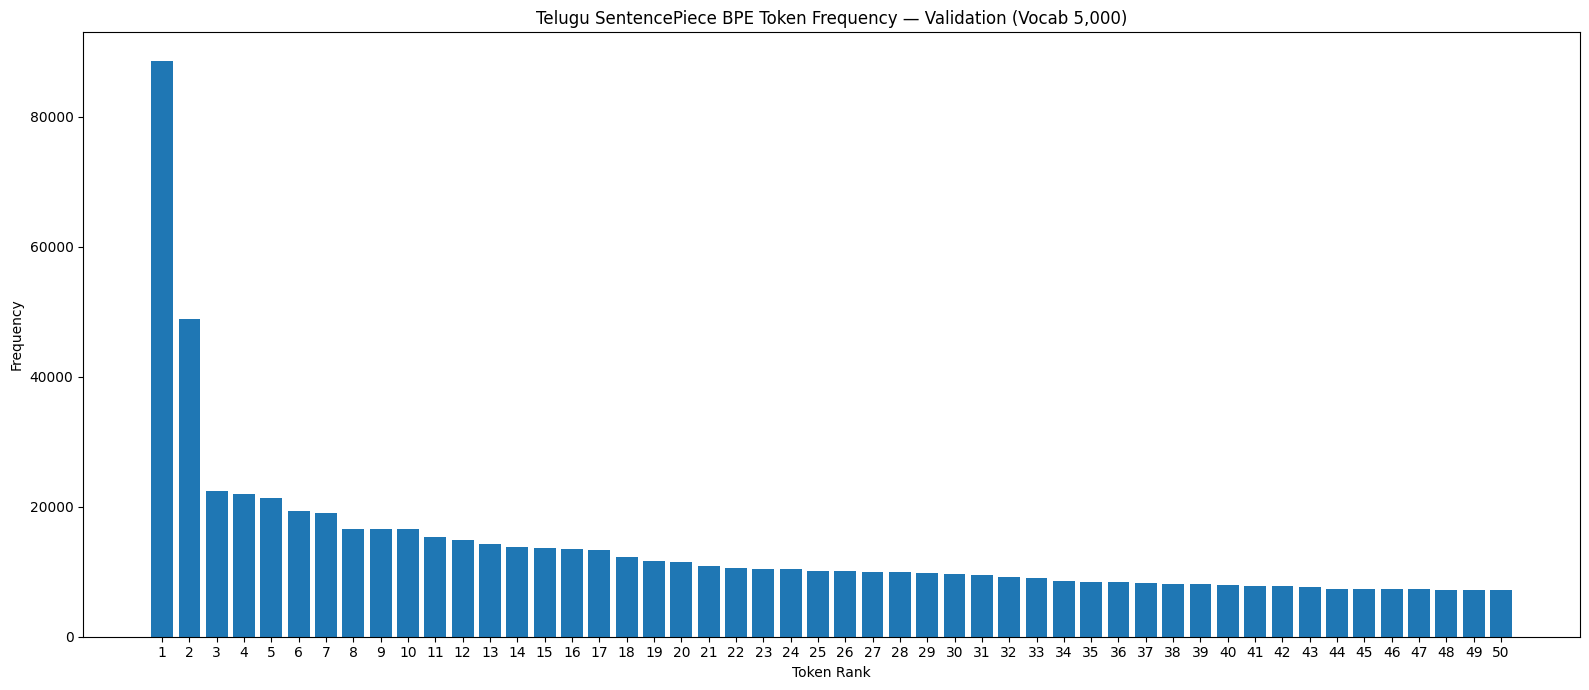

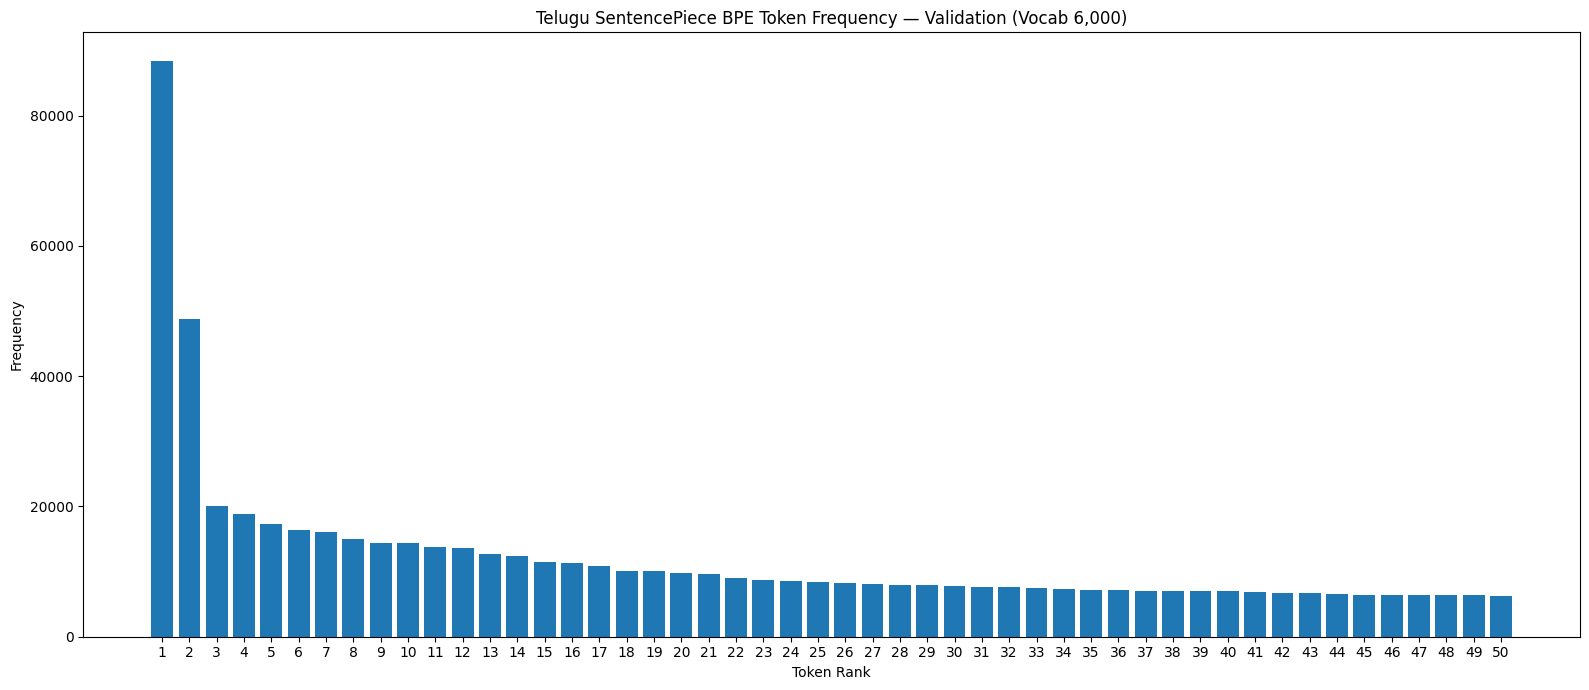

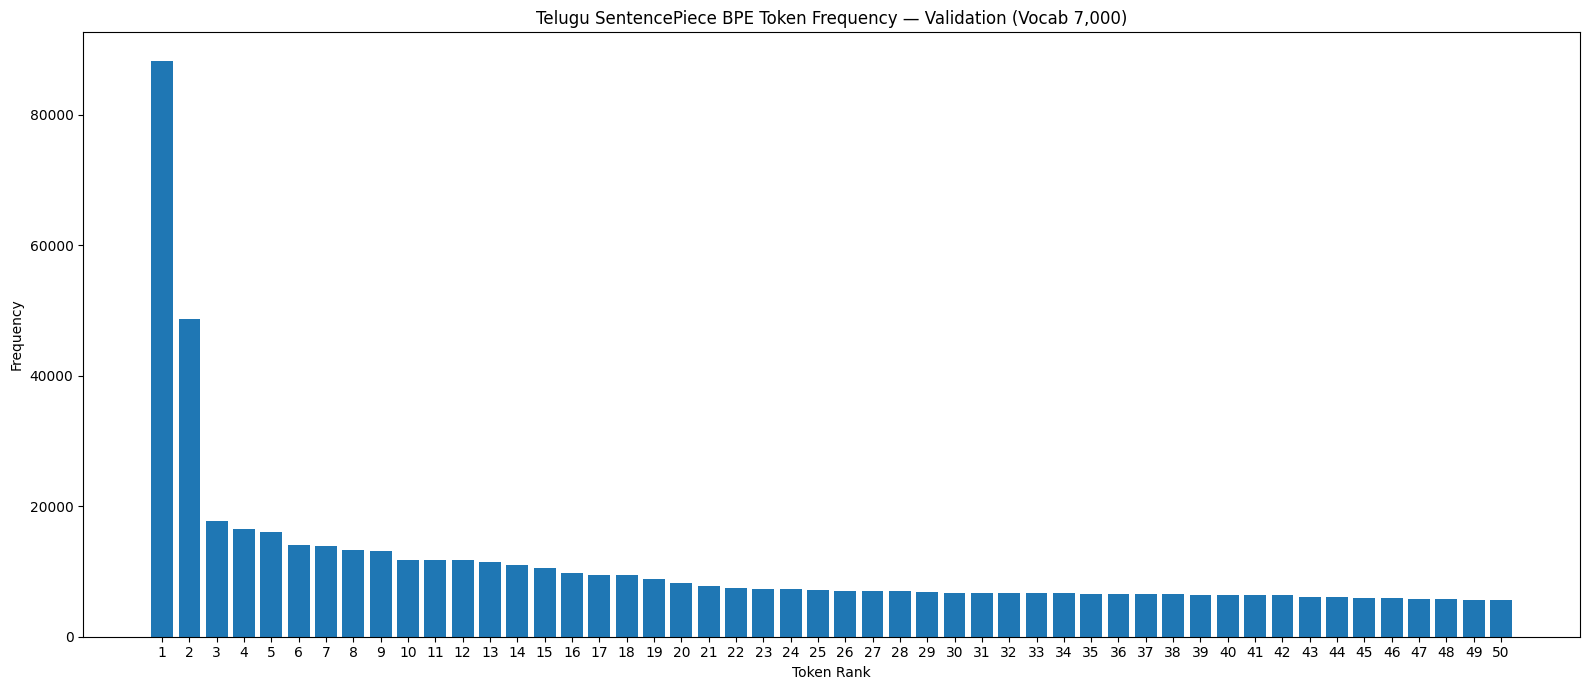

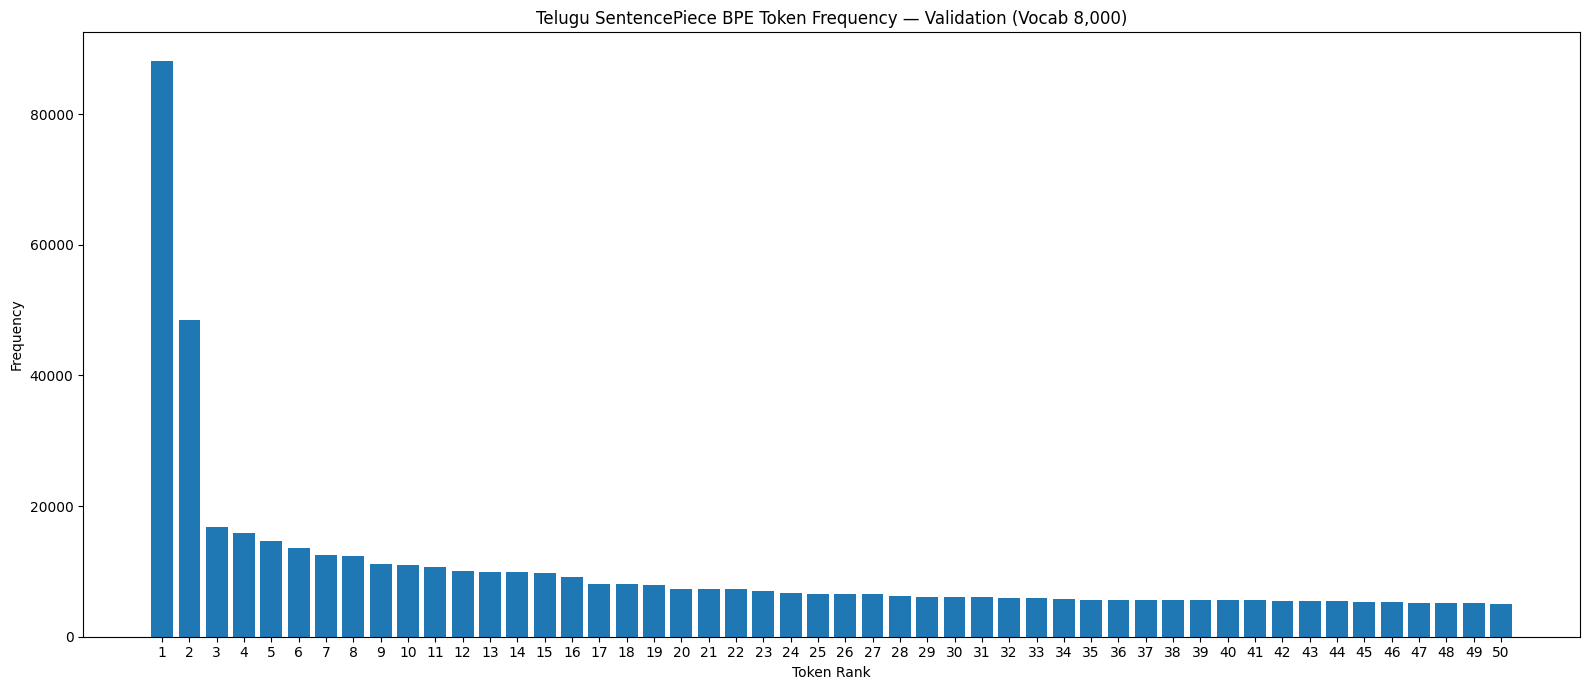

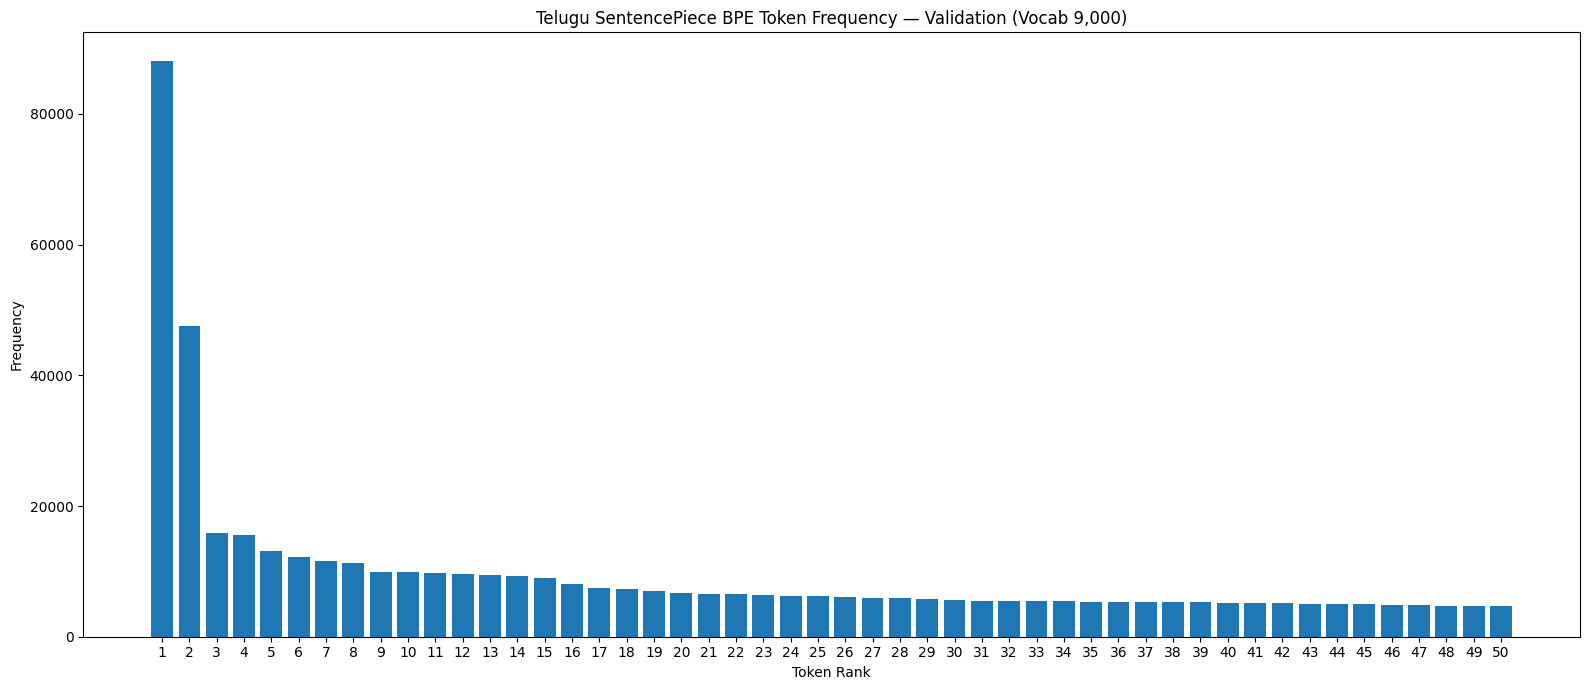

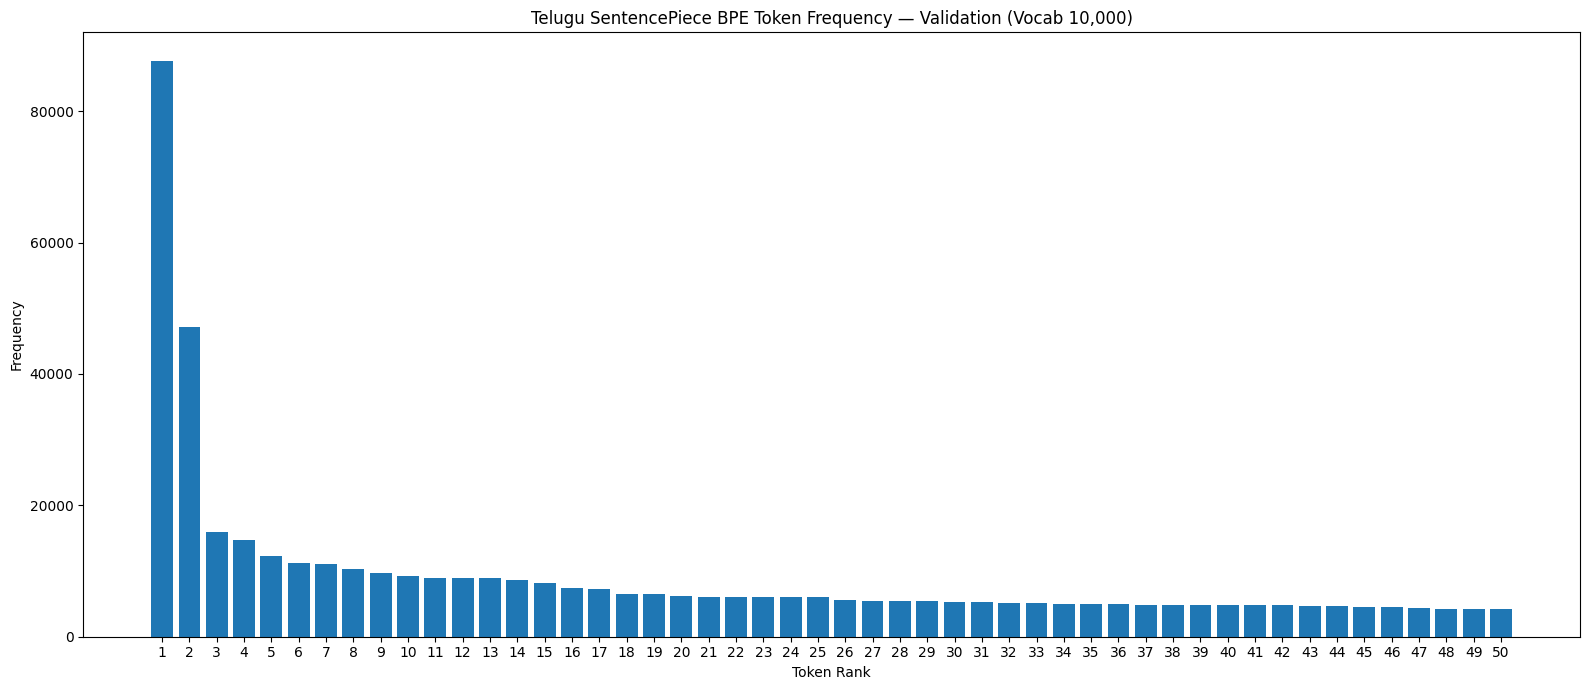

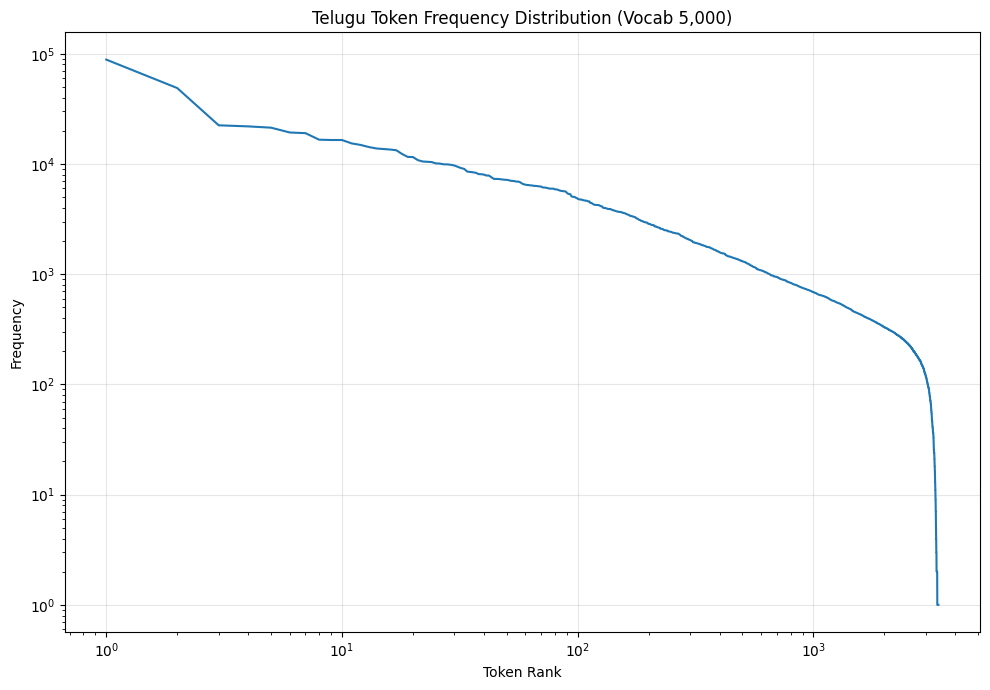

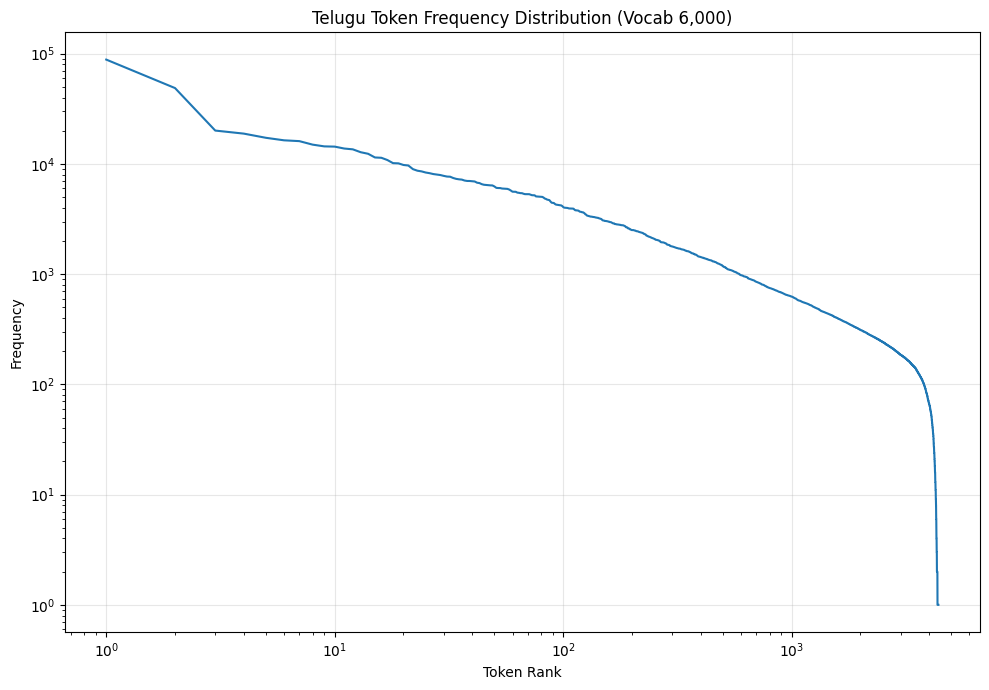

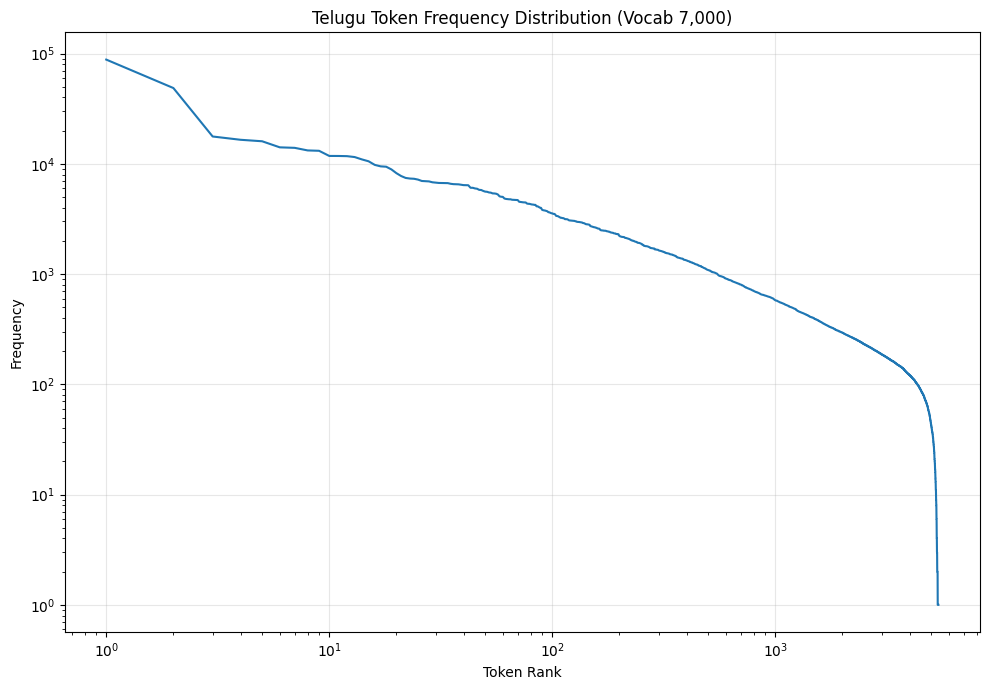

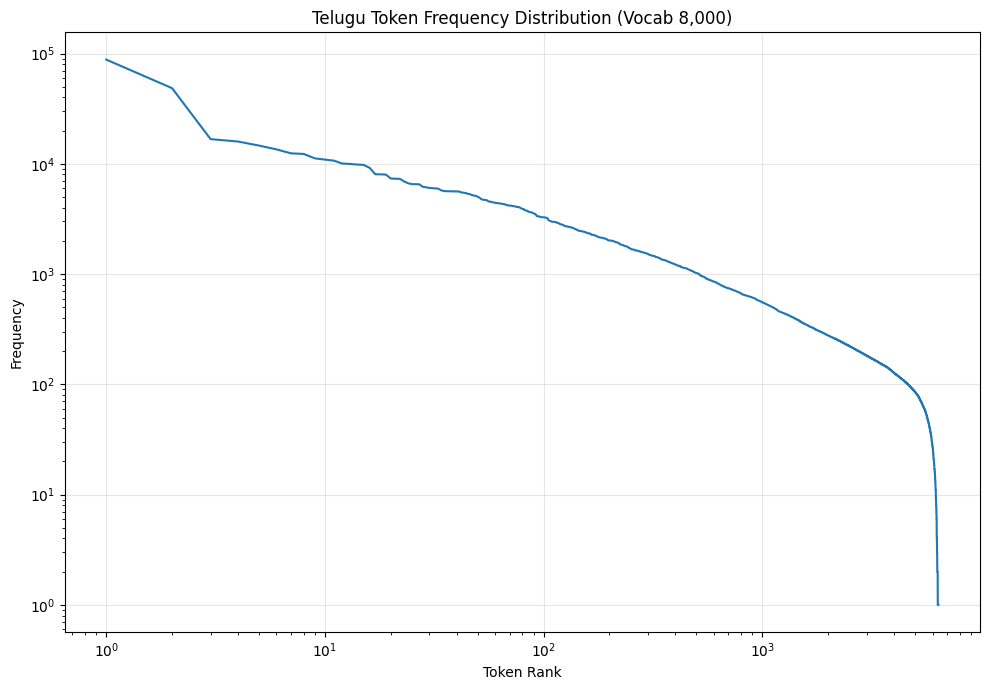

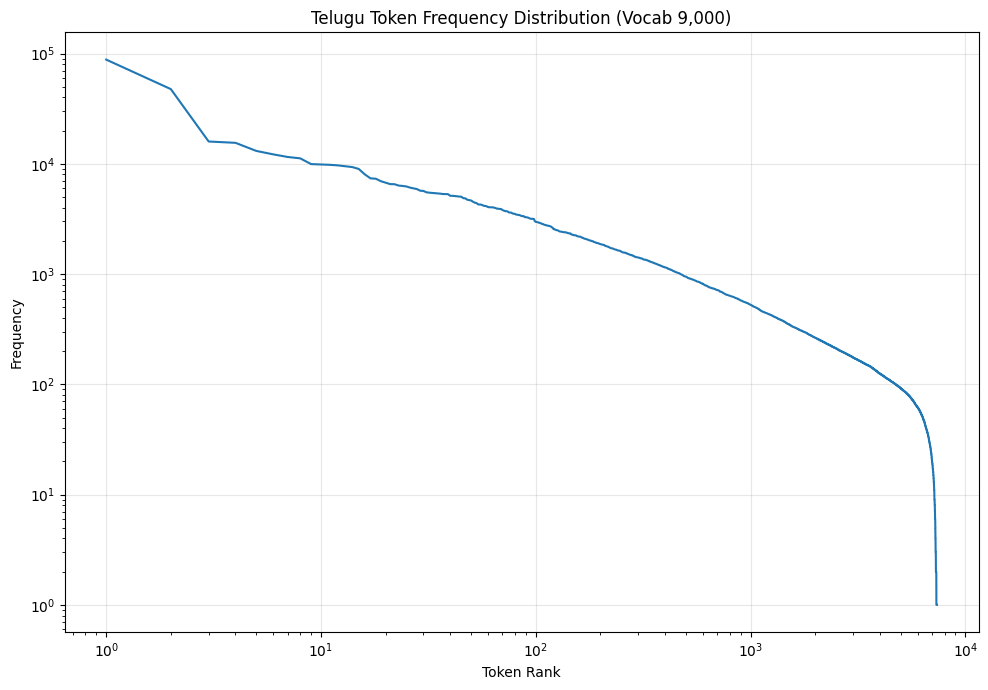

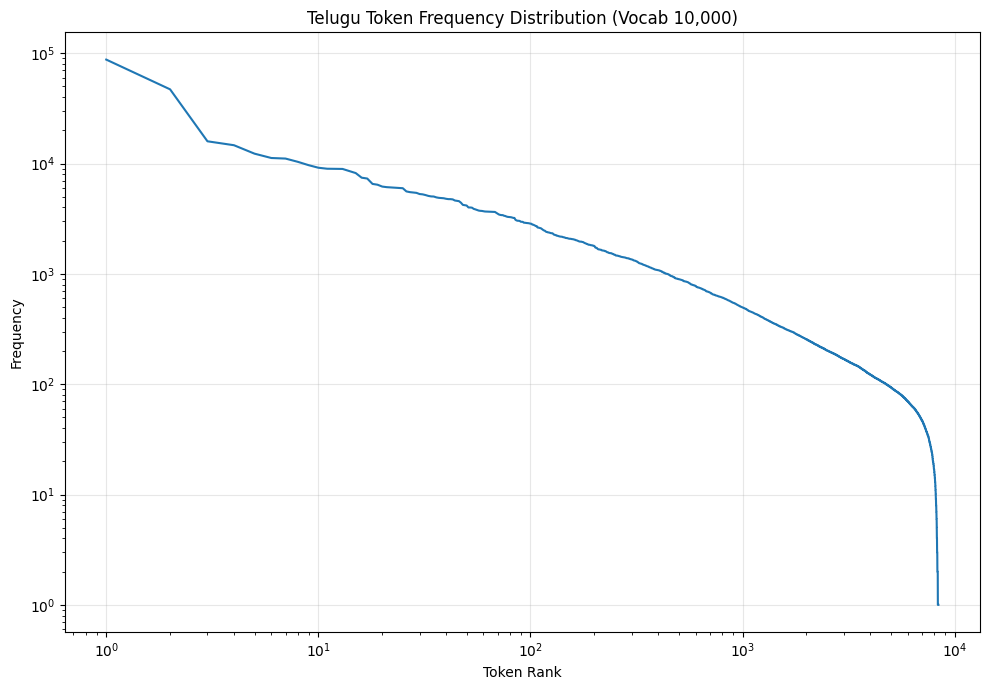

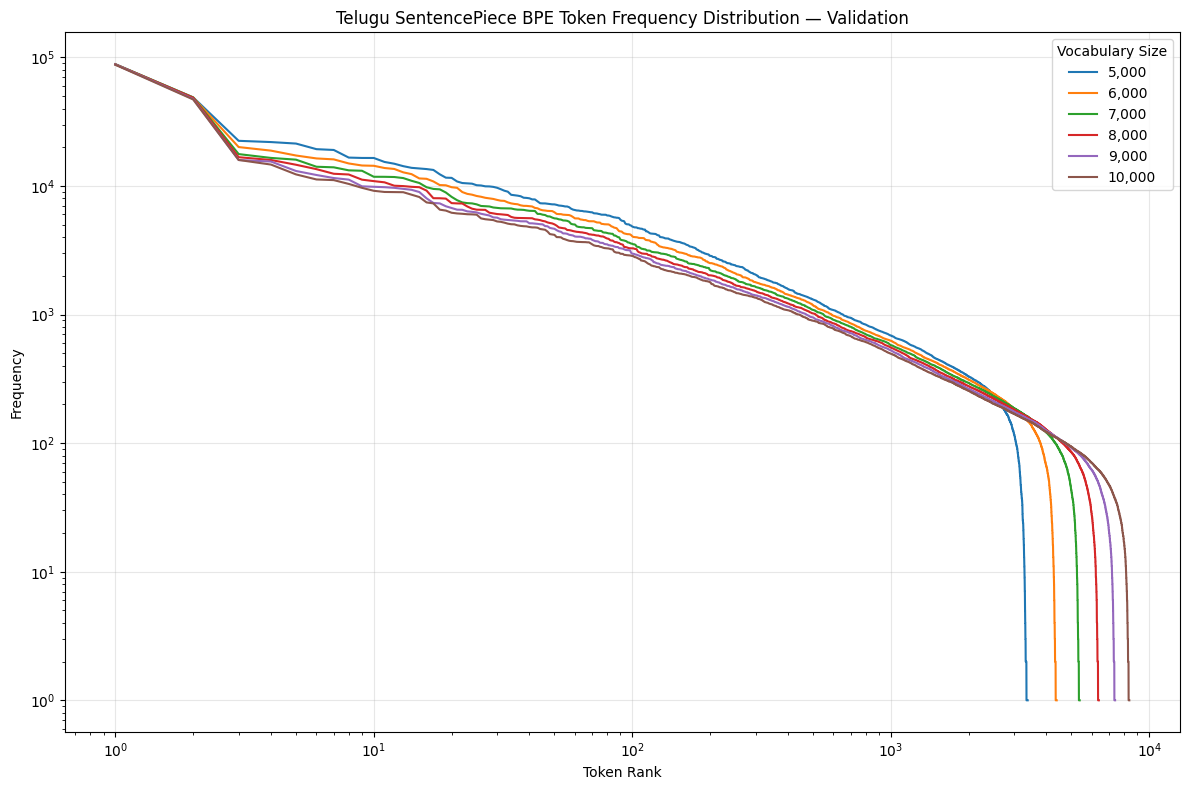


TELUGU TOKEN FREQUENCY ANALYSIS COMPLETE

Vocab 5,000:
  Unique tokens : 3,388
  Total tokens  : 3,109,767
  Top 10:
     1. '.'                  88,602
     2. ','                  48,909
     3. 'ల'                  22,445
     4. 'లు'                 21,951
     5. 'లో'                 21,370
     6. 'ం'                  19,329
     7. 'ని'                 19,054
     8. 'న'                  16,623
     9. '▁ఈ'                 16,516
    10. 'క'                  16,507

Vocab 6,000:
  Unique tokens : 4,387
  Total tokens  : 2,922,947
  Top 10:
     1. '.'                  88,390
     2. ','                  48,765
     3. 'లో'                 20,070
     4. 'ల'                  18,831
     5. 'లు'                 17,255
     6. '▁ఈ'                 16,373
     7. 'ని'                 16,098
     8. 'ం'                  14,964
     9. 'ను'                 14,427
    10. 'క'                  14,353

Vocab 7,000:
  Unique tokens : 5,385
  Total tokens  : 2,784,786
  Top 10:
     1. '.

In [ ]:
# ============================================================
# TELUGU — TOKEN FREQUENCY GRAPHS
# SENTENCEPIECE BPE
# VALIDATION SET
# ============================================================

import json
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import sentencepiece as spm
from tqdm.auto import tqdm


# ============================================================
# PATHS
# ============================================================

VALIDATION_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/cleaned/final/telugu_val.jsonl"
)

TOKENIZER_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer"
)

OUTPUT_DIR = TOKENIZER_DIR / "validation"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# VOCAB SIZES
# ============================================================

VOCAB_SIZES = [
    5000,
    6000,
    7000,
    8000,
    9000,
    10000
]


# ============================================================
# LOAD TOKENIZERS
# ============================================================

tokenizers = {}

for vocab_size in VOCAB_SIZES:

    model_file = (
        TOKENIZER_DIR
        / f"telugu_bpe_{vocab_size}.model"
    )

    if not model_file.exists():

        print(
            f"NOT FOUND: {model_file}"
        )

        continue

    sp = spm.SentencePieceProcessor()

    sp.load(
        str(model_file)
    )

    tokenizers[vocab_size] = sp

    print(
        f"Loaded {vocab_size:,}"
        f" → {sp.get_piece_size():,} pieces"
    )


if not tokenizers:

    raise RuntimeError(
        "No SentencePiece tokenizers found."
    )


# ============================================================
# TOKEN FREQUENCY STORAGE
# ============================================================

token_frequencies = {
    vocab_size: Counter()
    for vocab_size in tokenizers
}


# ============================================================
# PROCESS VALIDATION SET
# ============================================================

print("\n" + "=" * 90)
print("BUILDING TELUGU VALIDATION TOKEN FREQUENCIES")
print("=" * 90)


with open(
    VALIDATION_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Counting validation tokens",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            continue

        text = record.get(
            "text",
            ""
        )

        if not isinstance(text, str):
            continue

        text = text.strip()

        if not text:
            continue

        text = text.replace(
            "\n",
            " "
        )

        for vocab_size, tokenizer in tokenizers.items():

            tokens = tokenizer.encode(
                text,
                out_type=str
            )

            token_frequencies[
                vocab_size
            ].update(tokens)


# ============================================================
# SAVE FREQUENCY TABLES
# ============================================================

for vocab_size in tokenizers:

    counter = token_frequencies[
        vocab_size
    ]

    frequency_file = (
        OUTPUT_DIR
        / f"telugu_bpe_{vocab_size}_token_frequencies.csv"
    )

    rows = [
        {
            "rank": rank,
            "token": token,
            "frequency": frequency
        }

        for rank, (token, frequency)
        in enumerate(
            counter.most_common(),
            start=1
        )
    ]

    import pandas as pd

    frequency_df = pd.DataFrame(
        rows
    )

    frequency_df.to_csv(
        frequency_file,
        index=False
    )

    print(
        f"Saved frequency table: "
        f"{frequency_file}"
    )


# ============================================================
# GRAPH 1 — TOP 50 TOKEN FREQUENCIES
# ============================================================

print("\n" + "=" * 90)
print("PLOTTING TOP TOKEN FREQUENCIES")
print("=" * 90)


for vocab_size in tokenizers:

    counter = token_frequencies[
        vocab_size
    ]

    top_tokens = counter.most_common(
        50
    )

    tokens = [
        token
        for token, _ in top_tokens
    ]

    frequencies = [
        frequency
        for _, frequency in top_tokens
    ]


    plt.figure(
        figsize=(16, 7)
    )

    plt.bar(
        range(len(tokens)),
        frequencies
    )

    plt.xlabel(
        "Token Rank"
    )

    plt.ylabel(
        "Frequency"
    )

    plt.title(
        f"Telugu SentencePiece BPE "
        f"Token Frequency — Validation "
        f"(Vocab {vocab_size:,})"
    )

    plt.xticks(
        range(len(tokens)),
        range(
            1,
            len(tokens) + 1
        )
    )

    plt.tight_layout()


    graph_file = (
        OUTPUT_DIR
        / f"telugu_bpe_{vocab_size}_top50_token_frequency.png"
    )

    plt.savefig(
        graph_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# GRAPH 2 — FREQUENCY DISTRIBUTION
# ============================================================

for vocab_size in tokenizers:

    counter = token_frequencies[
        vocab_size
    ]

    frequencies = list(
        counter.values()
    )

    frequencies.sort(
        reverse=True
    )


    plt.figure(
        figsize=(10, 7)
    )

    plt.plot(
        range(
            1,
            len(frequencies) + 1
        ),
        frequencies
    )

    plt.xlabel(
        "Token Rank"
    )

    plt.ylabel(
        "Frequency"
    )

    plt.title(
        f"Telugu Token Frequency Distribution "
        f"(Vocab {vocab_size:,})"
    )

    plt.xscale(
        "log"
    )

    plt.yscale(
        "log"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()


    graph_file = (
        OUTPUT_DIR
        / f"telugu_bpe_{vocab_size}_frequency_distribution.png"
    )

    plt.savefig(
        graph_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# COMBINED GRAPH — ALL VOCAB SIZES
# ============================================================

plt.figure(
    figsize=(12, 8)
)


for vocab_size in tokenizers:

    frequencies = sorted(
        token_frequencies[
            vocab_size
        ].values(),
        reverse=True
    )


    plt.plot(
        range(
            1,
            len(frequencies) + 1
        ),
        frequencies,
        label=f"{vocab_size:,}"
    )


plt.xlabel(
    "Token Rank"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Telugu SentencePiece BPE "
    "Token Frequency Distribution — Validation"
)

plt.xscale(
    "log"
)

plt.yscale(
    "log"
)

plt.legend(
    title="Vocabulary Size"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


combined_graph = (
    OUTPUT_DIR
    / "telugu_bpe_validation_token_frequency_comparison.png"
)

plt.savefig(
    combined_graph,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("TELUGU TOKEN FREQUENCY ANALYSIS COMPLETE")
print("=" * 90)

for vocab_size in tokenizers:

    counter = token_frequencies[
        vocab_size
    ]

    print(
        f"\nVocab {vocab_size:,}:"
    )

    print(
        f"  Unique tokens : "
        f"{len(counter):,}"
    )

    print(
        f"  Total tokens  : "
        f"{sum(counter.values()):,}"
    )

    print(
        "  Top 10:"
    )

    for rank, (
        token,
        frequency
    ) in enumerate(
        counter.most_common(10),
        start=1
    ):

        print(
            f"    {rank:2d}. "
            f"{repr(token):20s} "
            f"{frequency:,}"
        )


print(
    f"\nOutputs saved in:\n{OUTPUT_DIR}"
)

print(
    f"\nCombined graph:\n"
    f"{combined_graph}"
)

print("=" * 90)

In [1]:
# ============================================================
# Telugu BPE Tokenizer — Sample Tokenization Check
# Self-contained Colab cell
# ============================================================

# ------------------------------------------------------------
# 1. Install only what is needed for this run
# ------------------------------------------------------------
!pip -q install sentencepiece

# ------------------------------------------------------------
# 2. Mount Google Drive
# ------------------------------------------------------------
from google.colab import drive
drive.mount("/content/drive")

# ------------------------------------------------------------
# 3. Imports
# ------------------------------------------------------------
from pathlib import Path
import sentencepiece as spm

# ------------------------------------------------------------
# 4. Final Telugu tokenizer path
# ------------------------------------------------------------
TOKENIZER_PATH = Path(
    "/content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_bpe_6000.model"
)

# Check that the tokenizer exists
if not TOKENIZER_PATH.exists():
    raise FileNotFoundError(
        f"Tokenizer not found:\n{TOKENIZER_PATH}\n\n"
        "Please check that the final Telugu tokenizer is present "
        "in the expected Drive location."
    )

print("=" * 70)
print("TELUGU BPE TOKENIZER — SAMPLE TOKENIZATION")
print("=" * 70)

print(f"\nTokenizer: {TOKENIZER_PATH}")
print(f"File size: {TOKENIZER_PATH.stat().st_size / 1024:.2f} KB")

# ------------------------------------------------------------
# 5. Load tokenizer
# ------------------------------------------------------------
sp = spm.SentencePieceProcessor()

loaded = sp.load(str(TOKENIZER_PATH))

if not loaded:
    raise RuntimeError("Failed to load the SentencePiece tokenizer.")

print(f"Vocabulary size: {sp.get_piece_size():,}")

# ------------------------------------------------------------
# 6. Sample Telugu sentences
# ------------------------------------------------------------
samples = [
    "తెలుగు భారతదేశంలో మాట్లాడే ఒక ప్రధాన భాష.",
    "కృత్రిమ మేధస్సు భవిష్యత్తులో అనేక రంగాలను మార్చగలదు.",
    "విద్యార్థులు ప్రతిరోజూ కొత్త విషయాలను నేర్చుకుంటున్నారు.",
    "ఈ రోజు వాతావరణం చాలా ఆహ్లాదకరంగా ఉంది.",
    "మన దేశంలో అనేక భాషలు మరియు సంస్కృతులు ఉన్నాయి.",
    "తెలుగు సాహిత్యానికి ఎంతో గొప్ప చరిత్ర ఉంది.",
    "సాంకేతిక పరిజ్ఞానం మన దైనందిన జీవితంలో ముఖ్యమైన పాత్ర పోషిస్తోంది.",
]

# ------------------------------------------------------------
# 7. Tokenize and display results
# ------------------------------------------------------------
for i, text in enumerate(samples, start=1):

    pieces = sp.encode(
        text,
        out_type=str
    )

    token_ids = sp.encode(
        text,
        out_type=int
    )

    decoded = sp.decode(token_ids)

    num_chars = len(text)
    num_tokens = len(token_ids)

    chars_per_token = (
        num_chars / num_tokens
        if num_tokens > 0
        else 0
    )

    print("\n" + "-" * 70)
    print(f"Sample {i}")
    print("-" * 70)

    print(f"Text:")
    print(text)

    print(f"\nTokens ({num_tokens}):")
    print(pieces)

    print(f"\nToken IDs:")
    print(token_ids)

    print(f"\nDecoded:")
    print(decoded)

    print(f"\nCharacters      : {num_chars}")
    print(f"Tokens          : {num_tokens}")
    print(f"Characters/token : {chars_per_token:.3f}")

    # Verify encode → decode consistency
    if decoded == text:
        print("Round-trip check : PASS")
    else:
        print("Round-trip check : WARNING — decoded text differs")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("TOKENIZER CHECK COMPLETE")
print("=" * 70)

print(f"Tokenizer vocabulary size : {sp.get_piece_size():,}")
print(f"Tokenizer type            : SentencePiece BPE")
print(f"Tokenizer file             : {TOKENIZER_PATH.name}")
print("GPU required               : No")
print("=" * 70)

Mounted at /content/drive
TELUGU BPE TOKENIZER — SAMPLE TOKENIZATION

Tokenizer: /content/drive/MyDrive/LMA_IP/Telugu/data/tokenizer/telugu_bpe_6000.model
File size: 353.52 KB
Vocabulary size: 6,000

----------------------------------------------------------------------
Sample 1
----------------------------------------------------------------------
Text:
తెలుగు భారతదేశంలో మాట్లాడే ఒక ప్రధాన భాష.

Tokens (9):
['▁తెలుగు', '▁భారతదేశ', 'ంలో', '▁మాట్లా', 'డే', '▁ఒక', '▁ప్రధాన', '▁భాష', '.']

Token IDs:
[664, 3257, 61, 545, 449, 179, 811, 2373, 4168]

Decoded:
తెలుగు భారతదేశంలో మాట్లాడే ఒక ప్రధాన భాష.

Characters      : 41
Tokens          : 9
Characters/token : 4.556
Round-trip check : PASS

----------------------------------------------------------------------
Sample 2
----------------------------------------------------------------------
Text:
కృత్రిమ మేధస్సు భవిష్యత్తులో అనేక రంగాలను మార్చగలదు.

Tokens (15):
['▁కృ', 'త్రి', 'మ', '▁మే', 'ధ', 'స్సు', '▁భవిష్యత్తు', 'లో', '▁అనేక', '▁రంగా', '